In [ ]:

# ============================================================
# CELL 1 — GOOGLE DRIVE & COLAB RUNTIME INITIALIZATION
# ProofLens / Cifaker Data Engineering Pipeline
# ============================================================

import os
import shutil
from pathlib import Path

import google.auth
from google.colab import auth, drive
from googleapiclient.discovery import build

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

DRIVE_FOLDER_ID = "1IipfeWX_OVJS2KwaFL5wFlO-edxLoEGD"
DRIVE_MOUNT = Path("/content/drive")
WORK_DIR = Path("/content/cifaker_work")
CACHE_DIR = Path("/content/cifaker_cache")
SOURCE_DIR = Path("/content/genimage_archives")

DRIVE_SCOPES = ["https://www.googleapis.com/auth/drive"]

# ------------------------------------------------------------
# 2. Mount Google Drive and authenticate Drive API
# ------------------------------------------------------------

print("[1/4] Mounting Google Drive...")
drive.mount(str(DRIVE_MOUNT))

print("[2/4] Authenticating Google Drive API...")
auth.authenticate_user()

credentials, _ = google.auth.default(scopes=DRIVE_SCOPES)

drive_service = build(
    "drive",
    "v3",
    credentials=credentials,
    cache_discovery=False,
)

# ------------------------------------------------------------
# 3. Verify the exact cifaker folder
# ------------------------------------------------------------

print("[3/4] Verifying cifaker folder...")

folder = drive_service.files().get(
    fileId=DRIVE_FOLDER_ID,
    fields="id,name,mimeType,capabilities(canAddChildren)"
).execute()

assert folder["mimeType"] == "application/vnd.google-apps.folder"
assert folder["name"] == "cifaker", "Unexpected Drive folder."

can_write = folder.get("capabilities", {}).get("canAddChildren")

if can_write is False:
    raise PermissionError(
        "Current Google account cannot write to cifaker."
    )

if can_write is None:
    print("WARNING: Write permission could not be confirmed.")

# ------------------------------------------------------------
# 4. Initialize temporary Colab directories
# ------------------------------------------------------------

print("[4/4] Preparing runtime directories...")

for directory in (WORK_DIR, CACHE_DIR, SOURCE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Expose non-secret settings to later CLI cells.
os.environ["CIFAKER_DRIVE_FOLDER_ID"] = DRIVE_FOLDER_ID
os.environ["PROOFLENS_WORK_DIR"] = str(WORK_DIR)
os.environ["PROOFLENS_CACHE_DIR"] = str(CACHE_DIR)

disk = shutil.disk_usage("/content")
free_gb = disk.free / (1024 ** 3)
total_gb = disk.total / (1024 ** 3)

# ------------------------------------------------------------
# 5. Runtime summary
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("PROOFLENS — RUNTIME PREFLIGHT")
print("=" * 55)

print(f"Drive folder : {folder['name']}")
print(f"Folder ID    : {folder['id']}")
print(f"Write access : {can_write}")
print(f"Work dir     : {WORK_DIR}")
print(f"Cache dir    : {CACHE_DIR}")
print(f"Source dir   : {SOURCE_DIR}")
print(f"Runtime disk : {free_gb:.2f} GB free / {total_gb:.2f} GB")
print("=" * 55)

if free_gb < 10:
    print("WARNING: Low runtime disk space for data processing.")

print("\nCELL 1 COMPLETE — Runtime and Drive access initialized.")


[1/4] Mounting Google Drive...
Mounted at /content/drive
[2/4] Authenticating Google Drive API...


[3/4] Verifying cifaker folder...
[4/4] Preparing runtime directories...

PROOFLENS — RUNTIME PREFLIGHT
Drive folder : cifaker
Folder ID    : 1IipfeWX_OVJS2KwaFL5wFlO-edxLoEGD
Write access : True
Work dir     : /content/cifaker_work
Cache dir    : /content/cifaker_cache
Source dir   : /content/genimage_archives
Runtime disk : 235.58 GB free / 235.68 GB

CELL 1 COMPLETE — Runtime and Drive access initialized.


In [ ]:

# ============================================================
# CELL 2 — REPOSITORY & ENVIRONMENT SETUP
# ProofLens / Cifaker Data Engineering Pipeline
# ============================================================

import sys
import subprocess
import importlib.metadata
from pathlib import Path

# ------------------------------------------------------------
# 1. Repository configuration
# ------------------------------------------------------------

REPO_URL = "https://github.com/sangoonthego/cifaker.git"
REPO_DIR = Path("/content/cifaker")

COMMIT_SHA = "d76c8fd6105bfef029bcb2b8dbead255bf03ff5c"

def run_command(command, cwd=None):
    subprocess.run(command, cwd=cwd, check=True)

# ------------------------------------------------------------
# 2. Clone or reuse repository
# ------------------------------------------------------------

print("[1/5] Preparing GitHub repository...")

if (REPO_DIR / ".git").exists():
    print("Repository already exists. Fetching updates...")

    run_command(
        ["git", "fetch", "origin"],
        cwd=REPO_DIR
    )

elif REPO_DIR.exists():
    raise RuntimeError(
        f"{REPO_DIR} exists but is not a Git repository."
    )

else:
    run_command(
        ["git", "clone", REPO_URL, str(REPO_DIR)]
    )

run_command(
    ["git", "checkout", "--detach", COMMIT_SHA],
    cwd=REPO_DIR
)

CURRENT_COMMIT = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=REPO_DIR,
    text=True
).strip()

assert CURRENT_COMMIT == COMMIT_SHA, "Commit mismatch."

# ------------------------------------------------------------
# 3. Install ProofLens and required dependencies
# ------------------------------------------------------------

print("\n[2/5] Installing ProofLens package...")

run_command(
    [
        sys.executable,
        "-m", "pip", "install",
        "--quiet",
        "-e", ".[gdrive,hf]"
    ],
    cwd=REPO_DIR
)


print("\n[3/5] Checking dependency consistency...")

dependency_check = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    cwd=REPO_DIR,
    capture_output=True,
    text=True,
    check=False
)

if dependency_check.returncode == 0:
    print("Dependency consistency: PASS")

else:
    print("WARNING: Dependency conflicts detected.")
    print(dependency_check.stdout)
    print(dependency_check.stderr)

    print(
        "Continuing to ProofLens-specific validation "
        "before determining whether these conflicts "
        "are blocking."
    )

# ------------------------------------------------------------
# 4. Resolve pipeline configuration paths
# ------------------------------------------------------------

print("\n[4/5] Validating pipeline configuration...")

CONFIG_DIR = REPO_DIR / "configs"

RELEASE_CONFIG = (
    CONFIG_DIR / "releases/genimage_120k_v1.yaml"
)

SOURCE_CONFIG = (
    CONFIG_DIR / "sources/genimage_full_archives.yaml"
)

PROTOCOL_CONFIG = (
    CONFIG_DIR / "protocols/cross_generator_v1.yaml"
)

STORAGE_CONFIG = (
    CONFIG_DIR / "storage/google_drive_api.yaml"
)

for config_path in (
    RELEASE_CONFIG,
    SOURCE_CONFIG,
    PROTOCOL_CONFIG,
    STORAGE_CONFIG
):
    if not config_path.is_file():
        raise FileNotFoundError(config_path)

# ------------------------------------------------------------
# 5. Validate package and CLI
# ------------------------------------------------------------

print("\n[5/5] Validating ProofLens CLI...")

run_command(
    [
        sys.executable,
        "-c",
        (
            "import prooflens; "
            "from prooflens.data.config import load_release_config; "
            f"cfg = load_release_config({str(RELEASE_CONFIG)!r}); "
            "print('Release:', cfg.release_id); "
            "print('Config validation: PASS')"
        )
    ],
    cwd=REPO_DIR
)

run_command(
    [sys.executable, "-m", "prooflens.data.cli", "--help"],
    cwd=REPO_DIR
)

# ------------------------------------------------------------
# 6. Environment summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PROOFLENS — ENVIRONMENT SUMMARY")
print("=" * 60)

print(f"Repository : {REPO_URL}")
print(f"Local path : {REPO_DIR}")
print(f"Commit SHA : {CURRENT_COMMIT}")
print(f"Python     : {sys.version.split()[0]}")

for package in (
    "prooflens",
    "torch",
    "torchvision",
    "numpy",
    "pandas",
    "pyarrow",
    "Pillow",
    "datasets",
    "huggingface-hub",
    "google-api-python-client",
    "google-auth"
):
    try:
        version = importlib.metadata.version(package)
        print(f"{package:<25}: {version}")
    except importlib.metadata.PackageNotFoundError:
        print(f"{package:<25}: NOT INSTALLED")

print("-" * 60)
print(f"Release config  : {RELEASE_CONFIG.name}")
print(f"Source config   : {SOURCE_CONFIG.name}")
print(f"Protocol config : {PROTOCOL_CONFIG.name}")
print(f"Storage config  : {STORAGE_CONFIG.name}")
print("=" * 60)

print("\nCELL 2 COMPLETE — ProofLens environment initialized.")


[1/5] Preparing GitHub repository...
Repository already exists. Fetching updates...

[2/5] Installing ProofLens package...

[3/5] Checking dependency consistency...
ipython 7.34.0 requires jedi, which is not installed.


Continuing to ProofLens-specific validation before determining whether these conflicts are blocking.

[4/5] Validating pipeline configuration...

[5/5] Validating ProofLens CLI...

PROOFLENS — ENVIRONMENT SUMMARY
Repository : https://github.com/sangoonthego/cifaker.git
Local path : /content/cifaker
Commit SHA : d76c8fd6105bfef029bcb2b8dbead255bf03ff5c
Python     : 3.13.16
prooflens                : 0.2.0
torch                    : 2.14.1+cu130
torchvision              : 0.29.1+cu130
numpy                    : 2.4.6
pandas                   : 2.2.3
pyarrow                  : 23.0.1
Pillow                   : 11.3.0
datasets                 : 4.8.5
huggingface-hub          : 1.33.0
google-api-python-client : 2.201.0
google-auth              : 2.49.0
---------------------

In [ ]:

# ============================================================
# CELL 3 — FULL GENIMAGE SOURCE INTEGRATION
# ProofLens / Cifaker Data Engineering Pipeline
# ============================================================

import io
import json
import time
from datetime import datetime, timezone

import pyarrow as pa
import pandas as pd

from PIL import Image
from huggingface_hub import HfApi, hf_hub_download
from googleapiclient.http import MediaFileUpload

# ------------------------------------------------------------
# 1. Source configuration
# ------------------------------------------------------------

HF_DATASET_ID = "nebula/GenImage-arrow"
HF_CACHE_DIR = CACHE_DIR / "huggingface"

HF_CACHE_DIR.mkdir(parents=True, exist_ok=True)

MAX_PROBE_SHARD_BYTES = 512 * 1024**2
PROBE_ROWS = 8

GENERATOR_MAPPING = {
    "ADM": "adm",
    "BigGAN": "biggan",
    "glide": "glide",
    "Midjourney": "midjourney",
    "stable_diffusion_v_1_4": "sdv4",
    "stable_diffusion_v_1_5": "sdv5",
    "VQDM": "vqdm",
    "wukong": "wukong",
}

api = HfApi()

# ------------------------------------------------------------
# 2. Resolve immutable dataset revision
# ------------------------------------------------------------

print("[1/5] Resolving GenImage source revision...")

source_info = api.dataset_info(
    repo_id=HF_DATASET_ID,
    revision="main",
    files_metadata=True,
)

HF_REVISION = source_info.sha

if not HF_REVISION:
    raise RuntimeError("Unable to resolve source revision.")

source_files = list(source_info.siblings or [])

print(f"Dataset  : {HF_DATASET_ID}")
print(f"Revision : {HF_REVISION}")
print(f"Files    : {len(source_files):,}")

# ------------------------------------------------------------
# 3. Discover generator and split partitions
# ------------------------------------------------------------

print("\n[2/5] Inspecting source partitions...")

partition_records = []
partition_shards = {}

for split in ("train", "test"):

    for upstream_name, canonical_name in GENERATOR_MAPPING.items():

        prefix = f"data/{split}/{upstream_name}/"

        shards = [
            item for item in source_files
            if item.rfilename.startswith(prefix)
            and item.rfilename.endswith(".arrow")
        ]

        known_sizes = [
            item.size for item in shards
            if item.size is not None
        ]

        total_bytes = (
            sum(known_sizes)
            if shards and len(known_sizes) == len(shards)
            else None
        )

        partition_shards[(split, canonical_name)] = shards

        partition_records.append({
            "source_split": split,
            "generator": canonical_name,
            "arrow_shards": len(shards),
            "size_gib": (
                round(total_bytes / 1024**3, 3)
                if total_bytes is not None
                else None
            ),
            "available": bool(shards),
        })

partition_df = pd.DataFrame(partition_records)

display(partition_df)

missing_partitions = partition_df[
    ~partition_df["available"]
]

if not missing_partitions.empty:
    display(missing_partitions)

    raise RuntimeError(
        "Expected GenImage partitions are missing. "
        "Inspect the current Hugging Face source layout."
    )

print("\nPartition discovery: PASS")

# ------------------------------------------------------------
# 4. Probe real images from bounded Arrow shards
# ------------------------------------------------------------

print("\n[3/5] Testing real image access...")

PROBE_PARTITIONS = [
    ("train", "biggan"),
    ("test", "midjourney"),
]

probe_results = []

for split, generator in PROBE_PARTITIONS:

    candidates = [
        item
        for item in partition_shards[(split, generator)]
        if item.size is not None
        and 0 < item.size <= MAX_PROBE_SHARD_BYTES
    ]

    if not candidates:
        raise RuntimeError(
            f"No shard within probe budget: {split}/{generator}"
        )

    selected = min(
        candidates,
        key=lambda item: item.size,
    )

    print(f"\nTesting partition: {split}/{generator}")
    print(f"Shard: {selected.rfilename}")
    print(f"Shard size: {selected.size / 1024**2:.2f} MiB")

    started = time.perf_counter()

    local_path = hf_hub_download(
        repo_id=HF_DATASET_ID,
        repo_type="dataset",
        filename=selected.rfilename,
        revision=HF_REVISION,
        cache_dir=str(HF_CACHE_DIR),
    )

    access_seconds = time.perf_counter() - started

    # Support Arrow stream and Arrow file formats.
    with pa.memory_map(local_path, "r") as source:

        try:
            reader = pa.ipc.open_stream(source)
            batch = reader.read_next_batch()

        except pa.ArrowInvalid:
            source.seek(0)
            reader = pa.ipc.open_file(source)
            batch = reader.get_batch(0)

        schema = str(batch.schema)

        required_columns = {
            "image_path",
            "image",
            "label",
            "generator",
        }

        missing_columns = (
            required_columns - set(batch.schema.names)
        )

        if missing_columns:
            raise RuntimeError(
                f"Missing source columns: {missing_columns}"
            )

        rows = batch.slice(
            0,
            min(PROBE_ROWS, batch.num_rows)
        ).to_pylist()

    if not rows:
        raise RuntimeError("Probe returned no image rows.")

    for row in rows:

        label = int(row["label"])

        if label not in (0, 1):
            raise ValueError(f"Invalid binary label: {label}")

        image_payload = row["image"]

        # Support binary and Hugging Face Image structures.
        if isinstance(image_payload, dict):
            raw_bytes = image_payload.get("bytes")
        else:
            raw_bytes = image_payload

        if not isinstance(
            raw_bytes,
            (bytes, bytearray, memoryview),
        ):
            raise TypeError(
                "Unsupported source image payload: "
                f"{type(image_payload).__name__}"
            )

        raw_bytes = bytes(raw_bytes)

        if not raw_bytes:
            raise ValueError("Empty source image payload.")

        with Image.open(io.BytesIO(raw_bytes)) as image:
            width, height = image.size
            image_format = image.format
            image.load()

        source_path = str(row["image_path"])

        # Check path-based label consistency when available.
        path_parts = (
            source_path.replace("\\", "/")
            .lower()
            .split("/")
        )

        if "nature" in path_parts and label != 0:
            raise ValueError(
                f"REAL label mismatch: {source_path}"
            )

        if "ai" in path_parts and label != 1:
            raise ValueError(
                f"FAKE label mismatch: {source_path}"
            )

        probe_results.append({
            "source_split": split,
            "generator_group": generator,
            "source_generator_value": str(row["generator"]),
            "image_path": source_path,
            "label": label,
            "label_name": "REAL" if label == 0 else "FAKE",
            "width": width,
            "height": height,
            "format": image_format,
            "file_size_bytes": len(raw_bytes),
            "payload_type": type(image_payload).__name__,
            "source_shard": selected.rfilename,
            "shard_size_bytes": selected.size,
            "shard_access_seconds": round(access_seconds, 3),
            "decode_status": "PASS",
        })

    print(f"Decoded images: {len(rows)}")
    print(f"Shard access time: {access_seconds:.2f}s")
    print("Source schema:")
    print(schema)

probe_df = pd.DataFrame(probe_results)

display(probe_df[
    [
        "source_split",
        "generator_group",
        "label_name",
        "width",
        "height",
        "format",
        "payload_type",
        "decode_status",
    ]
])

# ------------------------------------------------------------
# 5. Create source feasibility report
# ------------------------------------------------------------

print("\n[4/5] Creating source feasibility report...")

timestamp = datetime.now(timezone.utc)

source_report = {
    "status": "SOURCE_PROBE_PASSED",
    "created_at": timestamp.isoformat(),
    "source_dataset": HF_DATASET_ID,
    "source_revision": HF_REVISION,
    "code_commit": CURRENT_COMMIT,
    "generator_mapping": GENERATOR_MAPPING,
    "label_mapping": {
        "REAL": 0,
        "FAKE": 1,
    },
    "partitions": partition_df.to_dict(orient="records"),
    "probe_results": probe_results,
    "verified_images": len(probe_results),
    "full_inventory_completed": False,
    "production_adapter_verified": False,
    "dataset_release_published": False,
}

SOURCE_REPORT_PATH = (
    WORK_DIR
    / f"genimage_source_probe_{HF_REVISION[:12]}.json"
)

SOURCE_REPORT_PATH.write_text(
    json.dumps(source_report, indent=2, allow_nan=False),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 6. Persist source report to Google Drive
# ------------------------------------------------------------

print("\n[5/5] Saving source report to Google Drive...")

report_name = (
    f"genimage_source_probe_"
    f"{HF_REVISION[:12]}_"
    f"{timestamp.strftime('%Y%m%d_%H%M%S')}.json"
)

uploaded_report = drive_service.files().create(
    body={
        "name": report_name,
        "parents": [DRIVE_FOLDER_ID],
    },
    media_body=MediaFileUpload(
        str(SOURCE_REPORT_PATH),
        mimetype="application/json",
        resumable=False,
    ),
    fields="id,name,size,md5Checksum,webViewLink",
).execute()

# Verify remote report integrity.
import hashlib

local_md5 = hashlib.md5(
    SOURCE_REPORT_PATH.read_bytes()
).hexdigest()

assert uploaded_report["md5Checksum"] == local_md5
assert int(uploaded_report["size"]) == SOURCE_REPORT_PATH.stat().st_size

# ------------------------------------------------------------
# 7. Final source summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PROOFLENS — GENIMAGE SOURCE FEASIBILITY")
print("=" * 60)

print(f"Source repository   : {HF_DATASET_ID}")
print(f"Source revision     : {HF_REVISION}")
print(f"Partitions found    : {len(partition_df)}")
print(f"Arrow shards found  : {partition_df['arrow_shards'].sum():,}")
print(f"Images verified     : {len(probe_results)}")
print(f"Local report        : {SOURCE_REPORT_PATH}")
print(f"Drive report        : {uploaded_report['name']}")
print("Report integrity    : PASS")
print("Production adapter  : NOT YET VERIFIED")
print("Full inventory      : NOT STARTED")
print("120K extraction     : NOT STARTED")

print("=" * 60)
print("\nCELL 3 COMPLETE — Source probe passed.")


[1/5] Resolving GenImage source revision...
Dataset  : nebula/GenImage-arrow
Revision : 3f4b9f921a673be09a93b335ed728cea0c6ecf33
Files    : 1,461

[2/5] Inspecting source partitions...


,source_split,generator,arrow_shards,size_gib,available
0,train,adm,75,34.872,True
1,train,biggan,48,21.779,True
2,train,glide,62,29.004,True
3,train,midjourney,476,204.482,True
4,train,sdv4,189,86.669,True
5,train,sdv5,191,87.522,True
6,train,vqdm,74,34.324,True
7,train,wukong,191,87.377,True
8,test,adm,3,1.416,True
9,test,biggan,2,0.915,True



Partition discovery: PASS

[3/5] Testing real image access...

Testing partition: train/biggan
Shard: data/train/BigGAN/data-00047-of-00048.arrow
Shard size: 386.97 MiB


data/train/BigGAN/data-00047-of-00048.ar(…): reconstructing file:   0%|          |  0.00B /  406MB            

data/train/BigGAN/data-00047-of-00048.ar(…): downloading bytes:           |  0.00B            

Decoded images: 8
Shard access time: 9.60s
Source schema:
image_path: string
md5: string
width: int64
height: int64
image: binary
label: int64
generator: int64
-- schema metadata --
huggingface: '{"info": {"features": {"image_path": {"dtype": "string", "_' + 427

Testing partition: test/midjourney
Shard: data/test/Midjourney/data-00018-of-00019.arrow
Shard size: 283.34 MiB


data/test/Midjourney/data-00018-of-00019(…): reconstructing file:   0%|          |  0.00B /  297MB            

data/test/Midjourney/data-00018-of-00019(…): downloading bytes:           |  0.00B            

Decoded images: 8
Shard access time: 3.84s
Source schema:
image_path: string
image: binary
label: int64
generator: int64
-- schema metadata --
huggingface: '{"info": {"features": {"image_path": {"dtype": "string", "_' + 286


,source_split,generator_group,label_name,width,height,format,payload_type,decode_status
0,train,biggan,REAL,500,333,JPEG,bytes,PASS
1,train,biggan,REAL,333,500,JPEG,bytes,PASS
2,train,biggan,REAL,333,500,JPEG,bytes,PASS
3,train,biggan,REAL,500,333,JPEG,bytes,PASS
4,train,biggan,REAL,367,500,JPEG,bytes,PASS
5,train,biggan,REAL,333,500,JPEG,bytes,PASS
6,train,biggan,REAL,500,333,JPEG,bytes,PASS
7,train,biggan,REAL,333,500,JPEG,bytes,PASS
8,test,midjourney,FAKE,1024,1024,PNG,bytes,PASS
9,test,midjourney,FAKE,1024,1024,PNG,bytes,PASS



[4/5] Creating source feasibility report...

[5/5] Saving source report to Google Drive...

PROOFLENS — GENIMAGE SOURCE FEASIBILITY
Source repository   : nebula/GenImage-arrow
Source revision     : 3f4b9f921a673be09a93b335ed728cea0c6ecf33
Partitions found    : 16
Arrow shards found  : 1,362
Images verified     : 16
Local report        : /content/cifaker_work/genimage_source_probe_3f4b9f921a67.json
Drive report        : genimage_source_probe_3f4b9f921a67_20261124_123029.json
Report integrity    : PASS
Production adapter  : NOT YET VERIFIED
Full inventory      : NOT STARTED
120K extraction     : NOT STARTED

CELL 3 COMPLETE — Source probe passed.


In [ ]:

# ============================================================
# CELL 4 — INCREMENTAL INVENTORY & SAMPLING FEASIBILITY
# ProofLens / Cifaker Data Engineering Pipeline
# ============================================================

import hashlib
import math
import shutil
import tempfile
from collections import defaultdict
from dataclasses import replace

import pyarrow.parquet as pq

from huggingface_hub import try_to_load_from_cache


# ------------------------------------------------------------
# ProofLens package path initialization
# ------------------------------------------------------------

import sys
from pathlib import Path
import importlib

REPO_DIR = Path("/content/cifaker")
SRC_DIR = REPO_DIR / "src"

if not (SRC_DIR / "prooflens" / "__init__.py").is_file():
    raise FileNotFoundError(
        f"ProofLens package not found at {SRC_DIR}. "
        "Run Cell 2 first."
    )

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

importlib.invalidate_caches()

import prooflens

print("ProofLens import: PASS")
print(f"Package location: {prooflens.__file__}")


from prooflens.data.config import (
    load_release_config,
    load_storage_config,
)

from prooflens.data.registry.schema import (
    CanonicalImageRecord,
    make_canonical_image_id,
    extract_imagenet_class_from_path,
    write_canonical_parquet,
)

from prooflens.data.registry.duplicates import (
    assign_leakage_groups,
)

from prooflens.data.sampling.planner import plan_release

from prooflens.data.sampling.stratification import (
    distribute_quota_evenly,
    QuotaInfeasibleError,
)

from prooflens.data.sampling.leakage_guard import (
    LeakageViolationError,
)

from prooflens.data.storage import create_storage_backend

# ------------------------------------------------------------
# 1. Inventory configuration
# ------------------------------------------------------------

MAX_NEW_DOWNLOAD_GIB = 12
CANDIDATE_HEADROOM = 1.25

MAX_NEW_DOWNLOAD_BYTES = int(
    MAX_NEW_DOWNLOAD_GIB * 1024**3
)

INVENTORY_DIR = WORK_DIR / "arrow_inventory"
INVENTORY_DIR.mkdir(parents=True, exist_ok=True)

SOURCE_ID = "genimage_arrow_sharded"

REMOTE_PREFIX = (
    f"pipeline_metadata/arrow_inventory_v1/"
    f"{HF_REVISION}"
)

storage = create_storage_backend(
    load_storage_config(STORAGE_CONFIG)
)

base_config = load_release_config(
    RELEASE_CONFIG,
    working_dir_override=str(WORK_DIR),
)

# Diagnostic planning configuration only.
# The production Arrow adapter must be updated separately.
planning_config = replace(
    base_config,
    source=replace(
        base_config.source,
        source_id=SOURCE_ID,
        source_revision=HF_REVISION,
        source_type="huggingface",
        location=HF_DATASET_ID,
        archive_glob=None,
        hf_streaming=True,
    ),
)

SAMPLING_SEED = planning_config.sampling_seed

# ------------------------------------------------------------
# 2. Derive candidate quotas from the existing protocol
# ------------------------------------------------------------

print("[1/5] Resolving sampling requirements...")

requirements = defaultdict(
    lambda: {0: 0, 1: 0}
)

protocol = planning_config.protocol

for split_name, rule in protocol.splits.items():

    groups = (
        protocol.seen_generators
        if rule.generator_pool == "seen"
        else protocol.unseen_generators
    )

    upstream_split = (
        "train"
        if "train" in rule.allowed_source_splits
        else "test"
    )

    for label, quota in (
        (0, rule.real_quota),
        (1, rule.fake_quota),
    ):

        generator_quotas = distribute_quota_evenly(
            quota,
            list(groups),
        )

        for generator, count in generator_quotas.items():
            requirements[
                (upstream_split, generator)
            ][label] += count

targets = {
    partition: {
        label: math.ceil(count * CANDIDATE_HEADROOM)
        for label, count in quotas.items()
    }
    for partition, quotas in requirements.items()
}

# ------------------------------------------------------------
# 3. Source shard helpers
# ------------------------------------------------------------

def stable_shard_rank(shard):
    payload = (
        f"{SAMPLING_SEED}:{shard.rfilename}"
    ).encode()

    return hashlib.sha256(payload).hexdigest()


def inventory_key(shard):
    shard_id = hashlib.sha256(
        shard.rfilename.encode()
    ).hexdigest()[:24]

    return (
        INVENTORY_DIR / f"{shard_id}.parquet",
        f"{REMOTE_PREFIX}/{shard_id}.parquet",
    )


def iter_arrow_batches(path):

    with pa.memory_map(str(path), "r") as source:

        try:
            reader = pa.ipc.open_stream(source)

        except pa.ArrowInvalid:
            source.seek(0)
            reader = pa.ipc.open_file(source)

            for index in range(reader.num_record_batches):
                yield reader.get_batch(index)

        else:
            yield from reader


def read_shard_inventory(path, shard, partition):

    source_split, generator_group = partition

    rows = []
    row_index = 0

    for batch in iter_arrow_batches(path):

        columns = {
            name: batch.column(index)
            for index, name in enumerate(
                batch.schema.names
            )
        }

        required = {"image_path", "image", "label"}

        if not required.issubset(columns):
            raise ValueError(
                f"Invalid Arrow schema: {shard.rfilename}"
            )

        for index in range(batch.num_rows):

            original_path = str(
                columns["image_path"][index].as_py()
            )

            label = int(
                columns["label"][index].as_py()
            )

            if label not in (0, 1):
                raise ValueError(
                    f"Invalid label: {label}"
                )

            path_parts = (
                original_path.replace("\\", "/")
                .lower()
                .split("/")
            )

            if "nature" in path_parts and label != 0:
                raise ValueError(
                    f"REAL label mismatch: {original_path}"
                )

            if "ai" in path_parts and label != 1:
                raise ValueError(
                    f"FAKE label mismatch: {original_path}"
                )

            raw_bytes = columns["image"][index].as_py()

            if not isinstance(raw_bytes, bytes):
                raise TypeError(
                    "Expected raw binary image payload."
                )

            if not raw_bytes:
                raise ValueError("Empty image payload.")

            normalized_path = original_path.replace(
                "\\", "/"
            ).lstrip("/")

            # Stable source locator for a pinned revision.
            source_path = (
                f"{shard.rfilename}/"
                f"rows/{row_index:08d}/"
                f"{normalized_path}"
            )

            record = CanonicalImageRecord(
                image_id=make_canonical_image_id(
                    SOURCE_ID,
                    HF_REVISION,
                    source_path,
                ),
                source_id=SOURCE_ID,
                source_revision=HF_REVISION,
                source_path=source_path,
                source_split=source_split,
                label=label,
                generator=(
                    "none"
                    if label == 0
                    else generator_group
                ),
                source_generator_group=generator_group,
                source_shard=shard.rfilename,
                imagenet_class=(
                    extract_imagenet_class_from_path(
                        original_path
                    )
                ),
                width=(
                    columns["width"][index].as_py()
                    if "width" in columns
                    else None
                ),
                height=(
                    columns["height"][index].as_py()
                    if "height" in columns
                    else None
                ),
                file_size_bytes=len(raw_bytes),
                sha256=hashlib.sha256(
                    raw_bytes
                ).hexdigest(),
            ).to_dict()

            record["original_image_path"] = original_path
            record["source_row_index"] = row_index

            rows.append(record)

            row_index += 1

    if not rows:
        raise RuntimeError(
            f"Empty shard: {shard.rfilename}"
        )

    return pd.DataFrame(rows)

# ------------------------------------------------------------
# 4. Restore previously completed inventory shards
# ------------------------------------------------------------

print("\n[2/5] Restoring inventory metadata from Drive...")

remote_objects = set(
    storage.list_objects(prefix=REMOTE_PREFIX)
)

inventory_frames = []

completed_shards = set()

unique_hashes = defaultdict(
    lambda: {0: set(), 1: set()}
)

candidate_shards = {}

restored_count = 0


def register_inventory(frame, shard, partition):

    if shard.rfilename in completed_shards:
        return

    if not frame["source_revision"].eq(HF_REVISION).all():
        raise ValueError("Source revision mismatch.")

    if not frame["source_shard"].eq(shard.rfilename).all():
        raise ValueError("Source shard mismatch.")

    inventory_frames.append(frame)

    completed_shards.add(shard.rfilename)

    for label in (0, 1):

        hashes = frame.loc[
            frame["label"] == label,
            "sha256",
        ].dropna()

        unique_hashes[partition][label].update(
            hashes.tolist()
        )


for partition in requirements:

    shards = sorted(
        partition_shards[partition],
        key=stable_shard_rank,
    )

    candidate_shards[partition] = shards

    for shard in shards:

        local_path, remote_key = inventory_key(shard)

        if remote_key not in remote_objects:
            continue

        if not local_path.exists():

            metadata = storage.get_metadata(remote_key)

            storage.download(
                remote_key,
                local_path,
                expected_sha256=metadata.sha256,
            )

        frame = pd.read_parquet(local_path)

        register_inventory(
            frame,
            shard,
            partition,
        )

        restored_count += 1

print(f"Restored inventory shards: {restored_count:,}")

# ------------------------------------------------------------
# 5. Incremental source inventory
# ------------------------------------------------------------

print("\n[3/5] Building incremental candidate inventory...")

scheduled_download_bytes = 0
new_shards = 0


def partition_satisfied(partition):

    return all(
        len(unique_hashes[partition][label])
        >= targets[partition][label]
        for label in (0, 1)
    )


while True:

    progress_made = False

    # Round-robin processing across required partitions.
    for partition in sorted(requirements):

        if partition_satisfied(partition):
            continue

        remaining = [
            shard
            for shard in candidate_shards[partition]
            if shard.rfilename not in completed_shards
        ]

        if not remaining:
            continue

        shard = remaining[0]

        if shard.size is None:
            raise RuntimeError(
                f"Unknown shard size: {shard.rfilename}"
            )

        cached_path = try_to_load_from_cache(
            repo_id=HF_DATASET_ID,
            filename=shard.rfilename,
            revision=HF_REVISION,
            repo_type="dataset",
            cache_dir=str(HF_CACHE_DIR),
        )

        cache_hit = (
            isinstance(cached_path, str)
            and Path(cached_path).is_file()
        )

        required_bytes = 0 if cache_hit else shard.size

        if (
            scheduled_download_bytes + required_bytes
            > MAX_NEW_DOWNLOAD_BYTES
        ):
            continue

        if shutil.disk_usage("/content").free < (
            shard.size + 3 * 1024**3
        ):
            raise RuntimeError(
                "Insufficient Colab temporary disk space."
            )

        print(
            f"\nProcessing {partition} | "
            f"{shard.size / 1024**2:.1f} MiB"
        )

        # Temporary source files are removed after
        # inventory extraction and metadata publication.
        with tempfile.TemporaryDirectory(
            dir=str(WORK_DIR)
        ) as temporary_dir:

            if cache_hit:
                arrow_path = cached_path

            else:
                arrow_path = hf_hub_download(
                    repo_id=HF_DATASET_ID,
                    repo_type="dataset",
                    filename=shard.rfilename,
                    revision=HF_REVISION,
                    local_dir=temporary_dir,
                )

                scheduled_download_bytes += shard.size

            frame = read_shard_inventory(
                arrow_path,
                shard,
                partition,
            )

            local_path, remote_key = inventory_key(shard)

            write_canonical_parquet(
                frame,
                local_path,
            )

            storage.upload(
                local_path,
                remote_key,
                overwrite=False,
            )

        register_inventory(
            frame,
            shard,
            partition,
        )

        new_shards += 1
        progress_made = True

        print(f"Rows indexed: {len(frame):,}")

        print(
            f"Unique REAL: "
            f"{len(unique_hashes[partition][0]):,}"
        )

        print(
            f"Unique FAKE: "
            f"{len(unique_hashes[partition][1]):,}"
        )

        print(
            f"Scheduled source bytes: "
            f"{scheduled_download_bytes / 1024**3:.2f} GiB"
        )

    if not progress_made:
        break

if not inventory_frames:
    raise RuntimeError("No inventory records available.")

# ------------------------------------------------------------
# 6. Candidate availability and duplicate audit
# ------------------------------------------------------------

print("\n[4/5] Auditing candidate inventory...")

inventory_df = pd.concat(
    inventory_frames,
    ignore_index=True,
)

inventory_df, duplicate_report = assign_leakage_groups(
    inventory_df,
    audit_scope="inspected_arrow_candidate_shards",
    include_pixel_hash=False,
    include_perceptual_in_leakage_groups=False,
)

availability_rows = []

for partition, quotas in sorted(requirements.items()):

    source_split, generator = partition

    for label in (0, 1):

        available = len(
            unique_hashes[partition][label]
        )

        availability_rows.append({
            "source_split": source_split,
            "generator": generator,
            "label": "REAL" if label == 0 else "FAKE",
            "required": quotas[label],
            "available_unique": available,
            "candidate_target": targets[partition][label],
            "shortfall": max(
                0,
                quotas[label] - available,
            ),
        })

availability_df = pd.DataFrame(availability_rows)

display(availability_df)

# ------------------------------------------------------------
# 7. Run the existing ProofLens planner
# ------------------------------------------------------------

print("\n[5/5] Running sampling feasibility check...")

candidate_plan = None
planner_error = None

try:

    candidate_plan = plan_release(
        inventory_df=inventory_df,
        config=planning_config,
        dry_run=True,
    )

    print(
        json.dumps(
            candidate_plan.summary,
            indent=2,
            default=str,
        )
    )

except (
    QuotaInfeasibleError,
    LeakageViolationError,
) as exc:

    planner_error = str(exc)

    print(f"Planning blocked: {planner_error}")

# ------------------------------------------------------------
# 8. Save diagnostic artifacts to Drive
# ------------------------------------------------------------

run_timestamp = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S_%f")

run_prefix = (
    f"pipeline_metadata/feasibility/"
    f"{HF_REVISION}/{run_timestamp}"
)

INVENTORY_PATH = (
    INVENTORY_DIR / "candidate_inventory.parquet"
)

write_canonical_parquet(
    inventory_df,
    INVENTORY_PATH,
)

storage.upload(
    INVENTORY_PATH,
    f"{run_prefix}/candidate_inventory.parquet",
    overwrite=False,
)

plan_feasible = (
    candidate_plan is not None
    and candidate_plan.feasible
)

inventory_report = {
    "source_revision": HF_REVISION,
    "code_commit": CURRENT_COMMIT,
    "inventory_scope": "inspected_candidate_shards",
    "full_source_inventory": False,
    "completed_source_shards": len(completed_shards),
    "restored_shards": restored_count,
    "new_shards": new_shards,
    "scheduled_download_bytes": scheduled_download_bytes,
    "candidate_images": len(inventory_df),
    "candidate_unique_sha256": int(
        inventory_df["sha256"].nunique()
    ),
    "availability": availability_rows,
    "duplicate_audit": duplicate_report.to_dict(),
    "sampling_feasible": plan_feasible,
    "planner_error": planner_error,
    "plan_summary": (
        candidate_plan.summary
        if candidate_plan is not None
        else None
    ),
    "production_adapter_verified": False,
    "production_release_frozen": False,
    "dataset_published": False,
}

REPORT_PATH = (
    INVENTORY_DIR / "inventory_feasibility.json"
)

REPORT_PATH.write_text(
    json.dumps(
        inventory_report,
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)

storage.upload(
    REPORT_PATH,
    f"{run_prefix}/inventory_feasibility.json",
    overwrite=False,
)

if plan_feasible:

    candidate_plan.save(
        INVENTORY_DIR / "candidate_plan"
    )

    storage.upload(
        INVENTORY_DIR
        / "candidate_plan"
        / "plan_selection.parquet",
        f"{run_prefix}/candidate_plan_selection.parquet",
        overwrite=False,
    )

# ------------------------------------------------------------
# 9. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PROOFLENS — INVENTORY FEASIBILITY SUMMARY")
print("=" * 60)

print(f"Source revision     : {HF_REVISION}")
print(f"Indexed shards      : {len(completed_shards):,}")
print(f"Restored shards     : {restored_count:,}")
print(f"New shards          : {new_shards:,}")
print(f"Candidate images    : {len(inventory_df):,}")

print(
    f"Unique image hashes : "
    f"{inventory_df['sha256'].nunique():,}"
)

print(
    f"Sampling feasibility: "
    f"{'PASS' if plan_feasible else 'NOT READY'}"
)

print(f"Drive report path   : {run_prefix}")
print("Production adapter  : NOT YET VERIFIED")
print("Dataset published   : NO")

print("=" * 60)

if not plan_feasible:
    print(
        "CELL 4 CHECKPOINT SAVED — "
        "inspect shortfalls and leakage report."
    )
else:
    print(
        "CELL 4 CANDIDATE PLAN PASSED — "
        "production adapter validation still required."
    )


ProofLens import: PASS
Package location: /content/cifaker/src/prooflens/__init__.py


[1/5] Resolving sampling requirements...

[2/5] Restoring inventory metadata from Drive...


Restored inventory shards: 0

[3/5] Building incremental candidate inventory...

Processing ('test', 'adm') | 487.4 MiB


data/test/ADM/data-00000-of-00003.arrow: reconstructing file:   0%|          |  0.00B /  511MB            

data/test/ADM/data-00000-of-00003.arrow: downloading bytes:           |  0.00B            

Rows indexed: 3,847
Unique REAL: 3,847
Unique FAKE: 0
Scheduled source bytes: 0.48 GiB

Processing ('test', 'biggan') | 483.2 MiB


... (76 outputs left out)

data/test/Midjourney/data-00008-of-00019(…): downloading bytes:           |  0.00B            

Rows indexed: 300
Unique REAL: 0
Unique FAKE: 1,000
Scheduled source bytes: 11.97 GiB

[4/5] Auditing candidate inventory...


,source_split,generator,label,required,available_unique,candidate_target,shortfall
0,test,adm,REAL,834,6000,1043,0
1,test,adm,FAKE,834,1694,1043,0
2,test,biggan,REAL,834,6000,1043,0
3,test,biggan,FAKE,834,6000,1043,0
4,test,glide,REAL,833,3826,1042,0
5,test,glide,FAKE,833,3328,1042,0
6,test,midjourney,REAL,5000,0,6250,5000
7,test,midjourney,FAKE,5000,1000,6250,4000
8,test,sdv4,REAL,833,0,1042,833
9,test,sdv4,FAKE,833,2046,1042,0



[5/5] Running sampling feasibility check...
Planning blocked: Upstream source_split leakage detected (10 cross-split groups, 0 cross-label groups) under policy='fail'. Either resolve upstream duplicates or set cross_source_split_leakage_policy='exclude_cross_split_groups'.

PROOFLENS — INVENTORY FEASIBILITY SUMMARY
Source revision     : 3f4b9f921a673be09a93b335ed728cea0c6ecf33
Indexed shards      : 27
Restored shards     : 0
New shards          : 27
Candidate images    : 79,558
Unique image hashes : 79,546
Sampling feasibility: NOT READY
Drive report path   : pipeline_metadata/feasibility/3f4b9f921a673be09a93b335ed728cea0c6ecf33/20261124_123851_527410
Production adapter  : NOT YET VERIFIED
Dataset published   : NO
CELL 4 CHECKPOINT SAVED — inspect shortfalls and leakage report.


In [ ]:

# ============================================================
# CELL 4.1 — DATA LEAKAGE RESOLUTION & QUARANTINE
# ProofLens / Cifaker Data Engineering Pipeline
# ============================================================

import json
import pandas as pd

from datetime import datetime, timezone
from dataclasses import replace

from prooflens.data.sampling.leakage_guard import (
    check_leakage_boundaries,
)

from prooflens.data.registry.schema import (
    write_canonical_parquet,
)

# ------------------------------------------------------------
# 1. Validate previous stage artifacts
# ------------------------------------------------------------

print("[1/5] Loading candidate inventory...")

if "inventory_df" not in globals():
    raise RuntimeError("Run Cell 4 before Cell 4.1.")

if inventory_df.empty:
    raise RuntimeError("Candidate inventory is empty.")

# Preserve the original Cell 4 output.
raw_inventory_df = inventory_df.copy(deep=True)

INITIAL_COUNT = len(raw_inventory_df)

assert raw_inventory_df["image_id"].is_unique

assert raw_inventory_df["sha256"].astype(str).str.fullmatch(
    r"[0-9a-fA-F]{64}"
).all(), "Missing or invalid SHA-256 hashes."

print(f"Input records: {INITIAL_COUNT:,}")

# ------------------------------------------------------------
# 2. Identify all leakage violations
# ------------------------------------------------------------

print("\n[2/5] Detecting cross-split and cross-label leakage...")

leakage_before = check_leakage_boundaries(
    raw_inventory_df,
    split_column="source_split",
    raise_on_violation=False,
)

# Audit canonical leakage groups.
group_audit = (
    raw_inventory_df
    .groupby("leakage_group_id")
    .agg(
        records=("image_id", "size"),
        source_splits=("source_split", "nunique"),
        labels=("label", "nunique"),
    )
)

bad_groups = set(
    group_audit.index[
        (group_audit["source_splits"] > 1)
        | (group_audit["labels"] > 1)
    ]
)

# Independently audit exact image hashes.
hash_audit = (
    raw_inventory_df
    .groupby("sha256")
    .agg(
        records=("image_id", "size"),
        source_splits=("source_split", "nunique"),
        labels=("label", "nunique"),
    )
)

bad_hashes = set(
    hash_audit.index[
        (hash_audit["source_splits"] > 1)
        | (hash_audit["labels"] > 1)
    ]
)

print(f"Violating leakage groups: {len(bad_groups):,}")
print(f"Violating SHA-256 hashes: {len(bad_hashes):,}")

# ------------------------------------------------------------
# 3. Quarantine complete violating groups
# ------------------------------------------------------------

print("\n[3/5] Quarantining leakage records...")

leakage_mask = (
    raw_inventory_df["leakage_group_id"].isin(bad_groups)
    | raw_inventory_df["sha256"].isin(bad_hashes)
)

# Expand quarantine to every member of affected groups.
affected_groups = set(
    raw_inventory_df.loc[
        leakage_mask,
        "leakage_group_id"
    ]
)

leakage_mask = (
    leakage_mask
    | raw_inventory_df["leakage_group_id"].isin(
        affected_groups
    )
)

quarantine_df = raw_inventory_df.loc[
    leakage_mask
].copy()

quarantine_df["eligibility_status"] = "EXCLUDED"

quarantine_df["exclusion_reason"] = (
    "CROSS_SOURCE_SPLIT_OR_LABEL_LEAKAGE"
)

# Preserve unrelated pre-existing exclusions.
clean_inventory_df = raw_inventory_df.loc[
    ~leakage_mask
    & raw_inventory_df["eligibility_status"].eq("ELIGIBLE")
].copy()

clean_inventory_df.reset_index(
    drop=True,
    inplace=True,
)

quarantine_df.reset_index(
    drop=True,
    inplace=True,
)

preexisting_excluded_count = int(
    (
        ~leakage_mask
        & ~raw_inventory_df["eligibility_status"].eq("ELIGIBLE")
    ).sum()
)

assert INITIAL_COUNT == (
    len(clean_inventory_df)
    + len(quarantine_df)
    + preexisting_excluded_count
)

if clean_inventory_df.empty:
    raise RuntimeError("No eligible records remain.")

assert set(clean_inventory_df["image_id"]).isdisjoint(
    quarantine_df["image_id"]
)

print(f"Original records   : {INITIAL_COUNT:,}")
print(f"Quarantined records: {len(quarantine_df):,}")
print(f"Eligible records   : {len(clean_inventory_df):,}")

# ------------------------------------------------------------
# 4. Verify leakage resolution
# ------------------------------------------------------------

print("\n[4/5] Validating cleaned inventory...")

leakage_after = check_leakage_boundaries(
    clean_inventory_df,
    split_column="source_split",
    raise_on_violation=True,
)

assert leakage_after.passed

assert leakage_after.cross_split_group_count == 0
assert leakage_after.cross_label_group_count == 0

# Keep Cell 4 configuration unchanged.
planning_config_41 = replace(
    planning_config,
    protocol=replace(
        planning_config.protocol,
        cross_source_split_leakage_policy=(
            "exclude_cross_split_groups"
        ),
    ),
)

# Compare partition-level distributions.
distribution_columns = [
    "source_split",
    "source_generator_group",
    "label",
]

before_counts = (
    raw_inventory_df
    .groupby(distribution_columns)
    .size()
    .rename("before")
)

after_counts = (
    clean_inventory_df
    .groupby(distribution_columns)
    .size()
    .rename("after")
)

leakage_distribution_df = (
    pd.concat(
        [before_counts, after_counts],
        axis=1,
    )
    .fillna(0)
    .astype(int)
    .reset_index()
)

leakage_distribution_df["removed"] = (
    leakage_distribution_df["before"]
    - leakage_distribution_df["after"]
)

leakage_distribution_df["label"] = (
    leakage_distribution_df["label"]
    .map({0: "REAL", 1: "FAKE"})
)

print("\nAffected partitions:")

display(
    leakage_distribution_df[
        leakage_distribution_df["removed"] > 0
    ]
)

print("\nLeakage verification: PASS")

# ------------------------------------------------------------
# 5. Persist artifacts to Google Drive
# ------------------------------------------------------------

print("\n[5/5] Saving leakage resolution artifacts...")

LEAKAGE_DIR = WORK_DIR / "leakage_resolution"

LEAKAGE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CLEAN_INVENTORY_PATH = (
    LEAKAGE_DIR / "clean_inventory.parquet"
)

QUARANTINE_PATH = (
    LEAKAGE_DIR / "quarantine.parquet"
)

LEAKAGE_REPORT_PATH = (
    LEAKAGE_DIR / "leakage_resolution_report.json"
)

DISTRIBUTION_PATH = (
    LEAKAGE_DIR / "leakage_distribution.csv"
)

write_canonical_parquet(
    clean_inventory_df,
    CLEAN_INVENTORY_PATH,
)

write_canonical_parquet(
    quarantine_df,
    QUARANTINE_PATH,
)

leakage_distribution_df.to_csv(
    DISTRIBUTION_PATH,
    index=False,
)

timestamp_41 = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S_%f")

LEAKAGE_REMOTE_PREFIX = (
    f"pipeline_metadata/leakage_resolution/"
    f"{HF_REVISION}/{timestamp_41}"
)

leakage_report_41 = {
    "stage": "4.1",
    "status": "LEAKAGE_RESOLUTION_PASSED",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_revision": HF_REVISION,
    "code_commit": CURRENT_COMMIT,
    "parent_inventory_path": str(INVENTORY_PATH),
    "parent_remote_prefix": run_prefix,
    "inventory_scope": "inspected_candidate_shards",
    "indexed_source_shards": len(completed_shards),
    "original_records": INITIAL_COUNT,
    "eligible_records": len(clean_inventory_df),
    "quarantined_records": len(quarantine_df),
    "preexisting_excluded_records": (
        preexisting_excluded_count
    ),
    "quarantine_rate": (
        len(quarantine_df) / INITIAL_COUNT
    ),
    "violating_canonical_groups": len(bad_groups),
    "violating_sha256_hashes": len(bad_hashes),
    "policy_before": (
        planning_config.protocol
        .cross_source_split_leakage_policy
    ),
    "policy_after": (
        planning_config_41.protocol
        .cross_source_split_leakage_policy
    ),
    "config_hash_before": planning_config.config_hash,
    "config_hash_after": planning_config_41.config_hash,
    "leakage_before": leakage_before.to_dict(),
    "leakage_after": leakage_after.to_dict(),
    "affected_partitions": (
        leakage_distribution_df[
            leakage_distribution_df["removed"] > 0
        ].to_dict(orient="records")
    ),
    "exact_duplicate_audit": True,
    "near_duplicate_audit": False,
    "full_source_inventory": False,
    "sampling_plan_frozen": False,
    "dataset_published": False,
}

LEAKAGE_REPORT_PATH.write_text(
    json.dumps(
        leakage_report_41,
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)

artifacts_41 = [
    CLEAN_INVENTORY_PATH,
    QUARANTINE_PATH,
    DISTRIBUTION_PATH,
    LEAKAGE_REPORT_PATH,
]

for artifact in artifacts_41:

    remote_key = (
        f"{LEAKAGE_REMOTE_PREFIX}/{artifact.name}"
    )

    storage.upload(
        artifact,
        remote_key,
        overwrite=False,
    )

    print(f"Uploaded: {artifact.name}")

# ------------------------------------------------------------
# 6. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 64)
print("PROOFLENS — DATA LEAKAGE RESOLUTION")
print("=" * 64)

print(f"Original records       : {INITIAL_COUNT:,}")
print(f"Quarantined records    : {len(quarantine_df):,}")
print(f"Eligible records       : {len(clean_inventory_df):,}")

print(
    f"Quarantine rate        : "
    f"{len(quarantine_df) / INITIAL_COUNT * 100:.4f}%"
)

print(
    f"Cross-split violations : "
    f"{leakage_before.cross_split_group_count} -> "
    f"{leakage_after.cross_split_group_count}"
)

print(
    f"Cross-label violations : "
    f"{leakage_before.cross_label_group_count} -> "
    f"{leakage_after.cross_label_group_count}"
)

print("Exact leakage check    : PASS")
print("Near-duplicate check   : NOT PERFORMED")
print("New image downloads    : 0")
print("Original inventory     : PRESERVED")
print("Drive artifacts        : SAVED")
print(f"Drive path             : {LEAKAGE_REMOTE_PREFIX}")
print("Dataset published      : NO")

print("=" * 64)

print(
    "\nCELL 4.1 COMPLETE — "
    "Candidate leakage resolution passed."
)


[1/5] Loading candidate inventory...
Input records: 79,558

[2/5] Detecting cross-split and cross-label leakage...
Violating leakage groups: 5
Violating SHA-256 hashes: 5

[3/5] Quarantining leakage records...
Original records   : 79,558
Quarantined records: 10
Eligible records   : 79,548

[4/5] Validating cleaned inventory...

Affected partitions:


,source_split,source_generator_group,label,before,after,removed
2,test,biggan,REAL,6000,5998,2
8,test,sdv5,FAKE,2092,2091,1
9,test,vqdm,REAL,3824,3822,2
14,train,biggan,REAL,8500,8499,1
17,train,sdv4,REAL,1666,1665,1
20,train,sdv5,FAKE,907,906,1
21,train,vqdm,REAL,2242,2240,2



Leakage verification: PASS

[5/5] Saving leakage resolution artifacts...
Uploaded: clean_inventory.parquet
Uploaded: quarantine.parquet
Uploaded: leakage_distribution.csv
Uploaded: leakage_resolution_report.json

PROOFLENS — DATA LEAKAGE RESOLUTION
Original records       : 79,558
Quarantined records    : 10
Eligible records       : 79,548
Quarantine rate        : 0.0126%
Cross-split violations : 10 -> 0
Cross-label violations : 0 -> 0
Exact leakage check    : PASS
Near-duplicate check   : NOT PERFORMED
New image downloads    : 0
Original inventory     : PRESERVED
Drive artifacts        : SAVED
Drive path             : pipeline_metadata/leakage_resolution/3f4b9f921a673be09a93b335ed728cea0c6ecf33/20261124_124611_995852
Dataset published      : NO

CELL 4.1 COMPLETE — Candidate leakage resolution passed.


In [ ]:

# ============================================================
# CELL 4.2 — TARGETED INVENTORY EXPANSION
# ProofLens / Cifaker Data Engineering Pipeline
# ============================================================

import hashlib
import json
import shutil
import tempfile
import time

import pandas as pd

from datetime import datetime, timezone
from pathlib import Path

from huggingface_hub import (
    hf_hub_download,
    try_to_load_from_cache,
)

from prooflens.data.storage.base import compute_local_hashes

from prooflens.data.registry.duplicates import (
    assign_leakage_groups,
)

from prooflens.data.registry.schema import (
    write_canonical_parquet,
)

from prooflens.data.sampling.planner import plan_release

from prooflens.data.sampling.stratification import (
    QuotaInfeasibleError,
)

from prooflens.data.sampling.leakage_guard import (
    check_leakage_boundaries,
    LeakageViolationError,
)

# ------------------------------------------------------------
# 1. Stage configuration
# ------------------------------------------------------------

MAX_NEW_DOWNLOAD_GIB_42 = 12
MAX_NEW_DOWNLOAD_BYTES_42 = (
    MAX_NEW_DOWNLOAD_GIB_42 * 1024**3
)

STAGE_42_DIR = WORK_DIR / "inventory_expansion"

STAGE_42_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

started_42 = time.perf_counter()

if "planning_config_41" not in globals():
    raise RuntimeError("Run Cell 4.1 first.")

if not leakage_after.passed:
    raise RuntimeError("Cell 4.1 validation failed.")

config_42 = planning_config_41

print("[1/6] Initializing targeted inventory expansion...")

# ------------------------------------------------------------
# 2. Restore all raw inventory shards from Drive
# ------------------------------------------------------------

print("\n[2/6] Restoring existing inventory checkpoints...")

remote_objects_42 = set(
    storage.list_objects(prefix=REMOTE_PREFIX)
)

frames_42 = {}
completed_shards_42 = set()


def restore_inventory_42(local_path, remote_key):

    metadata = storage.get_metadata(remote_key)

    def valid_local_file():

        if not local_path.is_file():
            return False

        size, sha256, md5 = compute_local_hashes(
            local_path
        )

        if size != metadata.size_bytes:
            return False

        if metadata.sha256 and sha256 != metadata.sha256:
            return False

        if metadata.md5 and md5 != metadata.md5:
            return False

        return bool(
            metadata.sha256 or metadata.md5
        )

    if not valid_local_file():

        local_path.unlink(missing_ok=True)

        storage.download(
            remote_key,
            local_path,
            expected_sha256=metadata.sha256,
        )

    if not valid_local_file():
        raise RuntimeError(
            f"Inventory integrity verification failed: "
            f"{remote_key}"
        )

    return pd.read_parquet(local_path)


for partition in sorted(requirements):

    for shard in partition_shards[partition]:

        local_path, remote_key = inventory_key(shard)

        if remote_key not in remote_objects_42:
            continue

        frame = restore_inventory_42(
            local_path,
            remote_key,
        )

        assert frame["source_revision"].eq(
            HF_REVISION
        ).all()

        assert frame["source_shard"].eq(
            shard.rfilename
        ).all()

        frames_42[shard.rfilename] = frame

        completed_shards_42.add(
            shard.rfilename
        )

restored_shards_42 = len(completed_shards_42)

if not frames_42:
    raise RuntimeError(
        "No previous inventory checkpoints found."
    )

print(
    f"Restored shards: {restored_shards_42:,}"
)

print(
    f"Restored records: "
    f"{sum(len(f) for f in frames_42.values()):,}"
)

# ------------------------------------------------------------
# 3. Recalculate candidate availability
# ------------------------------------------------------------

def calculate_availability_42():

    merged = pd.concat(
        list(frames_42.values()),
        ignore_index=True,
    )

    if not merged["image_id"].is_unique:
        raise ValueError("Duplicate canonical image IDs.")

    # Detect exact hash conflicts across the entire
    # inventory, including previously quarantined rows.
    hash_audit = (
        merged.groupby("sha256")
        .agg(
            splits=("source_split", "nunique"),
            labels=("label", "nunique"),
        )
    )

    bad_hashes = set(
        hash_audit.index[
            (hash_audit["splits"] > 1)
            | (hash_audit["labels"] > 1)
        ]
    )

    eligible = merged.loc[
        ~merged["sha256"].isin(bad_hashes)
        & merged["eligibility_status"].eq("ELIGIBLE")
    ]

    counts = (
        eligible.groupby(
            [
                "source_split",
                "source_generator_group",
                "label",
            ]
        )["sha256"]
        .nunique()
        .to_dict()
    )

    rows = []

    for partition, quotas in sorted(
        requirements.items()
    ):

        source_split, generator = partition

        for label in (0, 1):

            available = int(
                counts.get(
                    (source_split, generator, label),
                    0,
                )
            )

            required = quotas[label]

            target = targets[partition][label]

            rows.append({
                "source_split": source_split,
                "generator": generator,
                "label": label,
                "required": required,
                "available_unique": available,
                "candidate_target": target,
                "shortfall": max(
                    0, required - available
                ),
                "headroom_shortfall": max(
                    0, target - available
                ),
            })

    return (
        pd.DataFrame(rows),
        merged,
        bad_hashes,
    )


def display_availability_42(frame):

    output = frame.copy()

    output["label"] = output["label"].map({
        0: "REAL",
        1: "FAKE",
    })

    display(output)


before_availability_42, _, _ = (
    calculate_availability_42()
)

print("\nQuota availability before expansion:")

display_availability_42(
    before_availability_42
)

# ------------------------------------------------------------
# 4. Global leakage audit and planning helper
# ------------------------------------------------------------

def audit_and_plan_42():

    raw = pd.concat(
        list(frames_42.values()),
        ignore_index=True,
    )

    grouped, duplicate_report = (
        assign_leakage_groups(
            raw,
            audit_scope=(
                "expanded_arrow_candidate_inventory"
            ),
            include_pixel_hash=False,
            include_perceptual_in_leakage_groups=False,
        )
    )

    group_audit = (
        grouped.groupby("leakage_group_id")
        .agg(
            splits=("source_split", "nunique"),
            labels=("label", "nunique"),
        )
    )

    bad_groups = set(
        group_audit.index[
            (group_audit["splits"] > 1)
            | (group_audit["labels"] > 1)
        ]
    )

    quarantine_mask = grouped[
        "leakage_group_id"
    ].isin(bad_groups)

    quarantine = grouped.loc[
        quarantine_mask
    ].copy()

    quarantine["eligibility_status"] = "EXCLUDED"

    quarantine["exclusion_reason"] = (
        "CROSS_SOURCE_SPLIT_OR_LABEL_LEAKAGE"
    )

    clean = grouped.loc[
        ~quarantine_mask
        & grouped["eligibility_status"].eq("ELIGIBLE")
    ].copy()

    leakage_check = check_leakage_boundaries(
        clean,
        split_column="source_split",
        raise_on_violation=True,
    )

    plan = None
    planner_error = None

    try:

        plan = plan_release(
            inventory_df=clean,
            config=config_42,
            dry_run=True,
        )

    except (
        QuotaInfeasibleError,
        LeakageViolationError,
    ) as exc:

        planner_error = str(exc)

    return (
        grouped,
        clean,
        quarantine,
        duplicate_report,
        leakage_check,
        plan,
        planner_error,
    )

# ------------------------------------------------------------
# 5. Targeted shard acquisition
# ------------------------------------------------------------

print("\n[3/6] Starting targeted shard acquisition...")

scheduled_bytes_42 = 0
new_shards_42 = 0
download_history_42 = []

stop_reason_42 = None


while True:

    availability, _, bad_hashes = (
        calculate_availability_42()
    )

    remaining_shortfall = int(
        availability["shortfall"].sum()
    )

    # Once minimum quotas are satisfied, attempt the
    # actual planner before downloading extra headroom.
    if remaining_shortfall == 0:

        audit_result = audit_and_plan_42()

        provisional_plan = audit_result[5]

        if (
            provisional_plan is not None
            and provisional_plan.feasible
        ):

            stop_reason_42 = "SAMPLING_FEASIBLE"
            break

        print(
            "Local quotas satisfied, but global "
            "planning still needs more candidates."
        )

    # Prioritize missing mandatory quotas.
    # Expand headroom only if minimum quotas are met.
    priority_column = (
        "shortfall"
        if remaining_shortfall > 0
        else "headroom_shortfall"
    )

    priorities = (
        availability.groupby(
            ["source_split", "generator"]
        )[priority_column]
        .sum()
        .sort_values(
            ascending=False,
            kind="stable",
        )
    )

    selected = None

    # Select the next eligible shard from the most
    # underrepresented partition.
    for partition, deficit in priorities.items():

        if deficit <= 0:
            continue

        candidates = sorted(
            partition_shards[partition],
            key=stable_shard_rank,
        )

        for shard in candidates:

            if shard.rfilename in completed_shards_42:
                continue

            if shard.size is None:
                continue

            cached_path = try_to_load_from_cache(
                repo_id=HF_DATASET_ID,
                filename=shard.rfilename,
                revision=HF_REVISION,
                repo_type="dataset",
                cache_dir=str(HF_CACHE_DIR),
            )

            cache_hit = (
                isinstance(cached_path, str)
                and Path(cached_path).is_file()
            )

            required_bytes = (
                0 if cache_hit else shard.size
            )

            if (
                scheduled_bytes_42 + required_bytes
                > MAX_NEW_DOWNLOAD_BYTES_42
            ):
                continue

            selected = (
                partition,
                shard,
                cached_path,
                cache_hit,
                required_bytes,
                int(deficit),
            )

            break

        if selected is not None:
            break

    if selected is None:

        stop_reason_42 = (
            "NO_FURTHER_ELIGIBLE_SHARD_WITHIN_BUDGET"
        )

        break

    (
        partition,
        shard,
        cached_path,
        cache_hit,
        required_bytes,
        deficit,
    ) = selected

    free_bytes = shutil.disk_usage(
        "/content"
    ).free

    if free_bytes < (
        required_bytes + 3 * 1024**3
    ):

        stop_reason_42 = "INSUFFICIENT_RUNTIME_DISK"
        break

    print("\n" + "-" * 60)

    print(f"Partition       : {partition}")
    print(f"Priority deficit: {deficit:,}")
    print(f"Source shard    : {shard.rfilename}")

    print(
        f"Shard size      : "
        f"{shard.size / 1024**2:.2f} MiB"
    )

    print(f"Cache hit       : {cache_hit}")

    started_shard = time.perf_counter()

    with tempfile.TemporaryDirectory(
        dir=str(WORK_DIR)
    ) as temporary_dir:

        if cache_hit:

            arrow_path = cached_path

        else:

            scheduled_bytes_42 += required_bytes

            arrow_path = hf_hub_download(
                repo_id=HF_DATASET_ID,
                repo_type="dataset",
                filename=shard.rfilename,
                revision=HF_REVISION,
                local_dir=temporary_dir,
            )

        # Reuse the source parser defined in Cell 4.
        frame = read_shard_inventory(
            arrow_path,
            shard,
            partition,
        )

        local_path, remote_key = inventory_key(shard)

        write_canonical_parquet(
            frame,
            local_path,
        )

        _, local_sha256, _ = compute_local_hashes(
            local_path
        )

        storage.upload(
            local_path,
            remote_key,
            expected_sha256=local_sha256,
            overwrite=False,
        )

    # Register only successfully persisted inventories.
    frames_42[shard.rfilename] = frame

    completed_shards_42.add(
        shard.rfilename
    )

    new_shards_42 += 1

    label_counts = (
        frame["label"]
        .value_counts()
        .to_dict()
    )

    duration = time.perf_counter() - started_shard

    download_history_42.append({
        "source_split": partition[0],
        "generator": partition[1],
        "source_shard": shard.rfilename,
        "source_shard_bytes": shard.size,
        "scheduled_download_bytes": required_bytes,
        "cache_hit": cache_hit,
        "records": len(frame),
        "real_records": int(
            label_counts.get(0, 0)
        ),
        "fake_records": int(
            label_counts.get(1, 0)
        ),
        "duration_seconds": round(duration, 3),
    })

    print(f"Rows indexed    : {len(frame):,}")

    print(
        f"REAL / FAKE     : "
        f"{label_counts.get(0, 0):,} / "
        f"{label_counts.get(1, 0):,}"
    )

    print(
        f"Download budget : "
        f"{scheduled_bytes_42 / 1024**3:.2f} / "
        f"{MAX_NEW_DOWNLOAD_GIB_42} GiB"
    )

    print(
        f"Completed shards: "
        f"{len(completed_shards_42):,}"
    )

# ------------------------------------------------------------
# 6. Audit the entire expanded inventory
# ------------------------------------------------------------

print("\n[4/6] Running global duplicate and leakage audit...")

(
    expanded_inventory_df,
    expanded_clean_df,
    expanded_quarantine_df,
    duplicate_report_42,
    leakage_check_42,
    candidate_plan_42,
    planner_error_42,
) = audit_and_plan_42()

assert leakage_check_42.passed

plan_feasible_42 = (
    candidate_plan_42 is not None
    and candidate_plan_42.feasible
)

after_availability_42, _, _ = (
    calculate_availability_42()
)

# ------------------------------------------------------------
# 7. Compare before and after expansion
# ------------------------------------------------------------

print("\n[5/6] Comparing quota coverage...")

comparison_42 = before_availability_42[
    [
        "source_split",
        "generator",
        "label",
        "required",
        "available_unique",
        "shortfall",
    ]
].merge(
    after_availability_42[
        [
            "source_split",
            "generator",
            "label",
            "available_unique",
            "shortfall",
        ]
    ],
    on=[
        "source_split",
        "generator",
        "label",
    ],
    suffixes=("_before", "_after"),
    validate="one_to_one",
)

comparison_42["new_unique_candidates"] = (
    comparison_42["available_unique_after"]
    - comparison_42["available_unique_before"]
)

comparison_42["shortfall_reduction"] = (
    comparison_42["shortfall_before"]
    - comparison_42["shortfall_after"]
)

comparison_42["label"] = (
    comparison_42["label"].map({
        0: "REAL",
        1: "FAKE",
    })
)

display(comparison_42)

total_required_42 = int(
    comparison_42["required"].sum()
)

shortfall_before_42 = int(
    comparison_42["shortfall_before"].sum()
)

shortfall_after_42 = int(
    comparison_42["shortfall_after"].sum()
)

coverage_before_42 = (
    1 - shortfall_before_42 / total_required_42
)

coverage_after_42 = (
    1 - shortfall_after_42 / total_required_42
)

print(
    f"\nQuota coverage: "
    f"{coverage_before_42:.2%} -> "
    f"{coverage_after_42:.2%}"
)

# ------------------------------------------------------------
# 8. Persist stage-specific artifacts
# ------------------------------------------------------------

print("\n[6/6] Saving expansion artifacts to Drive...")

timestamp_42 = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S_%f")

run_dir_42 = STAGE_42_DIR / timestamp_42

run_dir_42.mkdir(
    parents=True,
    exist_ok=True,
)

REMOTE_PREFIX_42 = (
    f"pipeline_metadata/inventory_expansion/"
    f"{HF_REVISION}/{timestamp_42}"
)

EXPANDED_INVENTORY_PATH = (
    run_dir_42 / "expanded_inventory.parquet"
)

EXPANDED_CLEAN_PATH = (
    run_dir_42 / "expanded_clean_inventory.parquet"
)

EXPANDED_QUARANTINE_PATH = (
    run_dir_42 / "expanded_quarantine.parquet"
)

COMPARISON_PATH_42 = (
    run_dir_42 / "quota_comparison.csv"
)

HISTORY_PATH_42 = (
    run_dir_42 / "download_history.csv"
)

REPORT_PATH_42 = (
    run_dir_42 / "expansion_report.json"
)

write_canonical_parquet(
    expanded_inventory_df,
    EXPANDED_INVENTORY_PATH,
)

write_canonical_parquet(
    expanded_clean_df,
    EXPANDED_CLEAN_PATH,
)

write_canonical_parquet(
    expanded_quarantine_df,
    EXPANDED_QUARANTINE_PATH,
)

comparison_42.to_csv(
    COMPARISON_PATH_42,
    index=False,
)

pd.DataFrame(
    download_history_42
).to_csv(
    HISTORY_PATH_42,
    index=False,
)

report_42 = {
    "stage": "4.2",
    "status": (
        "SAMPLING_FEASIBLE"
        if plan_feasible_42
        else "EXPANSION_CHECKPOINT_SAVED"
    ),
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_revision": HF_REVISION,
    "code_commit": CURRENT_COMMIT,
    "parent_stage": "4.1",
    "parent_remote_prefix": LEAKAGE_REMOTE_PREFIX,
    "config_hash": config_42.config_hash,
    "stop_reason": stop_reason_42,
    "restored_shards": restored_shards_42,
    "new_shards": new_shards_42,
    "total_indexed_shards": len(
        completed_shards_42
    ),
    "scheduled_download_bytes": scheduled_bytes_42,
    "raw_candidate_records": len(
        expanded_inventory_df
    ),
    "eligible_candidate_records": len(
        expanded_clean_df
    ),
    "quarantined_records": len(
        expanded_quarantine_df
    ),
    "required_total": total_required_42,
    "shortfall_before": shortfall_before_42,
    "shortfall_after": shortfall_after_42,
    "quota_coverage_before": coverage_before_42,
    "quota_coverage_after": coverage_after_42,
    "duplicate_audit": duplicate_report_42.to_dict(),
    "leakage_check": leakage_check_42.to_dict(),
    "sampling_feasible": plan_feasible_42,
    "planner_error": planner_error_42,
    "plan_summary": (
        candidate_plan_42.summary
        if candidate_plan_42 is not None
        else None
    ),
    "full_source_inventory": False,
    "near_duplicate_audit": False,
    "production_adapter_verified": False,
    "sampling_plan_frozen": False,
    "dataset_published": False,
    "duration_seconds": round(
        time.perf_counter() - started_42,
        3,
    ),
}

REPORT_PATH_42.write_text(
    json.dumps(
        report_42,
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)

artifacts_42 = [
    EXPANDED_INVENTORY_PATH,
    EXPANDED_CLEAN_PATH,
    EXPANDED_QUARANTINE_PATH,
    COMPARISON_PATH_42,
    HISTORY_PATH_42,
    REPORT_PATH_42,
]

for artifact in artifacts_42:

    storage.upload(
        artifact,
        f"{REMOTE_PREFIX_42}/{artifact.name}",
        overwrite=False,
    )

    print(f"Uploaded: {artifact.name}")

# ------------------------------------------------------------
# 9. Final stage summary
# ------------------------------------------------------------

print("\n" + "=" * 65)

print("PROOFLENS — TARGETED INVENTORY EXPANSION")

print("=" * 65)

print(f"Restored shards       : {restored_shards_42:,}")
print(f"New shards            : {new_shards_42:,}")

print(
    f"Total indexed shards  : "
    f"{len(completed_shards_42):,}"
)

print(
    f"Raw candidates        : "
    f"{len(expanded_inventory_df):,}"
)

print(
    f"Eligible candidates   : "
    f"{len(expanded_clean_df):,}"
)

print(
    f"Quarantined records   : "
    f"{len(expanded_quarantine_df):,}"
)

print(
    f"Quota coverage        : "
    f"{coverage_before_42:.2%} -> "
    f"{coverage_after_42:.2%}"
)

print(
    f"Remaining shortfall   : "
    f"{shortfall_after_42:,}"
)

print(
    f"Sampling feasibility  : "
    f"{'PASS' if plan_feasible_42 else 'NOT READY'}"
)

print(f"Exact leakage check   : PASS")
print(f"Near-duplicate check  : NOT PERFORMED")
print(f"Stop reason           : {stop_reason_42}")
print(f"Drive artifacts       : {REMOTE_PREFIX_42}")
print(f"Dataset published     : NO")

if planner_error_42:
    print(f"Planner error         : {planner_error_42}")

print("=" * 65)

if plan_feasible_42:

    print(
        "\nCELL 4.2 COMPLETE — "
        "Ready for Cell 4.3 validation."
    )

else:

    print(
        "\nCELL 4.2 CHECKPOINT SAVED — "
        "Additional inventory expansion required."
    )


[1/6] Initializing targeted inventory expansion...

[2/6] Restoring existing inventory checkpoints...
Restored shards: 27
Restored records: 79,558

Quota availability before expansion:


,source_split,generator,label,required,available_unique,candidate_target,shortfall,headroom_shortfall
0,test,adm,REAL,834,6000,1043,0,0
1,test,adm,FAKE,834,1694,1043,0,0
2,test,biggan,REAL,834,5998,1043,0,0
3,test,biggan,FAKE,834,6000,1043,0,0
4,test,glide,REAL,833,3826,1042,0,0
5,test,glide,FAKE,833,3328,1042,0,0
6,test,midjourney,REAL,5000,0,6250,5000,6250
7,test,midjourney,FAKE,5000,1000,6250,4000,5250
8,test,sdv4,REAL,833,0,1042,833,1042
9,test,sdv4,FAKE,833,2046,1042,0,0



[3/6] Starting targeted shard acquisition...

------------------------------------------------------------
Partition       : ('train', 'sdv5')
Priority deficit: 13,257
Source shard    : data/train/stable_diffusion_v_1_5/data-00046-of-00191.arrow
Shard size      : 450.05 MiB
Cache hit       : False


data/train/stable_diffusion_v_1_5/data-0(…): reconstructing file:   0%|          |  0.00B /  472MB            

data/train/stable_diffusion_v_1_5/data-0(…): downloading bytes:           |  0.00B            

Rows indexed    : 1,596
REAL / FAKE     : 757 / 839
Download budget : 0.44 / 12 GiB
Completed shards: 28

------------------------------------------------------------
Partition       : ('train', 'sdv5')
Priority deficit: 11,661
Source shard    : data/train/stable_diffusion_v_1_5/data-00125-of-00191.arrow
Shard size      : 461.97 MiB
Cache hit       : False


... (79 outputs left out)

data/test/Midjourney/data-00005-of-00019(…): downloading bytes:           |  0.00B            

Rows indexed    : 400
REAL / FAKE     : 0 / 400
Download budget : 11.98 / 12 GiB
Completed shards: 56

[4/6] Running global duplicate and leakage audit...

[5/6] Comparing quota coverage...


,source_split,generator,label,required,available_unique_before,shortfall_before,available_unique_after,shortfall_after,new_unique_candidates,shortfall_reduction
0,test,adm,REAL,834,6000,0,6000,0,0,0
1,test,adm,FAKE,834,1694,0,1694,0,0,0
2,test,biggan,REAL,834,5998,0,5997,0,-1,0
3,test,biggan,FAKE,834,6000,0,6000,0,0,0
4,test,glide,REAL,833,3826,0,3826,0,0,0
5,test,glide,FAKE,833,3328,0,3328,0,0,0
6,test,midjourney,REAL,5000,0,5000,2235,2765,2235,2235
7,test,midjourney,FAKE,5000,1000,4000,4054,946,3054,3054
8,test,sdv4,REAL,833,0,833,0,833,0,0
9,test,sdv4,FAKE,833,2046,0,2046,0,0,0



Quota coverage: 39.87% -> 84.03%

[6/6] Saving expansion artifacts to Drive...
Uploaded: expanded_inventory.parquet
Uploaded: expanded_clean_inventory.parquet
Uploaded: expanded_quarantine.parquet
Uploaded: quota_comparison.csv
Uploaded: download_history.csv
Uploaded: expansion_report.json

PROOFLENS — TARGETED INVENTORY EXPANSION
Restored shards       : 27
New shards            : 29
Total indexed shards  : 56
Raw candidates        : 144,253
Eligible candidates   : 144,232
Quarantined records   : 21
Quota coverage        : 39.87% -> 84.03%
Remaining shortfall   : 19,162
Sampling feasibility  : NOT READY
Exact leakage check   : PASS
Near-duplicate check  : NOT PERFORMED
Stop reason           : NO_FURTHER_ELIGIBLE_SHARD_WITHIN_BUDGET
Drive artifacts       : pipeline_metadata/inventory_expansion/3f4b9f921a673be09a93b335ed728cea0c6ecf33/20261124_125247_837283
Dataset published     : NO
Planner error         : Infeasible quota for stratum 'seen_test|lbl=0|gen=sdv4': requested=833, selected

[1/5] Analyzing generator distribution...


,REAL,FAKE,Total,REAL_ratio,FAKE_ratio
source_generator_group,,,,,
adm,"12,443","8,228","20,671",60.20%,39.80%
biggan,"14,496","24,500","38,996",37.17%,62.83%
glide,"11,713","11,137","22,850",51.26%,48.74%
sdv4,"6,179","8,170","14,349",43.06%,56.94%
sdv5,"5,560","8,225","13,785",40.33%,59.67%
vqdm,"10,425","10,827","21,252",49.05%,50.95%
midjourney,"2,235","4,054","6,289",35.54%,64.46%
wukong,"2,238","3,800","6,038",37.07%,62.93%


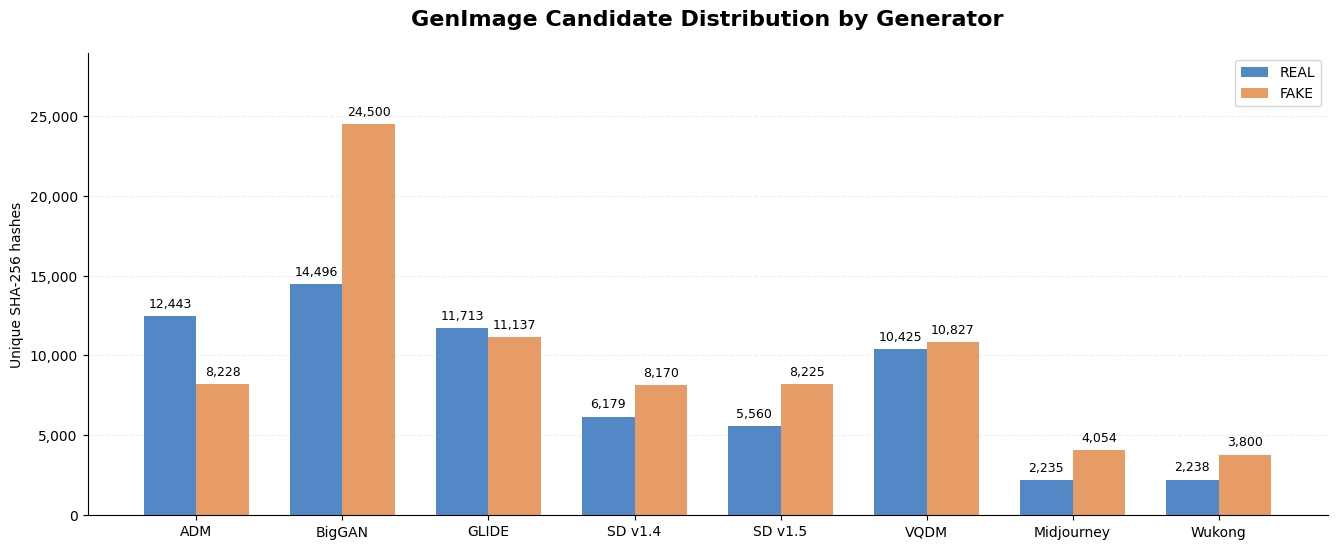


[2/5] Visualizing training source distribution...


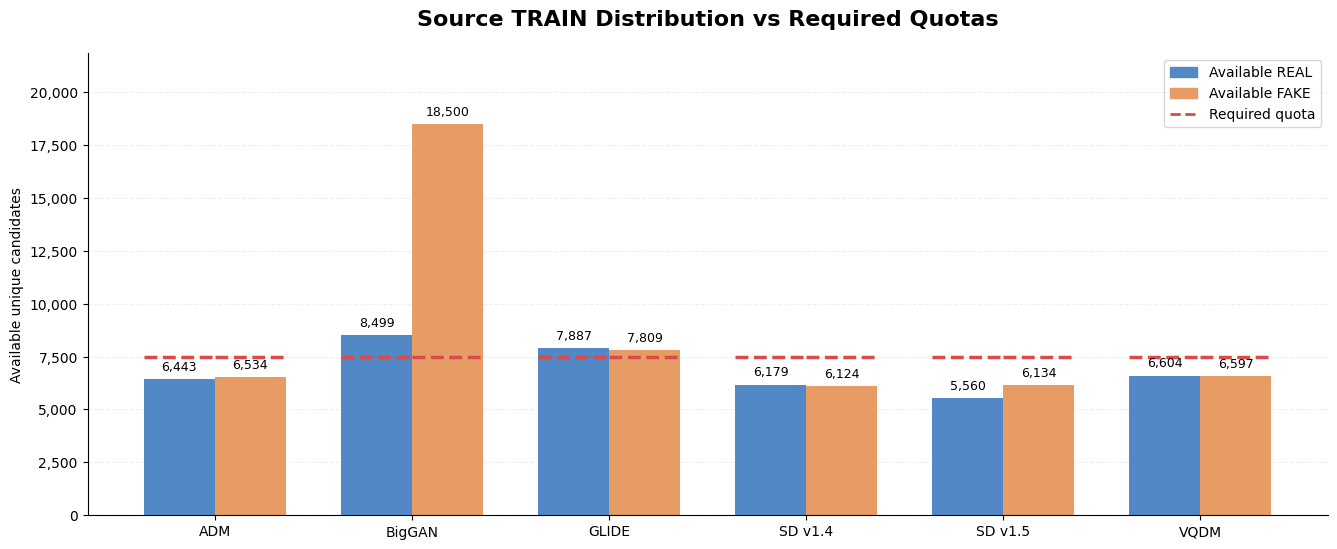


[3/5] Visualizing testing source distribution...


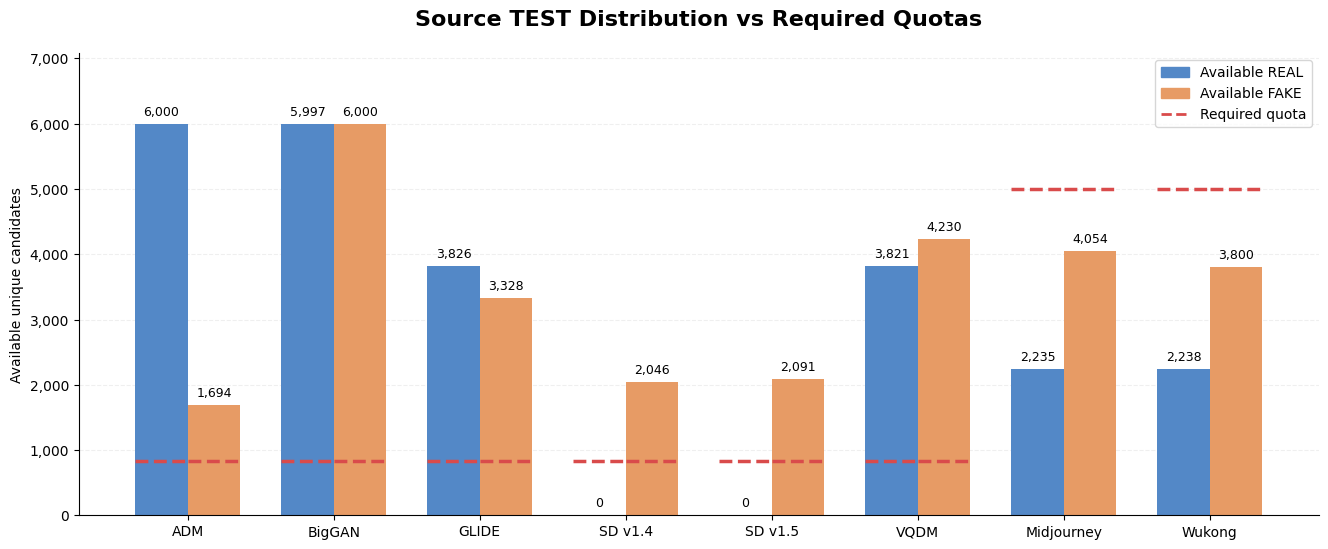


[4/5] Building quota coverage heatmap...


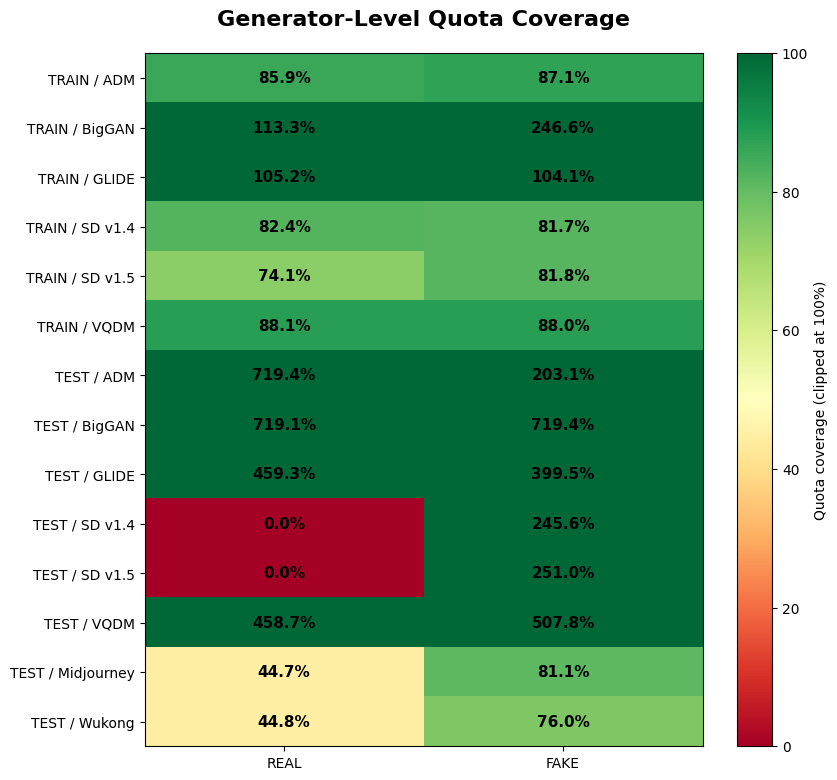


[5/5] Analyzing inventory expansion impact...


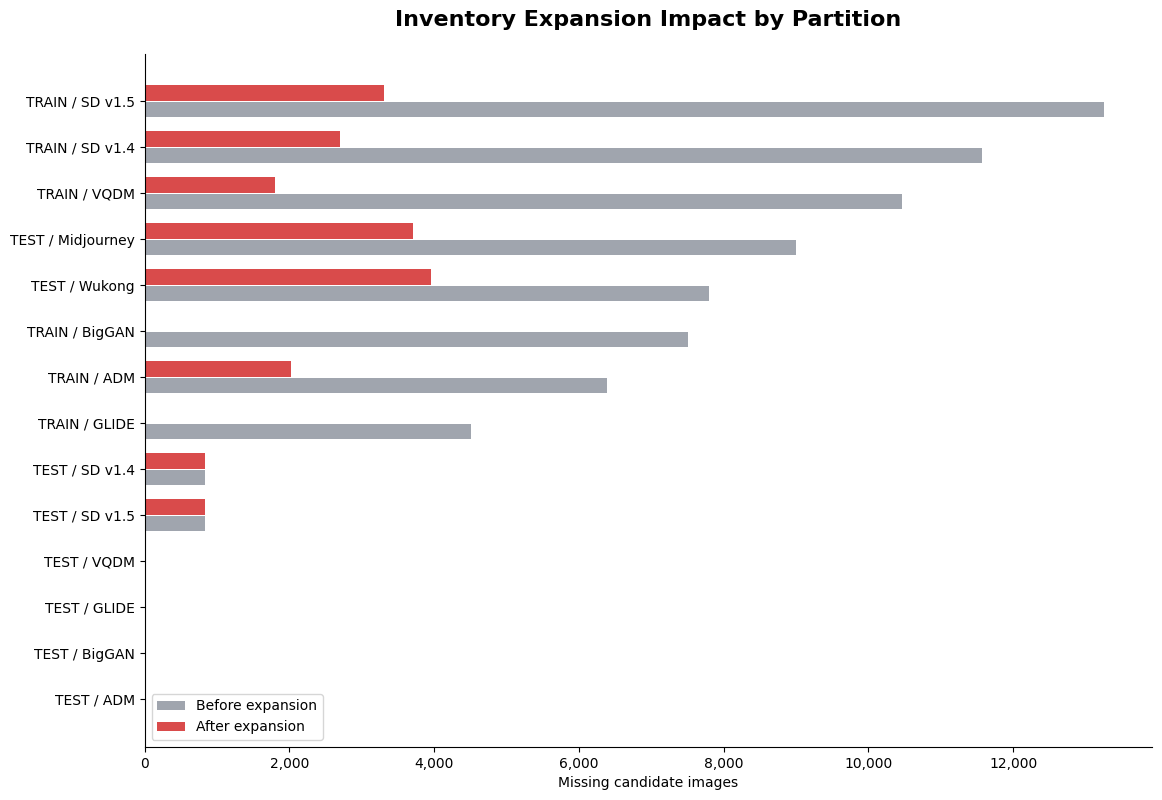


Remaining quota bottlenecks:


,source_split,generator,label,required,available_unique,shortfall,coverage_pct
0,test,Midjourney,REAL,"5,000","2,235","2,765",44.70%
1,test,Wukong,REAL,"5,000","2,238","2,762",44.76%
2,train,SD v1.5,REAL,"7,499","5,560","1,939",74.14%
3,train,SD v1.4,FAKE,"7,500","6,124","1,376",81.65%
4,train,SD v1.5,FAKE,"7,499","6,134","1,365",81.80%
5,train,SD v1.4,REAL,"7,500","6,179","1,321",82.39%
6,test,Wukong,FAKE,"5,000","3,800","1,200",76.00%
7,train,ADM,REAL,"7,501","6,443","1,058",85.90%
8,train,ADM,FAKE,"7,501","6,534",967,87.11%
9,test,Midjourney,FAKE,"5,000","4,054",946,81.08%


Uploaded: 01_generator_distribution.png
Uploaded: 02_train_source_distribution.png
Uploaded: 03_test_source_distribution.png
Uploaded: 04_quota_coverage_heatmap.png
Uploaded: 05_expansion_impact.png
Uploaded: generator_summary.csv
Uploaded: quota_coverage.csv
Uploaded: remaining_bottlenecks.csv
Uploaded: expansion_impact.csv
Uploaded: eda_report.json

PROOFLENS — GENERATOR EDA SUMMARY
Eligible records      : 144,232
Unique SHA-256 hashes : 144,219
Generators            : 8
Quota coverage        : 84.03%
Remaining shortfall   : 19,162
Underfilled strata    : 14
Visualizations        : 5
New image downloads   : 0
Inventory modified    : NO
Drive artifacts       : pipeline_metadata/generator_eda/3f4b9f921a673be09a93b335ed728cea0c6ecf33/20261124_125617_658178

CELL 4.2.1 COMPLETE — Generator EDA and bottleneck analysis saved.


In [ ]:

# ============================================================
# CELL 4.2.1 — GENERATOR DATA VISUALIZATION & EDA
# ProofLens / Cifaker Data Engineering Pipeline
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datetime import datetime, timezone
from matplotlib.ticker import StrMethodFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ------------------------------------------------------------
# 1. Validate previous stage outputs
# ------------------------------------------------------------

if "expanded_clean_df" not in globals():
    raise RuntimeError("Run Cell 4.2 first.")

if "after_availability_42" not in globals():
    raise RuntimeError("Missing quota availability results.")

eda_df = expanded_clean_df.copy()

quota_df = after_availability_42.copy()

assert not eda_df.empty
assert eda_df["label"].isin([0, 1]).all()

GENERATOR_ORDER = [
    "adm",
    "biggan",
    "glide",
    "sdv4",
    "sdv5",
    "vqdm",
    "midjourney",
    "wukong",
]

GENERATOR_NAMES = {
    "adm": "ADM",
    "biggan": "BigGAN",
    "glide": "GLIDE",
    "sdv4": "SD v1.4",
    "sdv5": "SD v1.5",
    "vqdm": "VQDM",
    "midjourney": "Midjourney",
    "wukong": "Wukong",
}

REAL_COLOR = "#5388C7"
FAKE_COLOR = "#E79B65"
QUOTA_COLOR = "#D94B4B"

timestamp_421 = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S_%f")

EDA_DIR = (
    WORK_DIR
    / "generator_eda"
    / timestamp_421
)

EDA_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

plot_artifacts = []

# ------------------------------------------------------------
# 2. Visualization helpers
# ------------------------------------------------------------

def save_plot(fig, filename):

    path = EDA_DIR / filename

    fig.savefig(
        path,
        dpi=160,
        bbox_inches="tight",
        facecolor=fig.get_facecolor(),
    )

    plot_artifacts.append(path)

    plt.show()
    plt.close(fig)


def format_axis(ax):

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.2,
    )

    ax.set_axisbelow(True)

    ax.yaxis.set_major_formatter(
        StrMethodFormatter("{x:,.0f}")
    )


def annotate_bars(ax, bars):

    for bar in bars:

        value = bar.get_height()

        ax.annotate(
            f"{int(value):,}",
            (
                bar.get_x() + bar.get_width() / 2,
                value,
            ),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )


# ------------------------------------------------------------
# 3. Generator distribution summary
# ------------------------------------------------------------

print("[1/5] Analyzing generator distribution...")

generator_summary = (
    eda_df
    .groupby(["source_generator_group", "label"])
    ["sha256"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(
        index=GENERATOR_ORDER,
        columns=[0, 1],
        fill_value=0,
    )
)

generator_summary.columns = [
    "REAL",
    "FAKE",
]

generator_summary["Total"] = (
    generator_summary["REAL"]
    + generator_summary["FAKE"]
)

generator_summary["REAL_ratio"] = (
    generator_summary["REAL"]
    / generator_summary["Total"].replace(0, np.nan)
)

generator_summary["FAKE_ratio"] = (
    generator_summary["FAKE"]
    / generator_summary["Total"].replace(0, np.nan)
)

display(
    generator_summary.style.format({
        "REAL": "{:,}",
        "FAKE": "{:,}",
        "Total": "{:,}",
        "REAL_ratio": "{:.2%}",
        "FAKE_ratio": "{:.2%}",
    })
)

x = np.arange(len(GENERATOR_ORDER))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(16, 6))

real_bars = ax.bar(
    x - bar_width / 2,
    generator_summary["REAL"],
    bar_width,
    label="REAL",
    color=REAL_COLOR,
)

fake_bars = ax.bar(
    x + bar_width / 2,
    generator_summary["FAKE"],
    bar_width,
    label="FAKE",
    color=FAKE_COLOR,
)

annotate_bars(ax, real_bars)
annotate_bars(ax, fake_bars)

ax.set_xticks(x)
ax.set_xticklabels([
    GENERATOR_NAMES[g]
    for g in GENERATOR_ORDER
])

ax.set_ylabel("Unique SHA-256 hashes")

ax.set_title(
    "GenImage Candidate Distribution by Generator",
    fontsize=16,
    fontweight="bold",
    pad=20,
)

ax.legend()
ax.margins(y=0.18)

format_axis(ax)

save_plot(
    fig,
    "01_generator_distribution.png",
)

# ------------------------------------------------------------
# 4. Source split visualization against required quotas
# ------------------------------------------------------------

def plot_split_distribution(source_split):

    subset = quota_df.loc[
        quota_df["source_split"].eq(source_split)
    ].copy()

    generators = [
        generator
        for generator in GENERATOR_ORDER
        if generator in subset["generator"].values
    ]

    real_data = (
        subset.loc[subset["label"].eq(0)]
        .set_index("generator")
        .reindex(generators)
    )

    fake_data = (
        subset.loc[subset["label"].eq(1)]
        .set_index("generator")
        .reindex(generators)
    )

    positions = np.arange(len(generators))

    fig, ax = plt.subplots(figsize=(16, 6))

    bars_real = ax.bar(
        positions - bar_width / 2,
        real_data["available_unique"],
        bar_width,
        color=REAL_COLOR,
        label="Available REAL",
    )

    bars_fake = ax.bar(
        positions + bar_width / 2,
        fake_data["available_unique"],
        bar_width,
        color=FAKE_COLOR,
        label="Available FAKE",
    )

    # Draw quota markers on individual bars.
    for index in range(len(generators)):

        real_x = positions[index] - bar_width / 2
        fake_x = positions[index] + bar_width / 2

        ax.hlines(
            real_data["required"].iloc[index],
            real_x - bar_width / 2,
            real_x + bar_width / 2,
            colors=QUOTA_COLOR,
            linewidth=2.5,
            linestyles="--",
        )

        ax.hlines(
            fake_data["required"].iloc[index],
            fake_x - bar_width / 2,
            fake_x + bar_width / 2,
            colors=QUOTA_COLOR,
            linewidth=2.5,
            linestyles="--",
        )

    annotate_bars(ax, bars_real)
    annotate_bars(ax, bars_fake)

    ax.set_xticks(positions)

    ax.set_xticklabels([
        GENERATOR_NAMES[g]
        for g in generators
    ])

    ax.set_ylabel("Available unique candidates")

    ax.set_title(
        f"Source {source_split.upper()} Distribution "
        "vs Required Quotas",
        fontsize=16,
        fontweight="bold",
        pad=20,
    )

    handles = [
        Patch(
            color=REAL_COLOR,
            label="Available REAL",
        ),
        Patch(
            color=FAKE_COLOR,
            label="Available FAKE",
        ),
        Line2D(
            [0],
            [0],
            color=QUOTA_COLOR,
            linestyle="--",
            linewidth=2,
            label="Required quota",
        ),
    ]

    ax.legend(handles=handles)
    ax.margins(y=0.18)

    format_axis(ax)

    return fig


print("\n[2/5] Visualizing training source distribution...")

fig = plot_split_distribution("train")

save_plot(
    fig,
    "02_train_source_distribution.png",
)

print("\n[3/5] Visualizing testing source distribution...")

fig = plot_split_distribution("test")

save_plot(
    fig,
    "03_test_source_distribution.png",
)

# ------------------------------------------------------------
# 5. Quota coverage heatmap
# ------------------------------------------------------------

print("\n[4/5] Building quota coverage heatmap...")

quota_df["coverage_pct"] = (
    quota_df["available_unique"]
    / quota_df["required"]
    * 100
)

quota_df["partition_name"] = (
    quota_df["source_split"].str.upper()
    + " / "
    + quota_df["generator"].map(GENERATOR_NAMES)
)

heatmap_df = quota_df.pivot(
    index="partition_name",
    columns="label",
    values="coverage_pct",
).reindex(columns=[0, 1])

partition_order = [
    f"{split.upper()} / {GENERATOR_NAMES[g]}"
    for split in ("train", "test")
    for g in GENERATOR_ORDER
    if f"{split.upper()} / {GENERATOR_NAMES[g]}"
    in heatmap_df.index
]

heatmap_df = heatmap_df.reindex(
    partition_order
)

heatmap_values = heatmap_df.to_numpy()

fig, ax = plt.subplots(
    figsize=(9, 9)
)

heatmap = ax.imshow(
    np.clip(heatmap_values, 0, 100),
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    aspect="auto",
)

ax.set_xticks([0, 1])
ax.set_xticklabels(["REAL", "FAKE"])

ax.set_yticks(
    np.arange(len(heatmap_df))
)

ax.set_yticklabels(
    heatmap_df.index
)

for row in range(heatmap_values.shape[0]):

    for column in range(heatmap_values.shape[1]):

        value = heatmap_values[row, column]

        if np.isnan(value):

            label = "N/A"

        else:

            label = f"{value:.1f}%"

        ax.text(
            column,
            row,
            label,
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            color="black",
        )

colorbar = fig.colorbar(
    heatmap,
    ax=ax,
)

colorbar.set_label(
    "Quota coverage (clipped at 100%)"
)

ax.set_title(
    "Generator-Level Quota Coverage",
    fontsize=16,
    fontweight="bold",
    pad=20,
)

save_plot(
    fig,
    "04_quota_coverage_heatmap.png",
)

# ------------------------------------------------------------
# 6. Expansion impact analysis
# ------------------------------------------------------------

print("\n[5/5] Analyzing inventory expansion impact...")

impact_df = comparison_42.copy()

impact_df["partition_name"] = (
    impact_df["source_split"].str.upper()
    + " / "
    + impact_df["generator"].map(GENERATOR_NAMES)
)

impact_summary = (
    impact_df
    .groupby("partition_name")
    [
        [
            "shortfall_before",
            "shortfall_after",
        ]
    ]
    .sum()
    .sort_values(
        "shortfall_before",
        ascending=True,
    )
)

fig, ax = plt.subplots(
    figsize=(13, 9)
)

positions = np.arange(
    len(impact_summary)
)

ax.barh(
    positions - 0.18,
    impact_summary["shortfall_before"],
    height=0.34,
    color="#A0A5AE",
    label="Before expansion",
)

ax.barh(
    positions + 0.18,
    impact_summary["shortfall_after"],
    height=0.34,
    color=QUOTA_COLOR,
    label="After expansion",
)

ax.set_yticks(positions)

ax.set_yticklabels(
    impact_summary.index
)

ax.set_xlabel("Missing candidate images")

ax.set_title(
    "Inventory Expansion Impact by Partition",
    fontsize=16,
    fontweight="bold",
    pad=20,
)

ax.xaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend()

save_plot(
    fig,
    "05_expansion_impact.png",
)

# ------------------------------------------------------------
# 7. Remaining bottlenecks
# ------------------------------------------------------------

print("\nRemaining quota bottlenecks:")

bottleneck_df = quota_df.loc[
    quota_df["shortfall"] > 0,
    [
        "source_split",
        "generator",
        "label",
        "required",
        "available_unique",
        "shortfall",
        "coverage_pct",
    ],
].copy()

bottleneck_df["generator"] = (
    bottleneck_df["generator"]
    .map(GENERATOR_NAMES)
)

bottleneck_df["label"] = (
    bottleneck_df["label"]
    .map({0: "REAL", 1: "FAKE"})
)

bottleneck_df = bottleneck_df.sort_values(
    "shortfall",
    ascending=False,
).reset_index(drop=True)

display(
    bottleneck_df.style.format({
        "required": "{:,}",
        "available_unique": "{:,}",
        "shortfall": "{:,}",
        "coverage_pct": "{:.2f}%",
    })
)

# ------------------------------------------------------------
# 8. Save EDA tables and visualizations to Drive
# ------------------------------------------------------------

summary_path = EDA_DIR / "generator_summary.csv"
quota_path = EDA_DIR / "quota_coverage.csv"
bottleneck_path = EDA_DIR / "remaining_bottlenecks.csv"
impact_path = EDA_DIR / "expansion_impact.csv"

generator_summary.to_csv(summary_path)
quota_df.to_csv(quota_path, index=False)
bottleneck_df.to_csv(bottleneck_path, index=False)
impact_summary.to_csv(impact_path)

EDA_REMOTE_PREFIX = (
    f"pipeline_metadata/generator_eda/"
    f"{HF_REVISION}/{timestamp_421}"
)

eda_report = {
    "stage": "4.2.1",
    "source_revision": HF_REVISION,
    "code_commit": CURRENT_COMMIT,
    "parent_remote_prefix": REMOTE_PREFIX_42,
    "eligible_records": len(eda_df),
    "globally_unique_sha256": int(
        eda_df["sha256"].nunique()
    ),
    "quota_coverage": coverage_after_42,
    "remaining_shortfall": int(
        bottleneck_df["shortfall"].sum()
    ),
    "generator_count": len(GENERATOR_ORDER),
    "visualization_count": len(plot_artifacts),
    "new_image_downloads": 0,
    "inventory_modified": False,
    "dataset_published": False,
}

report_path = EDA_DIR / "eda_report.json"

report_path.write_text(
    json.dumps(eda_report, indent=2),
    encoding="utf-8",
)

eda_artifacts = plot_artifacts + [
    summary_path,
    quota_path,
    bottleneck_path,
    impact_path,
    report_path,
]

for artifact in eda_artifacts:

    storage.upload(
        artifact,
        f"{EDA_REMOTE_PREFIX}/{artifact.name}",
        overwrite=False,
    )

    print(f"Uploaded: {artifact.name}")

# ------------------------------------------------------------
# 9. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PROOFLENS — GENERATOR EDA SUMMARY")
print("=" * 65)

print(f"Eligible records      : {len(eda_df):,}")

print(
    f"Unique SHA-256 hashes : "
    f"{eda_df['sha256'].nunique():,}"
)

print(f"Generators            : {len(GENERATOR_ORDER)}")

print(
    f"Quota coverage        : "
    f"{coverage_after_42:.2%}"
)

print(
    f"Remaining shortfall   : "
    f"{bottleneck_df['shortfall'].sum():,}"
)

print(f"Underfilled strata    : {len(bottleneck_df)}")
print(f"Visualizations        : {len(plot_artifacts)}")
print("New image downloads   : 0")
print("Inventory modified    : NO")
print(f"Drive artifacts       : {EDA_REMOTE_PREFIX}")

print("=" * 65)

print(
    "\nCELL 4.2.1 COMPLETE — "
    "Generator EDA and bottleneck analysis saved."
)


[1/7] Initializing label-aware acquisition...
Download budget: 12 GiB
HF authentication: Default / anonymous

[2/7] Restoring verified inventory checkpoints...
Restored shards: 56
Restored records: 144,253

Observed label distribution by source shard:


,source_split,generator,source_shard,shard_position,total_partition_shards,real_count,fake_count,total_unique_within_shard,real_ratio,fake_ratio,shard_bytes
0,train,adm,data/train/ADM/data-00000-of-00075.arrow,0,75,2112,2198,4310,0.490023,0.509977,503603656
1,train,adm,data/train/ADM/data-00060-of-00075.arrow,60,75,2219,2141,4360,0.508945,0.491055,511305560
2,train,adm,data/train/ADM/data-00062-of-00075.arrow,62,75,2113,2195,4308,0.490483,0.509517,497637976
3,train,biggan,data/train/BigGAN/data-00006-of-00048.arrow,6,48,0,18500,18500,0.000000,1.000000,510399136
4,train,biggan,data/train/BigGAN/data-00018-of-00048.arrow,18,48,4500,0,4500,1.000000,0.000000,470327912
5,train,biggan,data/train/BigGAN/data-00027-of-00048.arrow,27,48,4000,0,4000,1.000000,0.000000,459009184
6,train,glide,data/train/glide/data-00014-of-00062.arrow,14,62,2666,2620,5286,0.504351,0.495649,511445272
7,train,glide,data/train/glide/data-00017-of-00062.arrow,17,62,2666,2545,5211,0.511610,0.488390,504670576
8,train,glide,data/train/glide/data-00054-of-00062.arrow,54,62,2556,2644,5200,0.491538,0.508462,505508704
9,train,sdv4,data/train/stable_diffusion_v_1_4/data-00083-o...,83,189,819,861,1680,0.487500,0.512500,482239056



Initial bottlenecks:


,source_split,generator,label,required,available_unique,candidate_target,shortfall,headroom_shortfall
6,test,midjourney,REAL,5000,2235,6250,2765,4015
14,test,wukong,REAL,5000,2238,6250,2762,4012
24,train,sdv5,REAL,7499,5560,9374,1939,3814
23,train,sdv4,FAKE,7500,6124,9375,1376,3251
25,train,sdv5,FAKE,7499,6134,9374,1365,3240
22,train,sdv4,REAL,7500,6179,9375,1321,3196
15,test,wukong,FAKE,5000,3800,6250,1200,2450
16,train,adm,REAL,7501,6443,9377,1058,2934
17,train,adm,FAKE,7501,6534,9377,967,2843
7,test,midjourney,FAKE,5000,4054,6250,946,2196



[3/7] Starting label-aware acquisition...

-----------------------------------------------------------------
Partition       : ('test', 'sdv4')
Shard           : data/test/stable_diffusion_v_1_4/data-00000-of-00008.arrow
Required REAL   : 833
Required FAKE   : 0
Critical test   : True
Selection mode  : EXPLORATION
Estimated REAL  : 0
Estimated FAKE  : 1,018
Shard size      : 477.24 MiB


data/test/stable_diffusion_v_1_4/data-00(…): reconstructing file:   0%|          |  0.00B /  500MB            

... (59 outputs left out)

,metric,value
0,new_shards,20.000000
1,scheduled_download_gib,7.841988
2,new_indexed_records,38332.000000
3,net_quota_gain,19162.000000
4,quota_coverage_before,0.840317
5,quota_coverage_after,1.000000
6,quota_improvement_pp,15.968333
7,acquisition_efficiency_per_gib,2443.513014
8,net_useful_candidate_ratio,0.499896
9,shard_hit_rate,0.950000



Remaining quota bottlenecks:


,source_split,generator,label,required,available_unique,candidate_target,shortfall,headroom_shortfall



[6/7] Visualizing acquisition outcomes...


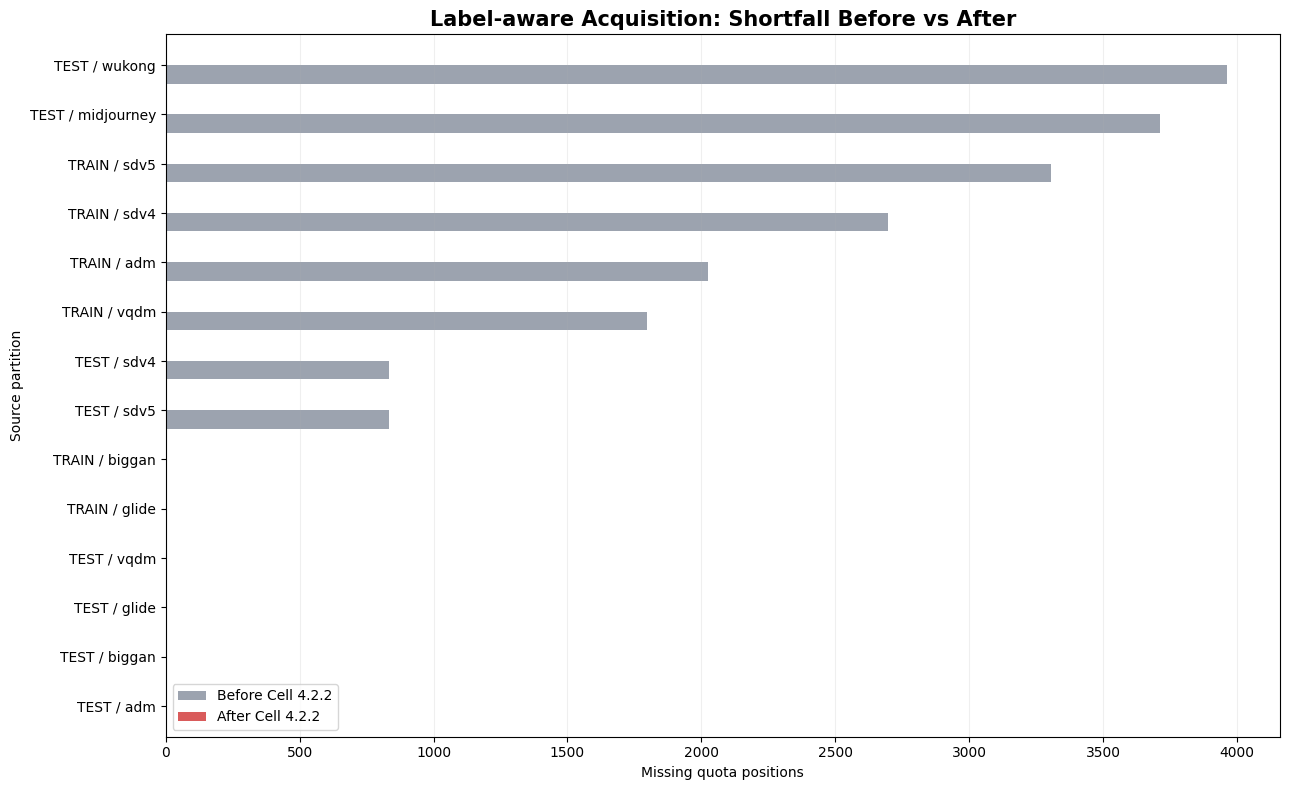

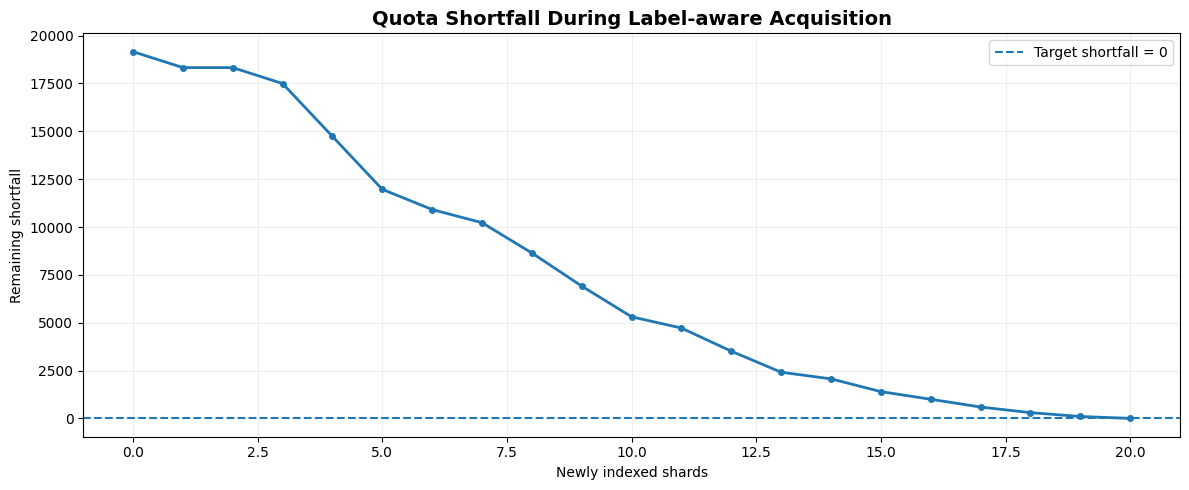


[7/7] Saving traceability artifacts to Drive...
Uploaded: expanded_inventory.parquet
Uploaded: clean_inventory.parquet
Uploaded: quarantine.parquet
Uploaded: shard_profiles_before.csv
Uploaded: shard_profiles_after.csv
Uploaded: download_history.csv
Uploaded: quota_comparison.csv
Uploaded: remaining_bottlenecks.csv
Uploaded: plan.json
Uploaded: plan_selection.parquet
Uploaded: shortfall_comparison.png
Uploaded: acquisition_progress.png
Uploaded: acquisition_report.json

PROOFLENS — LABEL-AWARE ACQUISITION SUMMARY
Restored shards       : 56
New shards            : 20
Total indexed shards  : 76
Raw candidates        : 182,585
Eligible candidates   : 182,552
Quarantined records   : 33
Quota coverage        : 84.03% -> 100.00%
Quota shortfall       : 19,162 -> 0
Net quota gain        : 19,162
Scheduled downloads   : 7.84 GiB
Positive-progress     : 19
Zero-progress         : 1
Negative-progress     : 0
Acquisition efficiency: 2,443.51 quota/GiB
Shard hit rate        : 95.00%
Exact leakage

In [ ]:

# ============================================================
# CELL 4.2.2 — LABEL-AWARE DEFICIT-DRIVEN ACQUISITION
# ProofLens / Cifaker Data Engineering Pipeline
# ============================================================

import os
import re
import json
import time
import shutil
import hashlib
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime, timezone

from huggingface_hub import (
    hf_hub_download,
    try_to_load_from_cache,
)

from prooflens.data.storage.base import compute_local_hashes

from prooflens.data.registry.schema import (
    write_canonical_parquet,
)

from prooflens.data.registry.duplicates import (
    assign_leakage_groups,
)

from prooflens.data.sampling.planner import plan_release

from prooflens.data.sampling.stratification import (
    QuotaInfeasibleError,
)

from prooflens.data.sampling.leakage_guard import (
    check_leakage_boundaries,
    LeakageViolationError,
)

# ------------------------------------------------------------
# 1. Stage configuration
# ------------------------------------------------------------

MAX_NEW_DOWNLOAD_GIB_422 = 12
DOWNLOAD_BUDGET_422 = MAX_NEW_DOWNLOAD_GIB_422 * 1024**3

MIN_FREE_DISK_BYTES = 3 * 1024**3
NEIGHBOR_COUNT = 3
EXPLORATION_WEIGHT = 0.20

started_422 = time.perf_counter()

if "config_42" not in globals():
    raise RuntimeError("Run Cell 4.2 before this stage.")

config_422 = config_42

# Optional authentication through Colab Secrets.
hf_token_422 = os.environ.get("HF_TOKEN")

if not hf_token_422:
    try:
        from google.colab import userdata

        hf_token_422 = userdata.get("HF_TOKEN")
    except Exception:
        hf_token_422 = None

print("[1/7] Initializing label-aware acquisition...")

print(f"Download budget: {MAX_NEW_DOWNLOAD_GIB_422} GiB")
print(f"HF authentication: {'Configured' if hf_token_422 else 'Default / anonymous'}")

timestamp_422 = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%f"
)

STAGE_422_DIR = (
    WORK_DIR
    / "label_aware_acquisition"
    / timestamp_422
)

STAGE_422_DIR.mkdir(parents=True, exist_ok=True)

REMOTE_PREFIX_422 = (
    f"pipeline_metadata/label_aware_acquisition/"
    f"{HF_REVISION}/{timestamp_422}"
)

# ------------------------------------------------------------
# 2. Restore previous inventory checkpoints
# ------------------------------------------------------------

print("\n[2/7] Restoring verified inventory checkpoints...")

remote_objects_422 = set(
    storage.list_objects(prefix=REMOTE_PREFIX)
)

frames_422 = {}
completed_shards_422 = set()

ordered_shards_422 = {
    partition: sorted(
        partition_shards[partition],
        key=lambda shard: shard.rfilename,
    )
    for partition in requirements
}

for partition, shards in ordered_shards_422.items():

    for shard in shards:

        local_path, remote_key = inventory_key(shard)

        if remote_key not in remote_objects_422:
            continue

        # Reuse checksum-verified restore from Cell 4.2.
        frame = restore_inventory_42(
            local_path,
            remote_key,
        )

        assert frame["source_revision"].eq(
            HF_REVISION
        ).all()

        assert frame["source_shard"].eq(
            shard.rfilename
        ).all()

        assert frame["source_split"].eq(
            partition[0]
        ).all()

        assert frame["source_generator_group"].eq(
            partition[1]
        ).all()

        frames_422[shard.rfilename] = frame

        completed_shards_422.add(
            shard.rfilename
        )

if not frames_422:
    raise RuntimeError("No inventory checkpoints found.")

restored_shards_422 = len(completed_shards_422)

print(f"Restored shards: {restored_shards_422:,}")

print(
    f"Restored records: "
    f"{sum(len(f) for f in frames_422.values()):,}"
)

# ------------------------------------------------------------
# 3. Build observed shard label profiles
# ------------------------------------------------------------

def build_shard_profiles_422():

    profiles = []

    for partition, shards in ordered_shards_422.items():

        for position, shard in enumerate(shards):

            frame = frames_422.get(
                shard.rfilename
            )

            if frame is None:
                continue

            counts = (
                frame.groupby("label")["sha256"]
                .nunique()
                .to_dict()
            )

            real_count = int(counts.get(0, 0))
            fake_count = int(counts.get(1, 0))

            total = real_count + fake_count

            profiles.append({
                "source_split": partition[0],
                "generator": partition[1],
                "source_shard": shard.rfilename,
                "shard_position": position,
                "total_partition_shards": len(shards),
                "real_count": real_count,
                "fake_count": fake_count,
                "total_unique_within_shard": total,
                "real_ratio": (
                    real_count / total if total else 0
                ),
                "fake_ratio": (
                    fake_count / total if total else 0
                ),
                "shard_bytes": shard.size,
            })

    return pd.DataFrame(profiles)


initial_profiles_422 = build_shard_profiles_422()

print("\nObserved label distribution by source shard:")

display(initial_profiles_422.head(20))

# ------------------------------------------------------------
# 4. Global quota availability
# ------------------------------------------------------------

def calculate_availability_422():

    merged = pd.concat(
        list(frames_422.values()),
        ignore_index=True,
    )

    if not merged["image_id"].is_unique:
        raise ValueError("Duplicate canonical image IDs.")

    if not merged["sha256"].astype(str).str.fullmatch(
        r"[0-9a-fA-F]{64}"
    ).all():
        raise ValueError("Missing or invalid SHA-256 hashes.")

    hash_audit = (
        merged.groupby("sha256")
        .agg(
            splits=("source_split", "nunique"),
            labels=("label", "nunique"),
        )
    )

    bad_hashes = set(
        hash_audit.index[
            (hash_audit["splits"] > 1)
            | (hash_audit["labels"] > 1)
        ]
    )

    eligible = merged.loc[
        ~merged["sha256"].isin(bad_hashes)
        & merged["eligibility_status"].eq("ELIGIBLE")
    ]

    counts = (
        eligible.groupby([
            "source_split",
            "source_generator_group",
            "label",
        ])["sha256"]
        .nunique()
        .to_dict()
    )

    rows = []

    for partition, quotas in sorted(
        requirements.items()
    ):

        for label in (0, 1):

            available = int(
                counts.get(
                    (
                        partition[0],
                        partition[1],
                        label,
                    ),
                    0,
                )
            )

            required = quotas[label]

            target = targets[partition][label]

            rows.append({
                "source_split": partition[0],
                "generator": partition[1],
                "label": label,
                "required": required,
                "available_unique": available,
                "candidate_target": target,
                "shortfall": max(
                    0, required - available
                ),
                "headroom_shortfall": max(
                    0, target - available
                ),
            })

    return pd.DataFrame(rows), merged


def quota_shortfall_422(availability):

    return int(
        availability["shortfall"].sum()
    )


def display_availability_422(availability):

    output = availability.copy()

    output["label"] = output["label"].map({
        0: "REAL",
        1: "FAKE",
    })

    display(output)


before_422, _ = calculate_availability_422()

initial_shortfall_422 = quota_shortfall_422(
    before_422
)

total_required_422 = int(
    before_422["required"].sum()
)

print("\nInitial bottlenecks:")

display_availability_422(
    before_422.loc[
        before_422["shortfall"] > 0
    ].sort_values(
        "shortfall",
        ascending=False,
    )
)

# ------------------------------------------------------------
# 5. Exact leakage audit and sampling feasibility
# ------------------------------------------------------------

def audit_and_plan_422():

    raw = pd.concat(
        list(frames_422.values()),
        ignore_index=True,
    )

    grouped, duplicate_report = assign_leakage_groups(
        raw,
        audit_scope="label_aware_candidate_inventory",
        include_pixel_hash=False,
        include_perceptual_in_leakage_groups=False,
    )

    group_audit = (
        grouped.groupby("leakage_group_id")
        .agg(
            splits=("source_split", "nunique"),
            labels=("label", "nunique"),
        )
    )

    bad_groups = set(
        group_audit.index[
            (group_audit["splits"] > 1)
            | (group_audit["labels"] > 1)
        ]
    )

    mask = grouped["leakage_group_id"].isin(
        bad_groups
    )

    quarantine = grouped.loc[mask].copy()

    quarantine["eligibility_status"] = "EXCLUDED"

    quarantine["exclusion_reason"] = (
        "CROSS_SOURCE_SPLIT_OR_LABEL_LEAKAGE"
    )

    clean = grouped.loc[
        ~mask
        & grouped["eligibility_status"].eq("ELIGIBLE")
    ].copy()

    leakage_check = check_leakage_boundaries(
        clean,
        split_column="source_split",
        raise_on_violation=True,
    )

    plan = None
    planner_error = None

    try:

        plan = plan_release(
            inventory_df=clean,
            config=config_422,
            dry_run=True,
        )

    except (
        QuotaInfeasibleError,
        LeakageViolationError,
    ) as exc:

        planner_error = str(exc)

    # Independent validation of a feasible selection.
    if plan is not None and plan.feasible:

        selection = plan.selection_df

        assert len(selection) == total_required_422
        assert selection["image_id"].is_unique
        assert selection["sha256"].is_unique

        for split_name, rule in (
            config_422.protocol.splits.items()
        ):

            subset = selection.loc[
                selection["release_split"].eq(
                    split_name
                )
            ]

            assert int(
                subset["label"].eq(0).sum()
            ) == rule.real_quota

            assert int(
                subset["label"].eq(1).sum()
            ) == rule.fake_quota

        check_leakage_boundaries(
            selection,
            split_column="release_split",
            raise_on_violation=True,
        )

    return (
        grouped,
        clean,
        quarantine,
        duplicate_report,
        leakage_check,
        plan,
        planner_error,
    )

# ------------------------------------------------------------
# 6. Label-aware shard scoring
# ------------------------------------------------------------

def estimate_shard_yield_422(
    partition,
    position,
    deficits,
    profiles,
    shard_size,
):

    observed = profiles.loc[
        profiles["source_split"].eq(partition[0])
        & profiles["generator"].eq(partition[1])
    ].copy()

    n_shards = len(
        ordered_shards_422[partition]
    )

    if observed.empty:

        return {
            "estimated_real": None,
            "estimated_fake": None,
            "estimated_useful": None,
            "exploration_distance": 1.0,
            "unknown_required_label": True,
            "score": 1.0,
        }

    observed["distance"] = (
        observed["shard_position"] - position
    ).abs()

    neighbors = observed.nsmallest(
        NEIGHBOR_COUNT,
        "distance",
    )

    weights = (
        1 / (1 + neighbors["distance"].to_numpy())
    )

    estimated_real = float(
        np.average(
            neighbors["real_count"],
            weights=weights,
        )
    )

    estimated_fake = float(
        np.average(
            neighbors["fake_count"],
            weights=weights,
        )
    )

    expected_useful = (
        min(deficits[0], estimated_real)
        + min(deficits[1], estimated_fake)
    )

    exploration_distance = float(
        observed["distance"].min()
        / max(1, n_shards - 1)
    )

    unknown_required_label = (
        (
            deficits[0] > 0
            and observed["real_count"].sum() == 0
        )
        or (
            deficits[1] > 0
            and observed["fake_count"].sum() == 0
        )
    )

    typical_yield = float(
        observed[
            "total_unique_within_shard"
        ].median()
    )

    exploration_bonus = (
        EXPLORATION_WEIGHT
        * typical_yield
        * exploration_distance
    )

    cost_gib = max(
        shard_size / 1024**3,
        0.001,
    )

    score = (
        expected_useful + exploration_bonus
    ) / cost_gib

    return {
        "estimated_real": estimated_real,
        "estimated_fake": estimated_fake,
        "estimated_useful": expected_useful,
        "exploration_distance": exploration_distance,
        "unknown_required_label": unknown_required_label,
        "score": score,
    }


# ------------------------------------------------------------
# 7. Partition prioritization
# ------------------------------------------------------------

def build_partition_priorities_422(
    availability,
    planner_error=None,
):

    priorities = []

    use_headroom = (
        quota_shortfall_422(availability) == 0
    )

    priority_column = (
        "headroom_shortfall"
        if use_headroom
        else "shortfall"
    )

    # If the planner fails despite local quota coverage,
    # prioritize the stratum reported in its error.
    planner_focus = None

    if planner_error:

        match = re.search(
            r"stratum '([^|]+)\|lbl=(\d)\|gen=([^'|]+)",
            planner_error,
        )

        if match:

            release_split, label, generator = (
                match.groups()
            )

            upstream_split = (
                "train"
                if release_split in ("train", "dev")
                else "test"
            )

            planner_focus = (
                upstream_split,
                generator,
                int(label),
            )

    for partition, subset in availability.groupby(
        ["source_split", "generator"]
    ):

        label_rows = subset.set_index("label")

        deficits = {
            label: int(
                label_rows.loc[
                    label,
                    priority_column,
                ]
            )
            for label in (0, 1)
        }

        focused = (
            planner_focus is not None
            and partition == planner_focus[:2]
        )

        if use_headroom and focused:

            focus_label = planner_focus[2]

            deficits[focus_label] = max(
                deficits[focus_label],
                int(
                    label_rows.loc[
                        focus_label,
                        "required",
                    ]
                ),
            )

        if sum(deficits.values()) == 0:
            continue

        zero_coverage = any(
            deficits[label] > 0
            and label_rows.loc[
                label, "available_unique"
            ] == 0
            for label in (0, 1)
        )

        critical_test = (
            partition[0] == "test"
            and deficits[0] > 0
            and label_rows.loc[
                0, "available_unique"
            ] == 0
        )

        priorities.append({
            "partition": partition,
            "deficits": deficits,
            "focused": focused,
            "critical_test": critical_test,
            "zero_coverage": zero_coverage,
            "total_deficit": sum(
                deficits.values()
            ),
        })

    return sorted(
        priorities,
        key=lambda item: (
            -int(item["focused"]),
            -int(item["critical_test"]),
            -int(item["zero_coverage"]),
            -item["total_deficit"],
            item["partition"],
        ),
    )


# ------------------------------------------------------------
# 8. Label-aware acquisition loop
# ------------------------------------------------------------

print("\n[3/7] Starting label-aware acquisition...")

scheduled_bytes_422 = 0
download_history_422 = []

stop_reason_422 = None

while True:

    availability, _ = (
        calculate_availability_422()
    )

    shortfall_before_shard = (
        quota_shortfall_422(availability)
    )

    planner_error = None

    # Validate global feasibility when all local
    # quota requirements appear to be satisfied.
    if shortfall_before_shard == 0:

        audit_result = audit_and_plan_422()

        provisional_plan = audit_result[5]
        planner_error = audit_result[6]

        if (
            provisional_plan is not None
            and provisional_plan.feasible
        ):

            stop_reason_422 = "SAMPLING_FEASIBLE"
            break

        print(
            "Local quotas satisfied, but the global "
            "planner still requires additional candidates."
        )

    profiles = build_shard_profiles_422()

    priorities = build_partition_priorities_422(
        availability,
        planner_error=planner_error,
    )

    selected = None

    for priority in priorities:

        partition = priority["partition"]
        deficits = priority["deficits"]

        ranked_candidates = []

        for position, shard in enumerate(
            ordered_shards_422[partition]
        ):

            if (
                shard.rfilename
                in completed_shards_422
            ):
                continue

            if shard.size is None:
                continue

            cached_path = try_to_load_from_cache(
                repo_id=HF_DATASET_ID,
                filename=shard.rfilename,
                revision=HF_REVISION,
                repo_type="dataset",
                cache_dir=str(HF_CACHE_DIR),
            )

            cache_hit = (
                isinstance(cached_path, str)
                and Path(cached_path).is_file()
                and Path(cached_path).stat().st_size
                == shard.size
            )

            required_bytes = (
                0 if cache_hit else shard.size
            )

            if (
                scheduled_bytes_422 + required_bytes
                > DOWNLOAD_BUDGET_422
            ):
                continue

            estimate = estimate_shard_yield_422(
                partition,
                position,
                deficits,
                profiles,
                shard.size,
            )

            ranked_candidates.append({
                "partition": partition,
                "shard": shard,
                "position": position,
                "cache_hit": cache_hit,
                "cached_path": cached_path,
                "required_bytes": required_bytes,
                "deficits": deficits,
                "critical_test": priority[
                    "critical_test"
                ],
                **estimate,
            })

        if not ranked_candidates:
            continue

        # Explore distant shard positions when the
        # required label has never been observed.
        # Otherwise exploit estimated label yield.
        ranked_candidates.sort(
            key=lambda item: (
                -int(item["cache_hit"]),
                -(
                    item["exploration_distance"]
                    if item["unknown_required_label"]
                    else 0
                ),
                -item["score"],
                stable_shard_rank(item["shard"]),
            )
        )

        selected = ranked_candidates[0]
        break

    if selected is None:

        stop_reason_422 = (
            "NO_FURTHER_ELIGIBLE_SHARD_WITHIN_BUDGET"
        )

        break

    partition = selected["partition"]
    shard = selected["shard"]
    required_bytes = selected["required_bytes"]

    if shutil.disk_usage("/content").free < (
        required_bytes + MIN_FREE_DISK_BYTES
    ):

        stop_reason_422 = (
            "INSUFFICIENT_RUNTIME_DISK"
        )

        break

    print("\n" + "-" * 65)

    print(f"Partition       : {partition}")
    print(f"Shard           : {shard.rfilename}")
    print(f"Required REAL   : {selected['deficits'][0]:,}")
    print(f"Required FAKE   : {selected['deficits'][1]:,}")
    print(f"Critical test   : {selected['critical_test']}")

    mode = (
        "EXPLORATION"
        if selected["unknown_required_label"]
        else "EXPLOITATION"
    )

    print(f"Selection mode  : {mode}")

    if selected["estimated_real"] is not None:

        print(
            f"Estimated REAL  : "
            f"{selected['estimated_real']:,.0f}"
        )

        print(
            f"Estimated FAKE  : "
            f"{selected['estimated_fake']:,.0f}"
        )

    print(
        f"Shard size      : "
        f"{shard.size / 1024**2:.2f} MiB"
    )

    shard_started = time.perf_counter()

    with tempfile.TemporaryDirectory(
        dir=str(WORK_DIR)
    ) as temporary_dir:

        if selected["cache_hit"]:

            arrow_path = selected["cached_path"]

        else:

            scheduled_bytes_422 += required_bytes

            arrow_path = hf_hub_download(
                repo_id=HF_DATASET_ID,
                repo_type="dataset",
                filename=shard.rfilename,
                revision=HF_REVISION,
                local_dir=temporary_dir,
                token=hf_token_422,
            )

        assert Path(arrow_path).stat().st_size == shard.size

        frame = read_shard_inventory(
            arrow_path,
            shard,
            partition,
        )

        local_path, remote_key = inventory_key(
            shard
        )

        write_canonical_parquet(
            frame,
            local_path,
        )

        _, local_sha256, _ = compute_local_hashes(
            local_path
        )

        storage.upload(
            local_path,
            remote_key,
            expected_sha256=local_sha256,
            overwrite=False,
        )

    # Register only after persistent storage succeeds.
    frames_422[shard.rfilename] = frame

    completed_shards_422.add(
        shard.rfilename
    )

    updated_availability, _ = (
        calculate_availability_422()
    )

    shortfall_after_shard = (
        quota_shortfall_422(
            updated_availability
        )
    )

    shortfall_reduction = (
        shortfall_before_shard
        - shortfall_after_shard
    )

    actual_counts = (
        frame["label"].value_counts().to_dict()
    )

    elapsed = (
        time.perf_counter() - shard_started
    )

    download_history_422.append({
        "source_split": partition[0],
        "generator": partition[1],
        "source_shard": shard.rfilename,
        "shard_position": selected["position"],
        "selection_mode": mode,
        "estimated_real": selected["estimated_real"],
        "estimated_fake": selected["estimated_fake"],
        "estimated_useful": selected["estimated_useful"],
        "actual_real": int(actual_counts.get(0, 0)),
        "actual_fake": int(actual_counts.get(1, 0)),
        "indexed_records": len(frame),
        "source_shard_bytes": shard.size,
        "scheduled_download_bytes": required_bytes,
        "cache_hit": selected["cache_hit"],
        "shortfall_before": shortfall_before_shard,
        "shortfall_after": shortfall_after_shard,
        "shortfall_reduction": shortfall_reduction,
        "duration_seconds": round(elapsed, 3),
    })

    print(
        f"Actual REAL/FAKE: "
        f"{actual_counts.get(0, 0):,} / "
        f"{actual_counts.get(1, 0):,}"
    )

    print(
        f"Shortfall       : "
        f"{shortfall_before_shard:,} -> "
        f"{shortfall_after_shard:,}"
    )

    print(
        f"Net quota gain  : "
        f"{shortfall_reduction:+,}"
    )

    print(
        f"Quota coverage  : "
        f"{1 - shortfall_after_shard / total_required_422:.2%}"
    )

    print(
        f"Download budget : "
        f"{scheduled_bytes_422 / 1024**3:.2f} / "
        f"{MAX_NEW_DOWNLOAD_GIB_422} GiB"
    )

# ------------------------------------------------------------
# 9. Final leakage audit and planner validation
# ------------------------------------------------------------

print("\n[4/7] Running global leakage and sampling audit...")

(
    expanded_inventory_422,
    expanded_clean_422,
    expanded_quarantine_422,
    duplicate_report_422,
    leakage_check_422,
    candidate_plan_422,
    planner_error_422,
) = audit_and_plan_422()

assert leakage_check_422.passed

after_422, _ = calculate_availability_422()

final_shortfall_422 = quota_shortfall_422(
    after_422
)

plan_feasible_422 = (
    candidate_plan_422 is not None
    and candidate_plan_422.feasible
    and final_shortfall_422 == 0
)

# ------------------------------------------------------------
# 10. Acquisition efficiency metrics
# ------------------------------------------------------------

print("\n[5/7] Calculating acquisition metrics...")

history_422 = pd.DataFrame(
    download_history_422
)

new_shards_422 = len(download_history_422)

download_gib_422 = (
    scheduled_bytes_422 / 1024**3
)

net_quota_gain_422 = (
    initial_shortfall_422
    - final_shortfall_422
)

coverage_before_422 = (
    1 - initial_shortfall_422 / total_required_422
)

coverage_after_422 = (
    1 - final_shortfall_422 / total_required_422
)

total_new_records_422 = (
    int(history_422["indexed_records"].sum())
    if new_shards_422 else 0
)

positive_progress_shards_422 = (
    int(
        history_422["shortfall_reduction"].gt(0).sum()
    )
    if new_shards_422 else 0
)

zero_progress_shards_422 = (
    int(
        history_422["shortfall_reduction"].eq(0).sum()
    )
    if new_shards_422 else 0
)

negative_progress_shards_422 = (
    int(
        history_422["shortfall_reduction"].lt(0).sum()
    )
    if new_shards_422 else 0
)

metrics_422 = {
    "new_shards": new_shards_422,
    "scheduled_download_gib": download_gib_422,
    "new_indexed_records": total_new_records_422,
    "net_quota_gain": net_quota_gain_422,
    "quota_coverage_before": coverage_before_422,
    "quota_coverage_after": coverage_after_422,
    "quota_improvement_pp": (
        coverage_after_422
        - coverage_before_422
    ) * 100,
    "acquisition_efficiency_per_gib": (
        net_quota_gain_422 / download_gib_422
        if download_gib_422 > 0
        else None
    ),
    "net_useful_candidate_ratio": (
        net_quota_gain_422 / total_new_records_422
        if total_new_records_422 > 0
        else None
    ),
    "shard_hit_rate": (
        positive_progress_shards_422
        / new_shards_422
        if new_shards_422
        else None
    ),
    "positive_progress_shards": (
        positive_progress_shards_422
    ),
    "zero_progress_shards": (
        zero_progress_shards_422
    ),
    "negative_progress_shards": (
        negative_progress_shards_422
    ),
}

display(
    pd.DataFrame(
        metrics_422.items(),
        columns=["metric", "value"],
    )
)

# ------------------------------------------------------------
# 11. Remaining bottleneck comparison
# ------------------------------------------------------------

comparison_422 = before_422.merge(
    after_422,
    on=[
        "source_split",
        "generator",
        "label",
        "required",
        "candidate_target",
    ],
    suffixes=("_before", "_after"),
    validate="one_to_one",
)

comparison_422["shortfall_reduction"] = (
    comparison_422["shortfall_before"]
    - comparison_422["shortfall_after"]
)

print("\nRemaining quota bottlenecks:")

display_availability_422(
    after_422.loc[
        after_422["shortfall"] > 0
    ].sort_values(
        "shortfall",
        ascending=False,
    )
)

# ------------------------------------------------------------
# 12. Visualization
# ------------------------------------------------------------

print("\n[6/7] Visualizing acquisition outcomes...")

plot_paths_422 = []

impact = (
    comparison_422.groupby([
        "source_split",
        "generator",
    ])[[
        "shortfall_before",
        "shortfall_after",
    ]]
    .sum()
    .sort_values("shortfall_before")
)

impact.index = [
    f"{split.upper()} / {generator}"
    for split, generator in impact.index
]

fig, ax = plt.subplots(
    figsize=(13, 8)
)

impact.plot.barh(
    ax=ax,
    color=["#9CA3AF", "#D95B5B"],
    width=0.75,
)

ax.set_title(
    "Label-aware Acquisition: Shortfall Before vs After",
    fontsize=15,
    fontweight="bold",
)

ax.set_xlabel("Missing quota positions")
ax.set_ylabel("Source partition")

ax.legend([
    "Before Cell 4.2.2",
    "After Cell 4.2.2",
])

ax.grid(
    axis="x",
    alpha=0.2,
)

plt.tight_layout()

plot_path = STAGE_422_DIR / "shortfall_comparison.png"

fig.savefig(
    plot_path,
    dpi=160,
    bbox_inches="tight",
)

plot_paths_422.append(plot_path)

plt.show()
plt.close(fig)

# Acquisition progress after each shard.
if new_shards_422:

    progress = [
        initial_shortfall_422
    ] + history_422[
        "shortfall_after"
    ].tolist()

    fig, ax = plt.subplots(
        figsize=(12, 5)
    )

    ax.plot(
        range(len(progress)),
        progress,
        marker="o",
        markersize=4,
        linewidth=2,
    )

    ax.axhline(
        0,
        linestyle="--",
        label="Target shortfall = 0",
    )

    ax.set_title(
        "Quota Shortfall During Label-aware Acquisition",
        fontsize=14,
        fontweight="bold",
    )

    ax.set_xlabel("Newly indexed shards")
    ax.set_ylabel("Remaining shortfall")
    ax.grid(alpha=0.2)
    ax.legend()

    plt.tight_layout()

    progress_path = (
        STAGE_422_DIR / "acquisition_progress.png"
    )

    fig.savefig(
        progress_path,
        dpi=160,
        bbox_inches="tight",
    )

    plot_paths_422.append(progress_path)

    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 13. Save stage-specific artifacts
# ------------------------------------------------------------

print("\n[7/7] Saving traceability artifacts to Drive...")

artifact_frames = {
    "expanded_inventory.parquet": expanded_inventory_422,
    "clean_inventory.parquet": expanded_clean_422,
    "quarantine.parquet": expanded_quarantine_422,
}

artifact_paths_422 = []

for filename, frame in artifact_frames.items():

    path = STAGE_422_DIR / filename

    write_canonical_parquet(
        frame,
        path,
    )

    artifact_paths_422.append(path)

csv_frames = {
    "shard_profiles_before.csv": initial_profiles_422,
    "shard_profiles_after.csv": build_shard_profiles_422(),
    "download_history.csv": history_422,
    "quota_comparison.csv": comparison_422,
    "remaining_bottlenecks.csv": after_422.loc[
        after_422["shortfall"] > 0
    ],
}

for filename, frame in csv_frames.items():

    path = STAGE_422_DIR / filename

    frame.to_csv(
        path,
        index=False,
    )

    artifact_paths_422.append(path)

# Save a feasible candidate plan, not an official
# immutable release plan.
if plan_feasible_422:

    plan_paths = candidate_plan_422.save(
        STAGE_422_DIR
    )

    artifact_paths_422.extend(
        list(plan_paths)
    )

report_422 = {
    "stage": "4.2.2",
    "strategy": "label_aware_deficit_driven",
    "status": (
        "SAMPLING_FEASIBLE"
        if plan_feasible_422
        else "CHECKPOINT_SAVED"
    ),
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_revision": HF_REVISION,
    "code_commit": CURRENT_COMMIT,
    "parent_remote_prefix": REMOTE_PREFIX_42,
    "config_hash": config_422.config_hash,
    "restored_shards": restored_shards_422,
    "total_indexed_shards": len(
        completed_shards_422
    ),
    "raw_candidate_records": len(
        expanded_inventory_422
    ),
    "eligible_candidate_records": len(
        expanded_clean_422
    ),
    "quarantined_records": len(
        expanded_quarantine_422
    ),
    "initial_shortfall": initial_shortfall_422,
    "remaining_shortfall": final_shortfall_422,
    "metrics": metrics_422,
    "duplicate_audit": duplicate_report_422.to_dict(),
    "leakage_check": leakage_check_422.to_dict(),
    "sampling_feasible": plan_feasible_422,
    "planner_error": planner_error_422,
    "plan_summary": (
        candidate_plan_422.summary
        if candidate_plan_422 is not None
        else None
    ),
    "stop_reason": stop_reason_422,
    "full_source_inventory": False,
    "near_duplicate_audit": False,
    "sampling_plan_frozen": False,
    "production_adapter_verified": False,
    "dataset_published": False,
    "duration_seconds": round(
        time.perf_counter() - started_422,
        3,
    ),
}

REPORT_PATH_422 = (
    STAGE_422_DIR / "acquisition_report.json"
)

REPORT_PATH_422.write_text(
    json.dumps(
        report_422,
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)

artifact_paths_422.extend(
    plot_paths_422
)

# Write the stage report after its associated artifacts.
artifact_paths_422.append(
    REPORT_PATH_422
)

for path in artifact_paths_422:

    _, sha256, _ = compute_local_hashes(
        path
    )

    storage.upload(
        path,
        f"{REMOTE_PREFIX_422}/{path.name}",
        expected_sha256=sha256,
        overwrite=False,
    )

    print(f"Uploaded: {path.name}")

# ------------------------------------------------------------
# 14. Final stage summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("PROOFLENS — LABEL-AWARE ACQUISITION SUMMARY")
print("=" * 68)

print(f"Restored shards       : {restored_shards_422:,}")
print(f"New shards            : {new_shards_422:,}")
print(f"Total indexed shards  : {len(completed_shards_422):,}")

print(f"Raw candidates        : {len(expanded_inventory_422):,}")
print(f"Eligible candidates   : {len(expanded_clean_422):,}")
print(f"Quarantined records   : {len(expanded_quarantine_422):,}")

print(
    f"Quota coverage        : "
    f"{coverage_before_422:.2%} -> "
    f"{coverage_after_422:.2%}"
)

print(
    f"Quota shortfall       : "
    f"{initial_shortfall_422:,} -> "
    f"{final_shortfall_422:,}"
)

print(f"Net quota gain        : {net_quota_gain_422:,}")
print(f"Scheduled downloads   : {download_gib_422:.2f} GiB")
print(f"Positive-progress     : {positive_progress_shards_422:,}")
print(f"Zero-progress         : {zero_progress_shards_422:,}")
print(f"Negative-progress     : {negative_progress_shards_422:,}")

efficiency = metrics_422[
    "acquisition_efficiency_per_gib"
]

hit_rate = metrics_422[
    "shard_hit_rate"
]

print(
    f"Acquisition efficiency: "
    f"{efficiency:,.2f} quota/GiB"
    if efficiency is not None
    else "Acquisition efficiency: N/A"
)

print(
    f"Shard hit rate        : {hit_rate:.2%}"
    if hit_rate is not None
    else "Shard hit rate        : N/A"
)

print("Exact leakage check   : PASS")

print(
    f"Sampling feasibility  : "
    f"{'PASS' if plan_feasible_422 else 'NOT READY'}"
)

print(f"Stop reason           : {stop_reason_422}")
print(f"Drive artifacts       : {REMOTE_PREFIX_422}")
print("Dataset published     : NO")

if planner_error_422:

    print(f"Planner error         : {planner_error_422}")

print("=" * 68)

if plan_feasible_422:

    print(
        "\nCELL 4.2.2 COMPLETE — "
        "Ready for Cell 4.3."
    )

else:

    print(
        "\nCELL 4.2.2 CHECKPOINT SAVED — "
        "Further acquisition or source audit required."
    )


In [ ]:

# ============================================================
# CELL 4.3 — SAMPLING VALIDATION & FREEZE
# ProofLens / Cifaker Data Engineering Pipeline
# ============================================================

import json
import tempfile
import pandas as pd

from datetime import datetime, timezone

from prooflens.data.sampling.planner import plan_release
from prooflens.data.sampling.stratification import (
    distribute_quota_evenly,
)
from prooflens.data.sampling.leakage_guard import (
    check_leakage_boundaries,
)
from prooflens.data.storage.base import compute_local_hashes

# ------------------------------------------------------------
# 1. Validate previous stage
# ------------------------------------------------------------

print("[1/5] Validating acquisition prerequisites...")

if not plan_feasible_422 or final_shortfall_422 != 0:
    raise RuntimeError("Cell 4.2.2 has not passed.")

assert leakage_check_422.passed

config_43 = config_422

selection_43 = candidate_plan_422.selection_df.copy()

expected_total = sum(
    rule.real_quota + rule.fake_quota
    for rule in config_43.protocol.splits.values()
)

assert expected_total == 120000
assert len(selection_43) == expected_total
assert selection_43["image_id"].is_unique
assert selection_43["sha256"].is_unique

assert selection_43["sha256"].astype(str).str.fullmatch(
    r"[0-9a-fA-F]{64}"
).all()

assert selection_43["source_revision"].eq(HF_REVISION).all()
assert selection_43["label"].isin([0, 1]).all()
assert selection_43["eligibility_status"].eq("ELIGIBLE").all()

print(f"Selected records: {len(selection_43):,}")

# ------------------------------------------------------------
# 2. Deterministic sampling replay
# ------------------------------------------------------------

print("\n[2/5] Replaying deterministic sampling plan...")

replayed_plan_43 = plan_release(
    inventory_df=expanded_clean_422,
    config=config_43,
    dry_run=True,
)

assert replayed_plan_43.feasible

assert (
    replayed_plan_43.plan_id
    == candidate_plan_422.plan_id
), "Plan ID mismatch."

comparison_columns = [
    "image_id",
    "release_split",
    "source_split",
    "label",
    "generator",
    "source_generator_group",
    "source_shard",
    "source_row_index",
    "sha256",
]

pd.testing.assert_frame_equal(
    selection_43[comparison_columns]
    .sort_values("image_id")
    .reset_index(drop=True),

    replayed_plan_43.selection_df[comparison_columns]
    .sort_values("image_id")
    .reset_index(drop=True),

    check_dtype=False,
)

print("Deterministic sampling replay: PASS")
print(f"Plan ID: {replayed_plan_43.plan_id}")

# ------------------------------------------------------------
# 3. Independently validate all sampling quotas
# ------------------------------------------------------------

print("\n[3/5] Validating split and generator quotas...")

quota_rows_43 = []

protocol_43 = config_43.protocol

assert set(selection_43["release_split"]) == set(
    protocol_43.splits
)

for split_name, rule in protocol_43.splits.items():

    subset = selection_43.loc[
        selection_43["release_split"].eq(split_name)
    ]

    allowed_generators = (
        protocol_43.seen_generators
        if rule.generator_pool == "seen"
        else protocol_43.unseen_generators
    )

    assert subset["source_split"].isin(
        rule.allowed_source_splits
    ).all()

    assert subset["source_generator_group"].isin(
        allowed_generators
    ).all()

    for label, quota in (
        (0, rule.real_quota),
        (1, rule.fake_quota),
    ):

        label_subset = subset.loc[
            subset["label"].eq(label)
        ]

        assert len(label_subset) == quota

        generator_quotas = distribute_quota_evenly(
            quota,
            sorted(allowed_generators),
        )

        for generator, required in generator_quotas.items():

            actual = int(
                label_subset["source_generator_group"]
                .eq(generator)
                .sum()
            )

            assert actual == required, (
                f"Quota mismatch: "
                f"{split_name}/{generator}/{label}"
            )

            quota_rows_43.append({
                "release_split": split_name,
                "generator_group": generator,
                "label": "REAL" if label == 0 else "FAKE",
                "required": required,
                "selected": actual,
                "difference": actual - required,
                "status": "PASS",
            })

quota_validation_43 = pd.DataFrame(quota_rows_43)

display(quota_validation_43)

split_summary_43 = (
    selection_43
    .groupby(["release_split", "label"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[0, 1], fill_value=0)
)

split_summary_43.columns = ["REAL", "FAKE"]

split_summary_43 = split_summary_43.reindex([
    "train",
    "dev",
    "seen_test",
    "unseen_test",
])

split_summary_43["Total"] = (
    split_summary_43["REAL"]
    + split_summary_43["FAKE"]
)

assert split_summary_43["Total"].sum() == 120000
assert split_summary_43["REAL"].sum() == 60000
assert split_summary_43["FAKE"].sum() == 60000

print("\nValidated dataset distribution:")

display(split_summary_43)

# ------------------------------------------------------------
# 4. Final selection leakage and provenance audit
# ------------------------------------------------------------

print("\n[4/5] Validating leakage and source locators...")

selection_leakage_43 = check_leakage_boundaries(
    selection_43,
    split_column="release_split",
    raise_on_violation=True,
)

assert selection_leakage_43.passed

assert selection_43["leakage_group_id"].is_unique

assert selection_43["source_shard"].notna().all()
assert selection_43["source_row_index"].notna().all()

row_indices = pd.to_numeric(
    selection_43["source_row_index"],
    errors="raise",
)

assert row_indices.ge(0).all()
assert row_indices.mod(1).eq(0).all()

assert not selection_43.duplicated(
    subset=[
        "source_shard",
        "source_row_index",
    ]
).any()

assert set(selection_43["source_shard"]).issubset(
    completed_shards_422
)

real_rows = selection_43.loc[
    selection_43["label"].eq(0)
]

fake_rows = selection_43.loc[
    selection_43["label"].eq(1)
]

assert real_rows["generator"].eq("none").all()

assert fake_rows["generator"].eq(
    fake_rows["source_generator_group"]
).all()

# Match selected records against eligible inventory.
inventory_reference = expanded_clean_422.set_index(
    "image_id",
    verify_integrity=True,
)

selected_reference = selection_43.set_index(
    "image_id",
    verify_integrity=True,
)

reference_columns = [
    "sha256",
    "label",
    "source_revision",
    "source_split",
    "source_generator_group",
    "source_shard",
    "source_row_index",
]

pd.testing.assert_frame_equal(
    selected_reference[reference_columns],

    inventory_reference.loc[
        selected_reference.index,
        reference_columns,
    ],

    check_dtype=False,
)

selected_shards_43 = int(
    selection_43["source_shard"].nunique()
)

selected_bytes_43 = int(
    selection_43["file_size_bytes"].sum()
)

selected_gib_43 = selected_bytes_43 / 1024**3

print("Exact duplicate leakage: PASS")
print("Source locator validation: PASS")

print(f"Selected source shards: {selected_shards_43:,}")

print(
    f"Estimated raw image storage: "
    f"{selected_gib_43:.2f} GiB"
)

# ------------------------------------------------------------
# 5. Freeze and persist selection snapshot
# ------------------------------------------------------------

print("\n[5/5] Freezing validated selection snapshot...")

timestamp_43 = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%f"
)

FREEZE_DIR = (
    WORK_DIR
    / "sampling_freeze"
    / timestamp_43
)

FREEZE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FREEZE_REMOTE_PREFIX = (
    f"pipeline_metadata/sampling_freeze/"
    f"{HF_REVISION}/{timestamp_43}"
)

plan_json_path, selection_path = (
    replayed_plan_43.save(FREEZE_DIR)
)

quota_path_43 = FREEZE_DIR / "quota_validation.csv"
split_path_43 = FREEZE_DIR / "split_summary.csv"
config_path_43 = FREEZE_DIR / "resolved_config.json"

quota_validation_43.to_csv(
    quota_path_43,
    index=False,
)

split_summary_43.to_csv(split_path_43)

config_path_43.write_text(
    json.dumps(
        config_43.to_dict(),
        indent=2,
    ),
    encoding="utf-8",
)

freeze_artifacts = [
    plan_json_path,
    selection_path,
    quota_path_43,
    split_path_43,
    config_path_43,
]

checksums_43 = {}

for path in freeze_artifacts:

    size, sha256, md5 = compute_local_hashes(path)

    remote_key = (
        f"{FREEZE_REMOTE_PREFIX}/{path.name}"
    )

    storage.upload(
        path,
        remote_key,
        expected_sha256=sha256,
        overwrite=False,
    )

    # Independently download and verify persisted bytes.
    with tempfile.TemporaryDirectory() as tmp:

        readback_path = Path(tmp) / path.name

        storage.download(
            remote_key,
            readback_path,
            expected_sha256=sha256,
        )

        readback_size, readback_sha, _ = (
            compute_local_hashes(readback_path)
        )

        assert readback_size == size
        assert readback_sha == sha256

    checksums_43[path.name] = {
        "size_bytes": size,
        "sha256": sha256,
        "remote_key": remote_key,
    }

    print(f"Uploaded & verified: {path.name}")

# Write freeze metadata last.
freeze_report_43 = {
    "stage": "4.3",
    "status": "SELECTION_SNAPSHOT_FROZEN",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "target_release_id": config_43.release_id,
    "plan_id": replayed_plan_43.plan_id,
    "source_dataset": HF_DATASET_ID,
    "source_revision": HF_REVISION,
    "code_commit": CURRENT_COMMIT,
    "config_hash": config_43.config_hash,
    "sampling_seed": config_43.sampling_seed,
    "parent_remote_prefix": REMOTE_PREFIX_422,
    "candidate_records": len(expanded_clean_422),
    "selected_records": len(selection_43),
    "selected_real": int(
        selection_43["label"].eq(0).sum()
    ),
    "selected_fake": int(
        selection_43["label"].eq(1).sum()
    ),
    "selected_source_shards": selected_shards_43,
    "estimated_raw_image_bytes": selected_bytes_43,
    "split_distribution": split_summary_43.to_dict(
        orient="index"
    ),
    "sampling_replay_passed": True,
    "quota_validation_passed": True,
    "exact_leakage_check": (
        selection_leakage_43.to_dict()
    ),
    "near_duplicate_audit": False,
    "production_adapter_verified": False,
    "dataset_materialized": False,
    "dataset_published": False,
    "artifacts": checksums_43,
}

FREEZE_REPORT_PATH = FREEZE_DIR / "freeze.json"

FREEZE_REPORT_PATH.write_text(
    json.dumps(
        freeze_report_43,
        indent=2,
    ),
    encoding="utf-8",
)

_, freeze_sha256, _ = compute_local_hashes(
    FREEZE_REPORT_PATH
)

freeze_report_key = (
    f"{FREEZE_REMOTE_PREFIX}/freeze.json"
)

storage.upload(
    FREEZE_REPORT_PATH,
    freeze_report_key,
    expected_sha256=freeze_sha256,
    overwrite=False,
)

assert storage.read_bytes(
    freeze_report_key
) == FREEZE_REPORT_PATH.read_bytes()

# ------------------------------------------------------------
# 6. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("PROOFLENS — SAMPLING VALIDATION & FREEZE")
print("=" * 68)

print(f"Candidate records       : {len(expanded_clean_422):,}")
print(f"Selected records        : {len(selection_43):,}")
print(f"Selected REAL           : {len(real_rows):,}")
print(f"Selected FAKE           : {len(fake_rows):,}")
print(f"Selected source shards  : {selected_shards_43:,}")
print(f"Estimated storage       : {selected_gib_43:.2f} GiB")
print(f"Plan ID                 : {replayed_plan_43.plan_id}")
print("Quota validation        : PASS")
print("Reproducibility         : PASS")
print("Exact duplicate leakage : PASS")
print("Source locators         : PASS")
print("Artifact read-back      : PASS")
print("Selection snapshot      : FROZEN")
print("Near-duplicate audit    : NOT PERFORMED")
print("New source downloads    : 0")
print("Dataset materialized    : NO")
print("Dataset published       : NO")
print(f"Drive artifacts         : {FREEZE_REMOTE_PREFIX}")

print("=" * 68)

print(
    "\nCELL 4.3 COMPLETE — "
    "Validated selection snapshot frozen."
)


[1/5] Validating acquisition prerequisites...
Selected records: 120,000

[2/5] Replaying deterministic sampling plan...
Deterministic sampling replay: PASS
Plan ID: plan_5f4143bb761cac8c

[3/5] Validating split and generator quotas...


,release_split,generator_group,label,required,selected,difference,status
0,train,adm,REAL,6667,6667,0,PASS
1,train,biggan,REAL,6667,6667,0,PASS
2,train,glide,REAL,6667,6667,0,PASS
3,train,sdv4,REAL,6667,6667,0,PASS
4,train,sdv5,REAL,6666,6666,0,PASS
5,train,vqdm,REAL,6666,6666,0,PASS
6,train,adm,FAKE,6667,6667,0,PASS
7,train,biggan,FAKE,6667,6667,0,PASS
8,train,glide,FAKE,6667,6667,0,PASS
9,train,sdv4,FAKE,6667,6667,0,PASS



Validated dataset distribution:


,REAL,FAKE,Total
release_split,,,
train,40000,40000,80000
dev,5000,5000,10000
seen_test,5000,5000,10000
unseen_test,10000,10000,20000



[4/5] Validating leakage and source locators...
Exact duplicate leakage: PASS
Source locator validation: PASS
Selected source shards: 76
Estimated raw image storage: 24.31 GiB

[5/5] Freezing validated selection snapshot...
Uploaded & verified: plan.json
Uploaded & verified: plan_selection.parquet
Uploaded & verified: quota_validation.csv
Uploaded & verified: split_summary.csv
Uploaded & verified: resolved_config.json

PROOFLENS — SAMPLING VALIDATION & FREEZE
Candidate records       : 182,552
Selected records        : 120,000
Selected REAL           : 60,000
Selected FAKE           : 60,000
Selected source shards  : 76
Estimated storage       : 24.31 GiB
Plan ID                 : plan_5f4143bb761cac8c
Quota validation        : PASS
Reproducibility         : PASS
Exact duplicate leakage : PASS
Source locators         : PASS
Artifact read-back      : PASS
Selection snapshot      : FROZEN
Near-duplicate audit    : NOT PERFORMED
New source downloads    : 0
Dataset materialized    : NO
Dat

Selected preview images: 16
Required source shards: 12

Reading: data/test/ADM/data-00001-of-00003.arrow


data/test/ADM/data-00001-of-00003.arrow: reconstructing file:   0%|          |  0.00B /  508MB            

data/test/ADM/data-00001-of-00003.arrow: downloading bytes:           |  0.00B            

Retrieved and verified: 2 images

Reading: data/test/BigGAN/data-00001-of-00002.arrow


data/test/BigGAN/data-00001-of-00002.arr(…): reconstructing file:   0%|          |  0.00B /  476MB            

data/test/BigGAN/data-00001-of-00002.arr(…): downloading bytes:           |  0.00B            

... (27 outputs left out)

Retrieved and verified: 1 images

Reading: data/test/wukong/data-00001-of-00008.arrow


data/test/wukong/data-00001-of-00008.arr(…): reconstructing file:   0%|          |  0.00B /  482MB            

data/test/wukong/data-00001-of-00008.arr(…): downloading bytes:           |  0.00B            

Retrieved and verified: 2 images


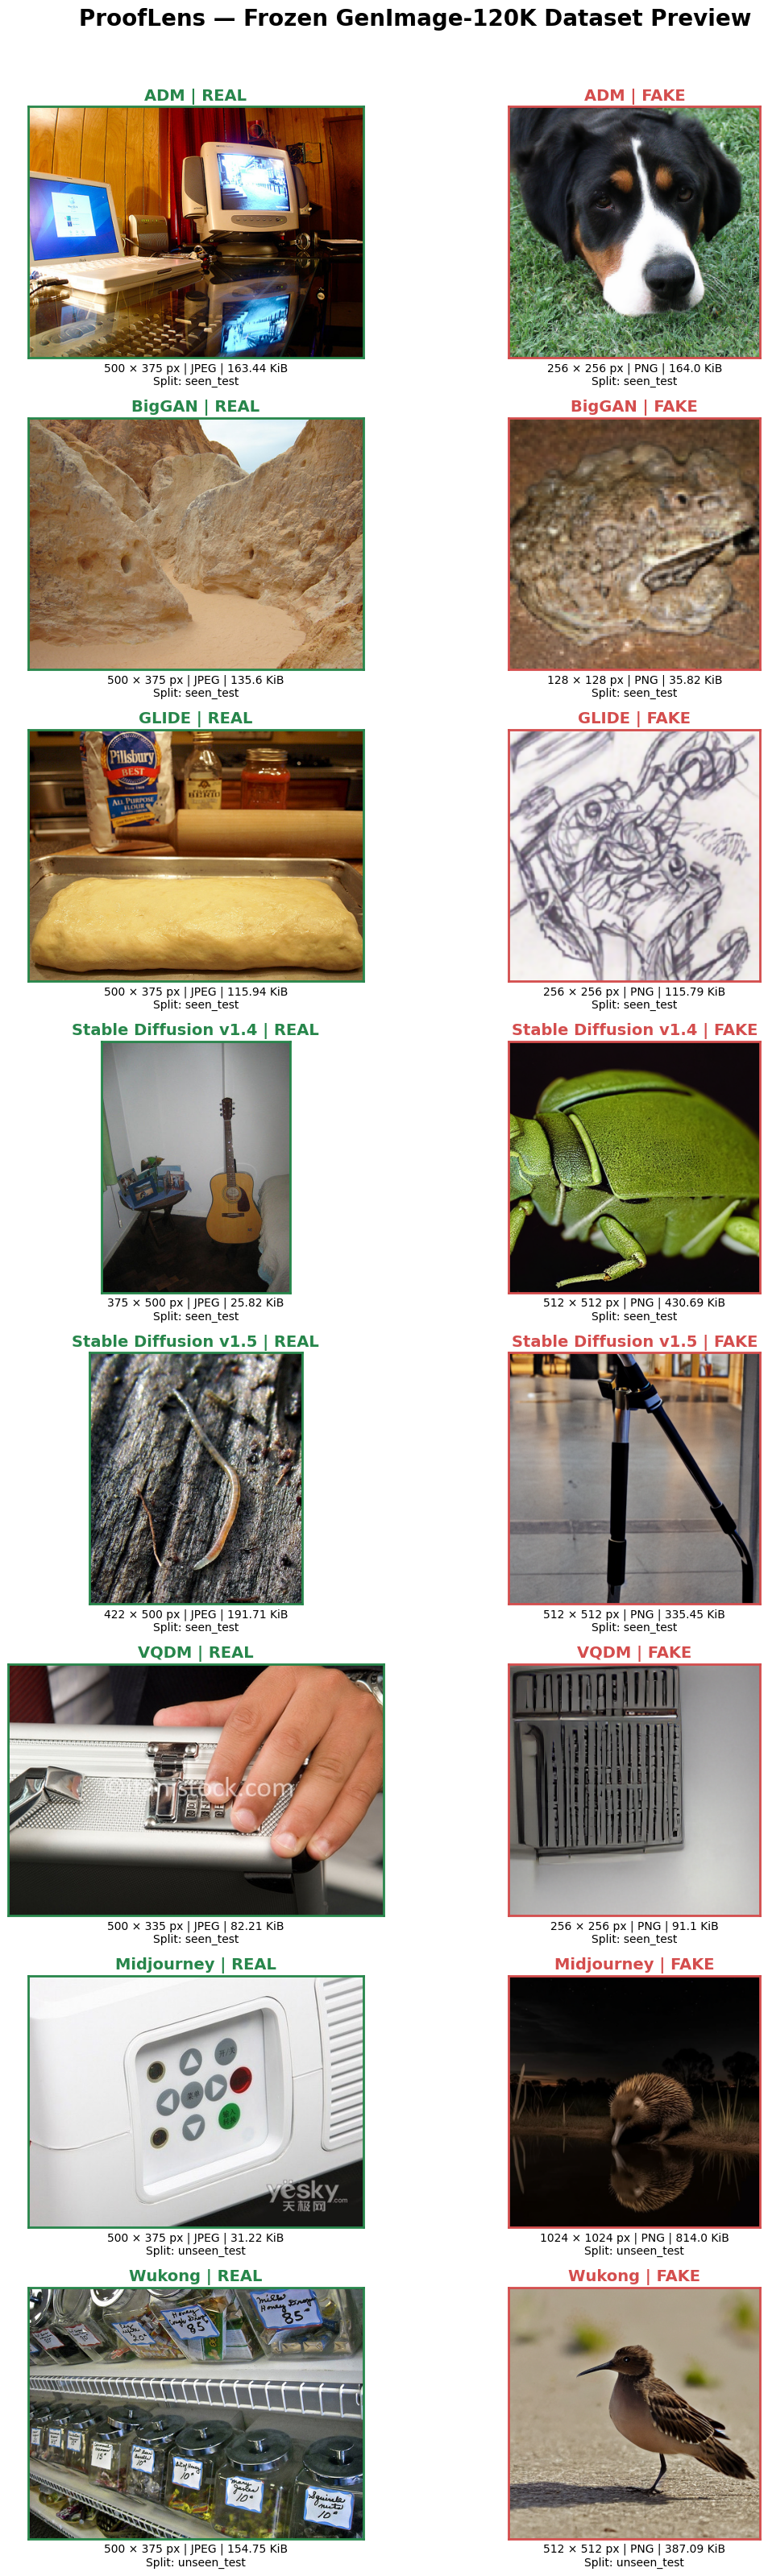


Preview image metadata:


,image_id,generator,label,release_split,format,width,height,size_kib,sha256_verified
0,pl_94bc90260bd9c56cb3f6,adm,REAL,seen_test,JPEG,500,375,163.44,True
1,pl_b8d32757ee8f88bfa3a4,adm,FAKE,seen_test,PNG,256,256,164.00,True
2,pl_752ce82e473fadc7a515,biggan,REAL,seen_test,JPEG,500,375,135.60,True
3,pl_b8cbbb1cb1244e6d6bfa,biggan,FAKE,seen_test,PNG,128,128,35.82,True
4,pl_ea4333f4ffa0286e641c,midjourney,REAL,unseen_test,JPEG,500,375,31.22,True
5,pl_f69ce66537b8192736fd,midjourney,FAKE,unseen_test,PNG,1024,1024,814.00,True
6,pl_ba35f04d35e14fcb6e0c,vqdm,REAL,seen_test,JPEG,500,335,82.21,True
7,pl_bc5810abfbe7ab18624c,vqdm,FAKE,seen_test,PNG,256,256,91.10,True
8,pl_bd2aaec69edda72bb323,glide,REAL,seen_test,JPEG,500,375,115.94,True
9,pl_b6e98ae63afd36329ddd,glide,FAKE,seen_test,PNG,256,256,115.79,True



PROOFLENS — DATASET IMAGE PREVIEW
Preview images       : 16
Generator groups     : 8
REAL images          : 8
FAKE images          : 8
SHA-256 verification : PASS
Frozen plan modified : NO
Original bytes edited: NO
Dataset published    : NO


In [ ]:

# ============================================================
# CELL 4.3.1 — FROZEN DATASET IMAGE PREVIEW
# ProofLens / Cifaker
# ============================================================

import io
import hashlib
import tempfile
import numpy as np
import pandas as pd
import pyarrow as pa
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from huggingface_hub import (
    hf_hub_download,
    try_to_load_from_cache,
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

PREVIEW_SEED = 42

PREVIEW_GENERATORS = {
    "adm": "ADM",
    "biggan": "BigGAN",
    "glide": "GLIDE",
    "sdv4": "Stable Diffusion v1.4",
    "sdv5": "Stable Diffusion v1.5",
    "vqdm": "VQDM",
    "midjourney": "Midjourney",
    "wukong": "Wukong",
}

if "selection_43" not in globals():
    raise RuntimeError("Run Cell 4.3 first.")

# ------------------------------------------------------------
# 2. Select representative preview records
# ------------------------------------------------------------

preview_records = []

for generator in PREVIEW_GENERATORS:

    subset = selection_43.loc[
        selection_43["source_generator_group"].eq(
            generator
        )
        & selection_43["release_split"].isin([
            "seen_test",
            "unseen_test",
        ])
    ]

    # Prefer a shared shard containing both labels
    # to reduce source download requirements.
    shared_shards = (
        subset.groupby("source_shard")["label"]
        .nunique()
    )

    shared_shards = shared_shards[
        shared_shards.eq(2)
    ].index.tolist()

    if shared_shards:

        chosen_shard = sorted(shared_shards)[0]

        subset = subset.loc[
            subset["source_shard"].eq(chosen_shard)
        ]

    for label in (0, 1):

        label_subset = subset.loc[
            subset["label"].eq(label)
        ]

        if label_subset.empty:
            raise RuntimeError(
                f"Missing preview candidates: "
                f"{generator}, label={label}"
            )

        sample = (
            label_subset
            .sort_values("image_id")
            .sample(
                n=1,
                random_state=PREVIEW_SEED,
            )
        )

        preview_records.append(sample)

preview_df = pd.concat(
    preview_records,
    ignore_index=True,
)

print(f"Selected preview images: {len(preview_df)}")
print(
    f"Required source shards: "
    f"{preview_df['source_shard'].nunique()}"
)

# ------------------------------------------------------------
# 3. Retrieve original image bytes by shard
# ------------------------------------------------------------

preview_images = {}
preview_metadata = []

for shard_name, records in preview_df.groupby(
    "source_shard"
):

    print(f"\nReading: {shard_name}")

    cached_path = try_to_load_from_cache(
        repo_id=HF_DATASET_ID,
        filename=shard_name,
        revision=HF_REVISION,
        repo_type="dataset",
        cache_dir=str(HF_CACHE_DIR),
    )

    cache_hit = (
        isinstance(cached_path, str)
        and Path(cached_path).is_file()
    )

    with tempfile.TemporaryDirectory(
        dir=str(WORK_DIR)
    ) as temp_dir:

        if cache_hit:

            arrow_path = cached_path

        else:

            arrow_path = hf_hub_download(
                repo_id=HF_DATASET_ID,
                repo_type="dataset",
                filename=shard_name,
                revision=HF_REVISION,
                local_dir=temp_dir,
            )

        # Map frozen row indices to selected records.
        wanted = {
            int(record["source_row_index"]): record
            for _, record in records.iterrows()
        }

        found = set()
        row_offset = 0

        # Support Arrow IPC stream and file formats.
        with pa.memory_map(
            str(arrow_path), "r"
        ) as source:

            try:

                reader = pa.ipc.open_stream(source)
                batches = iter(reader)

            except pa.ArrowInvalid:

                source.seek(0)

                reader = pa.ipc.open_file(source)

                batches = (
                    reader.get_batch(i)
                    for i in range(
                        reader.num_record_batches
                    )
                )

            for batch in batches:

                batch_end = (
                    row_offset + batch.num_rows
                )

                matching_rows = [
                    index
                    for index in wanted
                    if row_offset <= index < batch_end
                ]

                image_column = batch.column(
                    batch.schema.get_field_index("image")
                )

                label_column = batch.column(
                    batch.schema.get_field_index("label")
                )

                for row_index in matching_rows:

                    record = wanted[row_index]

                    local_index = row_index - row_offset

                    raw_bytes = image_column[
                        local_index
                    ].as_py()

                    actual_label = int(
                        label_column[
                            local_index
                        ].as_py()
                    )

                    # Verify frozen label and image hash.
                    assert actual_label == int(
                        record["label"]
                    )

                    actual_sha256 = hashlib.sha256(
                        raw_bytes
                    ).hexdigest()

                    assert actual_sha256 == record["sha256"], (
                        f"SHA-256 mismatch: "
                        f"{record['image_id']}"
                    )

                    with Image.open(
                        io.BytesIO(raw_bytes)
                    ) as image:

                        original_format = image.format
                        width, height = image.size

                        # Convert only the display copy.
                        display_image = image.convert("RGB")

                        display_image.thumbnail(
                            (512, 512)
                        )

                        preview_images[
                            record["image_id"]
                        ] = np.array(display_image)

                    preview_metadata.append({
                        "image_id": record["image_id"],
                        "generator": record[
                            "source_generator_group"
                        ],
                        "label": (
                            "REAL"
                            if actual_label == 0
                            else "FAKE"
                        ),
                        "release_split": record[
                            "release_split"
                        ],
                        "format": original_format,
                        "width": width,
                        "height": height,
                        "size_kib": round(
                            len(raw_bytes) / 1024,
                            2,
                        ),
                        "sha256_verified": True,
                    })

                    found.add(row_index)

                row_offset = batch_end

                if found == set(wanted):
                    break

        assert found == set(wanted), (
            f"Missing frozen rows in {shard_name}"
        )

    print(
        f"Retrieved and verified: "
        f"{len(found)} images"
    )

# ------------------------------------------------------------
# 4. Visualize REAL vs FAKE for every generator
# ------------------------------------------------------------

metadata_df = pd.DataFrame(
    preview_metadata
).set_index("image_id")

fig, axes = plt.subplots(
    nrows=len(PREVIEW_GENERATORS),
    ncols=2,
    figsize=(12, 4 * len(PREVIEW_GENERATORS)),
    squeeze=False,
)

fig.suptitle(
    "ProofLens — Frozen GenImage-120K Dataset Preview",
    fontsize=20,
    fontweight="bold",
    y=0.998,
)

for row, (generator, name) in enumerate(
    PREVIEW_GENERATORS.items()
):

    for col, label in enumerate((0, 1)):

        ax = axes[row, col]

        record = preview_df.loc[
            preview_df[
                "source_generator_group"
            ].eq(generator)
            & preview_df["label"].eq(label)
        ].iloc[0]

        image_id = record["image_id"]
        metadata = metadata_df.loc[image_id]

        ax.imshow(preview_images[image_id])

        label_name = "REAL" if label == 0 else "FAKE"

        title_color = (
            "#27864B"
            if label == 0
            else "#D44D4D"
        )

        ax.set_title(
            f"{name} | {label_name}",
            fontsize=14,
            fontweight="bold",
            color=title_color,
        )

        ax.set_xlabel(
            f"{metadata['width']} × "
            f"{metadata['height']} px | "
            f"{metadata['format']} | "
            f"{metadata['size_kib']} KiB\n"
            f"Split: {metadata['release_split']}",
            fontsize=10,
        )

        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():

            spine.set_color(title_color)
            spine.set_linewidth(2)

plt.tight_layout(
    rect=[0, 0, 1, 0.985]
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. Display image metadata and integrity summary
# ------------------------------------------------------------

print("\nPreview image metadata:")

display(
    metadata_df.reset_index()
)

assert len(preview_images) == len(preview_df)
assert metadata_df["sha256_verified"].all()

print("\n" + "=" * 60)
print("PROOFLENS — DATASET IMAGE PREVIEW")
print("=" * 60)

print(f"Preview images       : {len(preview_images)}")
print(f"Generator groups     : {len(PREVIEW_GENERATORS)}")
print(f"REAL images          : {preview_df['label'].eq(0).sum()}")
print(f"FAKE images          : {preview_df['label'].eq(1).sum()}")
print("SHA-256 verification : PASS")
print("Frozen plan modified : NO")
print("Original bytes edited: NO")
print("Dataset published    : NO")

print("=" * 60)


In [ ]:

# ============================================================
# CELL 5.0 — PRODUCTION REPOSITORY SYNCHRONIZATION
# ProofLens / Cifaker
# ============================================================

import os
import sys
import subprocess

from pathlib import Path

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

REPO_URL = "https://github.com/sangoonthego/cifaker.git"

REPO_DIR = Path("/content/cifaker")

PRODUCTION_COMMIT = (
    "cc8d889a51dffc419a901bb7170a38a09d58b900"
)

SAMPLING_COMMIT = (
    "d76c8fd6105bfef029bcb2b8dbead255bf03ff5c"
)

WORK_DIR = Path("/content/cifaker_work")

WORK_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


def run_production_command(
    command,
    capture=False,
):

    result = subprocess.run(
        [str(arg) for arg in command],
        cwd=str(REPO_DIR),
        check=True,
        text=True,
        capture_output=capture,
    )

    return result.stdout.strip() if capture else result


# ------------------------------------------------------------
# 2. Inspect current repository
# ------------------------------------------------------------

print("[1/5] Inspecting repository...")

if not (REPO_DIR / ".git").is_dir():

    subprocess.run(
        [
            "git",
            "clone",
            REPO_URL,
            str(REPO_DIR),
        ],
        check=True,
    )

previous_commit_50 = run_production_command(
    ["git", "rev-parse", "HEAD"],
    capture=True,
)

tracked_changes = run_production_command(
    [
        "git",
        "status",
        "--porcelain",
        "--untracked-files=no",
    ],
    capture=True,
)

if tracked_changes:

    print(tracked_changes)

    raise RuntimeError(
        "Tracked local changes detected. "
        "Resolve them before synchronizing."
    )

print(f"Previous HEAD: {previous_commit_50}")

# ------------------------------------------------------------
# 3. Fetch and checkout immutable production commit
# ------------------------------------------------------------

print("\n[2/5] Synchronizing production code...")

run_production_command([
    "git",
    "fetch",
    "origin",
    "--prune",
])

# Ensure the selected commit belongs to remote main.
run_production_command([
    "git",
    "merge-base",
    "--is-ancestor",
    PRODUCTION_COMMIT,
    "origin/main",
])

run_production_command([
    "git",
    "checkout",
    "--detach",
    PRODUCTION_COMMIT,
])

PRODUCTION_HEAD = run_production_command(
    ["git", "rev-parse", "HEAD"],
    capture=True,
)

assert PRODUCTION_HEAD == PRODUCTION_COMMIT

print(f"Production HEAD: {PRODUCTION_HEAD}")

# ------------------------------------------------------------
# 4. Install updated package and dependencies
# ------------------------------------------------------------

print("\n[3/5] Installing production dependencies...")

run_production_command([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",
    "-e",
    ".[gdrive,hf]",
])

# ------------------------------------------------------------
# 5. Verify required production components
# ------------------------------------------------------------

print("\n[4/5] Checking production components...")

required_files_50 = [
    "src/prooflens/data/sources/genimage_arrow.py",
    "src/prooflens/data/releases/frozen_plan.py",
    "src/prooflens/data/releases/preflight.py",
    "configs/sources/genimage_arrow_hf.yaml",
    "configs/releases/genimage_120k_v1_arrow.yaml",
]

for relative_path in required_files_50:

    path = REPO_DIR / relative_path

    if not path.is_file():

        raise FileNotFoundError(path)

    print(f"Found: {relative_path}")

# Run imports in a fresh Python process.
run_production_command([
    sys.executable,
    "-c",
    """
import prooflens
import pyarrow
import huggingface_hub

from prooflens.data.sources.genimage_arrow import (
    GenImageArrowAdapter,
)

from prooflens.data.releases.frozen_plan import (
    load_and_validate_frozen_snapshot,
)

from prooflens.data.releases.preflight import (
    run_capacity_preflight,
)

print("Package path:", prooflens.__file__)
print("PyArrow version:", pyarrow.__version__)
print("HF Hub version:", huggingface_hub.__version__)
print("Production component imports: PASS")
""",
])

# ------------------------------------------------------------
# 6. Validate production CLI
# ------------------------------------------------------------

print("\n[5/5] Validating CLI commands...")

required_commands_50 = [
    "validate-frozen",
    "preflight",
    "pilot",
    "build",
    "verify",
    "publish",
]

for command in required_commands_50:

    run_production_command(
        [
            sys.executable,
            "-m",
            "prooflens.data.cli",
            command,
            "--help",
        ],
        capture=True,
    )

    print(f"CLI {command}: PASS")

PRODUCTION_RELEASE_CONFIG = (
    REPO_DIR
    / "configs"
    / "releases"
    / "genimage_120k_v1_arrow.yaml"
)

# ------------------------------------------------------------
# 7. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("PROOFLENS — PRODUCTION CODE SYNCHRONIZATION")
print("=" * 68)

print(f"Previous commit      : {previous_commit_50[:12]}")
print(f"Sampling commit      : {SAMPLING_COMMIT[:12]}")
print(f"Production commit    : {PRODUCTION_HEAD[:12]}")
print(f"Python version       : {sys.version.split()[0]}")
print("Dependency install   : PASS")
print("Production imports   : PASS")
print("CLI validation       : PASS")
print("Notebook restarted   : NO")
print("Frozen plan modified : NO")
print("Source image download: NO")
print("Dataset published    : NO")

print("=" * 68)

print(
    "\nCELL 5.0 COMPLETE — "
    "Production repository synchronized."
)


[1/5] Inspecting repository...
Previous HEAD: d76c8fd6105bfef029bcb2b8dbead255bf03ff5c

[2/5] Synchronizing production code...
Production HEAD: cc8d889a51dffc419a901bb7170a38a09d58b900

[3/5] Installing production dependencies...

[4/5] Checking production components...
Found: src/prooflens/data/sources/genimage_arrow.py
Found: src/prooflens/data/releases/frozen_plan.py
Found: src/prooflens/data/releases/preflight.py
Found: configs/sources/genimage_arrow_hf.yaml
Found: configs/releases/genimage_120k_v1_arrow.yaml

[5/5] Validating CLI commands...
CLI validate-frozen: PASS
CLI preflight: PASS
CLI pilot: PASS
CLI build: PASS
CLI verify: PASS
CLI publish: PASS

PROOFLENS — PRODUCTION CODE SYNCHRONIZATION
Previous commit      : d76c8fd6105b
Sampling commit      : d76c8fd6105b
Production commit    : cc8d889a51df
Python version       : 3.13.16
Dependency install   : PASS
Production imports   : PASS
CLI validation       : PASS
Notebook restarted   : NO
Frozen plan modified : NO
Source image d

In [ ]:

# ============================================================
# CELL 5.1 — FROZEN SNAPSHOT COMPATIBILITY VALIDATION
# ProofLens / Cifaker
# ============================================================

import os
import sys
import json
import yaml
import hashlib
import subprocess

from pathlib import Path
from datetime import datetime, timezone
from google.colab import auth, userdata

# ------------------------------------------------------------
# 1. Authenticate cloud services
# ------------------------------------------------------------

print("[1/5] Authenticating cloud services...")

auth.authenticate_user()

try:

    hf_token = userdata.get("HF_TOKEN")

    if hf_token:

        os.environ["HF_TOKEN"] = hf_token

        print("Hugging Face authentication: CONFIGURED")

except Exception:

    print("Hugging Face authentication: DEFAULT")

# ------------------------------------------------------------
# 2. Define authoritative frozen snapshot
# ------------------------------------------------------------

EXPECTED_PLAN_ID = "plan_5f4143bb761cac8c"

EXPECTED_RECORDS = 120000

EXPECTED_SOURCE_ID = "genimage_arrow_sharded"

EXPECTED_SOURCE_REVISION = (
    "3f4b9f921a673be09a93b335ed728cea0c6ecf33"
)

EXPECTED_SNAPSHOT_PREFIX = (
    "pipeline_metadata/sampling_freeze/"
    "3f4b9f921a673be09a93b335ed728cea0c6ecf33/"
    "20261124_131504_857392"
)

assert PRODUCTION_HEAD == PRODUCTION_COMMIT

print(f"Expected plan ID: {EXPECTED_PLAN_ID}")
print(f"Expected records: {EXPECTED_RECORDS:,}")

# ------------------------------------------------------------
# 3. Resolve production runtime configuration
# ------------------------------------------------------------

print("\n[2/5] Resolving production configuration...")

release_raw_51 = yaml.safe_load(
    PRODUCTION_RELEASE_CONFIG.read_text(
        encoding="utf-8"
    )
)

assert release_raw_51["frozen_snapshot_prefix"] == (
    EXPECTED_SNAPSHOT_PREFIX
)

assert release_raw_51["strict_frozen_mode"] is True

assert release_raw_51["release_id"] == (
    "genimage-120k-v1"
)

assert release_raw_51["sampling_seed"] == 20260401

# Resolve referenced YAML paths before saving the
# runtime configuration outside the repository.
for field in [
    "source_config",
    "protocol_config",
    "storage_config",
]:

    release_raw_51[field] = str(
        (
            PRODUCTION_RELEASE_CONFIG.parent
            / release_raw_51[field]
        ).resolve()
    )

source_raw_51 = yaml.safe_load(
    Path(
        release_raw_51["source_config"]
    ).read_text(encoding="utf-8")
)["source"]

assert source_raw_51["source_id"] == EXPECTED_SOURCE_ID

assert source_raw_51["source_revision"] == (
    EXPECTED_SOURCE_REVISION
)

assert source_raw_51["source_type"] == (
    "huggingface_arrow"
)

# Preserve the leakage policy used during Cell 4.1–4.3.
protocol_raw_51 = yaml.safe_load(
    Path(
        release_raw_51["protocol_config"]
    ).read_text(encoding="utf-8")
)["protocol"]

original_policy_51 = protocol_raw_51[
    "cross_source_split_leakage_policy"
]

protocol_raw_51[
    "cross_source_split_leakage_policy"
] = "exclude_cross_split_groups"

release_raw_51.pop("protocol_config")

release_raw_51["protocol"] = protocol_raw_51

release_raw_51["working_dir"] = str(
    WORK_DIR / "production_materialization"
)

RUNTIME_RELEASE_CONFIG = (
    WORK_DIR
    / "genimage_120k_v1_arrow_runtime.yaml"
)

RUNTIME_RELEASE_CONFIG.write_text(
    yaml.safe_dump(
        release_raw_51,
        sort_keys=False,
    ),
    encoding="utf-8",
)

print(f"Runtime config: {RUNTIME_RELEASE_CONFIG}")

print(
    f"Leakage policy: "
    f"{original_policy_51} -> "
    "exclude_cross_split_groups"
)

# ------------------------------------------------------------
# 4. Validate actual frozen snapshot from Drive
# ------------------------------------------------------------

print("\n[3/5] Validating frozen snapshot from Drive...")

validation_command_51 = [
    sys.executable,
    "-m",
    "prooflens.data.cli",
    "validate-frozen",
    "--config",
    str(RUNTIME_RELEASE_CONFIG),
    "--expected-records",
    str(EXPECTED_RECORDS),
    "--expected-source-id",
    EXPECTED_SOURCE_ID,
    "--expected-source-revision",
    EXPECTED_SOURCE_REVISION,
    "--expected-plan-id",
    EXPECTED_PLAN_ID,
]

validation_result_51 = subprocess.run(
    validation_command_51,
    cwd=str(REPO_DIR),
    capture_output=True,
    text=True,
    check=False,
)

print(validation_result_51.stdout)

if validation_result_51.stderr:

    print(validation_result_51.stderr)

# ------------------------------------------------------------
# 5. Preserve stage-specific validation evidence
# ------------------------------------------------------------

print("\n[4/5] Saving validation evidence...")

timestamp_51 = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S_%f")

VALIDATION_DIR_51 = (
    WORK_DIR
    / "frozen_validation"
    / timestamp_51
)

VALIDATION_DIR_51.mkdir(
    parents=True,
    exist_ok=True,
)

stdout_path = (
    VALIDATION_DIR_51 / "validation_stdout.log"
)

stderr_path = (
    VALIDATION_DIR_51 / "validation_stderr.log"
)

stdout_path.write_text(
    validation_result_51.stdout,
    encoding="utf-8",
)

stderr_path.write_text(
    validation_result_51.stderr,
    encoding="utf-8",
)

snapshot_report_51 = {
    "stage": "5.1",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "production_commit": PRODUCTION_HEAD,
    "sampling_commit": SAMPLING_COMMIT,
    "expected_plan_id": EXPECTED_PLAN_ID,
    "expected_records": EXPECTED_RECORDS,
    "expected_source_id": EXPECTED_SOURCE_ID,
    "source_revision": EXPECTED_SOURCE_REVISION,
    "snapshot_prefix": EXPECTED_SNAPSHOT_PREFIX,
    "runtime_config_sha256": hashlib.sha256(
        RUNTIME_RELEASE_CONFIG.read_bytes()
    ).hexdigest(),
    "return_code": validation_result_51.returncode,
    "status": (
        "PASS"
        if validation_result_51.returncode == 0
        else "FAIL"
    ),
    "dataset_materialized": False,
    "dataset_published": False,
}

report_path_51 = (
    VALIDATION_DIR_51
    / "frozen_validation_report.json"
)

report_path_51.write_text(
    json.dumps(
        snapshot_report_51,
        indent=2,
    ),
    encoding="utf-8",
)

# ------------------------------------------------------------
# 6. Final validation gate
# ------------------------------------------------------------

print("\n[5/5] Checking validation gate...")

FROZEN_COMPATIBILITY_PASSED = (
    validation_result_51.returncode == 0
)

print("\n" + "=" * 68)
print("PROOFLENS — FROZEN SNAPSHOT VALIDATION")
print("=" * 68)

print(f"Production commit     : {PRODUCTION_HEAD[:12]}")
print(f"Frozen plan ID        : {EXPECTED_PLAN_ID}")
print(f"Expected records      : {EXPECTED_RECORDS:,}")
print(f"Source revision       : {EXPECTED_SOURCE_REVISION[:12]}")
print(f"CLI return code       : {validation_result_51.returncode}")

print(
    "Snapshot compatibility: "
    + (
        "PASS"
        if FROZEN_COMPATIBILITY_PASSED
        else "FAIL"
    )
)

print("Implicit re-sampling  : NO")
print("Frozen plan modified  : NO")
print("Source image downloads: NO")
print("Dataset materialized  : NO")
print("Dataset published     : NO")
print(f"Validation artifacts  : {VALIDATION_DIR_51}")

print("=" * 68)

if not FROZEN_COMPATIBILITY_PASSED:

    raise RuntimeError(
        "Frozen snapshot validation failed. "
        "Inspect the CLI output before proceeding."
    )

print(
    "\nCELL 5.1 COMPLETE — "
    "Ready for Cell 5.2 capacity preflight."
)


[1/5] Authenticating cloud services...
Hugging Face authentication: DEFAULT
Expected plan ID: plan_5f4143bb761cac8c
Expected records: 120,000

[2/5] Resolving production configuration...
Runtime config: /content/cifaker_work/genimage_120k_v1_arrow_runtime.yaml
Leakage policy: fail -> exclude_cross_split_groups

[3/5] Validating frozen snapshot from Drive...
{
  "snapshot_location": "pipeline_metadata/sampling_freeze/3f4b9f921a673be09a93b335ed728cea0c6ecf33/20261124_131504_857392",
  "sampling_provenance": {
    "sampling_plan_id": "plan_5f4143bb761cac8c",
    "sampling_config_hash": "61b34675b97e92e84d63762d2fd1c25375617d1bd0ae6dfb5d66d65538a7c737",
    "sampling_code_commit": null,
    "release_id": "genimage-120k-v1",
    "source_id": "genimage_arrow_sharded",
    "source_revision": "3f4b9f921a673be09a93b335ed728cea0c6ecf33",
    "protocol_version": "cross_generator_v1",
    "sampling_seed": 20260401,
    "snapshot_location": "pipeline_metadata/sampling_freeze/3f4b9f921a673be09a93b33

[1/5] Validating preflight prerequisites...
Production commit: cc8d889a51df
Frozen plan ID: plan_5f4143bb761cac8c
Safety margin: 15%

[2/5] Checking storage capacity...
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.


[3/5] Analyzing storage requirements...


,component,size_bytes,size_gib
0,Original image bytes,"26,104,961,586",24.3121
1,TAR overhead,"122,880,000",0.1144
2,Metadata overhead,"313,478,415",0.2919
3,Remote retry overhead,"1,610,612,736",1.5000
4,Safety margin,"4,222,789,910",3.9328


,storage,required_gib,available_gib,headroom_gib,status
0,Google Colab,4.36,234.18,229.82,PASS
1,Google Drive,30.15,5031.14,5000.99,PASS



[4/5] Visualizing storage requirements...


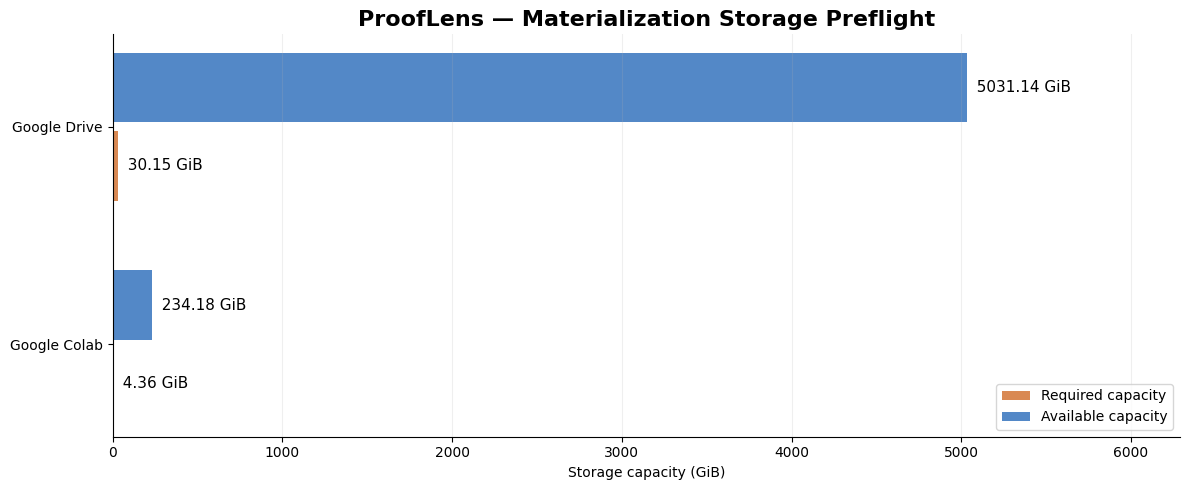

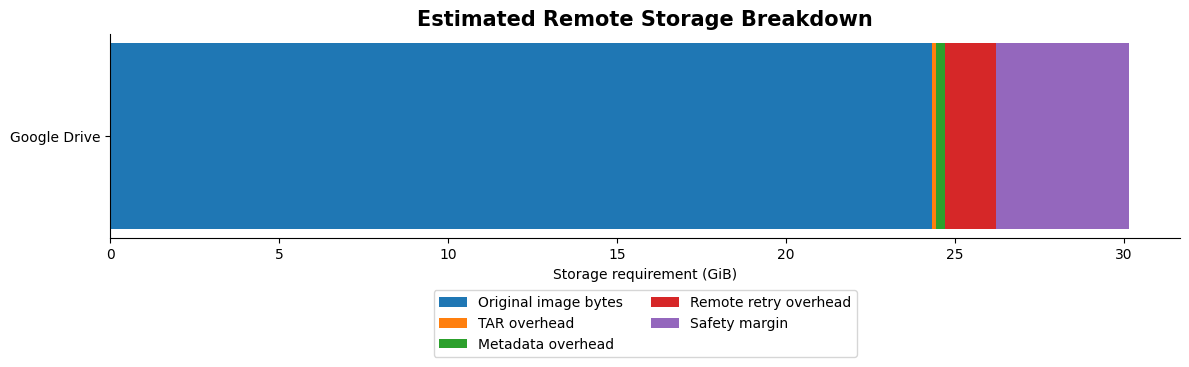


[5/5] Saving preflight evidence...

PROOFLENS — STORAGE CAPACITY PREFLIGHT
Selected images       : 120,000
Selected source shards: 76
Original image bytes  : 24.31 GiB

LOCAL RUNTIME STORAGE
Required capacity     : 4.36 GiB
Available capacity    : 234.18 GiB
Remaining headroom    : 229.82 GiB
Local status          : PASS

REMOTE GOOGLE DRIVE STORAGE
Required capacity     : 30.15 GiB
Available capacity    : 5031.14 GiB
Remaining headroom    : 5000.99 GiB
Remote status         : PASS

FINAL VALIDATION
Safety margin         : 15%
Overall status        : PASS
CLI return code       : 0
Source image downloads: NO
Dataset materialized  : NO
Dataset published     : NO
Validation artifacts  : /content/cifaker_work/storage_preflight/20261124_135554_392900

CELL 5.2 COMPLETE — Capacity preflight passed. Ready for Cell 5.3 pilot.


In [ ]:

# ============================================================
# CELL 5.2 — STORAGE CAPACITY PREFLIGHT
# ProofLens / Cifaker Production Data Pipeline
# ============================================================

import sys
import json
import hashlib
import subprocess
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. Validate prerequisites
# ------------------------------------------------------------

print("[1/5] Validating preflight prerequisites...")

if not globals().get("FROZEN_COMPATIBILITY_PASSED", False):
    raise RuntimeError("Cell 5.1 must pass before preflight.")

assert RUNTIME_RELEASE_CONFIG.is_file()

current_head = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=str(REPO_DIR),
    text=True,
).strip()

assert current_head == PRODUCTION_COMMIT

runtime_config_sha256 = hashlib.sha256(
    RUNTIME_RELEASE_CONFIG.read_bytes()
).hexdigest()

assert runtime_config_sha256 == (
    snapshot_report_51["runtime_config_sha256"]
), "Runtime configuration changed after Cell 5.1."

SAFETY_MARGIN_52 = 0.15
GIB = 1024**3

print(f"Production commit: {current_head[:12]}")
print(f"Frozen plan ID: {EXPECTED_PLAN_ID}")
print(f"Safety margin: {SAFETY_MARGIN_52:.0%}")

# ------------------------------------------------------------
# 2. Run production capacity preflight
# ------------------------------------------------------------

print("\n[2/5] Checking storage capacity...")

preflight_command_52 = [
    sys.executable,
    "-m",
    "prooflens.data.cli",
    "preflight",
    "--config",
    str(RUNTIME_RELEASE_CONFIG),
    "--expected-records",
    str(EXPECTED_RECORDS),
    "--safety-margin",
    str(SAFETY_MARGIN_52),
]

preflight_result_52 = subprocess.run(
    preflight_command_52,
    cwd=str(REPO_DIR),
    capture_output=True,
    text=True,
    check=False,
)

timestamp_52 = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%f"
)

PREFLIGHT_DIR_52 = (
    WORK_DIR
    / "storage_preflight"
    / timestamp_52
)

PREFLIGHT_DIR_52.mkdir(
    parents=True,
    exist_ok=True,
)

(PREFLIGHT_DIR_52 / "preflight_stdout.log").write_text(
    preflight_result_52.stdout,
    encoding="utf-8",
)

(PREFLIGHT_DIR_52 / "preflight_stderr.log").write_text(
    preflight_result_52.stderr,
    encoding="utf-8",
)

if preflight_result_52.stderr:
    print(preflight_result_52.stderr)

# Parse the structured CLI report.
try:
    capacity_report_52 = json.loads(
        preflight_result_52.stdout
    )
except json.JSONDecodeError as exc:
    raise RuntimeError(
        f"Unable to parse capacity report. "
        f"CLI exit code: {preflight_result_52.returncode}. "
        f"Logs: {PREFLIGHT_DIR_52}"
    ) from exc

assert capacity_report_52["selected_image_count"] == 120000
assert capacity_report_52["unique_source_shards"] == 76

# ------------------------------------------------------------
# 3. Analyze capacity requirements
# ------------------------------------------------------------

print("\n[3/5] Analyzing storage requirements...")

def to_gib(value):
    return value / GIB if value is not None else None


raw_image_bytes = capacity_report_52[
    "estimated_original_image_bytes"
]

remote_required_bytes = capacity_report_52[
    "remote_required_bytes_with_margin"
]

local_required_bytes = capacity_report_52[
    "local_required_bytes_with_margin"
]

remote_capacity = capacity_report_52["remote_capacity"]
local_capacity = capacity_report_52["local_capacity"]

remote_free_bytes = remote_capacity.get("free_bytes")
local_free_bytes = local_capacity.get("free_bytes")

remote_status_52 = capacity_report_52["remote_status"]
local_status_52 = capacity_report_52["local_status"]
overall_status_52 = capacity_report_52["overall_status"]

remote_headroom = (
    remote_free_bytes - remote_required_bytes
    if remote_free_bytes is not None
    and remote_required_bytes is not None
    else None
)

local_headroom = (
    local_free_bytes - local_required_bytes
    if local_free_bytes is not None
    else None
)

# Calculate individual storage components.
remote_components = {
    "Original image bytes": raw_image_bytes,
    "TAR overhead": capacity_report_52[
        "tar_overhead_bytes"
    ],
    "Metadata overhead": capacity_report_52[
        "metadata_overhead_bytes"
    ],
    "Remote retry overhead": capacity_report_52[
        "remote_retry_overhead_bytes"
    ],
}

remote_base_bytes = sum(remote_components.values())

remote_components["Safety margin"] = (
    remote_required_bytes - remote_base_bytes
)

storage_breakdown_52 = pd.DataFrame([
    {
        "component": name,
        "size_bytes": value,
        "size_gib": to_gib(value),
    }
    for name, value in remote_components.items()
])

display(
    storage_breakdown_52.style.format({
        "size_bytes": "{:,.0f}",
        "size_gib": "{:.4f}",
    })
)

capacity_summary_52 = pd.DataFrame([
    {
        "storage": "Google Colab",
        "required_gib": to_gib(local_required_bytes),
        "available_gib": to_gib(local_free_bytes),
        "headroom_gib": to_gib(local_headroom),
        "status": local_status_52,
    },
    {
        "storage": "Google Drive",
        "required_gib": to_gib(remote_required_bytes),
        "available_gib": to_gib(remote_free_bytes),
        "headroom_gib": to_gib(remote_headroom),
        "status": remote_status_52,
    },
])

display(
    capacity_summary_52.style.format({
        "required_gib": "{:.2f}",
        "available_gib": "{:.2f}",
        "headroom_gib": "{:.2f}",
    }, na_rep="UNKNOWN")
)

# ------------------------------------------------------------
# 4. Visualize storage capacity
# ------------------------------------------------------------

print("\n[4/5] Visualizing storage requirements...")

fig, ax = plt.subplots(figsize=(12, 5))

storage_names = ["Google Colab", "Google Drive"]

required_values = [
    to_gib(local_required_bytes),
    to_gib(remote_required_bytes),
]

available_values = [
    to_gib(local_free_bytes),
    to_gib(remote_free_bytes),
]

positions = [0, 1]

required_bars = ax.barh(
    [x - 0.18 for x in positions],
    required_values,
    height=0.32,
    label="Required capacity",
    color="#D98953",
)

available_bars = ax.barh(
    [x + 0.18 for x in positions],
    [
        value if value is not None else 0
        for value in available_values
    ],
    height=0.32,
    label="Available capacity",
    color="#5388C7",
)

for bar in required_bars:
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"  {bar.get_width():.2f} GiB",
        va="center",
        fontsize=11,
    )

for bar, value in zip(
    available_bars,
    available_values,
):
    label = (
        f"{value:.2f} GiB"
        if value is not None
        else "UNKNOWN"
    )

    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"  {label}",
        va="center",
        fontsize=11,
    )

ax.set_yticks(positions)
ax.set_yticklabels(storage_names)
ax.set_xlabel("Storage capacity (GiB)")

ax.set_title(
    "ProofLens — Materialization Storage Preflight",
    fontsize=16,
    fontweight="bold",
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(axis="x", alpha=0.2)
ax.margins(x=0.25)
ax.legend()

plt.tight_layout()

capacity_plot_path = (
    PREFLIGHT_DIR_52 / "storage_capacity.png"
)

fig.savefig(
    capacity_plot_path,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# Visualize the estimated remote storage breakdown.
fig, ax = plt.subplots(figsize=(12, 4))

left = 0

for component, size_bytes in remote_components.items():

    size_gib = to_gib(size_bytes)

    ax.barh(
        ["Google Drive"],
        size_gib,
        left=left,
        label=component,
        height=0.45,
    )

    left += size_gib

ax.set_title(
    "Estimated Remote Storage Breakdown",
    fontsize=15,
    fontweight="bold",
)

ax.set_xlabel("Storage requirement (GiB)")

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=2,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

breakdown_plot_path = (
    PREFLIGHT_DIR_52 / "storage_breakdown.png"
)

fig.savefig(
    breakdown_plot_path,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. Persist preflight evidence
# ------------------------------------------------------------

print("\n[5/5] Saving preflight evidence...")

PREFLIGHT_REPORT_PATH = (
    PREFLIGHT_DIR_52 / "capacity_preflight_report.json"
)

PREFLIGHT_REPORT_PATH.write_text(
    json.dumps({
        "stage": "5.2",
        "created_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "production_commit": current_head,
        "sampling_plan_id": EXPECTED_PLAN_ID,
        "runtime_config_sha256": runtime_config_sha256,
        "cli_return_code": preflight_result_52.returncode,
        "capacity_report": capacity_report_52,
        "dataset_materialized": False,
        "dataset_published": False,
    }, indent=2),
    encoding="utf-8",
)

storage_breakdown_52.to_csv(
    PREFLIGHT_DIR_52 / "storage_breakdown.csv",
    index=False,
)

capacity_summary_52.to_csv(
    PREFLIGHT_DIR_52 / "capacity_summary.csv",
    index=False,
)

# ------------------------------------------------------------
# 6. Final capacity gate
# ------------------------------------------------------------

PREFLIGHT_PASSED = (
    preflight_result_52.returncode == 0
    and overall_status_52 == "PASS"
    and remote_status_52 == "PASS"
    and local_status_52 == "PASS"
)

def format_gib(value):
    return (
        f"{to_gib(value):.2f} GiB"
        if value is not None
        else "UNKNOWN"
    )

print("\n" + "=" * 68)
print("PROOFLENS — STORAGE CAPACITY PREFLIGHT")
print("=" * 68)

print(f"Selected images       : {EXPECTED_RECORDS:,}")
print(f"Selected source shards: 76")
print(f"Original image bytes  : {format_gib(raw_image_bytes)}")

print("\nLOCAL RUNTIME STORAGE")
print(f"Required capacity     : {format_gib(local_required_bytes)}")
print(f"Available capacity    : {format_gib(local_free_bytes)}")
print(f"Remaining headroom    : {format_gib(local_headroom)}")
print(f"Local status          : {local_status_52}")

print("\nREMOTE GOOGLE DRIVE STORAGE")
print(f"Required capacity     : {format_gib(remote_required_bytes)}")
print(f"Available capacity    : {format_gib(remote_free_bytes)}")
print(f"Remaining headroom    : {format_gib(remote_headroom)}")
print(f"Remote status         : {remote_status_52}")

print("\nFINAL VALIDATION")
print(f"Safety margin         : {SAFETY_MARGIN_52:.0%}")
print(f"Overall status        : {overall_status_52}")
print(f"CLI return code       : {preflight_result_52.returncode}")
print("Source image downloads: NO")
print("Dataset materialized  : NO")
print("Dataset published     : NO")
print(f"Validation artifacts  : {PREFLIGHT_DIR_52}")

if capacity_report_52.get("warnings"):

    print("\nWARNINGS:")

    for warning in capacity_report_52["warnings"]:
        print(f"- {warning}")

print("=" * 68)

if PREFLIGHT_PASSED:

    print(
        "\nCELL 5.2 COMPLETE — "
        "Capacity preflight passed. "
        "Ready for Cell 5.3 pilot."
    )

elif overall_status_52 == "REQUIRES_EXPLICIT_APPROVAL":

    print(
        "\nCELL 5.2 BLOCKED — "
        "Remote capacity could not be verified. "
        "Manual capacity verification is required."
    )

else:

    raise RuntimeError(
        "Storage capacity preflight failed. "
        "Do not begin full materialization."
    )


[1/6] Validating pilot prerequisites...
Production commit: cc8d889a51df
Frozen plan ID: plan_5f4143bb761cac8c
Pilot sample count: 40
Pilot seed: 42
Pilot storage: /content/cifaker_work/materialization_pilot/20261124_135735_084185/storage
Available local disk: 234.18 GiB

[2/6] Running real-source materialization pilot...
Pilot running | Elapsed: 10s | Free disk: 234.16 GiB
Pilot running | Elapsed: 20s | Free disk: 234.18 GiB
Pilot running | Elapsed: 30s | Free disk: 234.10 GiB
Pilot running | Elapsed: 40s | Free disk: 233.71 GiB
Pilot running | Elapsed: 50s | Free disk: 233.75 GiB
Pilot running | Elapsed: 60s | Free disk: 233.33 GiB
Pilot running | Elapsed: 70s | Free disk: 233.70 GiB
Pilot running | Elapsed: 80s | Free disk: 233.70 GiB
Pilot running | Elapsed: 90s | Free disk: 233.26 GiB
Pilot running | Elapsed: 100s | Free disk: 233.94 GiB
Pilot running | Elapsed: 110s | Free disk: 233.70 GiB
Pilot running | Elapsed: 120s | Free disk: 233.21 GiB
Pilot running | Elapsed: 130s | Free d

,REAL,FAKE,Total
release_split,,,
train,6,6,12
dev,6,6,12
seen_test,6,6,12
unseen_test,2,2,4


,REAL,FAKE
source_generator_group,,
adm,3,3
biggan,3,3
glide,3,3
midjourney,1,1
sdv4,3,3
sdv5,3,3
vqdm,3,3
wukong,1,1



[5/6] Analyzing materialization metrics...

Materializer metrics:


,metric,value
0,duration_seconds,146.3047
1,images_decoded_and_hashed,40
2,images_per_second,0.27
3,bytes_written_to_new_shards,8785920
4,megabytes_per_second,0.06
5,reused_parent_shards,0
6,resumed_existing_shards,0
7,newly_materialized_shards,4
8,excluded_count,0
9,strict_frozen_mode,True



Arrow adapter runtime statistics:
{
  "downloads": 40,
  "cache_hits": 0,
  "cache_misses": 40,
  "evictions": 40,
  "cached_shards_current": 0,
  "cached_bytes_current": 0,
  "peak_cache_bytes": 1021704696
}
Pilot elapsed time: 180.01s
Pilot source shards: 38
Pilot TAR storage: 8.38 MiB
Observed peak disk growth: 0.97 GiB


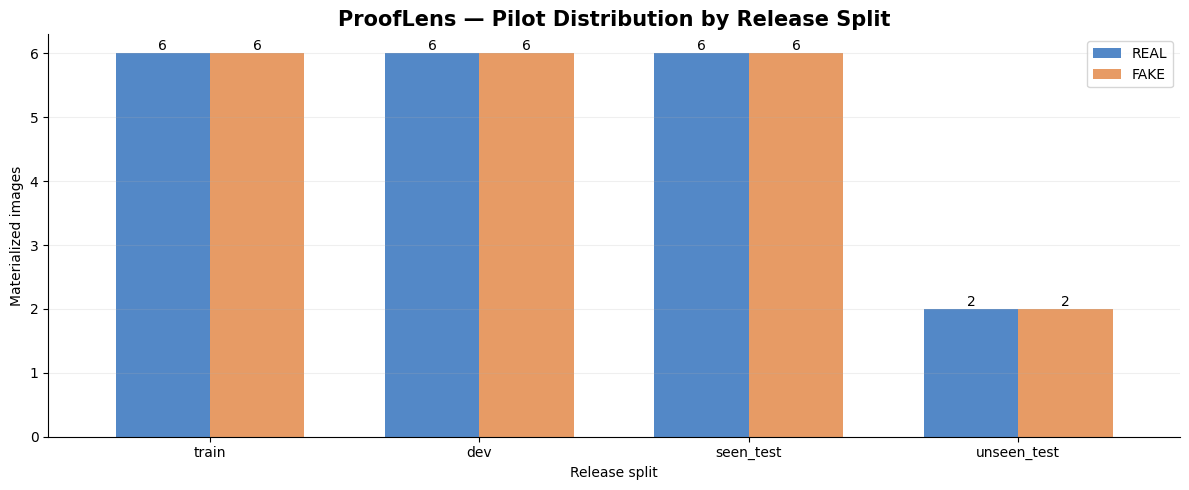


[6/6] Saving pilot validation evidence...

PROOFLENS — REAL-SOURCE MATERIALIZATION PILOT
Production commit      : cc8d889a51df
Original frozen plan   : plan_5f4143bb761cac8c
Requested pilot samples: 40
Materialized samples   : 40
Read-back verified     : 40
REAL / FAKE            : 20 / 20
Generator coverage     : 8/8
Release split coverage : 4/4
Source split coverage  : 2/2
Strata coverage        : 40/40
Source Arrow shards    : 38
Output TAR shards      : 4
TAR storage            : 8.38 MiB
Elapsed time           : 180.01s
Observed disk growth   : 0.97 GiB
Original byte integrity: PASS
TAR verification       : PASS
Dataset read-back      : PASS
Pilot isolation        : PASS
Frozen membership      : PASS
Pilot status           : PASS
Real Drive TAR upload  : NOT TESTED
Full near-dup audit    : NOT PERFORMED
Official dataset built : NO
Dataset published      : NO
Pilot artifacts        : /content/cifaker_work/materialization_pilot/20261124_135735_084185

CELL 5.3 COMPLETE — Real-sourc

In [ ]:

# ============================================================
# CELL 5.3 — REAL-SOURCE MATERIALIZATION PILOT
# ProofLens / Cifaker Production Data Pipeline
# ============================================================

import sys
import json
import time
import shutil
import hashlib
import subprocess
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. Validate prerequisites
# ------------------------------------------------------------

print("[1/6] Validating pilot prerequisites...")

PILOT_PASSED = False

if not globals().get("FROZEN_COMPATIBILITY_PASSED", False):
    raise RuntimeError("Cell 5.1 must pass first.")

if not globals().get("PREFLIGHT_PASSED", False):
    raise RuntimeError("Cell 5.2 must pass first.")

assert RUNTIME_RELEASE_CONFIG.is_file()

current_head_53 = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=str(REPO_DIR),
    text=True,
).strip()

assert current_head_53 == PRODUCTION_COMMIT

runtime_config_sha_53 = hashlib.sha256(
    RUNTIME_RELEASE_CONFIG.read_bytes()
).hexdigest()

assert runtime_config_sha_53 == (
    snapshot_report_51["runtime_config_sha256"]
), "Runtime configuration changed after validation."

PILOT_SAMPLE_COUNT = 40
PILOT_SEED = 42

GIB = 1024**3

timestamp_53 = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%f"
)

PILOT_DIR_53 = (
    WORK_DIR
    / "materialization_pilot"
    / timestamp_53
)

PILOT_STORAGE_DIR = PILOT_DIR_53 / "storage"
PILOT_WORK_DIR = PILOT_DIR_53 / "working"

for directory in [
    PILOT_DIR_53,
    PILOT_STORAGE_DIR,
    PILOT_WORK_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

disk_before_53 = shutil.disk_usage(
    "/content"
).free

print(f"Production commit: {current_head_53[:12]}")
print(f"Frozen plan ID: {EXPECTED_PLAN_ID}")
print(f"Pilot sample count: {PILOT_SAMPLE_COUNT}")
print(f"Pilot seed: {PILOT_SEED}")
print(f"Pilot storage: {PILOT_STORAGE_DIR}")
print(f"Available local disk: {disk_before_53 / GIB:.2f} GiB")

# ------------------------------------------------------------
# 2. Execute production pilot CLI
# ------------------------------------------------------------

print("\n[2/6] Running real-source materialization pilot...")

pilot_command_53 = [
    sys.executable,
    "-u",
    "-m",
    "prooflens.data.cli",
    "pilot",
    "--config",
    str(RUNTIME_RELEASE_CONFIG),
    "--sample-count",
    str(PILOT_SAMPLE_COUNT),
    "--pilot-seed",
    str(PILOT_SEED),
    "--pilot-storage-dir",
    str(PILOT_STORAGE_DIR),
    "--working-dir",
    str(PILOT_WORK_DIR),
]

stdout_path_53 = (
    PILOT_DIR_53 / "pilot_stdout.log"
)

stderr_path_53 = (
    PILOT_DIR_53 / "pilot_stderr.log"
)

started_53 = time.perf_counter()

# Use a fresh Python process to avoid stale modules
# imported before the production repository update.
with (
    stdout_path_53.open("w", encoding="utf-8") as out,
    stderr_path_53.open("w", encoding="utf-8") as err,
):

    pilot_process_53 = subprocess.Popen(
        pilot_command_53,
        cwd=str(REPO_DIR),
        stdout=out,
        stderr=err,
        text=True,
    )

    min_free_disk_53 = disk_before_53

    while pilot_process_53.poll() is None:

        time.sleep(10)

        current_free_disk = shutil.disk_usage(
            "/content"
        ).free

        min_free_disk_53 = min(
            min_free_disk_53,
            current_free_disk,
        )

        elapsed = (
            time.perf_counter() - started_53
        )

        print(
            f"Pilot running | "
            f"Elapsed: {elapsed:.0f}s | "
            f"Free disk: "
            f"{current_free_disk / GIB:.2f} GiB"
        )

pilot_return_code_53 = pilot_process_53.returncode

duration_53 = (
    time.perf_counter() - started_53
)

stdout_53 = stdout_path_53.read_text(
    encoding="utf-8"
)

stderr_53 = stderr_path_53.read_text(
    encoding="utf-8"
)

print(stdout_53)

if stderr_53:
    print("\nCLI warnings / logs:")
    print(stderr_53[-6000:])

if pilot_return_code_53 != 0:

    raise RuntimeError(
        f"Production pilot failed with exit code "
        f"{pilot_return_code_53}. "
        f"Inspect logs in {PILOT_DIR_53}."
    )

# ------------------------------------------------------------
# 3. Load and verify persisted pilot report
# ------------------------------------------------------------

print("\n[3/6] Reading pilot artifacts...")

expected_pilot_release_id = (
    f"pilot-genimage-120k-v1-"
    f"n{PILOT_SAMPLE_COUNT}-s{PILOT_SEED}"
)

pilot_release_dir_53 = (
    PILOT_STORAGE_DIR
    / "releases"
    / expected_pilot_release_id
)

pilot_report_path_53 = (
    pilot_release_dir_53
    / "pilot_report.json"
)

pilot_manifest_path_53 = (
    pilot_release_dir_53
    / "manifest.parquet"
)

assert pilot_report_path_53.is_file()
assert pilot_manifest_path_53.is_file()

pilot_report_53 = json.loads(
    pilot_report_path_53.read_text(
        encoding="utf-8"
    )
)

pilot_manifest_53 = pd.read_parquet(
    pilot_manifest_path_53
)

assert pilot_report_53["passed"] is True

assert pilot_report_53["is_pilot"] is True

assert pilot_report_53["official_release"] is False

assert pilot_report_53["source_frozen_plan_id"] == (
    EXPECTED_PLAN_ID
)

assert pilot_report_53["pilot_samples_materialized"] == (
    PILOT_SAMPLE_COUNT
)

assert pilot_report_53["pilot_readback_verified"] == (
    PILOT_SAMPLE_COUNT
)

assert pilot_report_53["verification"]["passed"] is True

assert len(pilot_manifest_53) == PILOT_SAMPLE_COUNT

assert pilot_manifest_53["image_id"].is_unique

assert pilot_manifest_53["sha256"].is_unique

assert pilot_manifest_53["source_revision"].eq(
    EXPECTED_SOURCE_REVISION
).all()

# Pilot must not create an official production release.
assert not (
    PILOT_STORAGE_DIR
    / "releases"
    / "genimage-120k-v1"
).exists()

print("Pilot isolation: PASS")
print("TAR verification: PASS")
print("Image read-back: PASS")

# ------------------------------------------------------------
# 4. Validate pilot coverage
# ------------------------------------------------------------

print("\n[4/6] Validating pilot distribution...")

EXPECTED_SEEN_GENERATORS = {
    "adm",
    "biggan",
    "glide",
    "sdv4",
    "sdv5",
    "vqdm",
}

EXPECTED_UNSEEN_GENERATORS = {
    "midjourney",
    "wukong",
}

EXPECTED_GENERATORS = (
    EXPECTED_SEEN_GENERATORS
    | EXPECTED_UNSEEN_GENERATORS
)

EXPECTED_SPLITS = {
    "train",
    "dev",
    "seen_test",
    "unseen_test",
}

assert set(
    pilot_manifest_53["source_generator_group"]
) == EXPECTED_GENERATORS

assert set(
    pilot_manifest_53["release_split"]
) == EXPECTED_SPLITS

assert set(
    pilot_manifest_53["source_split"]
) == {"train", "test"}

assert pilot_manifest_53["label"].eq(0).sum() == 20
assert pilot_manifest_53["label"].eq(1).sum() == 20

pilot_strata_53 = (
    pilot_manifest_53
    .groupby([
        "release_split",
        "source_generator_group",
        "label",
    ])
    .size()
)

assert len(pilot_strata_53) == 40
assert pilot_strata_53.eq(1).all()

# Independently verify pilot records against the
# original in-memory frozen selection when available.
reference_check_53 = "NOT AVAILABLE"

if "selection_43" in globals():

    reference_columns = [
        "image_id",
        "sha256",
        "label",
        "release_split",
        "source_revision",
        "source_shard",
        "source_row_index",
        "source_generator_group",
    ]

    frozen_reference = selection_43[
        reference_columns
    ].set_index(
        "image_id",
        verify_integrity=True,
    )

    pilot_reference = pilot_manifest_53[
        reference_columns
    ].set_index(
        "image_id",
        verify_integrity=True,
    )

    pd.testing.assert_frame_equal(
        pilot_reference,
        frozen_reference.loc[pilot_reference.index],
        check_dtype=False,
    )

    reference_check_53 = "PASS"

print(
    f"Independent frozen membership check: "
    f"{reference_check_53}"
)

pilot_distribution_53 = (
    pilot_manifest_53
    .groupby(["release_split", "label"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=[
            "train",
            "dev",
            "seen_test",
            "unseen_test",
        ],
        columns=[0, 1],
        fill_value=0,
    )
)

pilot_distribution_53.columns = [
    "REAL",
    "FAKE",
]

pilot_distribution_53["Total"] = (
    pilot_distribution_53["REAL"]
    + pilot_distribution_53["FAKE"]
)

display(pilot_distribution_53)

generator_distribution_53 = (
    pilot_manifest_53
    .groupby(["source_generator_group", "label"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[0, 1], fill_value=0)
)

generator_distribution_53.columns = [
    "REAL",
    "FAKE",
]

display(generator_distribution_53)

# ------------------------------------------------------------
# 5. Analyze performance and resource consumption
# ------------------------------------------------------------

print("\n[5/6] Analyzing materialization metrics...")

metrics_53 = pilot_report_53.get(
    "metrics",
    {},
)

adapter_stats_53 = metrics_53.get(
    "adapter_runtime_stats",
    {},
)

print("\nMaterializer metrics:")

display(
    pd.DataFrame([
        {
            "metric": key,
            "value": value,
        }
        for key, value in metrics_53.items()
        if not isinstance(value, (dict, list))
    ])
)

print("\nArrow adapter runtime statistics:")

print(
    json.dumps(
        adapter_stats_53,
        indent=2,
        default=str,
    )
)

tar_files_53 = sorted(
    PILOT_STORAGE_DIR.rglob("*.tar")
)

assert tar_files_53

pilot_tar_bytes_53 = sum(
    path.stat().st_size
    for path in tar_files_53
)

disk_after_53 = shutil.disk_usage(
    "/content"
).free

min_free_disk_53 = min(
    min_free_disk_53,
    disk_after_53,
)

observed_peak_disk_growth_53 = max(
    0,
    disk_before_53 - min_free_disk_53,
)

pilot_source_shards_53 = int(
    pilot_manifest_53["source_shard"].nunique()
)

print(f"Pilot elapsed time: {duration_53:.2f}s")

print(
    f"Pilot source shards: "
    f"{pilot_source_shards_53}"
)

print(
    f"Pilot TAR storage: "
    f"{pilot_tar_bytes_53 / 1024**2:.2f} MiB"
)

print(
    f"Observed peak disk growth: "
    f"{observed_peak_disk_growth_53 / GIB:.2f} GiB"
)

# ------------------------------------------------------------
# 6. Visualize pilot coverage
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 5))

pilot_distribution_53[
    ["REAL", "FAKE"]
].plot.bar(
    ax=ax,
    color=["#5388C7", "#E79B65"],
    width=0.7,
)

ax.set_title(
    "ProofLens — Pilot Distribution by Release Split",
    fontsize=15,
    fontweight="bold",
)

ax.set_xlabel("Release split")
ax.set_ylabel("Materialized images")

ax.tick_params(
    axis="x",
    rotation=0,
)

ax.grid(
    axis="y",
    alpha=0.2,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()

fig.savefig(
    PILOT_DIR_53 / "pilot_distribution.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. Persist independent stage validation report
# ------------------------------------------------------------

print("\n[6/6] Saving pilot validation evidence...")

stage_report_53 = {
    "stage": "5.3",
    "status": "PASS",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "production_commit": current_head_53,
    "sampling_plan_id": EXPECTED_PLAN_ID,
    "runtime_config_sha256": runtime_config_sha_53,
    "sample_count": PILOT_SAMPLE_COUNT,
    "pilot_seed": PILOT_SEED,
    "cli_return_code": pilot_return_code_53,
    "pilot_samples_materialized": len(
        pilot_manifest_53
    ),
    "pilot_readback_verified": (
        pilot_report_53["pilot_readback_verified"]
    ),
    "pilot_source_shards": pilot_source_shards_53,
    "pilot_output_tar_bytes": pilot_tar_bytes_53,
    "observed_peak_disk_growth_bytes": (
        observed_peak_disk_growth_53
    ),
    "disk_sampling_interval_seconds": 10,
    "duration_seconds": round(duration_53, 3),
    "independent_frozen_membership_check": (
        reference_check_53
    ),
    "pilot_distribution": (
        pilot_distribution_53.to_dict(
            orient="index"
        )
    ),
    "pilot_report": pilot_report_53,
    "official_dataset_materialized": False,
    "official_dataset_published": False,
    "real_drive_upload_verified": False,
    "full_dataset_near_duplicate_audit": False,
}

STAGE_REPORT_PATH_53 = (
    PILOT_DIR_53
    / "pilot_validation_report.json"
)

STAGE_REPORT_PATH_53.write_text(
    json.dumps(
        stage_report_53,
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)

pilot_distribution_53.to_csv(
    PILOT_DIR_53 / "pilot_split_distribution.csv"
)

generator_distribution_53.to_csv(
    PILOT_DIR_53 / "pilot_generator_distribution.csv"
)

PILOT_PASSED = True

# ------------------------------------------------------------
# 8. Final validation summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("PROOFLENS — REAL-SOURCE MATERIALIZATION PILOT")
print("=" * 68)

print(f"Production commit      : {current_head_53[:12]}")
print(f"Original frozen plan   : {EXPECTED_PLAN_ID}")
print(f"Requested pilot samples: {PILOT_SAMPLE_COUNT}")
print(f"Materialized samples   : {len(pilot_manifest_53)}")

print(
    f"Read-back verified     : "
    f"{pilot_report_53['pilot_readback_verified']}"
)

print(
    f"REAL / FAKE            : "
    f"{pilot_report_53['pilot_real_count']} / "
    f"{pilot_report_53['pilot_fake_count']}"
)

print("Generator coverage     : 8/8")
print("Release split coverage : 4/4")
print("Source split coverage  : 2/2")
print("Strata coverage        : 40/40")

print(
    f"Source Arrow shards    : "
    f"{pilot_source_shards_53}"
)

print(
    f"Output TAR shards      : "
    f"{len(tar_files_53)}"
)

print(
    f"TAR storage            : "
    f"{pilot_tar_bytes_53 / 1024**2:.2f} MiB"
)

print(f"Elapsed time           : {duration_53:.2f}s")

print(
    f"Observed disk growth   : "
    f"{observed_peak_disk_growth_53 / GIB:.2f} GiB"
)

print("Original byte integrity: PASS")
print("TAR verification       : PASS")
print("Dataset read-back      : PASS")
print("Pilot isolation        : PASS")
print(f"Frozen membership      : {reference_check_53}")
print("Pilot status           : PASS")

print("Real Drive TAR upload  : NOT TESTED")
print("Full near-dup audit    : NOT PERFORMED")
print("Official dataset built : NO")
print("Dataset published      : NO")

print(f"Pilot artifacts        : {PILOT_DIR_53}")

print("=" * 68)

print(
    "\nCELL 5.3 COMPLETE — "
    "Real-source materialization pilot passed."
)


In [ ]:

# ============================================================
# CELL 5.3.1 — GOOGLE DRIVE STORAGE INTEGRATION TEST
# ProofLens / Cifaker
# ============================================================

import sys
import json
import hashlib
import subprocess

from pathlib import Path
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. Validate prerequisites
# ------------------------------------------------------------

DRIVE_SMOKE_PASSED = False

if not globals().get("PILOT_PASSED", False):
    raise RuntimeError("Cell 5.3 must pass first.")

assert RUNTIME_RELEASE_CONFIG.is_file()

assert hashlib.sha256(
    RUNTIME_RELEASE_CONFIG.read_bytes()
).hexdigest() == snapshot_report_51["runtime_config_sha256"]

timestamp_531 = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%f"
)

SMOKE_DIR_531 = (
    WORK_DIR / "drive_storage_smoke_test" / timestamp_531
)

SMOKE_DIR_531.mkdir(parents=True, exist_ok=True)

SMOKE_REMOTE_PREFIX = (
    "pipeline_metadata/drive_storage_smoke_test/"
    f"{EXPECTED_PLAN_ID}/{timestamp_531}"
)

# ------------------------------------------------------------
# 2. Execute production storage test in a fresh process
# ------------------------------------------------------------

smoke_script = r'''
import sys
import json
import time

from pathlib import Path

from prooflens.data.config import load_release_config
from prooflens.data.storage import create_storage_backend
from prooflens.data.storage.base import compute_local_hashes

config_path = Path(sys.argv[1])
pilot_storage_dir = Path(sys.argv[2])
smoke_dir = Path(sys.argv[3])
remote_prefix = sys.argv[4]
snapshot_prefix = sys.argv[5]
expected_sampling_commit = sys.argv[6]
expected_tar_count = int(sys.argv[7])

config = load_release_config(config_path)
storage = create_storage_backend(config.storage)

tar_files = sorted(pilot_storage_dir.rglob("*.tar"))

assert len(tar_files) == expected_tar_count
assert len(tar_files) > 0

readback_dir = smoke_dir / "readback"
readback_dir.mkdir(parents=True, exist_ok=True)

results = []

# --------------------------------------------------------
# 3. Upload and independently download each pilot TAR
# --------------------------------------------------------

for tar_path in tar_files:

    size, sha256, md5 = compute_local_hashes(tar_path)

    relative_path = tar_path.relative_to(
        pilot_storage_dir
    ).as_posix()

    remote_key = f"{remote_prefix}/tar/{relative_path}"

    started = time.perf_counter()

    storage.upload(
        tar_path,
        remote_key,
        expected_sha256=sha256,
        overwrite=False,
    )

    upload_seconds = time.perf_counter() - started

    remote_meta = storage.get_metadata(remote_key)

    assert remote_meta.size_bytes == size

    if remote_meta.md5:
        assert remote_meta.md5 == md5

    if remote_meta.sha256:
        assert remote_meta.sha256 == sha256

    readback_path = readback_dir / relative_path

    readback_path.parent.mkdir(
        parents=True, exist_ok=True
    )

    started = time.perf_counter()

    storage.download(
        remote_key,
        readback_path,
        expected_sha256=sha256,
    )

    download_seconds = time.perf_counter() - started

    downloaded_size, downloaded_sha, downloaded_md5 = (
        compute_local_hashes(readback_path)
    )

    assert downloaded_size == size
    assert downloaded_sha == sha256
    assert downloaded_md5 == md5

    results.append({
        "filename": tar_path.name,
        "remote_key": remote_key,
        "size_bytes": size,
        "sha256": sha256,
        "md5": md5,
        "upload_seconds": round(upload_seconds, 3),
        "download_seconds": round(download_seconds, 3),
        "integrity_passed": True,
    })

    print(
        f"Upload & read-back PASS: {tar_path.name}",
        file=sys.stderr,
        flush=True,
    )

# --------------------------------------------------------
# 4. Inspect original sampling provenance
# --------------------------------------------------------

freeze_meta = json.loads(
    storage.read_bytes(
        f"{snapshot_prefix}/freeze.json"
    ).decode("utf-8")
)

recorded_sampling_commit = (
    freeze_meta.get("sampling_code_commit")
    or freeze_meta.get("code_commit")
    or freeze_meta.get("code_commit_sha")
    or freeze_meta.get("git_commit")
)

provenance_matches = (
    recorded_sampling_commit == expected_sampling_commit
)

# --------------------------------------------------------
# 5. Save independent smoke-test report
# --------------------------------------------------------

report = {
    "stage": "5.3.1",
    "storage_backend": config.storage.backend,
    "remote_prefix": remote_prefix,
    "uploaded_tar_count": len(results),
    "verified_tar_count": sum(
        item["integrity_passed"] for item in results
    ),
    "total_bytes": sum(
        item["size_bytes"] for item in results
    ),
    "files": results,
    "drive_upload_passed": True,
    "drive_readback_passed": True,
    "sampling_commit_in_original_snapshot": (
        recorded_sampling_commit
    ),
    "expected_sampling_commit": expected_sampling_commit,
    "sampling_commit_matches": provenance_matches,
    "official_release_modified": False,
    "dataset_published": False,
}

report_bytes = json.dumps(
    report, indent=2
).encode("utf-8")

report_path = smoke_dir / "drive_smoke_report.json"

report_path.write_bytes(report_bytes)

report_key = f"{remote_prefix}/drive_smoke_report.json"

storage.write_bytes(
    report_bytes,
    report_key,
    overwrite=False,
)

assert storage.read_bytes(report_key) == report_bytes

print(json.dumps(report, indent=2))
'''

print("[1/3] Running Google Drive integration test...")

smoke_result = subprocess.run(
    [
        sys.executable,
        "-u",
        "-c",
        smoke_script,
        str(RUNTIME_RELEASE_CONFIG),
        str(PILOT_STORAGE_DIR),
        str(SMOKE_DIR_531),
        SMOKE_REMOTE_PREFIX,
        EXPECTED_SNAPSHOT_PREFIX,
        SAMPLING_COMMIT,
        str(pilot_report_53["pilot_output_shards"]),
    ],
    cwd=str(REPO_DIR),
    capture_output=True,
    text=True,
)

(SMOKE_DIR_531 / "stdout.log").write_text(
    smoke_result.stdout, encoding="utf-8"
)

(SMOKE_DIR_531 / "stderr.log").write_text(
    smoke_result.stderr, encoding="utf-8"
)

print(smoke_result.stderr)

if smoke_result.returncode != 0:
    raise RuntimeError(
        f"Drive storage smoke test failed. "
        f"Logs: {SMOKE_DIR_531}"
    )

# ------------------------------------------------------------
# 6. Validate results
# ------------------------------------------------------------

print("\n[2/3] Validating integration report...")

drive_smoke_report = json.loads(
    smoke_result.stdout
)

assert drive_smoke_report["drive_upload_passed"]
assert drive_smoke_report["drive_readback_passed"]

assert drive_smoke_report["uploaded_tar_count"] == (
    pilot_report_53["pilot_output_shards"]
)

assert drive_smoke_report["verified_tar_count"] == (
    pilot_report_53["pilot_output_shards"]
)

assert not drive_smoke_report["official_release_modified"]

DRIVE_SMOKE_PASSED = True

# ------------------------------------------------------------
# 7. Final summary
# ------------------------------------------------------------

print("\n[3/3] Integration test complete.")

print("\n" + "=" * 68)
print("PROOFLENS — GOOGLE DRIVE STORAGE SMOKE TEST")
print("=" * 68)

print(
    f"Uploaded TAR files    : "
    f"{drive_smoke_report['uploaded_tar_count']}"
)

print(
    f"Read-back verified    : "
    f"{drive_smoke_report['verified_tar_count']}"
)

print(
    f"Transferred payload   : "
    f"{drive_smoke_report['total_bytes'] / 1024**2:.2f} MiB"
)

print("Google Drive upload   : PASS")
print("Google Drive download : PASS")
print("SHA-256 integrity     : PASS")
print("MD5 integrity         : PASS")

print(
    f"Sampling commit       : "
    f"{drive_smoke_report['sampling_commit_in_original_snapshot']}"
)

print(
    f"Sampling provenance   : "
    f"{'PASS' if drive_smoke_report['sampling_commit_matches'] else 'FAIL'}"
)

print("Source image downloads: NO")
print("Official release built: NO")
print("Dataset published     : NO")
print(f"Drive artifacts       : {SMOKE_REMOTE_PREFIX}")

print("=" * 68)

print(
    "\nCELL 5.3.1 COMPLETE — "
    "Google Drive storage integration passed."
)


[1/3] Running Google Drive integration test...
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.
Upload & read-back PASS: dev-00000-e30e201a06.tar
Upload & read-back PASS: seen_test-00000-e6d78bd3b6.tar
Upload & read-back PASS: train-00000-242ae5c746.tar
Upload & read-back PASS: unseen_test-00000-bdd430ec8e.tar


[2/3] Validating integration report...

[3/3] Integration test complete.

PROOFLENS — GOOGLE DRIVE STORAGE SMOKE TEST
Uploaded TAR files    : 4
Read-back verified    : 4
Transferred payload   : 8.38 MiB
Google Drive upload   : PASS
Google Drive download : PASS
SHA-256 integrity     : PASS
MD5 integrity         : PASS
Sampling commit       : d76c8fd6105bfef029bcb2b8dbead255bf03ff5c
Sampling provenance   : PASS
Source image downloads: NO
Official release built: NO
Dataset published     : NO
Dri

In [ ]:

# ============================================================
# CELL 5.3.2 — HOTFIX SYNCHRONIZATION & PROVENANCE REVALIDATION
# ProofLens / Cifaker Production Data Pipeline
# ============================================================

import sys
import json
import hashlib
import subprocess

from pathlib import Path
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. Validate previous stage prerequisites
# ------------------------------------------------------------

print("[1/6] Validating prerequisites...")

PROVENANCE_HOTFIX_PASSED = False

required_gates = [
    "FROZEN_COMPATIBILITY_PASSED",
    "PREFLIGHT_PASSED",
    "PILOT_PASSED",
    "DRIVE_SMOKE_PASSED",
]

for gate in required_gates:

    if not globals().get(gate, False):
        raise RuntimeError(
            f"Required validation gate has not passed: {gate}"
        )

assert RUNTIME_RELEASE_CONFIG.is_file()

PREVIOUS_PRODUCTION_COMMIT = (
    "cc8d889a51dffc419a901bb7170a38a09d58b900"
)

HOTFIX_COMMIT = (
    "9e192bf6f367a7c87cb35b7cccee85c751b93db7"
)

NEW_PRODUCTION_COMMIT = (
    "d3d313cdb1b46d951ff5ddc863ae501e194a5d3a"
)

EXPECTED_SAMPLING_COMMIT = (
    "d76c8fd6105bfef029bcb2b8dbead255bf03ff5c"
)

EXPECTED_SAMPLING_CONFIG_HASH = (
    "61b34675b97e92e84d63762d2fd1c25375617d1bd0ae6dfb5d66d65538a7c737"
)

EXPECTED_MATERIALIZATION_CONFIG_HASH = (
    "84da61f13fa0a3236a27f36a0f7d1b9526df6c415f9afe8f4d239f5769edba69"
)

assert drive_smoke_report["sampling_commit_matches"]

assert drive_smoke_report[
    "sampling_commit_in_original_snapshot"
] == EXPECTED_SAMPLING_COMMIT

runtime_config_sha_532 = hashlib.sha256(
    RUNTIME_RELEASE_CONFIG.read_bytes()
).hexdigest()

assert runtime_config_sha_532 == (
    snapshot_report_51["runtime_config_sha256"]
), "Runtime configuration changed."

# Load the original Cell 5.1 validation evidence.
previous_validation_532 = json.loads(
    (
        VALIDATION_DIR_51
        / "validation_stdout.log"
    ).read_text(encoding="utf-8")
)

print("Previous validation gates: PASS")
print("Runtime configuration integrity: PASS")
print("Original sampling commit independently verified: PASS")

# ------------------------------------------------------------
# 2. Synchronize the pinned hotfix commit
# ------------------------------------------------------------

print("\n[2/6] Synchronizing production hotfix...")


def run_git_532(*args):

    result = subprocess.run(
        ["git", *args],
        cwd=str(REPO_DIR),
        capture_output=True,
        text=True,
        check=True,
    )

    return result.stdout.strip()


current_commit_532 = run_git_532(
    "rev-parse", "HEAD"
)

assert current_commit_532 in {
    PREVIOUS_PRODUCTION_COMMIT,
    NEW_PRODUCTION_COMMIT,
}, f"Unexpected repository HEAD: {current_commit_532}"

tracked_changes_532 = run_git_532(
    "status",
    "--porcelain",
    "--untracked-files=no",
)

if tracked_changes_532:

    raise RuntimeError(
        "Tracked repository changes detected:\n"
        + tracked_changes_532
    )

run_git_532("fetch", "origin", "--prune")

# Verify that the pinned production commit and hotfix
# are part of the remote main branch history.
run_git_532(
    "merge-base",
    "--is-ancestor",
    NEW_PRODUCTION_COMMIT,
    "origin/main",
)

run_git_532(
    "merge-base",
    "--is-ancestor",
    HOTFIX_COMMIT,
    NEW_PRODUCTION_COMMIT,
)

# ------------------------------------------------------------
# 3. Audit the actual code changes
# ------------------------------------------------------------

print("\n[3/6] Auditing hotfix scope...")

changed_files_532 = set(
    run_git_532(
        "diff",
        "--name-only",
        PREVIOUS_PRODUCTION_COMMIT,
        NEW_PRODUCTION_COMMIT,
    ).splitlines()
)

expected_changed_files_532 = {
    "src/prooflens/data/releases/frozen_plan.py",
    "tests/data/test_genimage_arrow_and_frozen_plan.py",
}

assert changed_files_532 == expected_changed_files_532, (
    f"Unexpected hotfix scope: {changed_files_532}"
)

for path in sorted(changed_files_532):
    print(f"Modified: {path}")

# Checkout without rewriting local branch history.
run_git_532(
    "checkout",
    "--detach",
    NEW_PRODUCTION_COMMIT,
)

verified_head_532 = run_git_532(
    "rev-parse", "HEAD"
)

assert verified_head_532 == NEW_PRODUCTION_COMMIT

print(f"Previous HEAD: {current_commit_532}")
print(f"Updated HEAD : {verified_head_532}")
print("Hotfix scope : PASS")

# ------------------------------------------------------------
# 4. Verify the updated package in a fresh Python process
# ------------------------------------------------------------

print("\n[4/6] Checking hotfix implementation...")

hotfix_check_532 = r'''
from pathlib import Path

import prooflens.data.releases.frozen_plan as frozen_plan

from prooflens.data.releases.frozen_plan import (
    FrozenSnapshotError,
    _extract_sampling_code_commit,
)

expected_module = (
    Path.cwd()
    / "src/prooflens/data/releases/frozen_plan.py"
).resolve()

assert Path(
    frozen_plan.__file__
).resolve() == expected_module

test_sha = "a" * 40

# Legacy snapshot compatibility.
commit, source = _extract_sampling_code_commit(
    {"code_commit": test_sha},
    {},
)

assert commit == test_sha
assert source == "freeze.json:code_commit"

# Modern snapshot compatibility.
commit, source = _extract_sampling_code_commit(
    {"sampling_code_commit": test_sha},
    {},
)

assert commit == test_sha
assert source == "freeze.json:sampling_code_commit"

# Whitespace fallback.
commit, source = _extract_sampling_code_commit(
    {
        "sampling_code_commit": "   ",
        "code_commit": test_sha,
    },
    {},
)

assert commit == test_sha
assert source == "freeze.json:code_commit"

# Missing metadata.
assert _extract_sampling_code_commit(
    {}, {}
) == (None, None)

# Conflicting metadata must fail safely.
try:
    _extract_sampling_code_commit(
        {
            "sampling_code_commit": "a" * 40,
            "code_commit": "b" * 40,
        },
        {},
    )
except FrozenSnapshotError:
    pass
else:
    raise AssertionError(
        "Conflicting provenance was not rejected."
    )

print("Updated module path:", frozen_plan.__file__)
print("Legacy compatibility: PASS")
print("Modern compatibility: PASS")
print("Whitespace fallback: PASS")
print("Missing metadata handling: PASS")
print("Conflict detection: PASS")
'''

subprocess.run(
    [
        sys.executable,
        "-c",
        hotfix_check_532,
    ],
    cwd=str(REPO_DIR),
    check=True,
)

# ------------------------------------------------------------
# 5. Revalidate the authoritative Drive snapshot
# ------------------------------------------------------------

print("\n[5/6] Revalidating frozen snapshot from Drive...")

timestamp_532 = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S_%f")

HOTFIX_DIR_532 = (
    WORK_DIR
    / "provenance_hotfix_validation"
    / timestamp_532
)

HOTFIX_DIR_532.mkdir(
    parents=True,
    exist_ok=True,
)

validation_command_532 = [
    sys.executable,
    "-m",
    "prooflens.data.cli",
    "validate-frozen",
    "--config",
    str(RUNTIME_RELEASE_CONFIG),
    "--expected-records",
    str(EXPECTED_RECORDS),
    "--expected-source-id",
    EXPECTED_SOURCE_ID,
    "--expected-source-revision",
    EXPECTED_SOURCE_REVISION,
    "--expected-plan-id",
    EXPECTED_PLAN_ID,
]

validation_result_532 = subprocess.run(
    validation_command_532,
    cwd=str(REPO_DIR),
    capture_output=True,
    text=True,
    check=False,
)

(
    HOTFIX_DIR_532 / "validation_stdout.log"
).write_text(
    validation_result_532.stdout,
    encoding="utf-8",
)

(
    HOTFIX_DIR_532 / "validation_stderr.log"
).write_text(
    validation_result_532.stderr,
    encoding="utf-8",
)

if validation_result_532.stderr:
    print(validation_result_532.stderr)

if validation_result_532.returncode != 0:

    print(validation_result_532.stdout)

    raise RuntimeError(
        "Frozen snapshot revalidation failed. "
        f"Logs: {HOTFIX_DIR_532}"
    )

validated_snapshot_532 = json.loads(
    validation_result_532.stdout
)

sampling_provenance_532 = (
    validated_snapshot_532["sampling_provenance"]
)

validation_report_532 = (
    validated_snapshot_532["validation_report"]
)

compatibility_532 = (
    validated_snapshot_532["compatibility"]
)

materialization_provenance_532 = (
    compatibility_532["materialization_provenance"]
)

# ------------------------------------------------------------
# 6. Verify provenance and immutable dataset properties
# ------------------------------------------------------------

print("\nChecking immutable snapshot properties...")

assert validation_report_532["valid"] is True

assert compatibility_532["compatible"] is True

assert compatibility_532["incompatibilities"] == []

assert all(
    compatibility_532[
        "checked_immutable_fields"
    ].values()
)

assert sampling_provenance_532[
    "sampling_code_commit"
] == EXPECTED_SAMPLING_COMMIT

assert validation_report_532[
    "sampling_code_commit_source"
] == "freeze.json:code_commit"

assert sampling_provenance_532[
    "sampling_plan_id"
] == EXPECTED_PLAN_ID

assert sampling_provenance_532[
    "sampling_config_hash"
] == EXPECTED_SAMPLING_CONFIG_HASH

assert sampling_provenance_532[
    "sampling_seed"
] == 20260401

assert sampling_provenance_532[
    "source_revision"
] == EXPECTED_SOURCE_REVISION

assert validation_report_532[
    "total_records"
] == 120000

assert validation_report_532[
    "unique_source_shards"
] == 76

assert validation_report_532[
    "plan_id_verified"
]

assert validation_report_532[
    "arrow_locators_verified"
]

assert validation_report_532[
    "leakage_check"
]["passed"]

# Verify that every previously validated artifact
# retains the same checksum and byte size.
old_artifacts_532 = previous_validation_532[
    "validation_report"
]["artifact_checks"]

new_artifacts_532 = validation_report_532[
    "artifact_checks"
]

assert old_artifacts_532 == new_artifacts_532

assert all(
    item["verified"]
    for item in new_artifacts_532.values()
)

# Verify that the experimental split quotas are unchanged.
assert validation_report_532["split_counts"] == (
    previous_validation_532[
        "validation_report"
    ]["split_counts"]
)

# Only sampling commit extraction may change.
old_sampling_532 = dict(
    previous_validation_532["sampling_provenance"]
)

new_sampling_532 = dict(sampling_provenance_532)

old_sampling_532.pop("sampling_code_commit")
new_sampling_532.pop("sampling_code_commit")

assert old_sampling_532 == new_sampling_532

# Verify the production runtime configuration is unchanged.
assert materialization_provenance_532[
    "materialization_config_hash"
] == EXPECTED_MATERIALIZATION_CONFIG_HASH

assert materialization_provenance_532[
    "materialization_code_commit"
] == NEW_PRODUCTION_COMMIT

print("Original sampling commit: PASS")
print("Original plan ID: PASS")
print("Original config hash: PASS")
print("Frozen artifact integrity: PASS")
print("Split quotas: PASS")
print("Runtime config compatibility: PASS")
print("Production commit provenance: PASS")

# ------------------------------------------------------------
# 7. Save stage evidence and update active production state
# ------------------------------------------------------------

print("\n[6/6] Saving hotfix validation evidence...")

hotfix_report_532 = {
    "stage": "5.3.2",
    "status": "PASS",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "previous_production_commit": (
        PREVIOUS_PRODUCTION_COMMIT
    ),
    "hotfix_commit": HOTFIX_COMMIT,
    "production_commit": NEW_PRODUCTION_COMMIT,
    "sampling_provenance": sampling_provenance_532,
    "materialization_provenance": (
        materialization_provenance_532
    ),
    "runtime_config_sha256": runtime_config_sha_532,
    "changed_files": sorted(changed_files_532),
    "artifact_checksums_unchanged": True,
    "split_quotas_unchanged": True,
    "sampling_config_hash_unchanged": True,
    "materialization_config_hash_unchanged": True,
    "frozen_snapshot_modified": False,
    "implicit_resampling": False,
    "previous_pilot_retained": True,
    "previous_drive_smoke_test_retained": True,
    "validation_report": validation_report_532,
    "compatibility": compatibility_532,
    "dataset_materialized": False,
    "dataset_published": False,
}

HOTFIX_REPORT_PATH_532 = (
    HOTFIX_DIR_532
    / "provenance_hotfix_report.json"
)

HOTFIX_REPORT_PATH_532.write_text(
    json.dumps(
        hotfix_report_532,
        indent=2,
    ),
    encoding="utf-8",
)

# Update active production references only after all
# assertions and evidence persistence succeed.
PRODUCTION_COMMIT = NEW_PRODUCTION_COMMIT
PRODUCTION_HEAD = verified_head_532

PROVENANCE_HOTFIX_PASSED = True

FULL_MATERIALIZATION_READY = all([
    FROZEN_COMPATIBILITY_PASSED,
    PREFLIGHT_PASSED,
    PILOT_PASSED,
    DRIVE_SMOKE_PASSED,
    PROVENANCE_HOTFIX_PASSED,
])

# ------------------------------------------------------------
# 8. Final validation summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("PROOFLENS — PROVENANCE HOTFIX VALIDATION")
print("=" * 68)

print(
    f"Previous production   : "
    f"{PREVIOUS_PRODUCTION_COMMIT[:12]}"
)

print(
    f"Current production    : "
    f"{PRODUCTION_HEAD[:12]}"
)

print(
    f"Hotfix commit         : "
    f"{HOTFIX_COMMIT[:12]}"
)

print(
    f"Sampling commit       : "
    f"{sampling_provenance_532['sampling_code_commit']}"
)

print(
    f"Sampling commit source: "
    f"{validation_report_532['sampling_code_commit_source']}"
)

print(f"Original plan ID      : {EXPECTED_PLAN_ID}")
print("Selected records      : 120,000")
print("Source Arrow shards   : 76")

print("\nVALIDATION")
print("Hotfix scope          : PASS")
print("Legacy compatibility  : PASS")
print("Conflict detection    : PASS")
print("Sampling provenance   : PASS")
print("Frozen compatibility  : PASS")
print("Artifact checksums    : UNCHANGED")
print("Sampling config hash  : UNCHANGED")
print("Materialization config: UNCHANGED")
print("Split quotas          : UNCHANGED")
print("Previous pilot        : RETAINED")
print("Drive smoke test      : RETAINED")
print("Notebook restarted    : NO")
print("Implicit re-sampling  : NO")
print("Source image downloads: NO")
print("Dataset materialized  : NO")
print("Dataset published     : NO")

print(
    f"\nFull build readiness  : "
    f"{'PASS' if FULL_MATERIALIZATION_READY else 'FAIL'}"
)

print(f"Validation artifacts  : {HOTFIX_DIR_532}")

print("=" * 68)

assert FULL_MATERIALIZATION_READY

print(
    "\nCELL 5.3.2 COMPLETE — "
    "Ready for Cell 5.4 full materialization."
)


[1/6] Validating prerequisites...
Previous validation gates: PASS
Runtime configuration integrity: PASS
Original sampling commit independently verified: PASS

[2/6] Synchronizing production hotfix...

[3/6] Auditing hotfix scope...
Modified: src/prooflens/data/releases/frozen_plan.py
Modified: tests/data/test_genimage_arrow_and_frozen_plan.py
Previous HEAD: cc8d889a51dffc419a901bb7170a38a09d58b900
Updated HEAD : d3d313cdb1b46d951ff5ddc863ae501e194a5d3a
Hotfix scope : PASS

[4/6] Checking hotfix implementation...

[5/6] Revalidating frozen snapshot from Drive...
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.


Checking immutable snapshot properties...
Original sampling commit: PASS
Original plan ID: PASS
Original config hash: PASS
Frozen artifact integrity: PASS
Split quotas: PASS
Runtime config com

In [ ]:

# ============================================================
# CELL 5.4 — FULL 120K FROZEN DATASET MATERIALIZATION
# ProofLens / Cifaker Production Data Pipeline
# ============================================================

import os
import sys
import json
import time
import signal
import shutil
import hashlib
import subprocess

from pathlib import Path
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. Validate all previous production gates
# ------------------------------------------------------------

print("[1/6] Validating production prerequisites...")

FULL_BUILD_PASSED = False

required_gates_54 = [
    "FROZEN_COMPATIBILITY_PASSED",
    "PREFLIGHT_PASSED",
    "PILOT_PASSED",
    "DRIVE_SMOKE_PASSED",
    "PROVENANCE_HOTFIX_PASSED",
    "FULL_MATERIALIZATION_READY",
]

for gate in required_gates_54:

    if not globals().get(gate, False):

        raise RuntimeError(
            f"Required gate has not passed: {gate}"
        )

RELEASE_ID_54 = "genimage-120k-v1"

REMOTE_RELEASE_PREFIX_54 = (
    f"releases/{RELEASE_ID_54}"
)

GIB = 1024**3

assert EXPECTED_RECORDS == 120000

assert PRODUCTION_COMMIT == (
    "d3d313cdb1b46d951ff5ddc863ae501e194a5d3a"
)

current_head_54 = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=str(REPO_DIR),
    text=True,
).strip()

assert current_head_54 == PRODUCTION_COMMIT

runtime_config_sha_54 = hashlib.sha256(
    RUNTIME_RELEASE_CONFIG.read_bytes()
).hexdigest()

assert runtime_config_sha_54 == (
    hotfix_report_532["runtime_config_sha256"]
)

assert hotfix_report_532["status"] == "PASS"

assert hotfix_report_532[
    "sampling_provenance"
]["sampling_code_commit"] == SAMPLING_COMMIT

timestamp_54 = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S_%f")

FULL_BUILD_DIR_54 = (
    WORK_DIR
    / "full_materialization"
    / timestamp_54
)

FULL_BUILD_DIR_54.mkdir(
    parents=True,
    exist_ok=True,
)

print("Previous validation gates: PASS")
print(f"Release ID: {RELEASE_ID_54}")
print(f"Frozen plan: {EXPECTED_PLAN_ID}")
print(f"Production commit: {current_head_54}")
print(f"Selected records: {EXPECTED_RECORDS:,}")

# ------------------------------------------------------------
# 2. Inspect remote release state
# ------------------------------------------------------------

print("\n[2/6] Inspecting remote release state...")

# Only enable this after confirming that no other
# materialization process is running anywhere.
ALLOW_STALE_WRITER_LOCK = False

remote_guard_script = r'''
import sys
import json

from prooflens.data.config import load_release_config
from prooflens.data.storage import create_storage_backend

config = load_release_config(sys.argv[1])

storage = create_storage_backend(config.storage)

prefix = f"releases/{config.release_id}"

expected_plan_id = sys.argv[2]
expected_config_hash = sys.argv[3]
allow_stale_lock = sys.argv[4] == "1"

if storage.exists(f"{prefix}/release.json"):
    raise RuntimeError(
        "Release is already published. "
        "Do not rebuild an immutable release."
    )

lock_exists = storage.exists(
    f"{prefix}/.writer.lock.json"
)

if lock_exists and not allow_stale_lock:
    raise RuntimeError(
        "Existing writer lock detected. "
        "Confirm no other builder is running "
        "before allowing stale-lock recovery."
    )

state = None

if storage.exists(f"{prefix}/state.json"):
    state = json.loads(
        storage.read_bytes(
            f"{prefix}/state.json"
        ).decode("utf-8")
    )

    if state.get("plan_id") not in (
        None, expected_plan_id
    ):
        raise RuntimeError(
            "Existing release state has a different plan ID."
        )

if storage.exists(f"{prefix}/plan.json"):
    plan = json.loads(
        storage.read_bytes(
            f"{prefix}/plan.json"
        ).decode("utf-8")
    )

    assert plan["plan_id"] == expected_plan_id

provenance_key = (
    f"{prefix}/materialization_provenance.json"
)

if storage.exists(provenance_key):

    provenance = json.loads(
        storage.read_bytes(
            provenance_key
        ).decode("utf-8")
    )

    actual_hash = provenance[
        "materialization_provenance"
    ]["materialization_config_hash"]

    assert actual_hash == expected_config_hash, (
        "Existing materialization configuration differs."
    )

print(json.dumps({
    "published": False,
    "writer_lock_exists": lock_exists,
    "existing_state": state,
    "mode": "RESUME" if state else "FRESH_BUILD",
}, indent=2))
'''

guard_result_54 = subprocess.run(
    [
        sys.executable,
        "-c",
        remote_guard_script,
        str(RUNTIME_RELEASE_CONFIG),
        EXPECTED_PLAN_ID,
        EXPECTED_MATERIALIZATION_CONFIG_HASH,
        "1" if ALLOW_STALE_WRITER_LOCK else "0",
    ],
    cwd=str(REPO_DIR),
    capture_output=True,
    text=True,
)

print(guard_result_54.stdout)

if guard_result_54.stderr:
    print(guard_result_54.stderr)

guard_result_54.check_returncode()

remote_state_before_54 = json.loads(
    guard_result_54.stdout
)

# ------------------------------------------------------------
# 3. Refresh storage capacity preflight
# ------------------------------------------------------------

print("\n[3/6] Refreshing storage capacity...")

preflight_result_54 = subprocess.run(
    [
        sys.executable,
        "-m",
        "prooflens.data.cli",
        "preflight",
        "--config",
        str(RUNTIME_RELEASE_CONFIG),
        "--expected-records",
        str(EXPECTED_RECORDS),
        "--safety-margin",
        "0.15",
    ],
    cwd=str(REPO_DIR),
    capture_output=True,
    text=True,
)

if preflight_result_54.stderr:
    print(preflight_result_54.stderr)

preflight_result_54.check_returncode()

fresh_capacity_54 = json.loads(
    preflight_result_54.stdout
)

assert fresh_capacity_54["overall_status"] == "PASS"
assert fresh_capacity_54["local_status"] == "PASS"
assert fresh_capacity_54["remote_status"] == "PASS"

assert fresh_capacity_54[
    "selected_image_count"
] == EXPECTED_RECORDS

(
    FULL_BUILD_DIR_54
    / "capacity_preflight.json"
).write_text(
    json.dumps(fresh_capacity_54, indent=2),
    encoding="utf-8",
)

print(
    "Local free storage: "
    f"{fresh_capacity_54['local_capacity']['free_bytes'] / GIB:.2f} GiB"
)

print(
    "Drive free storage: "
    f"{fresh_capacity_54['remote_capacity']['free_bytes'] / GIB:.2f} GiB"
)

print("Refreshed capacity gate: PASS")

# ------------------------------------------------------------
# 4. Execute strict frozen materialization
# ------------------------------------------------------------

print("\n[4/6] Starting full materialization...")

build_command_54 = [
    sys.executable,
    "-u",
    "-m",
    "prooflens.data.cli",
    "build",
    "--config",
    str(RUNTIME_RELEASE_CONFIG),
    "--frozen-snapshot",
    EXPECTED_SNAPSHOT_PREFIX,
    "--expected-records",
    str(EXPECTED_RECORDS),
    "--strict-frozen",
    "--resume",
]

stdout_path_54 = (
    FULL_BUILD_DIR_54 / "build_stdout.log"
)

stderr_path_54 = (
    FULL_BUILD_DIR_54 / "build_stderr.log"
)

started_54 = time.perf_counter()

disk_before_54 = shutil.disk_usage(
    "/content"
).free

min_free_disk_54 = disk_before_54

print(f"Build mode: {remote_state_before_54['mode']}")
print("Strict frozen mode: ENABLED")
print("Resume mode: ENABLED")
print("Automatic publication: DISABLED")
print(f"Logs: {FULL_BUILD_DIR_54}")

with (
    stdout_path_54.open(
        "w", encoding="utf-8"
    ) as out,
    stderr_path_54.open(
        "w", encoding="utf-8"
    ) as err,
):

    build_process_54 = subprocess.Popen(
        build_command_54,
        cwd=str(REPO_DIR),
        stdout=out,
        stderr=err,
        text=True,
    )

    try:

        while True:

            try:
                build_process_54.wait(timeout=30)
                break

            except subprocess.TimeoutExpired:

                free_disk = shutil.disk_usage(
                    "/content"
                ).free

                min_free_disk_54 = min(
                    min_free_disk_54,
                    free_disk,
                )

                elapsed = (
                    time.perf_counter() - started_54
                )

                print(
                    f"Materialization running | "
                    f"Elapsed: {elapsed / 60:.2f} min | "
                    f"Free disk: {free_disk / GIB:.2f} GiB",
                    flush=True,
                )

    except KeyboardInterrupt:

        # Request graceful interruption so the builder
        # can update state and clean up its writer lock.
        if build_process_54.poll() is None:

            build_process_54.send_signal(
                signal.SIGINT
            )

            try:
                build_process_54.wait(timeout=120)

            except subprocess.TimeoutExpired:
                build_process_54.terminate()
                build_process_54.wait()

        print(
            "Build interrupted. "
            "Existing committed shards are retained."
        )

        raise

duration_54 = (
    time.perf_counter() - started_54
)

build_return_code_54 = (
    build_process_54.returncode
)

stdout_54 = stdout_path_54.read_text(
    encoding="utf-8"
)

stderr_54 = stderr_path_54.read_text(
    encoding="utf-8"
)

print("\nBuild output:")
print(stdout_54)

if stderr_54:

    print("\nRecent CLI warnings / logs:")
    print(stderr_54[-8000:])

if build_return_code_54 != 0:

    raise RuntimeError(
        f"Materialization failed with exit code "
        f"{build_return_code_54}. "
        f"Inspect logs: {FULL_BUILD_DIR_54}. "
        "Do not publish the release."
    )

build_report_54 = json.loads(stdout_54)

assert build_report_54["mode"] == "frozen_snapshot"
assert build_report_54["release_id"] == RELEASE_ID_54
assert build_report_54["total_images"] == 120000
assert build_report_54["excluded_count"] == 0

assert build_report_54["sampling_plan_id"] == (
    EXPECTED_PLAN_ID
)

assert build_report_54["sampling_config_hash"] == (
    EXPECTED_SAMPLING_CONFIG_HASH
)

assert build_report_54[
    "materialization_config_hash"
] == EXPECTED_MATERIALIZATION_CONFIG_HASH

# ------------------------------------------------------------
# 5. Independently inspect materialized Drive artifacts
# ------------------------------------------------------------

print("\n[5/6] Verifying materialized dataset artifacts...")

postbuild_script_54 = r'''
import sys
import json
import pandas as pd

from pathlib import Path

from prooflens.data.config import load_release_config
from prooflens.data.storage import create_storage_backend
from prooflens.data.storage.base import compute_local_hashes

config = load_release_config(sys.argv[1])
output_dir = Path(sys.argv[2])

expected_plan_id = sys.argv[3]
expected_sampling_commit = sys.argv[4]
expected_production_commit = sys.argv[5]
expected_selection_sha = sys.argv[6]

storage = create_storage_backend(config.storage)

prefix = f"releases/{config.release_id}"

def read_json(key):
    return json.loads(
        storage.read_bytes(key).decode("utf-8")
    )

state = read_json(f"{prefix}/state.json")
checksums = read_json(f"{prefix}/checksums.json")
audit = read_json(f"{prefix}/audit_summary.json")

assert state["state"] == "MATERIALIZED"
assert state["plan_id"] == expected_plan_id
assert state["total_images"] == 120000
assert state["excluded_images"] == 0

assert audit["excluded_count"] == 0

assert audit["sampling_provenance"][
    "sampling_code_commit"
] == expected_sampling_commit

assert audit["sampling_provenance"][
    "sampling_plan_id"
] == expected_plan_id

assert audit["materialization_provenance"][
    "materialization_code_commit"
] == expected_production_commit

assert not storage.exists(
    f"{prefix}/release.json"
), "Release must remain unpublished."

# Download and verify the materialized manifest.
manifest_path = output_dir / "manifest.parquet"

manifest_meta = checksums["manifest_parquet"]

storage.download(
    manifest_meta["storage_key"],
    manifest_path,
    expected_sha256=manifest_meta["sha256"],
)

manifest_size, manifest_sha, _ = (
    compute_local_hashes(manifest_path)
)

assert manifest_size == manifest_meta["byte_size"]
assert manifest_sha == manifest_meta["sha256"]

manifest = pd.read_parquet(manifest_path)

assert len(manifest) == 120000
assert manifest["image_id"].is_unique
assert manifest["sha256"].notna().all()
assert manifest["sha256"].is_unique

assert manifest["label"].eq(0).sum() == 60000
assert manifest["label"].eq(1).sum() == 60000

assert manifest["decode_status"].eq("OK").all()

assert manifest["shard_storage_key"].notna().all()

# Compare against the authoritative frozen selection.
frozen_path = output_dir / "frozen_selection.parquet"

storage.download(
    f"{config.frozen_snapshot_prefix}/plan_selection.parquet",
    frozen_path,
    expected_sha256=expected_selection_sha,
)

frozen = pd.read_parquet(frozen_path)

immutable_columns = [
    "image_id",
    "sha256",
    "label",
    "release_split",
    "source_id",
    "source_revision",
    "source_shard",
    "source_row_index",
    "source_path",
    "source_generator_group",
]

actual = (
    manifest[immutable_columns]
    .sort_values("image_id")
    .reset_index(drop=True)
)

expected = (
    frozen[immutable_columns]
    .sort_values("image_id")
    .reset_index(drop=True)
)

pd.testing.assert_frame_equal(
    actual,
    expected,
    check_dtype=False,
)

# Verify release split quotas.
expected_quotas = {
    "train": {0: 40000, 1: 40000},
    "dev": {0: 5000, 1: 5000},
    "seen_test": {0: 5000, 1: 5000},
    "unseen_test": {0: 10000, 1: 10000},
}

split_summary = []

for split, quota in expected_quotas.items():

    subset = manifest.loc[
        manifest["release_split"].eq(split)
    ]

    real_count = int(subset["label"].eq(0).sum())
    fake_count = int(subset["label"].eq(1).sum())

    assert real_count == quota[0]
    assert fake_count == quota[1]

    split_summary.append({
        "release_split": split,
        "real": real_count,
        "fake": fake_count,
        "total": len(subset),
    })

# Check committed shard sizes and manifest references.
# Full TAR member verification belongs to Cell 5.6.
shards = checksums["shards"]

assert len(shards) == state["committed_shards"]

assert sum(
    int(item["image_count"])
    for item in shards.values()
) == 120000

manifest_shard_counts = (
    manifest.groupby("shard_id").size().to_dict()
)

assert set(manifest_shard_counts) == set(shards)

for shard_id, shard in shards.items():

    assert manifest_shard_counts[shard_id] == (
        shard["image_count"]
    )

    remote_meta = storage.get_metadata(
        shard["storage_key"]
    )

    assert remote_meta.size_bytes == (
        shard["byte_size"]
    )

pd.DataFrame(split_summary).to_csv(
    output_dir / "materialized_split_summary.csv",
    index=False,
)

(output_dir / "audit_summary.json").write_text(
    json.dumps(audit, indent=2),
    encoding="utf-8",
)

(output_dir / "checksums.json").write_text(
    json.dumps(checksums, indent=2),
    encoding="utf-8",
)

(output_dir / "release_state.json").write_text(
    json.dumps(state, indent=2),
    encoding="utf-8",
)

print(json.dumps({
    "release_state": state["state"],
    "total_images": len(manifest),
    "real_images": int(manifest["label"].eq(0).sum()),
    "fake_images": int(manifest["label"].eq(1).sum()),
    "source_shards": int(manifest["source_shard"].nunique()),
    "output_tar_shards": len(shards),
    "total_tar_bytes": sum(
        int(item["byte_size"])
        for item in shards.values()
    ),
    "manifest_checksum_verified": True,
    "frozen_membership_verified": True,
    "split_quotas_verified": True,
    "remote_shard_sizes_verified": True,
    "full_remote_tar_member_audit": False,
    "duplicate_audit": audit["duplicate_audit"],
    "materialization_metrics": audit["materialization_metrics"],
    "published": False,
}, indent=2))
'''

frozen_selection_sha_54 = (
    validated_snapshot_532["validation_report"]
    ["artifact_checks"]
    ["plan_selection.parquet"]
    ["sha256"]
)

postbuild_result_54 = subprocess.run(
    [
        sys.executable,
        "-u",
        "-c",
        postbuild_script_54,
        str(RUNTIME_RELEASE_CONFIG),
        str(FULL_BUILD_DIR_54),
        EXPECTED_PLAN_ID,
        SAMPLING_COMMIT,
        PRODUCTION_COMMIT,
        frozen_selection_sha_54,
    ],
    cwd=str(REPO_DIR),
    capture_output=True,
    text=True,
)

(
    FULL_BUILD_DIR_54 / "postbuild_stdout.log"
).write_text(
    postbuild_result_54.stdout,
    encoding="utf-8",
)

(
    FULL_BUILD_DIR_54 / "postbuild_stderr.log"
).write_text(
    postbuild_result_54.stderr,
    encoding="utf-8",
)

if postbuild_result_54.stderr:
    print(postbuild_result_54.stderr)

postbuild_result_54.check_returncode()

materialized_report_54 = json.loads(
    postbuild_result_54.stdout
)

assert materialized_report_54[
    "frozen_membership_verified"
]

assert materialized_report_54[
    "manifest_checksum_verified"
]

assert materialized_report_54["total_images"] == 120000
assert materialized_report_54["source_shards"] == 76

assert materialized_report_54["release_state"] == (
    "MATERIALIZED"
)

assert not materialized_report_54["published"]

# ------------------------------------------------------------
# 6. Persist full-build validation evidence
# ------------------------------------------------------------

print("\n[6/6] Saving full materialization evidence...")

disk_after_54 = shutil.disk_usage(
    "/content"
).free

min_free_disk_54 = min(
    min_free_disk_54,
    disk_after_54,
)

observed_peak_disk_growth_54 = max(
    0,
    disk_before_54 - min_free_disk_54,
)

full_build_stage_report_54 = {
    "stage": "5.4",
    "status": "PASS",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "release_id": RELEASE_ID_54,
    "production_commit": PRODUCTION_COMMIT,
    "sampling_commit": SAMPLING_COMMIT,
    "sampling_plan_id": EXPECTED_PLAN_ID,
    "runtime_config_sha256": runtime_config_sha_54,
    "cli_return_code": build_return_code_54,
    "duration_seconds": round(duration_54, 3),
    "observed_peak_disk_growth_bytes": (
        observed_peak_disk_growth_54
    ),
    "disk_sampling_interval_seconds": 30,
    "build_report": build_report_54,
    "postbuild_report": materialized_report_54,
    "dataset_materialized": True,
    "dataset_published": False,
    "quality_audit_pending": True,
    "full_tar_member_verification_pending": True,
}

FULL_BUILD_REPORT_PATH = (
    FULL_BUILD_DIR_54
    / "full_materialization_report.json"
)

FULL_BUILD_REPORT_PATH.write_text(
    json.dumps(
        full_build_stage_report_54,
        indent=2,
    ),
    encoding="utf-8",
)

FULL_BUILD_PASSED = True

# ------------------------------------------------------------
# 7. Final materialization summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("PROOFLENS — FULL 120K MATERIALIZATION")
print("=" * 68)

print(f"Release ID            : {RELEASE_ID_54}")
print(f"Frozen plan ID        : {EXPECTED_PLAN_ID}")
print(f"Production commit     : {PRODUCTION_COMMIT[:12]}")
print(f"Sampling commit       : {SAMPLING_COMMIT[:12]}")

print(
    f"Materialized images   : "
    f"{materialized_report_54['total_images']:,}"
)

print(
    f"REAL images           : "
    f"{materialized_report_54['real_images']:,}"
)

print(
    f"FAKE images           : "
    f"{materialized_report_54['fake_images']:,}"
)

print(
    f"Source Arrow shards   : "
    f"{materialized_report_54['source_shards']}"
)

print(
    f"Output TAR shards     : "
    f"{materialized_report_54['output_tar_shards']}"
)

print(
    f"Newly built shards    : "
    f"{build_report_54['newly_materialized_shards']}"
)

print(
    f"Resumed shards        : "
    f"{build_report_54['resumed_existing_shards']}"
)

print(
    f"Excluded images       : "
    f"{build_report_54['excluded_count']}"
)

print(
    f"Total TAR storage     : "
    f"{materialized_report_54['total_tar_bytes'] / GIB:.2f} GiB"
)

print(
    f"Execution time        : "
    f"{duration_54 / 60:.2f} minutes"
)

print(
    f"Observed disk growth  : "
    f"{observed_peak_disk_growth_54 / GIB:.2f} GiB"
)

print("\nVALIDATION")

print("Strict frozen mode    : PASS")
print("Original membership   : PASS")
print("Manifest integrity    : PASS")
print("Split quotas          : PASS")
print("Remote shard sizes    : PASS")
print("Sampling provenance   : PASS")
print("Implicit re-sampling  : NO")
print("Dataset materialized  : YES")
print("Dataset published     : NO")
print("Quality gate review   : PENDING")
print("Full TAR verification : PENDING")

print(f"\nRelease state         : MATERIALIZED")
print(f"Drive release path    : {REMOTE_RELEASE_PREFIX_54}")
print(f"Local artifacts       : {FULL_BUILD_DIR_54}")

print("=" * 68)

print(
    "\nCELL 5.4 COMPLETE — "
    "Ready for Cell 5.5 data quality audit."
)


[1/6] Validating production prerequisites...
Previous validation gates: PASS
Release ID: genimage-120k-v1
Frozen plan: plan_5f4143bb761cac8c
Production commit: d3d313cdb1b46d951ff5ddc863ae501e194a5d3a
Selected records: 120,000

[2/6] Inspecting remote release state...
{
  "published": false,
  "writer_lock_exists": false,
  "existing_state": null,
  "mode": "FRESH_BUILD"
}

httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.


[3/6] Refreshing storage capacity...
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.

Local free storage: 234.13 GiB
Drive free storage: 5031.14 GiB
Refreshed capacity gate: PASS

[4/6] Startin

[1/6] Manifest loaded and verified.
Records: 120,000

[2/6] Checking exact data integrity...
Exact duplicate groups: 0
Cross-split groups: 0
Cross-label groups: 0
Exact integrity: PASS

[3/6] Building perceptual hash index...
Valid perceptual hashes: 120,000/120,000
Synthetic candidate retrieval validation: PASS
Unique dHashes: 119,893
Index buckets: 35,021
Largest bucket: 1999

[4/6] Auditing cross-split similarities...

Cross-split near-duplicate summary:


,split_a,split_b,candidate_pairs,cross_label_pairs,same_label_pairs
0,dev,seen_test,505,246,259
1,dev,unseen_test,690,320,370
2,seen_test,unseen_test,621,293,328
3,train,dev,4262,2151,2111
4,train,seen_test,4107,1921,2186
5,train,unseen_test,5603,2742,2861


,release_split,affected_images,total_images,affected_percent
0,train,1915,80000,2.39375
1,dev,355,10000,3.55000
2,seen_test,341,10000,3.41000
3,unseen_test,580,20000,2.90000



[5/6] Analyzing metadata shortcut risks...

Image format distribution (% within class):


image_format,JPEG,PNG
class_name,,
FAKE,0.0,100.0
REAL,100.0,0.0


width                              height                       \
               mean median      std  min   max     mean median      std  min   
class_name                                                                     
FAKE        319.991  256.0  143.110  128   512  319.991  256.0  143.110  128   
REAL        471.226  500.0  205.102   31  4752  405.990  375.0  178.372   24   

                  ... megapixels                              size_kib  \
             max  ...       mean median    std    min     max     mean   
class_name        ...                                                    
FAKE         512  ...      0.123  0.066  0.100  0.016   0.262  204.261   
REAL        6530  ...      0.218  0.188  0.387  0.001  24.215  110.261   

                                               
             median      std    min       max  
class_name                                     
FAKE        112.927  181.267  2.677   687.756  
REAL        104.748  120.850  0.888  6335.352  

[2 rows x 25 columns]

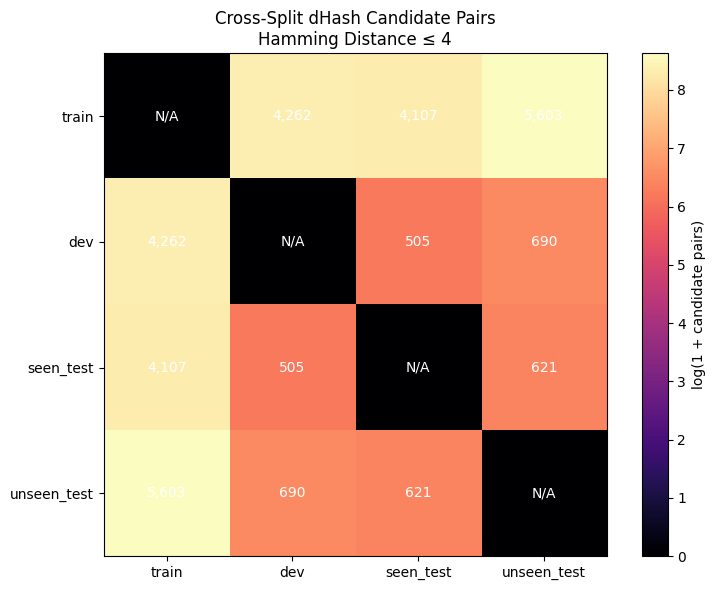

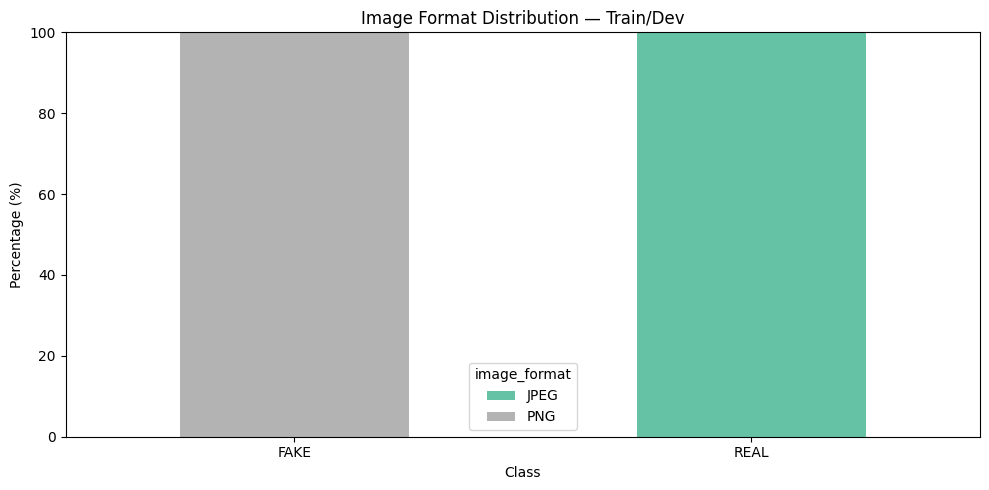

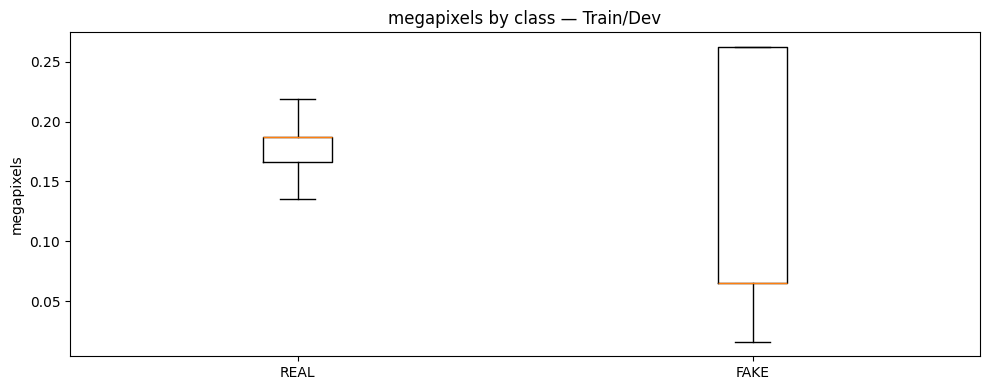

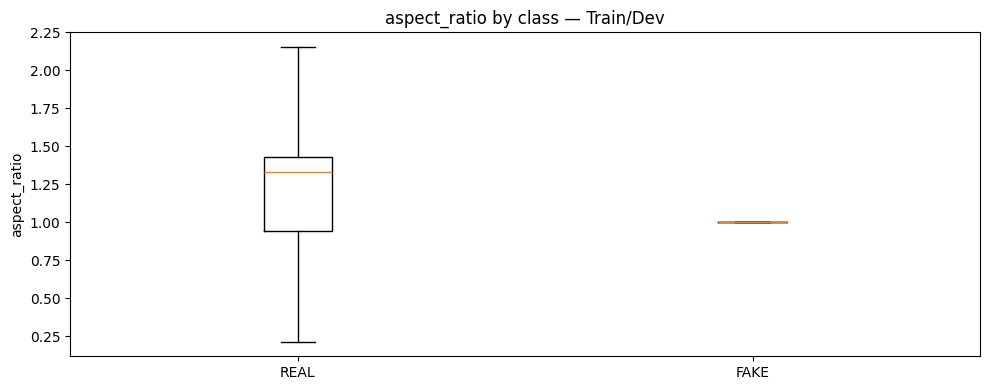

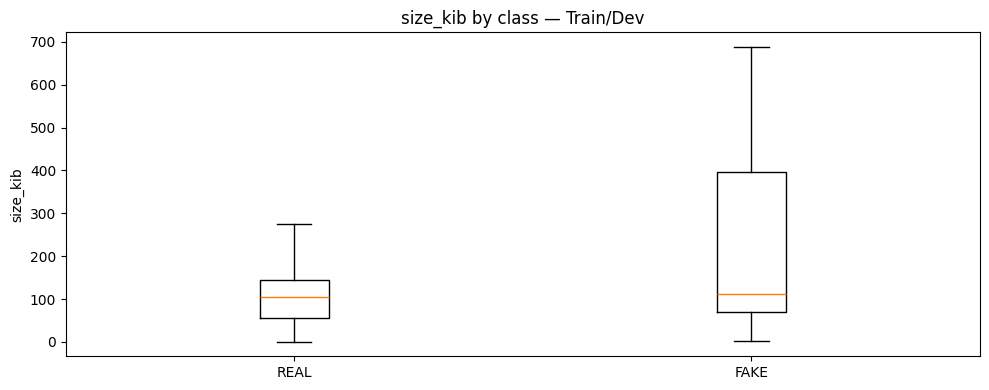


[6/6] Saving quality audit evidence...

PROOFLENS — INDEPENDENT DATA QUALITY AUDIT
Total audited images      : 120,000
Exact duplicate groups    : 0
Cross-split exact groups  : 0
Valid perceptual hashes   : 120,000
Unique perceptual hashes  : 119,893
Hash algorithm            : 64-bit dHash
Band indexing             : 5 bands
Bucket truncation         : NO
Hamming threshold         : 4
Cross-split candidates    : 15,788
Cross-label candidates    : 7,673
Affected images           : 3,191
Pixel hashes available    : 0
Pixel duplicate audit     : NOT PERFORMED
Metadata analysis         : TRAIN/DEV
Frozen dataset modified   : NO
Source image downloads    : NO
Dataset published         : NO
Execution time            : 15.41s
Quality audit status      : REVIEW_REQUIRED
Audit artifacts           : /content/cifaker_work/data_quality_audit/20261124_150113_827149

CELL 5.5 COMPLETE — Near-duplicate candidates require review before publication.


In [ ]:

# ============================================================
# CELL 5.5 — INDEPENDENT DATA QUALITY & NEAR-DUPLICATE AUDIT
# ProofLens / Cifaker
# ============================================================

import json
import time
import hashlib
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone
from IPython.display import display

# ------------------------------------------------------------
# 1. Configuration and prerequisites
# ------------------------------------------------------------

QUALITY_AUDIT_COMPLETED = False
QUALITY_GATE_PASSED = False

assert globals().get("FULL_BUILD_PASSED", False)

STARTED_55 = time.perf_counter()

HAMMING_THRESHOLD = 4
BAND_WIDTHS = [13, 13, 13, 13, 12]
EXAMPLES_PER_DISTANCE = 5

assert sum(BAND_WIDTHS) == 64
assert len(BAND_WIDTHS) > HAMMING_THRESHOLD

SPLITS_55 = [
    "train",
    "dev",
    "seen_test",
    "unseen_test",
]

SPLIT_PAIRS_55 = list(
    itertools.combinations(range(4), 2)
)

timestamp_55 = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%f"
)

QUALITY_DIR_55 = (
    WORK_DIR / "data_quality_audit" / timestamp_55
)

QUALITY_DIR_55.mkdir(
    parents=True,
    exist_ok=True,
)

manifest_path = FULL_BUILD_DIR_54 / "manifest.parquet"

checksums_55 = json.loads(
    (FULL_BUILD_DIR_54 / "checksums.json").read_text()
)

expected_sha = checksums_55[
    "manifest_parquet"
]["sha256"]

with manifest_path.open("rb") as f:
    actual_sha = hashlib.file_digest(
        f, "sha256"
    ).hexdigest()

assert actual_sha == expected_sha

manifest_55 = pd.read_parquet(manifest_path)

print("[1/6] Manifest loaded and verified.")
print(f"Records: {len(manifest_55):,}")

# ------------------------------------------------------------
# 2. Exact integrity and metadata validation
# ------------------------------------------------------------

print("\n[2/6] Checking exact data integrity...")

required_columns = [
    "image_id",
    "sha256",
    "perceptual_hash",
    "leakage_group_id",
    "release_split",
    "label",
    "source_generator_group",
    "width",
    "height",
    "image_format",
    "file_size_bytes",
    "decode_status",
]

assert set(required_columns).issubset(
    manifest_55.columns
)

assert len(manifest_55) == 120000
assert manifest_55["image_id"].is_unique
assert manifest_55["image_id"].notna().all()

assert manifest_55["sha256"].astype(
    "string"
).str.fullmatch(
    r"[0-9a-fA-F]{64}", na=False
).all()

assert set(manifest_55["label"]) == {0, 1}

assert manifest_55["decode_status"].eq("OK").all()

assert manifest_55[
    ["width", "height", "file_size_bytes"]
].gt(0).all().all()

assert manifest_55[
    "image_format"
].notna().all()

assert manifest_55[
    "leakage_group_id"
].notna().all()

exact_duplicate_groups = int(
    manifest_55.groupby("sha256")
    .size()
    .gt(1)
    .sum()
)

leakage_groups = manifest_55.groupby(
    "leakage_group_id"
).agg(
    split_count=("release_split", "nunique"),
    label_count=("label", "nunique"),
)

cross_split_exact_groups = int(
    leakage_groups["split_count"].gt(1).sum()
)

cross_label_exact_groups = int(
    leakage_groups["label_count"].gt(1).sum()
)

expected_quotas = {
    "train": {0: 40000, 1: 40000},
    "dev": {0: 5000, 1: 5000},
    "seen_test": {0: 5000, 1: 5000},
    "unseen_test": {0: 10000, 1: 10000},
}

actual_quotas = (
    manifest_55.groupby(["release_split", "label"])
    .size()
    .unstack(fill_value=0)
)

assert set(actual_quotas.index) == set(SPLITS_55)

for split, quotas in expected_quotas.items():

    for label, expected_count in quotas.items():

        assert actual_quotas.loc[
            split, label
        ] == expected_count

EXACT_INTEGRITY_PASSED = (
    exact_duplicate_groups == 0
    and cross_split_exact_groups == 0
    and cross_label_exact_groups == 0
)

assert EXACT_INTEGRITY_PASSED

print(f"Exact duplicate groups: {exact_duplicate_groups}")
print(f"Cross-split groups: {cross_split_exact_groups}")
print(f"Cross-label groups: {cross_label_exact_groups}")
print("Exact integrity: PASS")

# ------------------------------------------------------------
# 3. Build a complete five-band perceptual hash index
# ------------------------------------------------------------

print("\n[3/6] Building perceptual hash index...")

ph = (
    manifest_55["perceptual_hash"]
    .astype("string")
    .str.strip()
    .str.lower()
)

valid_hash_mask = ph.str.fullmatch(
    r"[0-9a-f]{16}",
    na=False,
)

valid_hash_count = int(valid_hash_mask.sum())

print(
    f"Valid perceptual hashes: "
    f"{valid_hash_count:,}/{len(manifest_55):,}"
)

assert valid_hash_mask.all(), (
    "Incomplete perceptual hash coverage. "
    "Do not claim a complete dHash audit."
)

# Group identical hashes to reduce redundant comparisons.
hash_codes, unique_hash_strings = pd.factorize(
    ph, sort=True
)

hash_values = np.array(
    [int(h, 16) for h in unique_hash_strings],
    dtype=np.uint64,
)

N_HASHES = len(hash_values)

split_codes = manifest_55[
    "release_split"
].map({
    name: i for i, name in enumerate(SPLITS_55)
}).to_numpy(dtype=np.int64)

labels = manifest_55[
    "label"
].to_numpy(dtype=np.int64)

# Count images by unique hash, split, and label.
hash_counts = np.zeros(
    (N_HASHES, 4, 2),
    dtype=np.int64,
)

np.add.at(
    hash_counts,
    (hash_codes, split_codes, labels),
    1,
)

assert hash_counts.sum() == 120000

hash_totals = hash_counts.sum(axis=2)

# Store one deterministic representative per group.
representatives = pd.DataFrame({
    "hash_idx": hash_codes,
    "split_idx": split_codes,
    "label": labels,
    "image_id": manifest_55["image_id"].to_numpy(),
}).sort_values("image_id").drop_duplicates([
    "hash_idx",
    "split_idx",
    "label",
])

first_ids = np.full(
    (N_HASHES, 4, 2),
    None,
    dtype=object,
)

first_ids[
    representatives["hash_idx"].to_numpy(),
    representatives["split_idx"].to_numpy(),
    representatives["label"].to_numpy(),
] = representatives["image_id"].to_numpy()

def build_band_index(values):

    index = defaultdict(list)
    band_keys = []
    shift = 0

    for band_idx, width in enumerate(BAND_WIDTHS):

        keys = (
            values >> np.uint64(shift)
        ) & np.uint64((1 << width) - 1)

        band_keys.append(keys)

        for idx, key in enumerate(keys):

            index[
                (band_idx, int(key))
            ].append(idx)

        shift += width

    # No bucket truncation.
    index = {
        key: np.asarray(indices, dtype=np.int64)
        for key, indices in index.items()
    }

    return index, band_keys


def hamming_distances(value, candidates):

    xor = np.asarray(
        value ^ candidates,
        dtype=np.uint64,
    )

    if hasattr(np, "bitwise_count"):

        return np.bitwise_count(xor)

    # Compatibility fallback for older NumPy versions.
    return np.unpackbits(
        xor.view(np.uint8).reshape(-1, 8),
        axis=1,
    ).sum(axis=1)


def retrieve_candidates(i, values, index, keys):

    chunks = []

    for band_idx, band_values in enumerate(keys):

        bucket = index[
            (band_idx, int(band_values[i]))
        ]

        # Only consider larger indices:
        # each unordered hash pair is examined once.
        start = np.searchsorted(
            bucket, i, side="right"
        )

        if start < len(bucket):
            chunks.append(bucket[start:])

    if not chunks:

        return (
            np.empty(0, dtype=np.int64),
            np.empty(0, dtype=np.int64),
        )

    candidate_ids = np.unique(
        np.concatenate(chunks)
    )

    distances = hamming_distances(
        values[i],
        values[candidate_ids],
    )

    keep = distances <= HAMMING_THRESHOLD

    return candidate_ids[keep], distances[keep]


# Validate candidate retrieval against brute force
# on small synthetic fixtures.
rng = np.random.default_rng(42)

test_values = np.array(
    [
        0,
        1,
        3,
        7,
        15,
        (1 << 0) | (1 << 13)
        | (1 << 26) | (1 << 39),
        (1 << 64) - 1,
    ],
    dtype=np.uint64,
)

random_values = np.frombuffer(
    rng.bytes(64 * 8),
    dtype=np.uint64,
)

test_values = np.unique(
    np.concatenate([test_values, random_values])
)

test_index, test_keys = build_band_index(test_values)

for i in range(len(test_values)):

    found, _ = retrieve_candidates(
        i, test_values, test_index, test_keys
    )

    expected = [
        j for j in range(i + 1, len(test_values))
        if (
            int(test_values[i])
            ^ int(test_values[j])
        ).bit_count() <= HAMMING_THRESHOLD
    ]

    assert set(found.tolist()) == set(expected)

print("Synthetic candidate retrieval validation: PASS")

band_index, band_keys = build_band_index(
    hash_values
)

print(f"Unique dHashes: {N_HASHES:,}")
print(f"Index buckets: {len(band_index):,}")

print(
    "Largest bucket:",
    max(len(v) for v in band_index.values()),
)

# ------------------------------------------------------------
# 4. Exhaustive cross-split dHash candidate audit
# ------------------------------------------------------------

print("\n[4/6] Auditing cross-split similarities...")

# Dimensions: split pair × distance × count type.
# Count types: all pairs, cross-label pairs.
pair_counts = np.zeros(
    (len(SPLIT_PAIRS_55), 5, 2),
    dtype=np.int64,
)

affected = np.zeros(
    (N_HASHES, 4),
    dtype=bool,
)

examples = defaultdict(list)

audit_start = time.perf_counter()


def add_example(i, j, s, t, distance, count, cross):

    key = (s, t, distance)

    if len(examples[key]) >= EXAMPLES_PER_DISTANCE:
        return

    orientations = [(i, j)]

    if i != j:
        orientations.append((j, i))

    # Prefer a cross-label representative when available.
    for label_pairs in [
        [(0, 1), (1, 0)],
        [(0, 0), (1, 1)],
    ]:

        for a, b in orientations:

            for la, lb in label_pairs:

                id_a = first_ids[a, s, la]
                id_b = first_ids[b, t, lb]

                if id_a is not None and id_b is not None:

                    examples[key].append({
                        "image_id_a": str(id_a),
                        "image_id_b": str(id_b),
                        "split_a": SPLITS_55[s],
                        "split_b": SPLITS_55[t],
                        "label_a": la,
                        "label_b": lb,
                        "hash_a": f"{int(hash_values[a]):016x}",
                        "hash_b": f"{int(hash_values[b]):016x}",
                        "hamming_distance": distance,
                        "represented_image_pairs": count,
                        "represented_cross_label_pairs": cross,
                    })

                    return


for i in range(N_HASHES):

    js, distances = retrieve_candidates(
        i,
        hash_values,
        band_index,
        band_keys,
    )

    # Identical hashes can still belong to different images.
    # Include same-hash comparisons across different splits.
    if np.count_nonzero(hash_totals[i]) > 1:

        js = np.concatenate([
            np.array([i], dtype=np.int64),
            js,
        ])

        distances = np.concatenate([
            np.array([0], dtype=np.int64),
            distances,
        ])

    if len(js) == 0:
        continue

    distinct = js != i

    for pair_idx, (s, t) in enumerate(
        SPLIT_PAIRS_55
    ):

        forward = (
            hash_totals[i, s]
            * hash_totals[js, t]
        )

        reverse = (
            hash_totals[i, t]
            * hash_totals[js, s]
            * distinct
        )

        counts = forward + reverse

        if not counts.any():
            continue

        cross_forward = (
            hash_counts[i, s, 0]
            * hash_counts[js, t, 1]
            + hash_counts[i, s, 1]
            * hash_counts[js, t, 0]
        )

        cross_reverse = (
            hash_counts[i, t, 0]
            * hash_counts[js, s, 1]
            + hash_counts[i, t, 1]
            * hash_counts[js, s, 0]
        ) * distinct

        cross_counts = (
            cross_forward + cross_reverse
        )

        # Count every qualifying image pair, not just
        # the representative samples shown in reports.
        np.add.at(
            pair_counts[pair_idx, :, 0],
            distances,
            counts,
        )

        np.add.at(
            pair_counts[pair_idx, :, 1],
            distances,
            cross_counts,
        )

        if forward.any():
            affected[i, s] = True
            affected[js[forward > 0], t] = True

        if reverse.any():
            affected[i, t] = True
            affected[js[reverse > 0], s] = True

        # Retain bounded review samples without limiting
        # the actual candidate count.
        for distance in range(5):

            key = (s, t, distance)

            remaining = (
                EXAMPLES_PER_DISTANCE
                - len(examples[key])
            )

            if remaining <= 0:
                continue

            positions = np.flatnonzero(
                (distances == distance)
                & (counts > 0)
            )[:remaining]

            for pos in positions:

                add_example(
                    i,
                    int(js[pos]),
                    s,
                    t,
                    distance,
                    int(counts[pos]),
                    int(cross_counts[pos]),
                )

    if (i + 1) % 10000 == 0:

        print(
            f"Audited unique hashes: "
            f"{i + 1:,}/{N_HASHES:,} | "
            f"Elapsed: "
            f"{time.perf_counter() - audit_start:.1f}s",
            flush=True,
        )

near_duplicate_rows = []

for pair_idx, (s, t) in enumerate(
    SPLIT_PAIRS_55
):

    for distance in range(5):

        total = int(
            pair_counts[pair_idx, distance, 0]
        )

        cross = int(
            pair_counts[pair_idx, distance, 1]
        )

        near_duplicate_rows.append({
            "split_a": SPLITS_55[s],
            "split_b": SPLITS_55[t],
            "hamming_distance": distance,
            "candidate_pairs": total,
            "cross_label_pairs": cross,
            "same_label_pairs": total - cross,
        })

near_duplicate_detail_55 = pd.DataFrame(
    near_duplicate_rows
)

near_duplicate_summary_55 = (
    near_duplicate_detail_55.groupby(
        ["split_a", "split_b"],
        as_index=False,
    )[
        [
            "candidate_pairs",
            "cross_label_pairs",
            "same_label_pairs",
        ]
    ].sum()
)

cross_split_candidates_55 = int(
    pair_counts[:, :, 0].sum()
)

cross_label_candidates_55 = int(
    pair_counts[:, :, 1].sum()
)

assert cross_label_candidates_55 <= (
    cross_split_candidates_55
)

affected_images_55 = (
    hash_totals * affected
).sum(axis=0)

assert affected_images_55.sum() <= 120000

print("\nCross-split near-duplicate summary:")

display(near_duplicate_summary_55)

affected_df_55 = pd.DataFrame({
    "release_split": SPLITS_55,
    "affected_images": affected_images_55,
    "total_images": [
        80000, 10000, 10000, 20000
    ],
})

affected_df_55["affected_percent"] = (
    affected_df_55["affected_images"]
    / affected_df_55["total_images"]
    * 100
)

display(affected_df_55)

sample_columns = [
    "image_id_a", "image_id_b",
    "split_a", "split_b",
    "label_a", "label_b",
    "hash_a", "hash_b",
    "hamming_distance",
    "represented_image_pairs",
    "represented_cross_label_pairs",
]

near_duplicate_examples_55 = pd.DataFrame(
    [
        item
        for group in examples.values()
        for item in group
    ],
    columns=sample_columns,
)

# ------------------------------------------------------------
# 5. Metadata shortcut risk analysis — Train/Dev only
# ------------------------------------------------------------

print("\n[5/6] Analyzing metadata shortcut risks...")

development_df_55 = manifest_55.loc[
    manifest_55["release_split"].isin(
        ["train", "dev"]
    )
].copy()

development_df_55["class_name"] = (
    development_df_55["label"]
    .map({0: "REAL", 1: "FAKE"})
)

development_df_55["image_format"] = (
    development_df_55["image_format"]
    .str.upper()
)

development_df_55["aspect_ratio"] = (
    development_df_55["width"]
    / development_df_55["height"]
)

development_df_55["megapixels"] = (
    development_df_55["width"].astype("int64")
    * development_df_55["height"]
    / 1e6
)

development_df_55["size_kib"] = (
    development_df_55["file_size_bytes"]
    / 1024
)

format_distribution_55 = pd.crosstab(
    development_df_55["class_name"],
    development_df_55["image_format"],
    normalize="index",
) * 100

print("\nImage format distribution (% within class):")

display(format_distribution_55.round(2))

metadata_summary_55 = (
    development_df_55.groupby("class_name")[
        [
            "width",
            "height",
            "aspect_ratio",
            "megapixels",
            "size_kib",
        ]
    ].agg([
        "mean",
        "median",
        "std",
        "min",
        "max",
    ])
)

display(metadata_summary_55.round(3))

# Cross-split candidate count matrix.
matrix = np.zeros(
    (4, 4),
    dtype=np.int64,
)

for pair_idx, (s, t) in enumerate(
    SPLIT_PAIRS_55
):

    matrix[s, t] = int(
        pair_counts[pair_idx, :, 0].sum()
    )

    matrix[t, s] = matrix[s, t]

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    np.log1p(matrix),
    cmap="magma",
)

ax.set_xticks(range(4), SPLITS_55)
ax.set_yticks(range(4), SPLITS_55)

for i in range(4):

    for j in range(4):

        text = (
            "N/A"
            if i == j
            else f"{matrix[i, j]:,}"
        )

        ax.text(
            j,
            i,
            text,
            ha="center",
            va="center",
            color="white",
        )

ax.set_title(
    "Cross-Split dHash Candidate Pairs\n"
    "Hamming Distance ≤ 4"
)

fig.colorbar(
    im,
    ax=ax,
    label="log(1 + candidate pairs)",
)

plt.tight_layout()

fig.savefig(
    QUALITY_DIR_55 / "cross_split_candidates.png",
    dpi=160,
)

plt.show()
plt.close(fig)

# Format distribution chart.
ax = format_distribution_55.plot.bar(
    stacked=True,
    figsize=(10, 5),
    colormap="Set2",
)

ax.set_title(
    "Image Format Distribution — Train/Dev"
)

ax.set_xlabel("Class")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

plt.savefig(
    QUALITY_DIR_55 / "format_distribution.png",
    dpi=160,
)

plt.show()
plt.close()

# Numerical metadata distributions.
for feature in [
    "megapixels",
    "aspect_ratio",
    "size_kib",
]:

    fig, ax = plt.subplots(
        figsize=(10, 4)
    )

    values = [
        development_df_55.loc[
            development_df_55["label"].eq(label),
            feature,
        ].to_numpy()
        for label in [0, 1]
    ]

    ax.boxplot(
        values,
        tick_labels=["REAL", "FAKE"],
        showfliers=False,
    )

    ax.set_title(
        f"{feature} by class — Train/Dev"
    )

    ax.set_ylabel(feature)

    plt.tight_layout()

    fig.savefig(
        QUALITY_DIR_55 / f"{feature}_distribution.png",
        dpi=160,
    )

    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 6. Persist audit evidence and quality gate
# ------------------------------------------------------------

print("\n[6/6] Saving quality audit evidence...")

near_duplicate_detail_55.to_csv(
    QUALITY_DIR_55 / "near_duplicate_by_distance.csv",
    index=False,
)

near_duplicate_summary_55.to_csv(
    QUALITY_DIR_55 / "near_duplicate_summary.csv",
    index=False,
)

near_duplicate_examples_55.to_csv(
    QUALITY_DIR_55 / "near_duplicate_examples.csv",
    index=False,
)

affected_df_55.to_csv(
    QUALITY_DIR_55 / "affected_images.csv",
    index=False,
)

format_distribution_55.to_csv(
    QUALITY_DIR_55 / "format_distribution.csv"
)

metadata_summary_55.to_csv(
    QUALITY_DIR_55 / "metadata_summary.csv"
)

pixel_hash_coverage = (
    int(manifest_55["pixel_hash"].notna().sum())
    if "pixel_hash" in manifest_55.columns
    else 0
)

quality_status_55 = (
    "PASS"
    if cross_split_candidates_55 == 0
    else "REVIEW_REQUIRED"
)

quality_report_55 = {
    "stage": "5.5",
    "release_id": "genimage-120k-v1",
    "sampling_plan_id": EXPECTED_PLAN_ID,
    "production_commit": PRODUCTION_COMMIT,
    "manifest_sha256": actual_sha,
    "total_records": len(manifest_55),
    "exact_integrity_passed": EXACT_INTEGRITY_PASSED,
    "exact_duplicate_groups": exact_duplicate_groups,
    "cross_split_exact_groups": cross_split_exact_groups,
    "cross_label_exact_groups": cross_label_exact_groups,
    "valid_perceptual_hashes": valid_hash_count,
    "unique_perceptual_hashes": N_HASHES,
    "hash_type": "64-bit dHash",
    "hamming_threshold": HAMMING_THRESHOLD,
    "band_widths": BAND_WIDTHS,
    "bucket_truncation": False,
    "synthetic_retrieval_test_passed": True,
    "audit_scope": "all_materialized_cross_split_images",
    "cross_split_candidate_pairs": cross_split_candidates_55,
    "cross_label_candidate_pairs": cross_label_candidates_55,
    "affected_images": int(affected_images_55.sum()),
    "pixel_hash_coverage": pixel_hash_coverage,
    "pixel_duplicate_audit_performed": False,
    "metadata_analysis_scope": "train_and_dev_only",
    "quality_status": quality_status_55,
    "human_review_required": (
        cross_split_candidates_55 > 0
    ),
    "dataset_modified": False,
    "dataset_published": False,
    "duration_seconds": round(
        time.perf_counter() - STARTED_55, 3
    ),
}

QUALITY_REPORT_PATH = (
    QUALITY_DIR_55 / "quality_audit_report.json"
)

QUALITY_REPORT_PATH.write_text(
    json.dumps(
        quality_report_55,
        indent=2,
    ),
    encoding="utf-8",
)

QUALITY_AUDIT_COMPLETED = True

QUALITY_GATE_PASSED = (
    EXACT_INTEGRITY_PASSED
    and valid_hash_count == 120000
    and cross_split_candidates_55 == 0
)

# ------------------------------------------------------------
# 7. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("PROOFLENS — INDEPENDENT DATA QUALITY AUDIT")
print("=" * 68)

print(f"Total audited images      : {len(manifest_55):,}")
print(f"Exact duplicate groups    : {exact_duplicate_groups:,}")
print(f"Cross-split exact groups  : {cross_split_exact_groups:,}")
print(f"Valid perceptual hashes   : {valid_hash_count:,}")
print(f"Unique perceptual hashes  : {N_HASHES:,}")
print("Hash algorithm            : 64-bit dHash")
print("Band indexing             : 5 bands")
print("Bucket truncation         : NO")
print(f"Hamming threshold         : {HAMMING_THRESHOLD}")

print(
    f"Cross-split candidates    : "
    f"{cross_split_candidates_55:,}"
)

print(
    f"Cross-label candidates    : "
    f"{cross_label_candidates_55:,}"
)

print(
    f"Affected images           : "
    f"{affected_images_55.sum():,}"
)

print(f"Pixel hashes available    : {pixel_hash_coverage:,}")
print("Pixel duplicate audit     : NOT PERFORMED")
print("Metadata analysis         : TRAIN/DEV")
print("Frozen dataset modified   : NO")
print("Source image downloads    : NO")
print("Dataset published         : NO")

print(
    f"Execution time            : "
    f"{quality_report_55['duration_seconds']:.2f}s"
)

print(f"Quality audit status      : {quality_status_55}")
print(f"Audit artifacts           : {QUALITY_DIR_55}")

print("=" * 68)

if QUALITY_GATE_PASSED:

    print(
        "\nCELL 5.5 COMPLETE — "
        "Ready for full TAR verification."
    )

else:

    print(
        "\nCELL 5.5 COMPLETE — "
        "Near-duplicate candidates require review "
        "before publication."
    )


[1/5] Reconstructing complete candidate inventory...
Processed hashes: 20,000/119,893
Processed hashes: 40,000/119,893
Processed hashes: 60,000/119,893
Processed hashes: 80,000/119,893
Processed hashes: 100,000/119,893
Complete candidate inventory: 15,788
Independent pair count validation: PASS

[2/5] Analyzing candidate distributions...


label_relationship,cross_label,same_label,All
hamming_distance,,,
0,51,76,127
1,222,254,476
2,768,755,1523
3,1989,2135,4124
4,4643,4895,9538
All,7673,8115,15788


label_relationship               cross_label  same_label
release_split_a release_split_b                         
dev             seen_test                246         259
                unseen_test              320         370
seen_test       unseen_test              293         328
train           dev                     2151        2111
                seen_test               1921        2186
                unseen_test             2742        2861

Train/Test candidate pairs: 9,710
Distance-0 candidate pairs: 127

[3/5] Selecting blinded review samples...
Review pairs: 134

[4/5] Preparing visual review panels...

[5/5] Displaying blinded review sheets...


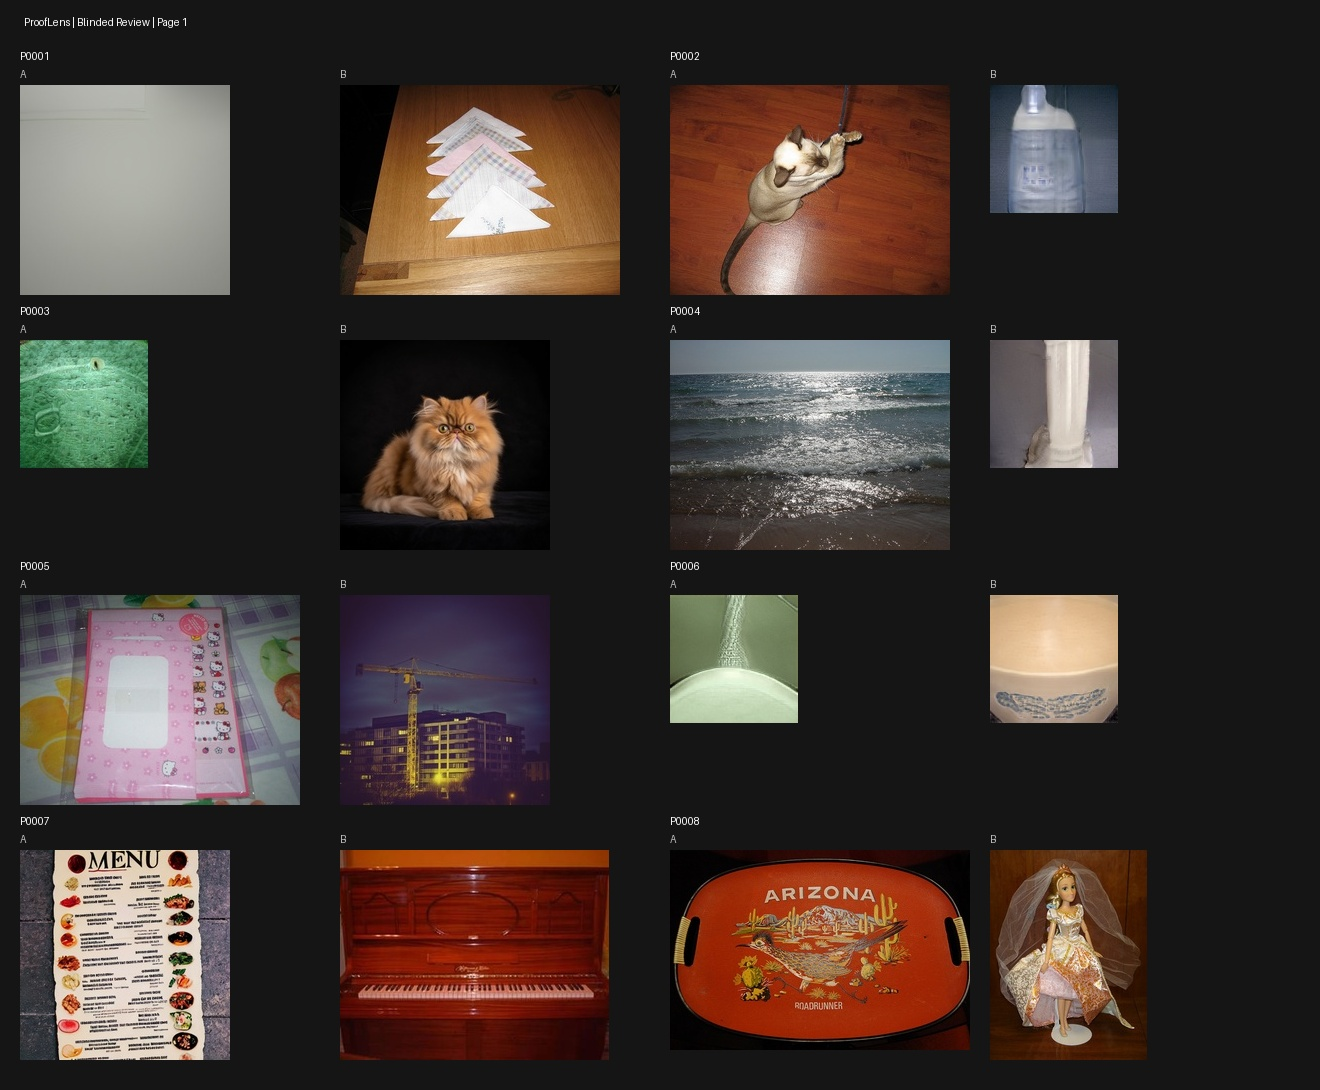

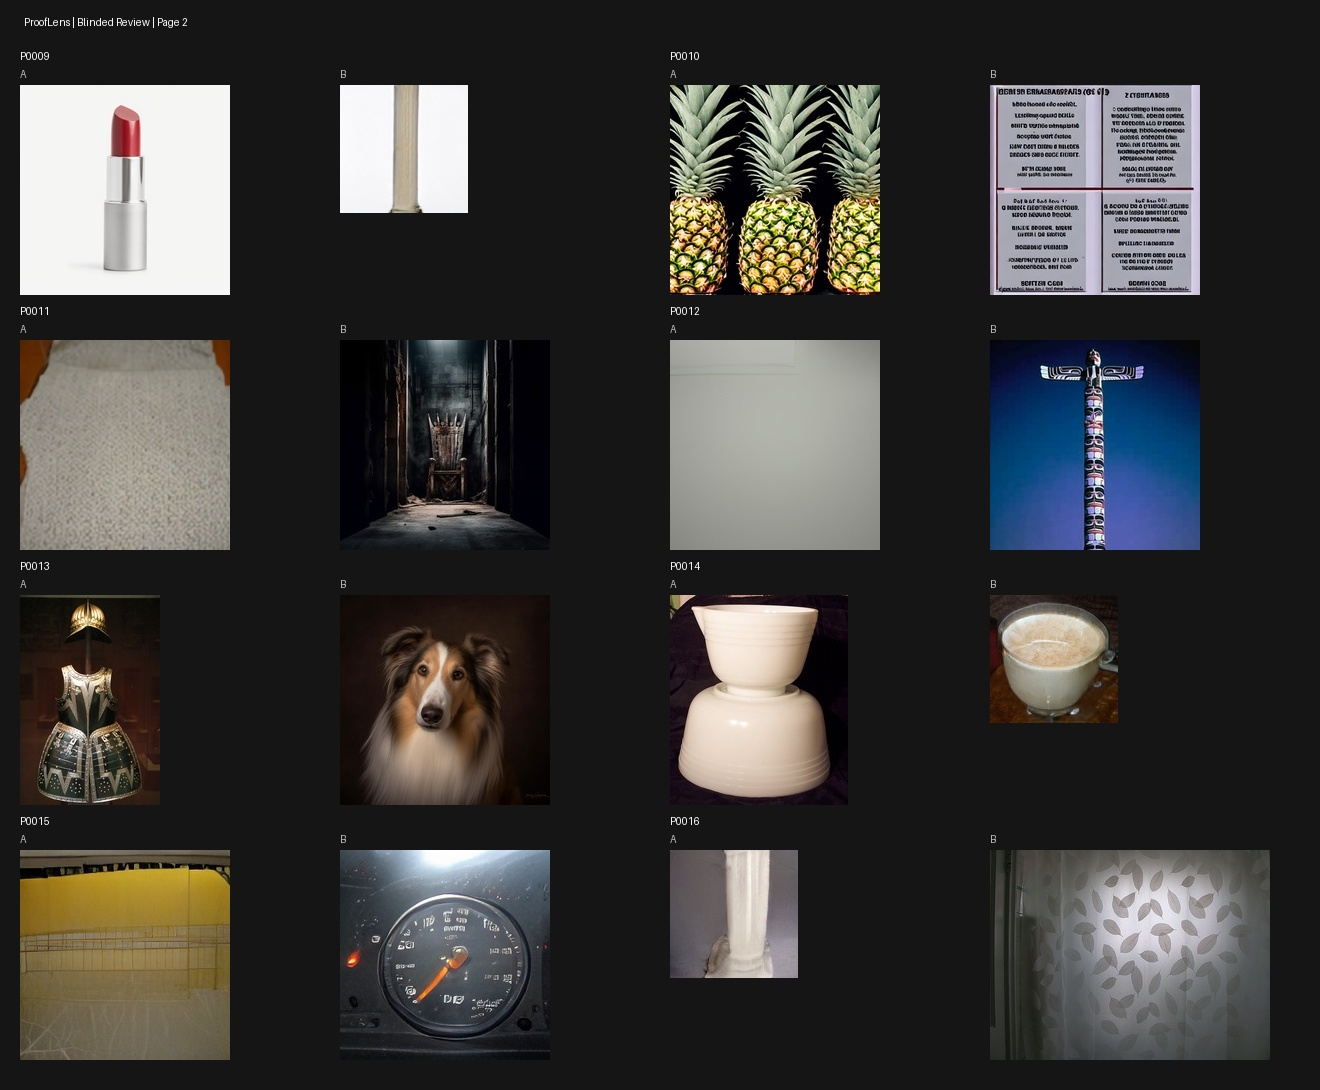


PROOFLENS — PERCEPTUAL CANDIDATE INVESTIGATION
Candidate inventory : 15,788
Cross-label pairs   : 7,673
Affected images     : 3,191
Review pairs        : 134
Review sheets       : 17
Source SHA-256 check: PASS
Review preparation  : PASS
Human review        : PENDING
Dataset modified    : NO
Dataset published   : NO
Review artifacts    : /content/cifaker_work/perceptual_review/20261124_150311_324251


In [ ]:

# ============================================================
# CELL 5.5.1 — PERCEPTUAL CANDIDATE INVESTIGATION
# ProofLens / Cifaker
# ============================================================

import sys
import json
import itertools
import subprocess
import numpy as np
import pandas as pd

from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone
from IPython.display import display, Image as DisplayImage

# ------------------------------------------------------------
# 1. Configuration and prerequisites
# ------------------------------------------------------------

assert QUALITY_AUDIT_COMPLETED
assert EXACT_INTEGRITY_PASSED

REVIEW_SEED = 42
SAMPLES_PER_STRATUM = 2
EXTRA_ZERO_DISTANCE_SAMPLES = 20

timestamp_551 = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%f"
)

REVIEW_DIR_551 = (
    WORK_DIR / "perceptual_review" / timestamp_551
)

REVIEW_DIR_551.mkdir(
    parents=True, exist_ok=True
)

print("[1/5] Reconstructing complete candidate inventory...")

# ------------------------------------------------------------
# 2. Reconstruct every cross-split candidate pair
# ------------------------------------------------------------

members = defaultdict(list)

for row_idx, (h, s) in enumerate(
    zip(hash_codes, split_codes)
):
    members[(int(h), int(s))].append(row_idx)

candidate_rows = []

for i in range(N_HASHES):

    js, distances = retrieve_candidates(
        i,
        hash_values,
        band_index,
        band_keys,
    )

    candidates = list(
        zip(js.tolist(), distances.tolist())
    )

    # Include distinct images sharing the same dHash.
    if np.count_nonzero(hash_totals[i]) > 1:
        candidates.append((i, 0))

    for j, distance in candidates:

        for s, t in SPLIT_PAIRS_55:

            orientations = [(i, j)]

            if i != j:
                orientations.append((j, i))

            for a, b in orientations:

                left = members.get((a, s), [])
                right = members.get((b, t), [])

                for row_a, row_b in itertools.product(
                    left, right
                ):
                    candidate_rows.append((
                        row_a,
                        row_b,
                        int(distance),
                    ))

    if (i + 1) % 20000 == 0:
        print(
            f"Processed hashes: "
            f"{i + 1:,}/{N_HASHES:,}"
        )

pairs_551 = pd.DataFrame(
    candidate_rows,
    columns=[
        "row_a",
        "row_b",
        "hamming_distance",
    ],
)

assert len(pairs_551) == cross_split_candidates_55

# Attach manifest metadata.
for suffix in ["a", "b"]:

    metadata = manifest_55.iloc[
        pairs_551[f"row_{suffix}"].to_numpy()
    ].reset_index(drop=True)

    for column in [
        "image_id",
        "release_split",
        "label",
        "source_generator_group",
        "perceptual_hash",
        "sha256",
    ]:
        pairs_551[f"{column}_{suffix}"] = (
            metadata[column]
        )

pairs_551["label_relationship"] = np.where(
    pairs_551["label_a"].eq(pairs_551["label_b"]),
    "same_label",
    "cross_label",
)

assert pairs_551["image_id_a"].ne(
    pairs_551["image_id_b"]
).all()

assert pairs_551["release_split_a"].ne(
    pairs_551["release_split_b"]
).all()

assert not pairs_551.duplicated([
    "image_id_a", "image_id_b"
]).any()

assert int(
    pairs_551["label_relationship"]
    .eq("cross_label").sum()
) == cross_label_candidates_55

affected_ids = set(
    pairs_551["image_id_a"]
) | set(
    pairs_551["image_id_b"]
)

assert len(affected_ids) == int(
    affected_images_55.sum()
)

pairs_551.to_parquet(
    REVIEW_DIR_551 / "all_candidate_pairs.parquet",
    index=False,
)

print(f"Complete candidate inventory: {len(pairs_551):,}")
print("Independent pair count validation: PASS")

# ------------------------------------------------------------
# 3. Analyze candidate risk distribution
# ------------------------------------------------------------

print("\n[2/5] Analyzing candidate distributions...")

distance_summary_551 = pd.crosstab(
    pairs_551["hamming_distance"],
    pairs_551["label_relationship"],
    margins=True,
)

display(distance_summary_551)

split_summary_551 = (
    pairs_551.groupby([
        "release_split_a",
        "release_split_b",
        "label_relationship",
    ])
    .size()
    .unstack(fill_value=0)
)

display(split_summary_551)

train_test_candidates = pairs_551.loc[
    pairs_551["release_split_a"].eq("train")
    & pairs_551["release_split_b"].isin([
        "seen_test", "unseen_test"
    ])
]

print(
    f"Train/Test candidate pairs: "
    f"{len(train_test_candidates):,}"
)

print(
    f"Distance-0 candidate pairs: "
    f"{pairs_551['hamming_distance'].eq(0).sum():,}"
)

distance_summary_551.to_csv(
    REVIEW_DIR_551 / "distance_summary.csv"
)

split_summary_551.to_csv(
    REVIEW_DIR_551 / "split_summary.csv"
)

# ------------------------------------------------------------
# 4. Select a stratified random review sample
# ------------------------------------------------------------

print("\n[3/5] Selecting blinded review samples...")

strata_columns = [
    "release_split_a",
    "release_split_b",
    "hamming_distance",
    "label_relationship",
]

rng = np.random.default_rng(REVIEW_SEED)

selected_indices = []

for _, group in pairs_551.groupby(
    strata_columns, sort=True
):

    n = min(
        SAMPLES_PER_STRATUM,
        len(group),
    )

    selected_indices.extend(
        rng.choice(
            group.index.to_numpy(),
            size=n,
            replace=False,
        ).tolist()
    )

# Add additional distance-zero cases for review.
remaining_zero = pairs_551.loc[
    pairs_551["hamming_distance"].eq(0)
    & ~pairs_551.index.isin(selected_indices)
]

extra_n = min(
    EXTRA_ZERO_DISTANCE_SAMPLES,
    len(remaining_zero),
)

if extra_n:

    selected_indices.extend(
        rng.choice(
            remaining_zero.index.to_numpy(),
            size=extra_n,
            replace=False,
        ).tolist()
    )

review_key_551 = (
    pairs_551.loc[selected_indices]
    .sample(frac=1, random_state=REVIEW_SEED)
    .reset_index(drop=True)
)

# Randomize the display order within each pair.
review_key_551["swap_display"] = rng.integers(
    0, 2, size=len(review_key_551)
).astype(bool)

review_key_551.insert(
    0,
    "review_id",
    [
        f"P{i + 1:04d}"
        for i in range(len(review_key_551))
    ],
)

review_key_path = (
    REVIEW_DIR_551 / "review_key_private.csv"
)

review_key_551.to_csv(
    review_key_path,
    index=False,
)

review_template_551 = pd.DataFrame({
    "review_id": review_key_551["review_id"],
    "decision": "",
    "confidence": "",
    "notes": "",
})

review_template_551.to_csv(
    REVIEW_DIR_551 / "review_template.csv",
    index=False,
)

print(f"Review pairs: {len(review_key_551)}")

# ------------------------------------------------------------
# 5. Retrieve actual images from materialized TARs
# ------------------------------------------------------------

print("\n[4/5] Preparing visual review panels...")

review_script = r'''
import io
import sys
import json
import hashlib
import pandas as pd

from pathlib import Path
from PIL import Image, ImageOps, ImageDraw

from prooflens.data.config import load_release_config
from prooflens.data.storage import create_storage_backend

config = load_release_config(sys.argv[1])
manifest_path = Path(sys.argv[2])
checksums_path = Path(sys.argv[3])
output_dir = Path(sys.argv[4])

storage = create_storage_backend(config.storage)

manifest = pd.read_parquet(manifest_path)
review = pd.read_csv(
    output_dir / "review_key_private.csv"
)

checksums = json.loads(
    checksums_path.read_text()
)

wanted_ids = set(
    review["image_id_a"]
) | set(
    review["image_id_b"]
)

subset = manifest.loc[
    manifest["image_id"].isin(wanted_ids)
].copy()

assert len(subset) == len(wanted_ids)

thumbnail_dir = output_dir / "thumbnails"
temporary_dir = output_dir / "temporary_tar"
sheet_dir = output_dir / "review_sheets"

for directory in [
    thumbnail_dir,
    temporary_dir,
    sheet_dir,
]:
    directory.mkdir(parents=True, exist_ok=True)

THUMB_SIZE = (300, 210)

# Download each required TAR only once.
# Release temporary TARs after extracting thumbnails.
for shard_id, group in subset.groupby(
    "shard_id", sort=True
):

    shard_info = checksums["shards"][shard_id]

    tar_path = temporary_dir / f"{shard_id}.tar"

    print(
        f"Reading {shard_id}: "
        f"{len(group)} review images",
        flush=True,
    )

    storage.download(
        shard_info["storage_key"],
        tar_path,
        expected_sha256=shard_info["sha256"],
    )

    try:

        with tar_path.open("rb") as handle:

            for row in group.itertuples():

                handle.seek(
                    int(row.shard_offset_data)
                )

                raw = handle.read(
                    int(row.file_size_bytes)
                )

                assert len(raw) == int(
                    row.file_size_bytes
                )

                assert hashlib.sha256(
                    raw
                ).hexdigest() == row.sha256

                with Image.open(
                    io.BytesIO(raw)
                ) as img:

                    preview = ImageOps.exif_transpose(
                        img
                    ).convert("RGB")

                    preview.thumbnail(
                        THUMB_SIZE,
                        Image.Resampling.LANCZOS,
                    )

                    preview.save(
                        thumbnail_dir
                        / f"{row.image_id}.jpg",
                        quality=95,
                    )

    finally:

        tar_path.unlink(missing_ok=True)

assert len(list(
    thumbnail_dir.glob("*.jpg")
)) == len(wanted_ids)

# Build blinded contact sheets.
# Two pairs per row, eight pairs per sheet.
PAIRS_PER_SHEET = 8

for page, start in enumerate(
    range(0, len(review), PAIRS_PER_SHEET),
    start=1,
):

    page_rows = review.iloc[
        start:start + PAIRS_PER_SHEET
    ]

    canvas = Image.new(
        "RGB", (1320, 1090), "#151515"
    )

    draw = ImageDraw.Draw(canvas)

    draw.text(
        (24, 16),
        f"ProofLens | Blinded Review | Page {page}",
        fill="white",
    )

    for position, row in enumerate(
        page_rows.itertuples()
    ):

        grid_row = position // 2
        grid_col = position % 2

        x = 20 + grid_col * 650
        y = 50 + grid_row * 255

        draw.text(
            (x, y),
            f"{row.review_id}",
            fill="#FFFFFF",
        )

        ids = [
            row.image_id_a,
            row.image_id_b,
        ]

        if row.swap_display:
            ids.reverse()

        for k, image_id in enumerate(ids):

            with Image.open(
                thumbnail_dir
                / f"{image_id}.jpg"
            ) as thumb:

                image_x = x + k * 320

                canvas.paste(
                    thumb,
                    (image_x, y + 35),
                )

                draw.text(
                    (image_x, y + 18),
                    "A" if k == 0 else "B",
                    fill="#BBBBBB",
                )

    canvas.save(
        sheet_dir / f"review_{page:03d}.jpg",
        quality=95,
    )

print(
    f"Verified unique review images: "
    f"{len(wanted_ids)}"
)

print(
    f"Review sheets: "
    f"{len(list(sheet_dir.glob('*.jpg')))}"
)
'''

review_result_551 = subprocess.run(
    [
        sys.executable,
        "-u",
        "-c",
        review_script,
        str(RUNTIME_RELEASE_CONFIG),
        str(manifest_path),
        str(FULL_BUILD_DIR_54 / "checksums.json"),
        str(REVIEW_DIR_551),
    ],
    cwd=str(REPO_DIR),
    check=True,
)

# ------------------------------------------------------------
# 6. Display and persist review artifacts
# ------------------------------------------------------------

print("\n[5/5] Displaying blinded review sheets...")

review_sheets_551 = sorted(
    (
        REVIEW_DIR_551 / "review_sheets"
    ).glob("*.jpg")
)

for sheet in review_sheets_551[:2]:

    display(
        DisplayImage(filename=str(sheet))
    )

# Save a report without automatically approving
# any near-duplicate candidate.
review_report_551 = {
    "total_candidate_pairs": len(pairs_551),
    "cross_label_candidates": (
        cross_label_candidates_55
    ),
    "affected_images": len(affected_ids),
    "review_sample_count": len(review_key_551),
    "sampling_seed": REVIEW_SEED,
    "samples_per_stratum": SAMPLES_PER_STRATUM,
    "extra_zero_distance_samples": extra_n,
    "review_sheet_count": len(review_sheets_551),
    "review_status": "PENDING_HUMAN_REVIEW",
    "dataset_modified": False,
    "dataset_published": False,
}

(
    REVIEW_DIR_551 / "review_report.json"
).write_text(
    json.dumps(review_report_551, indent=2)
)

print("\n" + "=" * 68)
print("PROOFLENS — PERCEPTUAL CANDIDATE INVESTIGATION")
print("=" * 68)

print(f"Candidate inventory : {len(pairs_551):,}")
print(f"Cross-label pairs   : {cross_label_candidates_55:,}")
print(f"Affected images     : {len(affected_ids):,}")
print(f"Review pairs        : {len(review_key_551)}")
print(f"Review sheets       : {len(review_sheets_551)}")
print("Source SHA-256 check: PASS")
print("Review preparation  : PASS")
print("Human review        : PENDING")
print("Dataset modified    : NO")
print("Dataset published   : NO")
print(f"Review artifacts    : {REVIEW_DIR_551}")

print("=" * 68)


In [ ]:

# ============================================================
# CELL 5.5.2 — INTERACTIVE HUMAN REVIEW & QUALITY DECISION
# ProofLens / Cifaker
# ============================================================

import json
import shutil
import hashlib
import ipywidgets as widgets
import pandas as pd

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display
from google.colab import drive, output

# ------------------------------------------------------------
# 1. Validate prerequisites and enable interactive widgets
# ------------------------------------------------------------

assert globals().get("FULL_BUILD_PASSED", False)
assert globals().get("QUALITY_AUDIT_COMPLETED", False)
assert globals().get("EXACT_INTEGRITY_PASSED", False)

HUMAN_REVIEW_COMPLETED = False
QUALITY_GATE_PASSED = False

output.enable_custom_widget_manager()

drive.mount("/content/drive")

MANIFEST_SHA_552 = quality_report_55["manifest_sha256"]

REVIEW_ROOT_552 = (
    Path("/content/drive/MyDrive")
    / "ProofLens_recovery"
    / "genimage-120k-v1"
    / "human_review"
    / MANIFEST_SHA_552
)

REVIEW_ROOT_552.mkdir(
    parents=True,
    exist_ok=True,
)

def utc_now():
    return datetime.now(timezone.utc).isoformat()


def file_sha256(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(
            handle, "sha256"
        ).hexdigest()


def write_json_atomic(path, payload):

    path = Path(path)

    temporary = path.with_suffix(
        path.suffix + ".tmp"
    )

    temporary.write_text(
        json.dumps(payload, indent=2),
        encoding="utf-8",
    )

    temporary.replace(path)


# ------------------------------------------------------------
# 2. Back up review artifacts or restore previous session
# ------------------------------------------------------------

print("[1/4] Preparing persistent review workspace...")

local_review_dir = globals().get("REVIEW_DIR_551")

if (
    local_review_dir is not None
    and (
        Path(local_review_dir)
        / "review_report.json"
    ).is_file()
):

    local_review_dir = Path(local_review_dir)

    sample_sha = file_sha256(
        local_review_dir / "review_key_private.csv"
    )

    REVIEW_SESSION_552 = (
        REVIEW_ROOT_552 / sample_sha
    )

    PERSISTENT_REVIEW_DIR = (
        REVIEW_SESSION_552 / "perceptual_review"
    )

    if not (
        REVIEW_SESSION_552 / "backup_complete.json"
    ).is_file():

        shutil.copytree(
            local_review_dir,
            PERSISTENT_REVIEW_DIR,
            dirs_exist_ok=True,
            ignore=shutil.ignore_patterns(
                "temporary_tar",
                "*.tar",
                "*.tmp",
            ),
        )

        assert file_sha256(
            PERSISTENT_REVIEW_DIR
            / "review_key_private.csv"
        ) == sample_sha

        write_json_atomic(
            REVIEW_SESSION_552
            / "backup_complete.json",
            {
                "manifest_sha256": MANIFEST_SHA_552,
                "review_key_sha256": sample_sha,
                "sampling_plan_id": EXPECTED_PLAN_ID,
                "created_at_utc": utc_now(),
            },
        )

else:

    # Recover directly from a previous completed backup.
    available_sessions = sorted(
        path
        for path in REVIEW_ROOT_552.iterdir()
        if path.is_dir()
        and (
            path / "backup_complete.json"
        ).is_file()
    )

    assert available_sessions, (
        "No completed review backup found. "
        "Run Cell 5.5.1 first."
    )

    assert len(available_sessions) == 1, (
        "Multiple review sessions exist. "
        "Select the intended session explicitly."
    )

    REVIEW_SESSION_552 = available_sessions[0]

    PERSISTENT_REVIEW_DIR = (
        REVIEW_SESSION_552 / "perceptual_review"
    )

    sample_sha = file_sha256(
        PERSISTENT_REVIEW_DIR
        / "review_key_private.csv"
    )

backup_meta = json.loads(
    (
        REVIEW_SESSION_552
        / "backup_complete.json"
    ).read_text()
)

assert backup_meta["manifest_sha256"] == MANIFEST_SHA_552
assert backup_meta["review_key_sha256"] == sample_sha
assert backup_meta["sampling_plan_id"] == EXPECTED_PLAN_ID

# ------------------------------------------------------------
# 3. Load review sample and restore saved decisions
# ------------------------------------------------------------

print("[2/4] Restoring review state...")

review_key_552 = pd.read_csv(
    PERSISTENT_REVIEW_DIR / "review_key_private.csv",
    keep_default_na=False,
)

review_report_551 = json.loads(
    (
        PERSISTENT_REVIEW_DIR
        / "review_report.json"
    ).read_text()
)

TOTAL_REVIEW_PAIRS = len(review_key_552)

assert TOTAL_REVIEW_PAIRS == (
    review_report_551["review_sample_count"]
)

assert review_report_551["total_candidate_pairs"] == (
    cross_split_candidates_55
)

assert review_key_552["review_id"].is_unique

review_ids = review_key_552[
    "review_id"
].tolist()

THUMBNAIL_DIR_552 = (
    PERSISTENT_REVIEW_DIR / "thumbnails"
)

required_image_ids = (
    set(review_key_552["image_id_a"])
    | set(review_key_552["image_id_b"])
)

for image_id in required_image_ids:

    assert (
        THUMBNAIL_DIR_552 / f"{image_id}.jpg"
    ).is_file(), f"Missing thumbnail: {image_id}"

CHECKPOINT_PATH_552 = (
    REVIEW_SESSION_552 / "review_checkpoint.json"
)

DECISIONS_552 = {
    "duplicate",
    "near_duplicate",
    "semantic_similarity",
    "hash_collision",
    "uncertain",
}

CONFIDENCE_LEVELS = {
    "high", "medium", "low"
}

if CHECKPOINT_PATH_552.is_file():

    checkpoint = json.loads(
        CHECKPOINT_PATH_552.read_text()
    )

    assert checkpoint["manifest_sha256"] == (
        MANIFEST_SHA_552
    )

    assert checkpoint["review_key_sha256"] == (
        sample_sha
    )

    saved_decisions = checkpoint["decisions"]

else:

    saved_decisions = {}

assert set(saved_decisions).issubset(
    set(review_ids)
)

for item in saved_decisions.values():

    assert item["decision"] in DECISIONS_552
    assert item["confidence"] in CONFIDENCE_LEVELS

print(f"Total review pairs: {TOTAL_REVIEW_PAIRS}")
print(f"Previously reviewed: {len(saved_decisions)}")
print(f"Persistent checkpoint: {CHECKPOINT_PATH_552}")

# ------------------------------------------------------------
# 4. Build the blinded review interface
# ------------------------------------------------------------

print("[3/4] Creating interactive review interface...")

position_552 = {
    "index": next(
        (
            i for i, rid in enumerate(review_ids)
            if rid not in saved_decisions
        ),
        0,
    )
}

header = widgets.HTML()

progress = widgets.IntProgress(
    value=len(saved_decisions),
    min=0,
    max=TOTAL_REVIEW_PAIRS,
    description="Reviewed:",
    bar_style="info",
    layout=widgets.Layout(width="95%"),
)

image_a = widgets.Image(
    format="jpeg",
    layout=widgets.Layout(
        width="100%",
        height="250px",
        object_fit="contain",
    ),
)

image_b = widgets.Image(
    format="jpeg",
    layout=widgets.Layout(
        width="100%",
        height="250px",
        object_fit="contain",
    ),
)

image_panel = widgets.HBox([
    widgets.VBox([
        widgets.HTML("<b>Image A</b>"),
        image_a,
    ], layout=widgets.Layout(width="50%")),

    widgets.VBox([
        widgets.HTML("<b>Image B</b>"),
        image_b,
    ], layout=widgets.Layout(width="50%")),
])

decision = widgets.RadioButtons(
    options=[
        ("Select a decision", ""),
        ("Duplicate — same image", "duplicate"),
        ("Near-duplicate — modified original", "near_duplicate"),
        ("Semantic similarity — different images", "semantic_similarity"),
        ("Hash collision — different content", "hash_collision"),
        ("Uncertain — requires review", "uncertain"),
    ],
    value="",
    description="Decision:",
)

confidence = widgets.ToggleButtons(
    options=[
        ("Select", ""),
        ("High", "high"),
        ("Medium", "medium"),
        ("Low", "low"),
    ],
    value="",
    description="Confidence:",
)

notes = widgets.Textarea(
    placeholder="Optional observations...",
    description="Notes:",
    layout=widgets.Layout(
        width="95%",
        height="75px",
    ),
)

previous_button = widgets.Button(
    description="Previous",
    icon="arrow-left",
)

next_button = widgets.Button(
    description="Next",
    icon="arrow-right",
)

save_button = widgets.Button(
    description="Save & Continue",
    button_style="success",
    icon="check",
    layout=widgets.Layout(width="180px"),
)

status_label = widgets.Label()

review_output = widgets.Output()

# ------------------------------------------------------------
# 5. Persistent checkpoint management
# ------------------------------------------------------------

def persist_decisions(updated_decisions):

    payload = {
        "release_id": "genimage-120k-v1",
        "sampling_plan_id": EXPECTED_PLAN_ID,
        "manifest_sha256": MANIFEST_SHA_552,
        "review_key_sha256": sample_sha,
        "total_review_pairs": TOTAL_REVIEW_PAIRS,
        "reviewed_pairs": len(updated_decisions),
        "updated_at_utc": utc_now(),
        "decisions": updated_decisions,
    }

    write_json_atomic(
        CHECKPOINT_PATH_552,
        payload,
    )

    # Verify checkpoint read-back.
    restored = json.loads(
        CHECKPOINT_PATH_552.read_text()
    )

    assert restored["decisions"] == updated_decisions


def render_pair():

    idx = position_552["index"]
    row = review_key_552.iloc[idx]

    rid = row["review_id"]

    ids = [
        row["image_id_a"],
        row["image_id_b"],
    ]

    if str(row["swap_display"]).lower() in {
        "true", "1"
    }:
        ids.reverse()

    image_a.value = (
        THUMBNAIL_DIR_552
        / f"{ids[0]}.jpg"
    ).read_bytes()

    image_b.value = (
        THUMBNAIL_DIR_552
        / f"{ids[1]}.jpg"
    ).read_bytes()

    existing = saved_decisions.get(rid, {})

    decision.value = existing.get(
        "decision", ""
    )

    confidence.value = existing.get(
        "confidence", ""
    )

    notes.value = existing.get(
        "notes", ""
    )

    pair_state = (
        "REVIEWED"
        if rid in saved_decisions
        else "PENDING"
    )

    header.value = (
        f"<h3>ProofLens — {rid}</h3>"
        f"<p>Pair {idx + 1}/{TOTAL_REVIEW_PAIRS}"
        f" | {pair_state}</p>"
    )

    progress.value = len(saved_decisions)

    previous_button.disabled = idx == 0

    next_button.disabled = (
        idx == TOTAL_REVIEW_PAIRS - 1
    )

    status_label.value = (
        f"{len(saved_decisions)}/"
        f"{TOTAL_REVIEW_PAIRS} reviewed"
    )


def on_previous(_):

    position_552["index"] = max(
        0,
        position_552["index"] - 1,
    )

    render_pair()


def on_next(_):

    position_552["index"] = min(
        TOTAL_REVIEW_PAIRS - 1,
        position_552["index"] + 1,
    )

    render_pair()


def on_save(_):

    global HUMAN_REVIEW_COMPLETED
    global QUALITY_GATE_PASSED

    if decision.value not in DECISIONS_552:

        status_label.value = (
            "Please select a decision."
        )
        return

    if confidence.value not in CONFIDENCE_LEVELS:

        status_label.value = (
            "Please select confidence."
        )
        return

    idx = position_552["index"]
    rid = review_ids[idx]

    updated = dict(saved_decisions)

    updated[rid] = {
        "decision": decision.value,
        "confidence": confidence.value,
        "notes": notes.value.strip(),
        "reviewed_at_utc": utc_now(),
    }

    try:

        persist_decisions(updated)

    except Exception as exc:

        status_label.value = (
            f"Checkpoint save failed: {exc}"
        )
        return

    saved_decisions.clear()
    saved_decisions.update(updated)

    # Any decision change invalidates previous approval.
    HUMAN_REVIEW_COMPLETED = False
    QUALITY_GATE_PASSED = False

    approval_checkbox.value = False

    old_report = (
        REVIEW_SESSION_552
        / "human_review_report.json"
    )

    old_report.unlink(missing_ok=True)

    remaining = [
        i for i, review_id in enumerate(review_ids)
        if review_id not in saved_decisions
    ]

    if remaining:

        position_552["index"] = next(
            (i for i in remaining if i > idx),
            remaining[0],
        )

    render_pair()

    if not remaining:

        progress.bar_style = "success"

        status_label.value = (
            "All pairs reviewed. "
            "Finalize the quality assessment below."
        )

    else:

        progress.bar_style = "info"

        status_label.value = (
            f"{rid} saved to Google Drive. "
            f"{len(saved_decisions)}/"
            f"{TOTAL_REVIEW_PAIRS} completed."
        )


previous_button.on_click(on_previous)
next_button.on_click(on_next)
save_button.on_click(on_save)

# ------------------------------------------------------------
# 6. Finalize human review and assess publication gate
# ------------------------------------------------------------

approval_checkbox = widgets.Checkbox(
    value=False,
    description=(
        "I accept the documented residual "
        "perceptual similarity risk."
    ),
    indent=False,
    layout=widgets.Layout(width="98%"),
)

finalize_button = widgets.Button(
    description="Finalize Quality Review",
    button_style="primary",
    icon="shield",
    layout=widgets.Layout(width="230px"),
)


def finalize_review(_):

    global HUMAN_REVIEW_COMPLETED
    global QUALITY_GATE_PASSED
    global human_review_report_552
    global HUMAN_REVIEW_REPORT_PATH
    global reviewed_pairs_552

    QUALITY_GATE_PASSED = False

    with review_output:

        review_output.clear_output()

        if len(saved_decisions) != TOTAL_REVIEW_PAIRS:

            print(
                "Review incomplete: "
                f"{len(saved_decisions)}/"
                f"{TOTAL_REVIEW_PAIRS}"
            )

            return

        decisions_df = pd.DataFrame([
            {
                "review_id": rid,
                **saved_decisions[rid],
            }
            for rid in review_ids
        ])

        reviewed_pairs_552 = review_key_552.merge(
            decisions_df,
            on="review_id",
            validate="one_to_one",
        )

        assert len(reviewed_pairs_552) == (
            TOTAL_REVIEW_PAIRS
        )

        decision_counts = (
            reviewed_pairs_552["decision"]
            .value_counts()
            .reindex(
                [
                    "duplicate",
                    "near_duplicate",
                    "semantic_similarity",
                    "hash_collision",
                    "uncertain",
                ],
                fill_value=0,
            )
        )

        # Treat both suspected duplicates and low-confidence
        # judgments conservatively.
        flagged_mask = (
            reviewed_pairs_552["decision"].isin([
                "duplicate",
                "near_duplicate",
                "uncertain",
            ])
            | reviewed_pairs_552["confidence"].eq("low")
        )

        flagged = reviewed_pairs_552.loc[
            flagged_mask
        ].copy()

        train_test_mask = (
            reviewed_pairs_552[
                "release_split_a"
            ].eq("train")
            & reviewed_pairs_552[
                "release_split_b"
            ].isin([
                "seen_test",
                "unseen_test",
            ])
        )

        flagged_train_test = reviewed_pairs_552.loc[
            flagged_mask & train_test_mask
        ]

        n_flagged = len(flagged)

        explicit_acceptance = bool(
            approval_checkbox.value
        )

        if n_flagged > 0:

            quality_status = "REVIEW_REQUIRED"

        elif not explicit_acceptance:

            quality_status = (
                "AWAITING_OPERATOR_ACCEPTANCE"
            )

        else:

            quality_status = (
                "PASS_WITH_DOCUMENTED_LIMITATIONS"
            )

        reviewed_pairs_552.to_csv(
            REVIEW_SESSION_552
            / "reviewed_pairs.csv",
            index=False,
        )

        flagged.to_csv(
            REVIEW_SESSION_552
            / "flagged_pairs.csv",
            index=False,
        )

        decision_counts.to_csv(
            REVIEW_SESSION_552
            / "review_decision_summary.csv",
            header=["count"],
        )

        # Results are unblinded only after all pairs
        # have been reviewed.
        split_review_summary = pd.crosstab(
            [
                reviewed_pairs_552["release_split_a"],
                reviewed_pairs_552["release_split_b"],
            ],
            reviewed_pairs_552["decision"],
        )

        split_review_summary.to_csv(
            REVIEW_SESSION_552
            / "review_split_summary.csv"
        )

        human_review_report_552 = {
            "stage": "5.5.2",
            "release_id": "genimage-120k-v1",
            "production_commit": PRODUCTION_COMMIT,
            "sampling_plan_id": EXPECTED_PLAN_ID,
            "manifest_sha256": MANIFEST_SHA_552,
            "review_key_sha256": sample_sha,
            "checkpoint_sha256": file_sha256(
                CHECKPOINT_PATH_552
            ),
            "total_candidate_pairs": (
                cross_split_candidates_55
            ),
            "review_sample_count": TOTAL_REVIEW_PAIRS,
            "reviewed_pairs": len(reviewed_pairs_552),
            "decision_counts": {
                key: int(value)
                for key, value in decision_counts.items()
            },
            "flagged_pairs": n_flagged,
            "flagged_train_test_pairs": (
                len(flagged_train_test)
            ),
            "exact_integrity_passed": (
                EXACT_INTEGRITY_PASSED
            ),
            "pixel_duplicate_audit_performed": False,
            "operator_risk_acceptance": (
                explicit_acceptance
            ),
            "quality_status": quality_status,
            "review_scope": (
                "stratified_sample_of_cross_split_candidates"
            ),
            "population_leakage_free_proven": False,
            "limitations": [
                "Only a subset of candidate pairs was visually reviewed.",
                "Review sampling is not population-proportional.",
                "dHash may produce false positives and false negatives.",
                "Thumbnail review may miss subtle image differences.",
                "Pixel-level duplicate audit has not been performed.",
            ],
            "dataset_modified": False,
            "dataset_published": False,
            "completed_at_utc": utc_now(),
        }

        HUMAN_REVIEW_REPORT_PATH = (
            REVIEW_SESSION_552
            / "human_review_report.json"
        )

        write_json_atomic(
            HUMAN_REVIEW_REPORT_PATH,
            human_review_report_552,
        )

        HUMAN_REVIEW_COMPLETED = True

        QUALITY_GATE_PASSED = (
            quality_status
            == "PASS_WITH_DOCUMENTED_LIMITATIONS"
        )

        print("\n" + "=" * 68)
        print("PROOFLENS — HUMAN REVIEW & QUALITY DECISION")
        print("=" * 68)

        print(
            f"Candidate population  : "
            f"{cross_split_candidates_55:,}"
        )

        print(
            f"Reviewed pairs        : "
            f"{len(reviewed_pairs_552)}"
        )

        for name, count in decision_counts.items():

            print(f"{name:<22}: {count}")

        print(f"Flagged pairs         : {n_flagged}")

        print(
            f"Flagged Train/Test    : "
            f"{len(flagged_train_test)}"
        )

        print(
            f"Risk acceptance       : "
            f"{explicit_acceptance}"
        )

        print("Dataset modified      : NO")
        print("Dataset published     : NO")

        print(
            f"Quality status        : "
            f"{quality_status}"
        )

        print(
            f"Publication gate      : "
            f"{'PASS' if QUALITY_GATE_PASSED else 'BLOCKED'}"
        )

        print(
            f"Persistent artifacts  : "
            f"{REVIEW_SESSION_552}"
        )

        print("=" * 68)

        display(decision_counts.to_frame("count"))
        display(split_review_summary)

        if QUALITY_GATE_PASSED:

            print(
                "\nCELL 5.5.2 COMPLETE — "
                "Ready for Cell 5.6 verification."
            )

        else:

            print(
                "\nPublication remains blocked. "
                "Resolve flagged pairs or review "
                "the documented limitations."
            )


finalize_button.on_click(finalize_review)

# ------------------------------------------------------------
# 7. Display interactive application
# ------------------------------------------------------------

print("[4/4] Review interface ready.")

render_pair()

display(
    widgets.VBox([
        header,
        progress,
        image_panel,
        decision,
        confidence,
        notes,
        widgets.HBox([
            previous_button,
            save_button,
            next_button,
        ]),
        status_label,
        widgets.HTML("<hr>"),
        widgets.HTML(
            "<b>Final Quality Assessment</b>"
            "<p>Complete all review pairs before "
            "finalizing. Risk acceptance does not "
            "override flagged candidates.</p>"
        ),
        approval_checkbox,
        finalize_button,
        review_output,
    ])
)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[1/4] Preparing persistent review workspace...
[2/4] Restoring review state...
Total review pairs: 134
Previously reviewed: 0
Persistent checkpoint: /content/drive/MyDrive/ProofLens_recovery/genimage-120k-v1/human_review/cdfcf83caddb37bb98c56c644b9556b88051f3235da7c0b890f54f4f7f6327ce/d6a0f7504dea77350328b076f006d1d03f8115afe95d883c2eec774696c0d67b/review_checkpoint.json
[3/4] Creating interactive review interface...
[4/4] Review interface ready.


In [ ]:

# ============================================================
# CELL 5.6 V2 — FINAL VERIFICATION & PUBLICATION
# ProofLens / Cifaker Production Data Pipeline
# ============================================================

import sys
import json
import time
import hashlib
import subprocess

from pathlib import Path
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. Configuration and prerequisites
# ------------------------------------------------------------

PUBLICATION_PASSED = False
HUMAN_REVIEW_COMPLETED = False

RELEASE_ID_56 = "genimage-120k-v1"

ACCEPT_RESIDUAL_PERCEPTUAL_RISK = True

EXPECTED_SPLITS_56 = {
    "train": 80000,
    "dev": 10000,
    "seen_test": 10000,
    "unseen_test": 20000,
}

EXPECTED_SHARDS_56 = 19

assert globals().get("FULL_BUILD_PASSED", False)
assert globals().get("QUALITY_AUDIT_COMPLETED", False)
assert globals().get("EXACT_INTEGRITY_PASSED", False)

assert ACCEPT_RESIDUAL_PERCEPTUAL_RISK

assert quality_report_55["total_records"] == 120000
assert quality_report_55["valid_perceptual_hashes"] == 120000
assert quality_report_55["exact_duplicate_groups"] == 0
assert quality_report_55["cross_split_exact_groups"] == 0

assert PRODUCTION_COMMIT == (
    "d3d313cdb1b46d951ff5ddc863ae501e194a5d3a"
)

assert RUNTIME_RELEASE_CONFIG.is_file()

current_head_56 = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=str(REPO_DIR),
    text=True,
).strip()

assert current_head_56 == PRODUCTION_COMMIT

tracked_changes = subprocess.check_output(
    [
        "git",
        "status",
        "--porcelain",
        "--untracked-files=no",
    ],
    cwd=str(REPO_DIR),
    text=True,
).strip()

assert not tracked_changes, (
    "Tracked repository modifications detected."
)

print("[1/6] Production prerequisites: PASS")

# ------------------------------------------------------------
# 2. Inspect previous publication failure
# ------------------------------------------------------------

PREVIOUS_FAILURE_DIR = Path(
    "/content/cifaker_work/publication/"
    "20261124_152206_414543"
)

print("\n[2/6] Inspecting previous publication logs...")

for filename in ["stdout.log", "stderr.log"]:

    log_path = PREVIOUS_FAILURE_DIR / filename

    if log_path.is_file():

        content = log_path.read_text(
            encoding="utf-8",
            errors="replace",
        )

        print(f"\n--- Previous {filename} ---")
        print(content[-12000:] or "[EMPTY]")

# Create an isolated attempt directory.
timestamp_56 = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S_%f")

PUBLICATION_DIR_56 = (
    WORK_DIR / "publication" / timestamp_56
)

PUBLICATION_DIR_56.mkdir(
    parents=True,
    exist_ok=True,
)

# ------------------------------------------------------------
# 3. Prepare documented quality acceptance
# ------------------------------------------------------------

print("\n[3/6] Preparing quality decision...")

quality_decision_56 = {
    "release_id": RELEASE_ID_56,
    "sampling_plan_id": EXPECTED_PLAN_ID,
    "production_commit": PRODUCTION_COMMIT,
    "sampling_commit": SAMPLING_COMMIT,
    "sampling_config_hash": (
        EXPECTED_SAMPLING_CONFIG_HASH
    ),
    "materialization_config_hash": (
        EXPECTED_MATERIALIZATION_CONFIG_HASH
    ),
    "manifest_sha256": (
        quality_report_55["manifest_sha256"]
    ),
    "independent_quality_audit": quality_report_55,
    "candidate_investigation": {
        "total_candidate_pairs": (
            quality_report_55[
                "cross_split_candidate_pairs"
            ]
        ),
        "cross_label_candidates": (
            quality_report_55[
                "cross_label_candidate_pairs"
            ]
        ),
        "affected_images": (
            quality_report_55["affected_images"]
        ),
        "prepared_review_pairs": 134,
        "prepared_review_sheets": 17,
    },
    "operator_decision": {
        "formal_human_review": "SKIPPED",
        "formal_review_completed": False,
        "initial_visual_observation": (
            "Operator reported no obvious near-duplicates "
            "during informal visual inspection."
        ),
        "residual_perceptual_risk_accepted": True,
        "decision": "RETAIN_FROZEN_DATASET",
        "quality_status": "ACCEPTED_WITH_LIMITATIONS",
    },
    "limitations": [
        "Perceptual similarity candidates are not confirmed duplicates.",
        "Formal visual adjudication was skipped.",
        "Population-level perceptual leakage has not been ruled out.",
        "Pixel-level duplicate audit was not performed.",
        "Original materializer cross-split candidate counts were sampled.",
        "Independent audit is complete only within the specified dHash threshold.",
    ],
    "frozen_selection_modified": False,
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
}

QUALITY_DECISION_PATH = (
    PUBLICATION_DIR_56 / "quality_decision.json"
)

QUALITY_DECISION_PATH.write_text(
    json.dumps(
        quality_decision_56,
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)

print("Quality decision: ACCEPTED_WITH_LIMITATIONS")
print("Formal human review: SKIPPED")

# ------------------------------------------------------------
# 4. Production publication subprocess
# ------------------------------------------------------------

publication_script_56 = r'''
import sys
import json
import hashlib

from pathlib import Path

from prooflens.data.config import (
    load_release_config,
    compute_config_hash,
)

from prooflens.data.storage import (
    create_storage_backend,
)

from prooflens.data.releases.manager import (
    ReleaseManager,
)

# --------------------------------------------------------
# Helpers
# --------------------------------------------------------

def require(condition, message):

    if not condition:
        raise RuntimeError(message)


def log(message):

    print(
        message,
        file=sys.stderr,
        flush=True,
    )


config = load_release_config(sys.argv[1])
output_dir = Path(sys.argv[2])

decision = json.loads(
    (output_dir / "quality_decision.json").read_text()
)

storage = create_storage_backend(config.storage)

manager = ReleaseManager(storage)

release_id = config.release_id

prefix = f"releases/{release_id}"

release_key = f"{prefix}/release.json"
state_key = f"{prefix}/state.json"
audit_key = f"{prefix}/audit_summary.json"
checksums_key = f"{prefix}/checksums.json"
plan_key = f"{prefix}/plan.json"

expected_splits = {
    "train": 80000,
    "dev": 10000,
    "seen_test": 10000,
    "unseen_test": 20000,
}


def read_json(key):

    return json.loads(
        storage.read_bytes(key).decode("utf-8")
    )


def save_local_json(filename, payload):

    (output_dir / filename).write_text(
        json.dumps(payload, indent=2),
        encoding="utf-8",
    )


def validate_quality_decision(recorded):

    require(
        recorded["manifest_sha256"]
        == decision["manifest_sha256"],
        "Quality assessment manifest mismatch.",
    )

    require(
        recorded["sampling_plan_id"]
        == decision["sampling_plan_id"],
        "Quality assessment plan mismatch.",
    )

    require(
        recorded["operator_decision"]
        == decision["operator_decision"],
        "Existing quality decision differs.",
    )

    require(
        recorded["candidate_investigation"]
        == decision["candidate_investigation"],
        "Existing candidate statistics differ.",
    )

    expected_audit = decision[
        "independent_quality_audit"
    ]

    recorded_audit = recorded[
        "independent_quality_audit"
    ]

    audit_fields = [
        "manifest_sha256",
        "total_records",
        "valid_perceptual_hashes",
        "unique_perceptual_hashes",
        "exact_duplicate_groups",
        "cross_split_exact_groups",
        "hamming_threshold",
        "cross_split_candidate_pairs",
        "cross_label_candidate_pairs",
        "affected_images",
    ]

    for field in audit_fields:

        require(
            recorded_audit[field]
            == expected_audit[field],
            f"Quality audit field differs: {field}",
        )


# --------------------------------------------------------
# A. Inspect authoritative remote release state
# --------------------------------------------------------

log("[REMOTE 1/6] Inspecting release metadata...")

require(
    release_id == decision["release_id"],
    "Unexpected release ID.",
)

required_artifacts = [
    state_key,
    audit_key,
    checksums_key,
    plan_key,
    f"{prefix}/manifest.parquet",
]

for key in required_artifacts:

    require(
        storage.exists(key),
        f"Required artifact missing: {key}",
    )

require(
    not storage.exists(
        f"{prefix}/.writer.lock.json"
    ),
    "Writer lock detected. "
    "Stop and inspect active builders.",
)

state = read_json(state_key)
audit = read_json(audit_key)
checksums = read_json(checksums_key)
plan = read_json(plan_key)

marker_exists = storage.exists(release_key)

save_local_json(
    "remote_state_before.json",
    state,
)

log(f"Remote state: {state['state']}")
log(f"Publication marker exists: {marker_exists}")

require(
    state["plan_id"] == decision["sampling_plan_id"],
    "Remote state plan ID mismatch.",
)

require(
    plan["plan_id"] == decision["sampling_plan_id"],
    "Stored plan ID mismatch.",
)

require(
    state["total_images"] == 120000,
    "Unexpected materialized image count.",
)

require(
    state["excluded_images"] == 0,
    "Release contains unresolved exclusions.",
)

require(
    state["committed_shards"] == 19,
    "Unexpected committed shard count.",
)

require(
    audit["excluded_count"] == 0,
    "Materialization audit contains exclusions.",
)

require(
    checksums["manifest_parquet"]["sha256"]
    == decision["manifest_sha256"],
    "Manifest checksum mismatch.",
)

require(
    len(checksums["shards"]) == 19,
    "Unexpected number of TAR shards.",
)

require(
    sum(
        int(item["image_count"])
        for item in checksums["shards"].values()
    ) == 120000,
    "Shard image counts do not reconcile.",
)

log("Remote release metadata: PASS")

# --------------------------------------------------------
# B. Validate production and sampling provenance
# --------------------------------------------------------

log("[REMOTE 2/6] Validating provenance...")

sampling = audit["sampling_provenance"]
materialization = audit["materialization_provenance"]

require(
    sampling["sampling_plan_id"]
    == decision["sampling_plan_id"],
    "Sampling plan ID mismatch.",
)

require(
    sampling["sampling_code_commit"]
    == decision["sampling_commit"],
    "Sampling commit mismatch.",
)

require(
    sampling["sampling_config_hash"]
    == decision["sampling_config_hash"],
    "Sampling configuration hash mismatch.",
)

require(
    materialization["materialization_code_commit"]
    == decision["production_commit"],
    "Materialization commit mismatch.",
)

require(
    materialization["materialization_config_hash"]
    == decision["materialization_config_hash"],
    "Stored materialization config hash mismatch.",
)

require(
    config.config_hash
    == materialization["materialization_config_hash"],
    "Runtime configuration differs from the "
    "materialized release configuration.",
)

resolved_config = audit["resolved_config"]

require(
    compute_config_hash(resolved_config)
    == materialization["materialization_config_hash"],
    "Stored resolved configuration hash mismatch.",
)

# IMPORTANT FIX:
# ReleaseConfig.to_dict() intentionally omits the
# near_duplicate_quality_gate field when it is "warn".
#
# Use the same default semantics as the verifier.
effective_quality_gate = str(
    resolved_config.get(
        "near_duplicate_quality_gate",
        "warn",
    )
).strip().lower()

require(
    effective_quality_gate
    == config.near_duplicate_quality_gate,
    "Runtime and stored quality policies differ.",
)

require(
    effective_quality_gate == "warn",
    f"Unexpected quality policy: "
    f"{effective_quality_gate}",
)

log(
    f"Effective near-duplicate policy: "
    f"{effective_quality_gate}"
)

log("Sampling provenance: PASS")
log("Materialization provenance: PASS")
log("Configuration integrity: PASS")

# --------------------------------------------------------
# C. Recover or persist quality evidence
# --------------------------------------------------------

log("[REMOTE 3/6] Checking publication readiness...")

if marker_exists:

    # Never mutate an already-published release.
    log(
        "Publication marker already exists. "
        "Entering read-only recovery mode."
    )

    require(
        "independent_quality_assessment" in audit,
        "Published release is missing independent "
        "quality assessment. Manual investigation required.",
    )

    validate_quality_decision(
        audit["independent_quality_assessment"]
    )

    meta = read_json(release_key)

    publication_mode = "ALREADY_PUBLISHED"

else:

    # A failed verification must be investigated.
    # Do not silently retry or bypass it.
    require(
        state["state"] != "FAILED",
        "Previous verification failed: "
        + str(state.get("last_error")),
    )

    require(
        state["state"] != "PUBLISHED",
        "Inconsistent state: PUBLISHED without release.json. "
        "Manual recovery required before retrying.",
    )

    require(
        state["state"] in {
            "MATERIALIZED",
            "VERIFIED",
        },
        f"Unexpected release state: {state['state']}",
    )

    existing_decision = audit.get(
        "independent_quality_assessment"
    )

    if existing_decision is not None:

        # A previous attempt may already have saved
        # the quality decision before failing.
        validate_quality_decision(
            existing_decision
        )

        log(
            "Existing quality assessment: VALID"
        )

    else:

        original_audit_bytes = storage.read_bytes(
            audit_key
        )

        (
            output_dir / "original_audit_summary.json"
        ).write_bytes(
            original_audit_bytes
        )

        # Preserve all historical materialization metrics.
        # Add the independent quality evidence separately.
        audit["independent_quality_assessment"] = (
            decision
        )

        audit_bytes = json.dumps(
            audit,
            indent=2,
        ).encode("utf-8")

        storage.write_bytes(
            audit_bytes,
            audit_key,
            overwrite=True,
        )

        persisted_audit = read_json(audit_key)

        require(
            persisted_audit == audit,
            "Audit summary read-back mismatch.",
        )

        validate_quality_decision(
            persisted_audit[
                "independent_quality_assessment"
            ]
        )

        log(
            "Independent quality assessment "
            "persisted successfully."
        )

    # ----------------------------------------------------
    # D. Full verification and metadata-last publication
    # ----------------------------------------------------

    log(
        "[REMOTE 4/6] Starting full TAR verification..."
    )

    log(
        "Verifying 19 TAR shards, manifest, "
        "checksums, quotas and leakage invariants."
    )

    # publish() internally calls verify().
    # Do not run verify() separately and duplicate
    # the full remote verification workload.
    meta = manager.publish(
        release_id,
        verify_tar_members=True,
    )

    publication_mode = "NEW_PUBLICATION"

    log("Production publish() returned successfully.")

# --------------------------------------------------------
# E. Independently validate the publication marker
# --------------------------------------------------------

log("[REMOTE 5/6] Reading publication marker...")

require(
    storage.exists(release_key),
    "Publication marker was not created.",
)

remote_meta = read_json(release_key)

require(
    remote_meta == meta,
    "Publication metadata read-back mismatch.",
)

require(
    remote_meta["status"] == "PUBLISHED",
    "Release is not marked PUBLISHED.",
)

require(
    remote_meta["release_id"] == release_id,
    "Published release ID mismatch.",
)

require(
    remote_meta["total_images"] == 120000,
    "Published image count mismatch.",
)

require(
    remote_meta["shard_count"] == 19,
    "Published shard count mismatch.",
)

require(
    remote_meta["sampling_plan_id"]
    == decision["sampling_plan_id"],
    "Published plan ID mismatch.",
)

require(
    remote_meta["manifest_sha256"]
    == decision["manifest_sha256"],
    "Published manifest checksum mismatch.",
)

require(
    remote_meta["sampling_provenance"]
    ["sampling_code_commit"]
    == decision["sampling_commit"],
    "Published sampling provenance mismatch.",
)

require(
    remote_meta["materialization_provenance"]
    ["materialization_code_commit"]
    == decision["production_commit"],
    "Published materialization provenance mismatch.",
)

require(
    remote_meta["code_commit_sha"]
    == decision["production_commit"],
    "Publication code commit mismatch.",
)

require(
    remote_meta["split_counts"] == expected_splits,
    "Published split quotas mismatch.",
)

verification_checks = remote_meta[
    "verification_checks"
]

require(
    bool(verification_checks),
    "Missing verification checks.",
)

require(
    all(verification_checks.values()),
    f"One or more verification checks failed: "
    f"{verification_checks}",
)

mandatory_checks = [
    "manifest_checksum_valid",
    "manifest_schema_valid",
    "all_shards_verified",
    "manifest_shard_reconciled",
    "zero_cross_split_leakage",
    "quotas_satisfied",
    "zero_unresolved_exclusions",
    "unseen_generators_isolated",
]

for name in mandatory_checks:

    require(
        verification_checks.get(name) is True,
        f"Mandatory verification check failed: {name}",
    )

final_state = read_json(state_key)

require(
    final_state["state"] == "PUBLISHED",
    "Publication marker and release state disagree.",
)

final_audit = read_json(audit_key)

validate_quality_decision(
    final_audit[
        "independent_quality_assessment"
    ]
)

# --------------------------------------------------------
# F. Persist publication evidence
# --------------------------------------------------------

log("[REMOTE 6/6] Saving publication evidence...")

save_local_json(
    "release.json",
    remote_meta,
)

save_local_json(
    "remote_state_after.json",
    final_state,
)

save_local_json(
    "audit_summary.json",
    final_audit,
)

report = {
    "release_id": release_id,
    "publication_mode": publication_mode,
    "status": "PUBLISHED",
    "total_images": remote_meta["total_images"],
    "shard_count": remote_meta["shard_count"],
    "manifest_sha256": remote_meta["manifest_sha256"],
    "sampling_plan_id": remote_meta["sampling_plan_id"],
    "split_counts": remote_meta["split_counts"],
    "verification_checks": verification_checks,
    "quality_status": "ACCEPTED_WITH_LIMITATIONS",
    "formal_human_review": "SKIPPED",
    "effective_quality_gate": effective_quality_gate,
    "dataset_published": True,
    "release_marker_verified": True,
    "published_at_utc": remote_meta["published_at_utc"],
}

log("Final publication validation: PASS")

print(json.dumps(report, indent=2))
'''

# Preserve the exact subprocess implementation for debugging.
(
    PUBLICATION_DIR_56 / "publication_worker.py"
).write_text(
    publication_script_56,
    encoding="utf-8",
)

# ------------------------------------------------------------
# 5. Execute with live diagnostic logging
# ------------------------------------------------------------

print("\n[4/6] Executing production publication...")

stdout_path_56 = (
    PUBLICATION_DIR_56 / "stdout.log"
)

stderr_path_56 = (
    PUBLICATION_DIR_56 / "stderr.log"
)

started_56 = time.perf_counter()

stderr_position_56 = 0


def show_new_logs():

    global stderr_position_56

    if not stderr_path_56.is_file():
        return

    with stderr_path_56.open("rb") as handle:

        handle.seek(stderr_position_56)

        new_content = handle.read()

        stderr_position_56 = handle.tell()

    if new_content:

        print(
            new_content.decode(
                "utf-8",
                errors="replace",
            ).rstrip(),
            flush=True,
        )


with (
    stdout_path_56.open(
        "w", encoding="utf-8"
    ) as out,

    stderr_path_56.open(
        "w", encoding="utf-8"
    ) as err,
):

    process_56 = subprocess.Popen(
        [
            sys.executable,
            "-u",
            "-c",
            publication_script_56,
            str(RUNTIME_RELEASE_CONFIG),
            str(PUBLICATION_DIR_56),
        ],
        cwd=str(REPO_DIR),
        stdout=out,
        stderr=err,
        text=True,
    )

    try:

        while True:

            try:

                process_56.wait(timeout=15)

                show_new_logs()

                break

            except subprocess.TimeoutExpired:

                show_new_logs()

                elapsed = (
                    time.perf_counter() - started_56
                )

                print(
                    "Publication running | "
                    f"Elapsed: {elapsed / 60:.2f} min",
                    flush=True,
                )

    except KeyboardInterrupt:

        if process_56.poll() is None:

            process_56.terminate()

            try:
                process_56.wait(timeout=30)

            except subprocess.TimeoutExpired:

                process_56.kill()
                process_56.wait()

        show_new_logs()

        print(
            "\nPublication interrupted. "
            "Inspect remote release state "
            "before restarting."
        )

        raise

# ------------------------------------------------------------
# 6. Report the actual root cause on failure
# ------------------------------------------------------------

if process_56.returncode != 0:

    actual_stderr = stderr_path_56.read_text(
        encoding="utf-8",
        errors="replace",
    )

    actual_stdout = stdout_path_56.read_text(
        encoding="utf-8",
        errors="replace",
    )

    print("\n" + "=" * 68)
    print("PUBLICATION FAILURE — ORIGINAL EXCEPTION")
    print("=" * 68)

    print(actual_stderr or "[EMPTY STDERR]")

    if actual_stdout:

        print("\nSTDOUT:")
        print(actual_stdout)

    print(
        f"\nExit code: {process_56.returncode}"
    )

    print(f"Logs: {PUBLICATION_DIR_56}")

    PUBLICATION_PASSED = False

    raise RuntimeError(
        "Cell 5.6 failed. "
        "See the original exception printed above. "
        "Do not rebuild the dataset."
    )

# ------------------------------------------------------------
# 7. Validate and save the final publication report
# ------------------------------------------------------------

print("\n[5/6] Validating publication results...")

publication_report_56 = json.loads(
    stdout_path_56.read_text(
        encoding="utf-8"
    )
)

assert publication_report_56["status"] == "PUBLISHED"
assert publication_report_56["dataset_published"]
assert publication_report_56["release_marker_verified"]
assert publication_report_56["total_images"] == 120000
assert publication_report_56["shard_count"] == 19

assert publication_report_56[
    "sampling_plan_id"
] == EXPECTED_PLAN_ID

assert publication_report_56[
    "split_counts"
] == EXPECTED_SPLITS_56

assert all(
    publication_report_56[
        "verification_checks"
    ].values()
)

publication_report_56["duration_seconds"] = round(
    time.perf_counter() - started_56,
    3,
)

PUBLICATION_REPORT_PATH = (
    PUBLICATION_DIR_56 / "publication_report.json"
)

PUBLICATION_REPORT_PATH.write_text(
    json.dumps(
        publication_report_56,
        indent=2,
    ),
    encoding="utf-8",
)

PUBLICATION_PASSED = True

# ------------------------------------------------------------
# 8. Final publication summary
# ------------------------------------------------------------

print("\n[6/6] Publication complete.")

print("\n" + "=" * 68)
print("PROOFLENS — FINAL DATASET PUBLICATION")
print("=" * 68)

print(f"Release ID          : {RELEASE_ID_56}")
print(f"Frozen plan ID      : {EXPECTED_PLAN_ID}")
print(f"Production commit   : {PRODUCTION_COMMIT[:12]}")

print(
    f"Publication mode    : "
    f"{publication_report_56['publication_mode']}"
)

print("Published images    : 120,000")
print("REAL / FAKE         : 60,000 / 60,000")
print("Output TAR shards   : 19")

print("\nSPLIT DISTRIBUTION")

for split, count in publication_report_56[
    "split_counts"
].items():

    print(f"{split:<20}: {count:,}")

print("\nVERIFICATION")

for name, passed in publication_report_56[
    "verification_checks"
].items():

    print(
        f"{name:<40}: "
        f"{'PASS' if passed else 'FAIL'}"
    )

print("\nQUALITY ASSESSMENT")

print("Exact leakage       : PASS")
print("Formal human review : SKIPPED")
print("Perceptual risk     : ACCEPTED")
print("Quality status      : ACCEPTED_WITH_LIMITATIONS")
print("Quality policy      : warn")
print("Pixel duplicate test: NOT PERFORMED")

print("\nRELEASE STATUS")

print("Frozen data modified: NO")
print("Release marker      : VERIFIED")
print("Dataset published   : YES")
print("Release state       : PUBLISHED")

print(
    f"Execution time      : "
    f"{publication_report_56['duration_seconds'] / 60:.2f} min"
)

print(f"Artifacts           : {PUBLICATION_DIR_56}")

print("=" * 68)

print(
    "\nCELL 5.6 COMPLETE — "
    "Ready for Cell 5.7 consumer smoke test."
)


[1/6] Production prerequisites: PASS

[2/6] Inspecting previous publication logs...

--- Previous stdout.log ---
[EMPTY]

--- Previous stderr.log ---
  File "<string>", line 125
    assert audit["materialization_provenance"][
IndentationError: unexpected indent


[3/6] Preparing quality decision...
Quality decision: ACCEPTED_WITH_LIMITATIONS
Formal human review: SKIPPED

[4/6] Executing production publication...
[REMOTE 1/6] Inspecting release metadata...
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.
Remote state: MATERIALIZED
Publication marker exists: False
Remote release metadata: PASS
[REMOTE 2/6] Validating provenance...
Effective near-duplicate policy: warn
Sampling provenance: PASS
Materialization provenance: PASS
Configuration integrity: PASS
[REMOTE 3/6] Checking publication readiness...


In [ ]:

# ============================================================
# CELL 5.6.1 — PUBLICATION FAILURE DIAGNOSTICS
# ProofLens / Cifaker
# ============================================================

import sys
import json
import subprocess

from pathlib import Path

LOG_DIR = Path(
    "/content/cifaker_work/publication/"
    "20261124_151838_695589"
)

# ------------------------------------------------------------
# 1. Inspect original subprocess logs
# ------------------------------------------------------------

print("=" * 68)
print("1. PUBLICATION SUBPROCESS LOGS")
print("=" * 68)

for filename in ["stdout.log", "stderr.log"]:

    path = LOG_DIR / filename

    print(f"\n--- {filename} ---")

    if path.is_file():

        content = path.read_text(
            encoding="utf-8",
            errors="replace",
        )

        print(content[-20000:] or "[EMPTY]")

    else:
        print("[FILE NOT FOUND]")

if "process_56" in globals():

    print(
        "\nSubprocess return code:",
        process_56.returncode,
    )

# ------------------------------------------------------------
# 2. Inspect remote release state
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("2. REMOTE RELEASE STATE")
print("=" * 68)

diagnostic_script = r'''
import sys
import json

from prooflens.data.config import load_release_config
from prooflens.data.storage import create_storage_backend

config = load_release_config(sys.argv[1])
storage = create_storage_backend(config.storage)

prefix = f"releases/{config.release_id}"

def read_json(filename):
    key = f"{prefix}/{filename}"

    if not storage.exists(key):
        return None

    return json.loads(
        storage.read_bytes(key).decode("utf-8")
    )

state = read_json("state.json")
release = read_json("release.json")
audit = read_json("audit_summary.json")
checksums = read_json("checksums.json")

report = {
    "release_id": config.release_id,
    "state": state,
    "release_json_exists": release is not None,
    "release_status": (
        release.get("status")
        if release else None
    ),
    "published_image_count": (
        release.get("total_images")
        if release else None
    ),
    "writer_lock_exists": storage.exists(
        f"{prefix}/.writer.lock.json"
    ),
    "manifest_exists": storage.exists(
        f"{prefix}/manifest.parquet"
    ),
    "audit_summary_exists": audit is not None,
    "quality_assessment_exists": (
        "independent_quality_assessment" in audit
        if audit else False
    ),
    "near_duplicate_quality_gate": (
        audit.get("resolved_config", {}).get(
            "near_duplicate_quality_gate"
        )
        if audit else None
    ),
    "excluded_images": (
        audit.get("excluded_count")
        if audit else None
    ),
    "expected_shard_count": (
        len(checksums["shards"])
        if checksums else None
    ),
}

print(json.dumps(report, indent=2))
'''

diagnostic_result = subprocess.run(
    [
        sys.executable,
        "-u",
        "-c",
        diagnostic_script,
        str(RUNTIME_RELEASE_CONFIG),
    ],
    cwd=str(REPO_DIR),
    capture_output=True,
    text=True,
)

print(diagnostic_result.stdout)

if diagnostic_result.stderr:
    print(diagnostic_result.stderr)

diagnostic_result.check_returncode()

diagnostic_report_561 = json.loads(
    diagnostic_result.stdout
)

# ------------------------------------------------------------
# 3. Determine recovery direction
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("3. RECOVERY ASSESSMENT")
print("=" * 68)

remote_state = (
    diagnostic_report_561.get("state") or {}
).get("state")

marker_exists = diagnostic_report_561[
    "release_json_exists"
]

if marker_exists:

    print(
        "Publication marker exists. "
        "Inspect post-publication assertions."
    )

elif remote_state == "PUBLISHED":

    print(
        "INCONSISTENT STATE: PUBLISHED state "
        "without release.json."
    )

elif remote_state == "VERIFIED":

    print(
        "Verification completed. "
        "Inspect publication failure."
    )

elif remote_state == "FAILED":

    print("Verification failed.")

    print(
        "Recorded error:",
        diagnostic_report_561["state"].get(
            "last_error"
        ),
    )

elif remote_state == "MATERIALIZED":

    print(
        "Dataset remains materialized. "
        "Publication did not complete."
    )

else:

    print(f"Current remote state: {remote_state}")

print("\nDiagnostic operation: READ-ONLY")
print("Dataset modified: NO")
print("Dataset rebuilt: NO")
print("TAR downloads: NO")

print("=" * 68)


1. PUBLICATION SUBPROCESS LOGS

--- stdout.log ---
[EMPTY]

--- stderr.log ---
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.
Traceback (most recent call last):
  File "<string>", line 91, in <module>
    assert audit["resolved_config"][
           ~~~~~~~~~~~~~~~~~~~~~~~~^
        "near_duplicate_quality_gate"
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ] == "warn"
    ^
KeyError: 'near_duplicate_quality_gate'


Subprocess return code: 1

2. REMOTE RELEASE STATE
{
  "release_id": "genimage-120k-v1",
  "state": {
    "release_id": "genimage-120k-v1",
    "state": "MATERIALIZED",
    "updated_at_utc": "2026-11-24T14:56:36.953752+00:00",
    "plan_id": "plan_5f4143bb761cac8c",
    "config_hash": "61b34675b97e92e84d63762d2fd1c25375617d1bd0ae6dfb5d66d65538a7c737",
    "parent_release_id": null,
    "comm

In [ ]:

# ============================================================
# CELL 5.7 — PUBLISHED DATASET CONSUMER SMOKE TEST
# ProofLens / Cifaker Production Data Pipeline
# ============================================================

import sys
import json
import time
import shutil
import subprocess

from pathlib import Path
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

CONSUMER_SMOKE_PASSED = False
DATASET_READY_FOR_TRAINING = False

RELEASE_ID_57 = "genimage-120k-v1"

EXPECTED_PLAN_57 = "plan_5f4143bb761cac8c"

EXPECTED_COMMIT_57 = (
    "d3d313cdb1b46d951ff5ddc863ae501e194a5d3a"
)

EXPECTED_SAMPLING_COMMIT_57 = (
    "d76c8fd6105bfef029bcb2b8dbead255bf03ff5c"
)

EXPECTED_SPLITS_57 = {
    "train": 80000,
    "dev": 10000,
    "seen_test": 10000,
    "unseen_test": 20000,
}

CONSUMER_CACHE_DIR = Path(
    "/content/prooflens_training_cache"
)

CONSUMER_CACHE_DIR.mkdir(
    parents=True, exist_ok=True
)

IMAGE_SIZE_57 = 224
BATCH_SIZE_57 = 16
NUM_WORKERS_57 = 2
SEED_57 = 42

GIB = 1024**3

assert RUNTIME_RELEASE_CONFIG.is_file()

actual_commit_57 = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=str(REPO_DIR),
    text=True,
).strip()

assert actual_commit_57 == EXPECTED_COMMIT_57

timestamp_57 = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S_%f")

CONSUMER_DIR_57 = (
    WORK_DIR
    / "consumer_smoke_test"
    / timestamp_57
)

CONSUMER_DIR_57.mkdir(
    parents=True,
    exist_ok=True,
)

settings_57 = {
    "release_id": RELEASE_ID_57,
    "expected_plan_id": EXPECTED_PLAN_57,
    "expected_production_commit": EXPECTED_COMMIT_57,
    "expected_sampling_commit": EXPECTED_SAMPLING_COMMIT_57,
    "expected_splits": EXPECTED_SPLITS_57,
    "image_size": IMAGE_SIZE_57,
    "batch_size": BATCH_SIZE_57,
    "num_workers": NUM_WORKERS_57,
    "seed": SEED_57,
}

SETTINGS_PATH_57 = (
    CONSUMER_DIR_57 / "settings.json"
)

SETTINGS_PATH_57.write_text(
    json.dumps(settings_57, indent=2),
    encoding="utf-8",
)

print("=" * 68)
print("PROOFLENS — DATASET CONSUMER SMOKE TEST")
print("=" * 68)

print(f"Release ID       : {RELEASE_ID_57}")
print(f"Frozen plan      : {EXPECTED_PLAN_57}")
print(f"Production commit: {actual_commit_57[:12]}")

print(
    f"Local free disk  : "
    f"{shutil.disk_usage('/content').free / GIB:.2f} GiB"
)

print(f"Runtime cache    : {CONSUMER_CACHE_DIR}")
print(f"Artifacts        : {CONSUMER_DIR_57}")

# ------------------------------------------------------------
# 2. Consumer validation worker
# ------------------------------------------------------------

consumer_script_57 = r'''
import sys
import json
import time
import shutil

from pathlib import Path

import torch
import pandas as pd

from torch.utils.data import DataLoader, Subset

from prooflens.data import (
    ReleaseConsumer,
    FullLocalShardCache,
    ShardMapDataset,
    build_image_transforms,
    load_release,
    load_release_config,
    create_storage_backend,
)


def require(condition, message):

    if not condition:
        raise RuntimeError(message)


def log(message):

    print(message, flush=True)


def main():

    started = time.perf_counter()

    config = load_release_config(sys.argv[1])
    cache_dir = Path(sys.argv[2])
    output_dir = Path(sys.argv[3])

    settings = json.loads(
        (output_dir / "settings.json").read_text()
    )

    release_id = settings["release_id"]
    expected_splits = settings["expected_splits"]

    image_size = settings["image_size"]
    batch_size = settings["batch_size"]
    num_workers = settings["num_workers"]
    seed = settings["seed"]

    torch.manual_seed(seed)

    storage = create_storage_backend(
        config.storage
    )

    consumer = ReleaseConsumer(
        storage=storage,
        cache_dir=cache_dir,
    )

    # --------------------------------------------------------
    # A. Validate authoritative publication marker
    # --------------------------------------------------------

    log("\n[1/6] Validating published release...")

    require(
        config.release_id == release_id,
        "Runtime configuration has an unexpected release ID.",
    )

    # This API rejects unpublished releases.
    meta = consumer.get_published_release(
        release_id
    )

    require(
        meta["status"] == "PUBLISHED",
        "Release has not been published.",
    )

    require(
        meta["sampling_plan_id"]
        == settings["expected_plan_id"],
        "Frozen plan mismatch.",
    )

    require(
        meta["total_images"] == 120000,
        "Published image count mismatch.",
    )

    require(
        meta["shard_count"] == 19,
        "Published shard count mismatch.",
    )

    require(
        meta["split_counts"] == expected_splits,
        "Published split quotas mismatch.",
    )

    require(
        meta["sampling_provenance"]
        ["sampling_code_commit"]
        == settings["expected_sampling_commit"],
        "Sampling provenance mismatch.",
    )

    require(
        meta["materialization_provenance"]
        ["materialization_code_commit"]
        == settings["expected_production_commit"],
        "Materialization provenance mismatch.",
    )

    require(
        meta["materialization_config_hash"]
        == config.config_hash,
        "Runtime configuration hash mismatch.",
    )

    checks = meta["verification_checks"]

    require(
        bool(checks) and all(checks.values()),
        "Published verification checks are incomplete.",
    )

    mandatory_checks = [
        "manifest_checksum_valid",
        "manifest_schema_valid",
        "all_shards_verified",
        "manifest_shard_reconciled",
        "zero_cross_split_leakage",
        "quotas_satisfied",
        "zero_unresolved_exclusions",
        "unseen_generators_isolated",
    ]

    for name in mandatory_checks:

        require(
            checks.get(name) is True,
            f"Mandatory verification failed: {name}",
        )

    # Check both publication marker and state metadata.
    state = json.loads(
        storage.read_bytes(
            f"releases/{release_id}/state.json"
        ).decode("utf-8")
    )

    require(
        state["state"] == "PUBLISHED",
        "Publication marker and state.json disagree.",
    )

    # Read documented research quality limitations.
    audit = json.loads(
        storage.read_bytes(
            meta["audit_summary_key"]
        ).decode("utf-8")
    )

    quality = audit[
        "independent_quality_assessment"
    ]

    require(
        quality["manifest_sha256"]
        == meta["manifest_sha256"],
        "Quality assessment manifest mismatch.",
    )

    operator_decision = quality[
        "operator_decision"
    ]

    require(
        operator_decision[
            "residual_perceptual_risk_accepted"
        ] is True,
        "Residual research risk has not been accepted.",
    )

    require(
        operator_decision["quality_status"]
        == "ACCEPTED_WITH_LIMITATIONS",
        "Unexpected research quality status.",
    )

    log("Publication marker: PASS")
    log("Sampling provenance: PASS")
    log("Production provenance: PASS")
    log("Quality limitations: DOCUMENTED")

    # --------------------------------------------------------
    # B. Load manifest and check local cache capacity
    # --------------------------------------------------------

    log("\n[2/6] Loading authoritative manifest...")

    manifest = consumer.load_manifest(
        release_id,
        verify_checksum=True,
    )

    require(
        len(manifest) == 120000,
        "Manifest row count mismatch.",
    )

    require(
        manifest["image_id"].is_unique,
        "Duplicate image IDs detected.",
    )

    require(
        manifest["sha256"].notna().all()
        and manifest["sha256"].is_unique,
        "Missing or duplicated SHA-256 hashes.",
    )

    require(
        manifest["decode_status"].eq("OK").all(),
        "Manifest contains failed image decodes.",
    )

    require(
        manifest["label"].eq(0).sum() == 60000,
        "REAL quota mismatch.",
    )

    require(
        manifest["label"].eq(1).sum() == 60000,
        "FAKE quota mismatch.",
    )

    require(
        manifest.groupby("release_split")
        .size()
        .to_dict() == expected_splits,
        "Manifest split quotas mismatch.",
    )

    shards_meta = meta["shards"]

    require(
        len(shards_meta) == 19,
        "Invalid published shard inventory.",
    )

    require(
        set(manifest["shard_id"].astype(str))
        == set(shards_meta),
        "Manifest references incorrect shards.",
    )

    total_tar_bytes = sum(
        int(item["byte_size"])
        for item in shards_meta.values()
    )

    cache_manager = FullLocalShardCache(
        cache_dir,
        storage,
    )

    missing_bytes = 0

    for item in shards_meta.values():

        path = cache_manager.local_shard_path(
            item["storage_key"]
        )

        if (
            not path.is_file()
            or path.stat().st_size
            != int(item["byte_size"])
        ):

            missing_bytes += int(
                item["byte_size"]
            )

    free_bytes = shutil.disk_usage(
        cache_dir
    ).free

    largest_shard = max(
        int(item["byte_size"])
        for item in shards_meta.values()
    )

    # Include temporary-download and runtime headroom.
    required_bytes = (
        missing_bytes
        + largest_shard
        + 2 * 1024**3
    )

    require(
        free_bytes >= required_bytes,
        "Insufficient local cache capacity.",
    )

    log(f"Manifest rows: {len(manifest):,}")

    log(
        f"Complete dataset size: "
        f"{total_tar_bytes / 1024**3:.2f} GiB"
    )

    log(
        f"Missing cache bytes (size check): "
        f"{missing_bytes / 1024**3:.2f} GiB"
    )

    log("Manifest integrity: PASS")
    log("Cache capacity: PASS")

    # --------------------------------------------------------
    # C. Prepare every shard in local runtime cache
    # --------------------------------------------------------

    log("\n[3/6] Preparing all published TAR shards...")

    cache_started = time.perf_counter()

    shard_paths = {}
    cached_bytes = 0

    for index, (shard_id, item) in enumerate(
        sorted(shards_meta.items()),
        start=1,
    ):

        previous_hits = cache_manager.cache_hits

        path = cache_manager.ensure_shard(
            storage_key=item["storage_key"],
            expected_sha256=item["sha256"],
            expected_size=int(item["byte_size"]),
            verify_cached_checksum=True,
        )

        require(
            path.is_file(),
            f"Local shard missing: {shard_id}",
        )

        require(
            path.stat().st_size
            == int(item["byte_size"]),
            f"Shard size mismatch: {shard_id}",
        )

        shard_paths[shard_id] = path

        cached_bytes += path.stat().st_size

        action = (
            "CACHE HIT"
            if cache_manager.cache_hits > previous_hits
            else "DOWNLOADED"
        )

        percent = (
            cached_bytes
            / total_tar_bytes
            * 100
        )

        log(
            f"[{index:02d}/19] "
            f"{shard_id} | {action} | "
            f"{cached_bytes / 1024**3:.2f}/"
            f"{total_tar_bytes / 1024**3:.2f} GiB "
            f"({percent:.1f}%)"
        )

    cache_seconds = (
        time.perf_counter() - cache_started
    )

    require(
        len(shard_paths) == 19,
        "Incomplete local shard cache.",
    )

    require(
        cached_bytes == total_tar_bytes,
        "Cached TAR bytes mismatch.",
    )

    require(
        cache_manager.cache_hits
        + cache_manager.cache_misses == 19,
        "Cache operation counts do not reconcile.",
    )

    log("All 19 TAR shards cached and verified.")
    log(f"Cache hits: {cache_manager.cache_hits}")
    log(f"Cache misses: {cache_manager.cache_misses}")

    # --------------------------------------------------------
    # D. Test every experimental split
    # --------------------------------------------------------

    log("\n[4/6] Testing PyTorch Dataset and DataLoader...")

    transform = build_image_transforms(
        image_size=image_size,
        normalize=True,
    )

    split_reports = []
    tested_shards = set()
    tested_ids = set()

    for split, expected_count in expected_splits.items():

        split_started = time.perf_counter()

        split_df = manifest.loc[
            manifest["release_split"].eq(split)
        ].reset_index(drop=True)

        require(
            len(split_df) == expected_count,
            f"Dataset size mismatch: {split}",
        )

        require(
            split_df["label"].eq(0).sum()
            == expected_count // 2,
            f"REAL quota mismatch: {split}",
        )

        require(
            split_df["label"].eq(1).sum()
            == expected_count // 2,
            f"FAKE quota mismatch: {split}",
        )

        needed_shards = set(
            split_df["shard_id"].astype(str)
        )

        dataset = ShardMapDataset(
            manifest_df=split_df,
            shard_paths={
                shard_id: shard_paths[shard_id]
                for shard_id in needed_shards
            },
            transform=transform,
            verify_member_sha256=True,
        )

        require(
            len(dataset) == expected_count,
            f"Dataset length mismatch: {split}",
        )

        # Guarantee coverage of every TAR shard.
        shard_indices = (
            split_df.groupby("shard_id")
            .head(1)
            .index.tolist()
        )

        # Guarantee coverage of each generator/label stratum.
        strata_indices = (
            split_df.groupby([
                "source_generator_group",
                "label",
            ])
            .head(1)
            .index.tolist()
        )

        random_indices = (
            split_df.sample(
                n=min(32, len(split_df)),
                random_state=seed,
            )
            .index.tolist()
        )

        selected_indices = sorted(
            set(
                shard_indices
                + strata_indices
                + random_indices
            )
        )

        subset = Subset(
            dataset,
            selected_indices,
        )

        generator = torch.Generator()
        generator.manual_seed(seed)

        loader = DataLoader(
            subset,
            batch_size=batch_size,
            shuffle=False,
            num_workers=num_workers,
            drop_last=False,
            generator=generator,
        )

        observed_ids = []
        observed_labels = []
        observed_shards = set()
        batch_count = 0

        try:

            for batch in loader:

                images = batch["image"]
                labels = batch["label"]

                require(
                    images.ndim == 4,
                    "Invalid batch tensor dimensions.",
                )

                require(
                    tuple(images.shape[1:])
                    == (3, image_size, image_size),
                    "Unexpected image tensor shape.",
                )

                require(
                    images.dtype == torch.float32,
                    "Invalid image dtype.",
                )

                require(
                    labels.dtype == torch.float32,
                    "Invalid label dtype.",
                )

                require(
                    labels.ndim == 1
                    and labels.shape[0] == images.shape[0],
                    "Invalid binary label shape.",
                )

                require(
                    bool(torch.isfinite(images).all()),
                    "Non-finite tensor values detected.",
                )

                require(
                    bool(torch.all(
                        (labels == 0) | (labels == 1)
                    )),
                    "Non-binary labels detected.",
                )

                require(
                    all(
                        value == split
                        for value in batch["release_split"]
                    ),
                    "Incorrect release split.",
                )

                observed_ids.extend(
                    batch["image_id"]
                )

                observed_labels.extend(
                    labels.tolist()
                )

                observed_shards.update(
                    batch["shard_id"]
                )

                batch_count += 1

        finally:

            dataset.close()

        expected_ids = (
            split_df.iloc[selected_indices]
            ["image_id"].tolist()
        )

        expected_labels = (
            split_df.iloc[selected_indices]
            ["label"].astype(float).tolist()
        )

        require(
            observed_ids == expected_ids,
            f"Sample ordering mismatch: {split}",
        )

        require(
            observed_labels == expected_labels,
            f"Sample label mismatch: {split}",
        )

        require(
            len(observed_ids)
            == len(set(observed_ids)),
            "Duplicate samples returned by DataLoader.",
        )

        require(
            not tested_ids.intersection(observed_ids),
            "Repeated image IDs across tested splits.",
        )

        require(
            observed_shards == needed_shards,
            f"Incomplete shard coverage: {split}",
        )

        tested_ids.update(observed_ids)
        tested_shards.update(observed_shards)

        split_reports.append({
            "split": split,
            "dataset_size": len(dataset),
            "real_images": int(
                split_df["label"].eq(0).sum()
            ),
            "fake_images": int(
                split_df["label"].eq(1).sum()
            ),
            "smoke_tested_images": len(observed_ids),
            "shards_tested": len(observed_shards),
            "batch_count": batch_count,
            "image_shape": [3, image_size, image_size],
            "label_dtype": "float32",
            "num_workers": num_workers,
            "member_sha256_verified": True,
            "passed": True,
            "duration_seconds": round(
                time.perf_counter() - split_started,
                3,
            ),
        })

        log(
            f"{split:<14} | "
            f"{expected_count:>6,} images | "
            f"{len(observed_ids):>3} tested | "
            f"{len(observed_shards):>2} shards | PASS"
        )

    require(
        tested_shards == set(shards_meta),
        "Not every TAR shard was smoke-tested.",
    )

    # --------------------------------------------------------
    # E. Test public loader API and warm-cache reuse
    # --------------------------------------------------------

    log("\n[5/6] Testing public loader and cache reuse...")

    warm_cache = consumer.prepare_split(
        release_id=release_id,
        split="dev",
        verify_checksums=True,
    )

    require(
        len(warm_cache.manifest_df) == 10000,
        "Warm-cache dataset size mismatch.",
    )

    require(
        warm_cache.cache_misses == 0,
        "Unexpected warm-cache downloads.",
    )

    require(
        warm_cache.cache_hits
        == len(warm_cache.shard_paths),
        "Warm-cache hit count mismatch.",
    )

    public_dataset = load_release(
        release=release_id,
        split="dev",
        cache_dir=cache_dir,
        storage=storage,
        transform=transform,
        verify_checksums=True,
        streaming=False,
    )

    try:

        require(
            len(public_dataset) == 10000,
            "Public loader dataset length mismatch.",
        )

        sample = public_dataset[0]

        require(
            tuple(sample["image"].shape)
            == (3, image_size, image_size),
            "Public loader tensor shape mismatch.",
        )

        require(
            sample["release_split"] == "dev",
            "Public loader split mismatch.",
        )

        require(
            sample["image_id"]
            == warm_cache.manifest_df.iloc[0]["image_id"],
            "Public loader image ID mismatch.",
        )

    finally:

        public_dataset.close()

    log(f"Warm-cache hits: {warm_cache.cache_hits}")
    log(f"Warm-cache misses: {warm_cache.cache_misses}")
    log("Public load_release() API: PASS")

    # --------------------------------------------------------
    # F. Save final evidence
    # --------------------------------------------------------

    log("\n[6/6] Saving consumer validation report...")

    pd.DataFrame(
        split_reports
    ).to_csv(
        output_dir / "consumer_split_results.csv",
        index=False,
    )

    report = {
        "stage": "5.7",
        "release_id": release_id,
        "release_status": meta["status"],
        "sampling_plan_id": meta["sampling_plan_id"],
        "manifest_sha256": meta["manifest_sha256"],
        "sampling_commit": settings[
            "expected_sampling_commit"
        ],
        "production_commit": settings[
            "expected_production_commit"
        ],
        "total_dataset_images": len(manifest),
        "real_images": 60000,
        "fake_images": 60000,
        "total_cached_shards": len(shard_paths),
        "tested_shards": len(tested_shards),
        "smoke_tested_images": len(tested_ids),
        "total_cached_bytes": cached_bytes,
        "cache_hits": cache_manager.cache_hits,
        "cache_misses": cache_manager.cache_misses,
        "cache_prepare_seconds": round(
            cache_seconds, 3
        ),
        "warm_cache_hits": warm_cache.cache_hits,
        "warm_cache_misses": warm_cache.cache_misses,
        "split_results": split_reports,
        "manifest_integrity_passed": True,
        "shard_checksum_verification_passed": True,
        "sampled_member_sha256_passed": True,
        "multi_worker_dataloader_passed": True,
        "public_loader_passed": True,
        "cache_reuse_passed": True,
        "quality_status": operator_decision[
            "quality_status"
        ],
        "formal_human_review": operator_decision[
            "formal_human_review"
        ],
        "source_image_downloads": False,
        "release_modified": False,
        "consumer_smoke_passed": True,
        "training_ready": True,
        "duration_seconds": round(
            time.perf_counter() - started, 3
        ),
    }

    report_path = (
        output_dir / "consumer_smoke_report.json"
    )

    temporary_report = report_path.with_suffix(
        ".json.tmp"
    )

    temporary_report.write_text(
        json.dumps(report, indent=2),
        encoding="utf-8",
    )

    temporary_report.replace(report_path)

    log("Consumer smoke report saved.")
    log("All consumer validation checks passed.")


if __name__ == "__main__":
    main()
'''

# ------------------------------------------------------------
# 3. Persist and execute worker with live logs
# ------------------------------------------------------------

WORKER_PATH_57 = (
    CONSUMER_DIR_57 / "consumer_worker.py"
)

WORKER_PATH_57.write_text(
    consumer_script_57,
    encoding="utf-8",
)

LOG_PATH_57 = (
    CONSUMER_DIR_57 / "consumer.log"
)

started_57 = time.perf_counter()

log_position_57 = 0


def show_consumer_logs():

    global log_position_57

    if not LOG_PATH_57.is_file():
        return

    with LOG_PATH_57.open("rb") as handle:

        handle.seek(log_position_57)

        content = handle.read()

        log_position_57 = handle.tell()

    if content:

        print(
            content.decode(
                "utf-8",
                errors="replace",
            ).rstrip(),
            flush=True,
        )


with LOG_PATH_57.open(
    "w", encoding="utf-8"
) as log_file:

    process_57 = subprocess.Popen(
        [
            sys.executable,
            "-u",
            str(WORKER_PATH_57),
            str(RUNTIME_RELEASE_CONFIG),
            str(CONSUMER_CACHE_DIR),
            str(CONSUMER_DIR_57),
        ],
        cwd=str(REPO_DIR),
        stdout=log_file,
        stderr=subprocess.STDOUT,
        text=True,
    )

    try:

        while True:

            try:

                process_57.wait(timeout=15)

                show_consumer_logs()

                break

            except subprocess.TimeoutExpired:

                show_consumer_logs()

                elapsed = (
                    time.perf_counter() - started_57
                )

                print(
                    f"Consumer running | "
                    f"Elapsed: {elapsed / 60:.2f} min",
                    flush=True,
                )

    except KeyboardInterrupt:

        if process_57.poll() is None:

            process_57.terminate()

            try:

                process_57.wait(timeout=30)

            except subprocess.TimeoutExpired:

                process_57.kill()
                process_57.wait()

        show_consumer_logs()

        print(
            "\nConsumer interrupted. "
            "Existing valid cached TARs can be reused."
        )

        raise

# ------------------------------------------------------------
# 4. Handle errors with original diagnostics
# ------------------------------------------------------------

if process_57.returncode != 0:

    CONSUMER_SMOKE_PASSED = False
    DATASET_READY_FOR_TRAINING = False

    print("\n" + "=" * 68)
    print("CONSUMER SMOKE TEST FAILED")
    print("=" * 68)

    print(
        LOG_PATH_57.read_text(
            encoding="utf-8",
            errors="replace",
        )[-20000:]
    )

    print(f"Exit code: {process_57.returncode}")
    print(f"Log file : {LOG_PATH_57}")

    raise RuntimeError(
        "Cell 5.7 failed. "
        "Inspect the original exception above. "
        "Do not rebuild or republish the dataset."
    )

# ------------------------------------------------------------
# 5. Load and validate the final report
# ------------------------------------------------------------

CONSUMER_REPORT_PATH = (
    CONSUMER_DIR_57
    / "consumer_smoke_report.json"
)

consumer_report_57 = json.loads(
    CONSUMER_REPORT_PATH.read_text(
        encoding="utf-8"
    )
)

assert consumer_report_57["consumer_smoke_passed"]
assert consumer_report_57["training_ready"]

assert consumer_report_57[
    "release_status"
] == "PUBLISHED"

assert consumer_report_57[
    "sampling_plan_id"
] == EXPECTED_PLAN_57

assert consumer_report_57[
    "total_dataset_images"
] == 120000

assert consumer_report_57[
    "total_cached_shards"
] == 19

assert consumer_report_57[
    "tested_shards"
] == 19

assert consumer_report_57[
    "warm_cache_misses"
] == 0

assert consumer_report_57[
    "public_loader_passed"
]

assert consumer_report_57[
    "multi_worker_dataloader_passed"
]

assert all(
    item["passed"]
    for item in consumer_report_57["split_results"]
)

assert {
    item["split"]: item["dataset_size"]
    for item in consumer_report_57["split_results"]
} == EXPECTED_SPLITS_57

PUBLICATION_PASSED = True
CONSUMER_SMOKE_PASSED = True
DATASET_READY_FOR_TRAINING = True

# ------------------------------------------------------------
# 6. Display split-level results
# ------------------------------------------------------------

import pandas as pd

from IPython.display import display

consumer_results_df = pd.DataFrame(
    consumer_report_57["split_results"]
)

display(
    consumer_results_df[
        [
            "split",
            "dataset_size",
            "real_images",
            "fake_images",
            "smoke_tested_images",
            "shards_tested",
            "batch_count",
            "passed",
        ]
    ]
)

# ------------------------------------------------------------
# 7. Final dataset handover summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("PROOFLENS — FINAL DATASET CONSUMER VALIDATION")
print("=" * 68)

print(f"Release ID            : {RELEASE_ID_57}")
print("Release status        : PUBLISHED")
print(f"Frozen plan ID        : {EXPECTED_PLAN_57}")
print("Total dataset images  : 120,000")
print("REAL images           : 60,000")
print("FAKE images           : 60,000")

print("\nDATASET SPLITS")

for result in consumer_report_57[
    "split_results"
]:

    print(
        f"{result['split']:<22}: "
        f"{result['dataset_size']:,} | PASS"
    )

print("\nCACHE PERFORMANCE")

print("Cached TAR shards     : 19/19")
print("Tested TAR shards     : 19/19")

print(
    f"Local cache size      : "
    f"{consumer_report_57['total_cached_bytes'] / GIB:.2f} GiB"
)

print(
    f"Initial cache hits    : "
    f"{consumer_report_57['cache_hits']}"
)

print(
    f"Initial cache misses  : "
    f"{consumer_report_57['cache_misses']}"
)

print(
    f"Warm cache hits       : "
    f"{consumer_report_57['warm_cache_hits']}"
)

print(
    f"Warm cache misses     : "
    f"{consumer_report_57['warm_cache_misses']}"
)

print(
    f"Cache preparation     : "
    f"{consumer_report_57['cache_prepare_seconds'] / 60:.2f} min"
)

print("\nDATALOADER VALIDATION")

print(
    f"Smoke-tested images   : "
    f"{consumer_report_57['smoke_tested_images']}"
)

print("Image tensor shape    : [B, 3, 224, 224]")
print("Image dtype           : float32")
print("Label dtype           : float32")
print("Sample member SHA-256 : PASS")
print("Multi-worker loader   : PASS")
print("Public loader API     : PASS")
print("Cache reuse           : PASS")

print("\nRESEARCH QUALITY")

print("Exact leakage         : PASS")
print("Formal human review   : SKIPPED")
print("Residual dHash risk   : ACCEPTED")
print("Quality limitations   : DOCUMENTED")

print("\nFINAL STATUS")

print("Dataset modified      : NO")
print("Hugging Face downloads: NO")
print("Consumer smoke test   : PASS")
print("Training ready        : YES")

print(
    f"Total execution time  : "
    f"{consumer_report_57['duration_seconds'] / 60:.2f} min"
)

print(f"Runtime cache         : {CONSUMER_CACHE_DIR}")
print(f"Consumer artifacts    : {CONSUMER_DIR_57}")

print("=" * 68)

print(
    "\nCELL 5.7 COMPLETE — "
    "DATA ENGINEERING PIPELINE COMPLETED."
)

print(
    "GenImage-120K v1 is ready for "
    "developer handover and model training."
)


In [1]:

# ============================================================
# CELL R.1 V2 — POST-MATERIALIZATION RECOVERY BOOTSTRAP
# ProofLens / Cifaker Production Data Pipeline
# ============================================================

import sys
import json
import hashlib
import subprocess
import yaml

from pathlib import Path
from datetime import datetime, timezone
from google.colab import auth

# ------------------------------------------------------------
# 1. Restore persistent release configuration
# ------------------------------------------------------------

FULL_BUILD_PASSED = False
QUALITY_AUDIT_COMPLETED = False
EXACT_INTEGRITY_PASSED = False
QUALITY_GATE_PASSED = False
PUBLICATION_PASSED = False
CONSUMER_SMOKE_PASSED = False
DATASET_READY_FOR_TRAINING = False

REPO_URL = "https://github.com/sangoonthego/cifaker.git"

REPO_DIR = Path("/content/cifaker")
WORK_DIR = Path("/content/cifaker_work")

WORK_DIR.mkdir(parents=True, exist_ok=True)

PRODUCTION_COMMIT = (
    "d3d313cdb1b46d951ff5ddc863ae501e194a5d3a"
)

SAMPLING_COMMIT = (
    "d76c8fd6105bfef029bcb2b8dbead255bf03ff5c"
)

EXPECTED_SAMPLING_COMMIT = SAMPLING_COMMIT

EXPECTED_PLAN_ID = "plan_5f4143bb761cac8c"

EXPECTED_RECORDS = 120000

EXPECTED_SOURCE_ID = "genimage_arrow_sharded"

EXPECTED_SOURCE_REVISION = (
    "3f4b9f921a673be09a93b335ed728cea0c6ecf33"
)

EXPECTED_SAMPLING_CONFIG_HASH = (
    "61b34675b97e92e84d63762d2fd1c25375617d1bd0ae6dfb5d66d65538a7c737"
)

EXPECTED_MATERIALIZATION_CONFIG_HASH = (
    "84da61f13fa0a3236a27f36a0f7d1b9526df6c415f9afe8f4d239f5769edba69"
)

EXPECTED_SNAPSHOT_PREFIX = (
    "pipeline_metadata/sampling_freeze/"
    f"{EXPECTED_SOURCE_REVISION}/"
    "20261124_131504_857392"
)

RELEASE_ID_54 = "genimage-120k-v1"

REMOTE_RELEASE_PREFIX_54 = (
    f"releases/{RELEASE_ID_54}"
)

EXPECTED_SPLITS = {
    "train": 80000,
    "dev": 10000,
    "seen_test": 10000,
    "unseen_test": 20000,
}

timestamp_recovery = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S_%f")

FULL_BUILD_DIR_54 = (
    WORK_DIR
    / "recovered_materialization"
    / timestamp_recovery
)

FULL_BUILD_DIR_54.mkdir(
    parents=True,
    exist_ok=True,
)

# ------------------------------------------------------------
# 2. Authenticate Google Drive
# ------------------------------------------------------------

print("[1/6] Authenticating Google Drive...")

auth.authenticate_user()

print("Google authentication: PASS")

# ------------------------------------------------------------
# 3. Restore pinned production repository
# ------------------------------------------------------------

print("\n[2/6] Restoring production repository...")

if not REPO_DIR.exists():

    subprocess.run(
        [
            "git",
            "clone",
            REPO_URL,
            str(REPO_DIR),
        ],
        check=True,
    )


def git_command(*args):

    return subprocess.check_output(
        ["git", *args],
        cwd=str(REPO_DIR),
        text=True,
    ).strip()


assert not git_command(
    "status",
    "--porcelain",
    "--untracked-files=no",
), "Tracked repository modifications detected."

git_command("fetch", "origin", "--prune")

git_command(
    "checkout",
    "--detach",
    PRODUCTION_COMMIT,
)

PRODUCTION_HEAD = git_command(
    "rev-parse", "HEAD"
)

assert PRODUCTION_HEAD == PRODUCTION_COMMIT

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-e",
        ".[gdrive,hf]",
    ],
    cwd=str(REPO_DIR),
    check=True,
)

print(f"Production commit: {PRODUCTION_HEAD[:12]}")
print("Repository restoration: PASS")

# ------------------------------------------------------------
# 4. Restore the exact materialization runtime configuration
# ------------------------------------------------------------

print("\n[3/6] Reconstructing runtime configuration...")

PRODUCTION_RELEASE_CONFIG = (
    REPO_DIR
    / "configs/releases/genimage_120k_v1_arrow.yaml"
)

release_raw = yaml.safe_load(
    PRODUCTION_RELEASE_CONFIG.read_text()
)

# Resolve configuration references before relocating YAML.
for key in [
    "source_config",
    "protocol_config",
    "storage_config",
]:

    release_raw[key] = str(
        (
            PRODUCTION_RELEASE_CONFIG.parent
            / release_raw[key]
        ).resolve()
    )

protocol_raw = yaml.safe_load(
    Path(
        release_raw["protocol_config"]
    ).read_text()
)["protocol"]

# Preserve the original frozen sampling policy.
protocol_raw[
    "cross_source_split_leakage_policy"
] = "exclude_cross_split_groups"

release_raw.pop("protocol_config")

release_raw["protocol"] = protocol_raw

release_raw["working_dir"] = str(
    WORK_DIR / "production_materialization"
)

assert release_raw["release_id"] == RELEASE_ID_54

assert release_raw["frozen_snapshot_prefix"] == (
    EXPECTED_SNAPSHOT_PREFIX
)

assert release_raw["strict_frozen_mode"] is True

RUNTIME_RELEASE_CONFIG = (
    WORK_DIR
    / "genimage_120k_v1_arrow_runtime.yaml"
)

RUNTIME_RELEASE_CONFIG.write_text(
    yaml.safe_dump(
        release_raw,
        sort_keys=False,
    ),
    encoding="utf-8",
)

print(f"Runtime config: {RUNTIME_RELEASE_CONFIG}")

# ------------------------------------------------------------
# 5. Validate the authoritative frozen sampling snapshot
# ------------------------------------------------------------

print("\n[4/6] Validating original frozen snapshot...")

validation_result = subprocess.run(
    [
        sys.executable,
        "-m",
        "prooflens.data.cli",
        "validate-frozen",
        "--config",
        str(RUNTIME_RELEASE_CONFIG),
        "--expected-records",
        str(EXPECTED_RECORDS),
        "--expected-source-id",
        EXPECTED_SOURCE_ID,
        "--expected-source-revision",
        EXPECTED_SOURCE_REVISION,
        "--expected-plan-id",
        EXPECTED_PLAN_ID,
    ],
    cwd=str(REPO_DIR),
    capture_output=True,
    text=True,
)

if validation_result.stderr:
    print(validation_result.stderr)

if validation_result.returncode != 0:

    print(validation_result.stdout)

    raise RuntimeError(
        "Frozen snapshot recovery failed."
    )

validated_snapshot_532 = json.loads(
    validation_result.stdout
)

sampling_provenance = (
    validated_snapshot_532["sampling_provenance"]
)

compatibility_532 = (
    validated_snapshot_532["compatibility"]
)

assert validated_snapshot_532[
    "validation_report"
]["valid"]

assert compatibility_532["compatible"]

assert sampling_provenance[
    "sampling_code_commit"
] == SAMPLING_COMMIT

assert sampling_provenance[
    "sampling_config_hash"
] == EXPECTED_SAMPLING_CONFIG_HASH

assert compatibility_532[
    "materialization_provenance"
]["materialization_config_hash"] == (
    EXPECTED_MATERIALIZATION_CONFIG_HASH
)

expected_selection_sha = (
    validated_snapshot_532["validation_report"]
    ["artifact_checks"]
    ["plan_selection.parquet"]
    ["sha256"]
)

(
    FULL_BUILD_DIR_54
    / "frozen_validation.json"
).write_text(
    json.dumps(
        validated_snapshot_532,
        indent=2,
    )
)

FROZEN_COMPATIBILITY_PASSED = True
PROVENANCE_HOTFIX_PASSED = True

print("Frozen selection: PASS")
print("Sampling provenance: PASS")
print("Runtime configuration: PASS")

# ------------------------------------------------------------
# 6. Recover materialized dataset and inspect publication
# ------------------------------------------------------------

print("\n[5/6] Recovering remote release state...")

recovery_settings = {
    "release_id": RELEASE_ID_54,
    "plan_id": EXPECTED_PLAN_ID,
    "sampling_commit": SAMPLING_COMMIT,
    "production_commit": PRODUCTION_COMMIT,
    "sampling_config_hash": (
        EXPECTED_SAMPLING_CONFIG_HASH
    ),
    "materialization_config_hash": (
        EXPECTED_MATERIALIZATION_CONFIG_HASH
    ),
    "selection_sha256": expected_selection_sha,
    "expected_splits": EXPECTED_SPLITS,
}

(
    FULL_BUILD_DIR_54 / "recovery_settings.json"
).write_text(
    json.dumps(recovery_settings, indent=2)
)

recovery_script = r'''
import sys
import json
import hashlib

from pathlib import Path

import pandas as pd

from prooflens.data.config import load_release_config
from prooflens.data.storage import create_storage_backend


def require(condition, message):

    if not condition:
        raise RuntimeError(message)


def log(message):

    print(message, flush=True)


config = load_release_config(sys.argv[1])
output_dir = Path(sys.argv[2])

settings = json.loads(
    (
        output_dir / "recovery_settings.json"
    ).read_text()
)

storage = create_storage_backend(
    config.storage
)

prefix = f"releases/{config.release_id}"


def read_json(filename):

    return json.loads(
        storage.read_bytes(
            f"{prefix}/{filename}"
        ).decode("utf-8")
    )


def save_json(filename, payload):

    (output_dir / filename).write_text(
        json.dumps(payload, indent=2),
        encoding="utf-8",
    )


def sha256_file(path):

    with Path(path).open("rb") as handle:

        return hashlib.file_digest(
            handle,
            "sha256",
        ).hexdigest()


# --------------------------------------------------------
# A. Inspect release state
# --------------------------------------------------------

state = read_json("state.json")
checksums = read_json("checksums.json")
audit = read_json("audit_summary.json")
plan = read_json("plan.json")

marker_exists = storage.exists(
    f"{prefix}/release.json"
)

writer_lock_exists = storage.exists(
    f"{prefix}/.writer.lock.json"
)

save_json("release_state.json", state)
save_json("checksums.json", checksums)
save_json("audit_summary.json", audit)
save_json("plan.json", plan)

remote_state = state["state"]

log(f"Remote state: {remote_state}")
log(f"Publication marker exists: {marker_exists}")
log(f"Writer lock exists: {writer_lock_exists}")

require(
    not writer_lock_exists,
    "Writer lock detected. "
    "Confirm no active builder before proceeding.",
)

require(
    config.release_id == settings["release_id"],
    "Release ID mismatch.",
)

require(
    config.config_hash
    == settings["materialization_config_hash"],
    "Runtime configuration hash mismatch.",
)

require(
    state["plan_id"] == settings["plan_id"],
    "Remote state plan mismatch.",
)

require(
    plan["plan_id"] == settings["plan_id"],
    "Stored plan mismatch.",
)

require(
    state["total_images"] == 120000,
    "Unexpected materialized image count.",
)

require(
    state["committed_shards"] == 19,
    "Unexpected committed shard count.",
)

require(
    state["excluded_images"] == 0,
    "Unresolved excluded images detected.",
)

require(
    audit["excluded_count"] == 0,
    "Materialization audit contains exclusions.",
)

require(
    audit["sampling_provenance"]
    ["sampling_code_commit"]
    == settings["sampling_commit"],
    "Sampling commit mismatch.",
)

require(
    audit["sampling_provenance"]
    ["sampling_config_hash"]
    == settings["sampling_config_hash"],
    "Sampling configuration hash mismatch.",
)

require(
    audit["materialization_provenance"]
    ["materialization_code_commit"]
    == settings["production_commit"],
    "Materialization commit mismatch.",
)

require(
    audit["materialization_provenance"]
    ["materialization_config_hash"]
    == settings["materialization_config_hash"],
    "Materialization config hash mismatch.",
)

effective_gate = audit["resolved_config"].get(
    "near_duplicate_quality_gate",
    "warn",
)

require(
    effective_gate == config.near_duplicate_quality_gate,
    "Near-duplicate quality policy mismatch.",
)

# --------------------------------------------------------
# B. Recover materialized manifest
# --------------------------------------------------------

log("Downloading materialized manifest...")

manifest_meta = checksums["manifest_parquet"]

manifest_path = (
    output_dir / "manifest.parquet"
)

storage.download(
    manifest_meta["storage_key"],
    manifest_path,
    expected_sha256=manifest_meta["sha256"],
)

require(
    sha256_file(manifest_path)
    == manifest_meta["sha256"],
    "Materialized manifest SHA-256 mismatch.",
)

require(
    manifest_path.stat().st_size
    == manifest_meta["byte_size"],
    "Materialized manifest byte size mismatch.",
)

manifest = pd.read_parquet(manifest_path)

require(
    len(manifest) == 120000,
    "Manifest row count mismatch.",
)

require(
    manifest["image_id"].is_unique,
    "Duplicate image IDs detected.",
)

require(
    manifest["sha256"].notna().all()
    and manifest["sha256"].is_unique,
    "Missing or duplicate SHA-256 values.",
)

require(
    manifest["label"].eq(0).sum() == 60000,
    "REAL quota mismatch.",
)

require(
    manifest["label"].eq(1).sum() == 60000,
    "FAKE quota mismatch.",
)

require(
    manifest["decode_status"].eq("OK").all(),
    "Manifest contains failed image decodes.",
)

require(
    manifest.groupby("release_split")
    .size()
    .to_dict() == settings["expected_splits"],
    "Split quotas mismatch.",
)

# --------------------------------------------------------
# C. Verify original frozen membership
# --------------------------------------------------------

log("Validating original frozen membership...")

frozen_path = (
    output_dir / "frozen_selection.parquet"
)

storage.download(
    (
        f"{config.frozen_snapshot_prefix}"
        "/plan_selection.parquet"
    ),
    frozen_path,
    expected_sha256=settings["selection_sha256"],
)

require(
    sha256_file(frozen_path)
    == settings["selection_sha256"],
    "Frozen selection SHA-256 mismatch.",
)

frozen = pd.read_parquet(frozen_path)

immutable_columns = [
    "image_id",
    "sha256",
    "label",
    "release_split",
    "source_id",
    "source_revision",
    "source_shard",
    "source_row_index",
    "source_path",
    "source_generator_group",
]

pd.testing.assert_frame_equal(
    manifest[immutable_columns]
    .sort_values("image_id")
    .reset_index(drop=True),

    frozen[immutable_columns]
    .sort_values("image_id")
    .reset_index(drop=True),

    check_dtype=False,
)

log("Frozen membership: PASS")

# --------------------------------------------------------
# D. Check remote TAR metadata without downloading TARs
# --------------------------------------------------------

log("Checking remote TAR shard inventory...")

shards = checksums["shards"]

require(
    len(shards) == 19,
    "Unexpected TAR shard count.",
)

require(
    sum(
        int(item["image_count"])
        for item in shards.values()
    ) == 120000,
    "Shard image counts do not reconcile.",
)

require(
    set(manifest["shard_id"].astype(str))
    == set(shards),
    "Manifest shard inventory mismatch.",
)

for shard_id, item in sorted(shards.items()):

    metadata = storage.get_metadata(
        item["storage_key"]
    )

    require(
        metadata.size_bytes
        == int(item["byte_size"]),
        f"Remote shard size mismatch: {shard_id}",
    )

log("Remote TAR inventory: 19/19 PASS")

# --------------------------------------------------------
# E. Determine recovery route
# --------------------------------------------------------

quality_exists = (
    "independent_quality_assessment" in audit
)

publication_valid = False

if marker_exists:

    meta = read_json("release.json")

    save_json("release.json", meta)

    require(
        remote_state == "PUBLISHED",
        "Publication marker and state disagree.",
    )

    require(
        meta["status"] == "PUBLISHED",
        "Invalid publication marker status.",
    )

    require(
        meta["release_id"] == settings["release_id"],
        "Published release ID mismatch.",
    )

    require(
        meta["sampling_plan_id"] == settings["plan_id"],
        "Published plan mismatch.",
    )

    require(
        meta["manifest_sha256"]
        == manifest_meta["sha256"],
        "Published manifest checksum mismatch.",
    )

    require(
        meta["total_images"] == 120000
        and meta["shard_count"] == 19,
        "Published dataset inventory mismatch.",
    )

    require(
        meta["split_counts"]
        == settings["expected_splits"],
        "Published split quotas mismatch.",
    )

    mandatory_checks = [
        "manifest_checksum_valid",
        "manifest_schema_valid",
        "all_shards_verified",
        "manifest_shard_reconciled",
        "zero_cross_split_leakage",
        "quotas_satisfied",
        "zero_unresolved_exclusions",
        "unseen_generators_isolated",
    ]

    verification = meta["verification_checks"]

    require(
        bool(verification)
        and all(verification.values()),
        "Published verification checks failed.",
    )

    require(
        all(
            verification.get(name) is True
            for name in mandatory_checks
        ),
        "Mandatory publication checks missing.",
    )

    require(
        quality_exists,
        "Published quality assessment is missing.",
    )

    quality = audit[
        "independent_quality_assessment"
    ]

    require(
        quality["manifest_sha256"]
        == manifest_meta["sha256"],
        "Quality assessment manifest mismatch.",
    )

    require(
        quality["operator_decision"]
        ["residual_perceptual_risk_accepted"] is True,
        "Residual research risk was not accepted.",
    )

    publication_valid = True
    next_action = "RUN_CELL_5_7"

elif remote_state in {
    "MATERIALIZED",
    "VERIFIED",
}:

    next_action = "RUN_CELL_5_5_THEN_5_6"

elif remote_state == "FAILED":

    next_action = "INVESTIGATE_VERIFICATION_FAILURE"

    log(
        "Previous verification error: "
        + str(state.get("last_error"))
    )

elif remote_state == "PUBLISHED":

    next_action = "INVESTIGATE_MISSING_RELEASE_MARKER"

else:

    next_action = "INVESTIGATE_REMOTE_STATE"

report = {
    "release_id": config.release_id,
    "remote_state": remote_state,
    "release_marker_exists": marker_exists,
    "publication_valid": publication_valid,
    "quality_assessment_exists": quality_exists,
    "total_images": len(manifest),
    "real_images": 60000,
    "fake_images": 60000,
    "source_shards": int(
        manifest["source_shard"].nunique()
    ),
    "output_tar_shards": len(shards),
    "total_tar_bytes": sum(
        int(item["byte_size"])
        for item in shards.values()
    ),
    "manifest_sha256": manifest_meta["sha256"],
    "manifest_checksum_verified": True,
    "frozen_membership_verified": True,
    "remote_shard_sizes_verified": True,
    "full_tar_reverification_performed": False,
    "sampling_plan_id": settings["plan_id"],
    "production_commit": settings["production_commit"],
    "next_action": next_action,
    "dataset_rebuilt": False,
    "dataset_modified": False,
    "tar_downloads": False,
}

save_json(
    "recovery_report.json",
    report,
)

log("Recovery evidence saved.")
'''

RECOVERY_WORKER_PATH = (
    FULL_BUILD_DIR_54
    / "recovery_worker.py"
)

RECOVERY_WORKER_PATH.write_text(
    recovery_script,
    encoding="utf-8",
)

recovery_result = subprocess.run(
    [
        sys.executable,
        "-u",
        str(RECOVERY_WORKER_PATH),
        str(RUNTIME_RELEASE_CONFIG),
        str(FULL_BUILD_DIR_54),
    ],
    cwd=str(REPO_DIR),
    capture_output=True,
    text=True,
)

print(recovery_result.stdout)

if recovery_result.stderr:
    print(recovery_result.stderr)

recovery_result.check_returncode()

# ------------------------------------------------------------
# 7. Restore notebook state for downstream cells
# ------------------------------------------------------------

print("\n[6/6] Restoring notebook execution state...")

RECOVERY_REPORT_PATH = (
    FULL_BUILD_DIR_54
    / "recovery_report.json"
)

materialized_report_54 = json.loads(
    RECOVERY_REPORT_PATH.read_text()
)

manifest_path = (
    FULL_BUILD_DIR_54
    / "manifest.parquet"
)

assert materialized_report_54[
    "manifest_checksum_verified"
]

assert materialized_report_54[
    "frozen_membership_verified"
]

assert materialized_report_54[
    "remote_shard_sizes_verified"
]

FULL_BUILD_PASSED = True

PUBLICATION_PASSED = (
    materialized_report_54["publication_valid"]
)

RECOVERY_NEXT_ACTION = (
    materialized_report_54["next_action"]
)

# ------------------------------------------------------------
# 8. Final recovery summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("PROOFLENS — POST-MATERIALIZATION RECOVERY")
print("=" * 68)

print(f"Release ID          : {RELEASE_ID_54}")
print(f"Production commit   : {PRODUCTION_COMMIT[:12]}")
print(f"Frozen plan ID      : {EXPECTED_PLAN_ID}")

print(
    f"Recovered images    : "
    f"{materialized_report_54['total_images']:,}"
)

print("REAL / FAKE         : 60,000 / 60,000")
print("Remote TAR shards   : 19/19")

print(
    f"Dataset storage     : "
    f"{materialized_report_54['total_tar_bytes'] / 1024**3:.2f} GiB"
)

print("\nVALIDATION")

print("Frozen membership   : PASS")
print("Manifest integrity  : PASS")
print("Remote shard sizes  : PASS")
print("Sampling provenance : PASS")

print("\nRECOVERY STATUS")

print("Dataset rebuilt     : NO")
print("Dataset modified    : NO")
print("Source downloads    : NO")
print("TAR downloads       : NO")

print(
    f"Quality assessment  : "
    f"{materialized_report_54['quality_assessment_exists']}"
)

print(
    f"Remote state        : "
    f"{materialized_report_54['remote_state']}"
)

print(
    f"Publication marker  : "
    f"{materialized_report_54['release_marker_exists']}"
)

print(
    f"Dataset published   : "
    f"{'YES' if PUBLICATION_PASSED else 'NO'}"
)

print(f"Artifacts           : {FULL_BUILD_DIR_54}")

print("=" * 68)

if RECOVERY_NEXT_ACTION == "RUN_CELL_5_7":

    print(
        "\nRECOVERY COMPLETE — "
        "Skip Cells 5.5 and 5.6."
    )

    print("NEXT ACTION: RUN CELL 5.7")

elif RECOVERY_NEXT_ACTION == (
    "RUN_CELL_5_5_THEN_5_6"
):

    print("\nRECOVERY COMPLETE")

    print("NEXT ACTION: RUN CELL 5.5")

    print(
        "Then run Cell 5.6 V2 "
        "followed by Cell 5.7."
    )

else:

    print("\nRECOVERY REQUIRES INVESTIGATION")

    print(
        f"NEXT ACTION: {RECOVERY_NEXT_ACTION}"
    )

    print(
        "Do not rebuild or republish "
        "until the remote state is resolved."
    )


[1/6] Authenticating Google Drive...
Google authentication: PASS

[2/6] Restoring production repository...
Production commit: d3d313cdb1b4
Repository restoration: PASS

[3/6] Reconstructing runtime configuration...
Runtime config: /content/cifaker_work/genimage_120k_v1_arrow_runtime.yaml

[4/6] Validating original frozen snapshot...
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.

Frozen selection: PASS
Sampling provenance: PASS
Runtime configuration: PASS

[5/6] Recovering remote release state...
Remote state: PUBLISHED
Publication marker exists: True
Writer lock exists: False
Validating original frozen membership...
Frozen membership: PASS
Checking remote TAR shard inventory...
Remote TAR inventory: 19/19 PASS
Recovery evidence saved.

httplib2 transport does not support per-request timeout. Set t

In [2]:

# ============================================================
# CELL 5.7 — PUBLISHED DATASET CONSUMER SMOKE TEST
# ProofLens / Cifaker Production Data Pipeline
# ============================================================

import sys
import json
import time
import shutil
import subprocess

from pathlib import Path
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. Configuration and prerequisites
# ------------------------------------------------------------

CONSUMER_SMOKE_PASSED = False
DATASET_READY_FOR_TRAINING = False

RELEASE_ID_57 = "genimage-120k-v1"
EXPECTED_PLAN_57 = "plan_5f4143bb761cac8c"

EXPECTED_COMMIT_57 = (
    "d3d313cdb1b46d951ff5ddc863ae501e194a5d3a"
)

EXPECTED_SAMPLING_COMMIT_57 = (
    "d76c8fd6105bfef029bcb2b8dbead255bf03ff5c"
)

EXPECTED_SPLITS_57 = {
    "train": 80000,
    "dev": 10000,
    "seen_test": 10000,
    "unseen_test": 20000,
}

EXPECTED_IMAGES_57 = 120000
EXPECTED_SHARDS_57 = 19

IMAGE_SIZE_57 = 224
BATCH_SIZE_57 = 16
NUM_WORKERS_57 = 2
SEED_57 = 42

GIB = 1024**3

CONSUMER_CACHE_DIR = Path(
    "/content/prooflens_training_cache"
)

CONSUMER_CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

assert RUNTIME_RELEASE_CONFIG.is_file()
assert REPO_DIR.is_dir()

actual_commit_57 = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=str(REPO_DIR),
    text=True,
).strip()

assert actual_commit_57 == EXPECTED_COMMIT_57

tracked_changes = subprocess.check_output(
    [
        "git",
        "status",
        "--porcelain",
        "--untracked-files=no",
    ],
    cwd=str(REPO_DIR),
    text=True,
).strip()

assert not tracked_changes, (
    "Tracked repository modifications detected."
)

timestamp_57 = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S_%f")

CONSUMER_DIR_57 = (
    WORK_DIR
    / "consumer_smoke_test"
    / timestamp_57
)

CONSUMER_DIR_57.mkdir(
    parents=True,
    exist_ok=True,
)

settings_57 = {
    "release_id": RELEASE_ID_57,
    "expected_plan_id": EXPECTED_PLAN_57,
    "expected_production_commit": EXPECTED_COMMIT_57,
    "expected_sampling_commit": EXPECTED_SAMPLING_COMMIT_57,
    "expected_splits": EXPECTED_SPLITS_57,
    "expected_images": EXPECTED_IMAGES_57,
    "expected_shards": EXPECTED_SHARDS_57,
    "image_size": IMAGE_SIZE_57,
    "batch_size": BATCH_SIZE_57,
    "num_workers": NUM_WORKERS_57,
    "seed": SEED_57,
}

(
    CONSUMER_DIR_57 / "settings.json"
).write_text(
    json.dumps(settings_57, indent=2),
    encoding="utf-8",
)

print("=" * 68)
print("PROOFLENS — DATASET CONSUMER SMOKE TEST")
print("=" * 68)

print(f"Release ID       : {RELEASE_ID_57}")
print(f"Frozen plan      : {EXPECTED_PLAN_57}")
print(f"Production commit: {actual_commit_57[:12]}")

print(
    f"Local free disk  : "
    f"{shutil.disk_usage('/content').free / GIB:.2f} GiB"
)

print(f"Runtime cache    : {CONSUMER_CACHE_DIR}")
print(f"Artifacts        : {CONSUMER_DIR_57}")

# ------------------------------------------------------------
# 2. Consumer validation worker
# ------------------------------------------------------------

consumer_script_57 = r'''
import sys
import json
import time
import shutil
import hashlib

from pathlib import Path

import torch
import pandas as pd

from torch.utils.data import DataLoader, Subset

from prooflens.data import (
    ReleaseConsumer,
    FullLocalShardCache,
    ShardMapDataset,
    build_image_transforms,
    load_release,
    load_release_config,
    create_storage_backend,
)

GIB = 1024**3


def require(condition, message):

    if not condition:
        raise RuntimeError(message)


def log(message):

    print(message, flush=True)


def sha256_file(path):

    with Path(path).open("rb") as handle:

        return hashlib.file_digest(
            handle,
            "sha256",
        ).hexdigest()


def save_json(path, payload):

    path = Path(path)

    temporary = path.with_suffix(
        path.suffix + ".tmp"
    )

    temporary.write_text(
        json.dumps(payload, indent=2),
        encoding="utf-8",
    )

    temporary.replace(path)


def main():

    started = time.perf_counter()

    config = load_release_config(sys.argv[1])
    cache_dir = Path(sys.argv[2])
    output_dir = Path(sys.argv[3])

    settings = json.loads(
        (output_dir / "settings.json").read_text()
    )

    release_id = settings["release_id"]
    expected_splits = settings["expected_splits"]
    expected_images = settings["expected_images"]
    expected_shards = settings["expected_shards"]

    image_size = settings["image_size"]
    batch_size = settings["batch_size"]
    num_workers = settings["num_workers"]
    seed = settings["seed"]

    torch.manual_seed(seed)

    storage = create_storage_backend(
        config.storage
    )

    consumer = ReleaseConsumer(
        storage=storage,
        cache_dir=cache_dir,
    )

    # --------------------------------------------------------
    # A. Validate authoritative publication metadata
    # --------------------------------------------------------

    log("\n[1/7] Validating published release...")

    require(
        config.release_id == release_id,
        "Runtime release ID mismatch.",
    )

    # This API rejects unpublished releases.
    meta = consumer.get_published_release(
        release_id
    )

    require(
        meta["status"] == "PUBLISHED",
        "Dataset is not published.",
    )

    require(
        meta["sampling_plan_id"]
        == settings["expected_plan_id"],
        "Frozen plan mismatch.",
    )

    require(
        meta["total_images"] == expected_images,
        "Published image count mismatch.",
    )

    require(
        meta["shard_count"] == expected_shards,
        "Published shard count mismatch.",
    )

    require(
        meta["split_counts"] == expected_splits,
        "Published split quotas mismatch.",
    )

    require(
        meta["sampling_provenance"]
        ["sampling_code_commit"]
        == settings["expected_sampling_commit"],
        "Sampling provenance mismatch.",
    )

    require(
        meta["materialization_provenance"]
        ["materialization_code_commit"]
        == settings["expected_production_commit"],
        "Materialization provenance mismatch.",
    )

    require(
        meta["materialization_config_hash"]
        == config.config_hash,
        "Runtime configuration hash mismatch.",
    )

    mandatory_checks = [
        "manifest_checksum_valid",
        "manifest_schema_valid",
        "all_shards_verified",
        "manifest_shard_reconciled",
        "zero_cross_split_leakage",
        "quotas_satisfied",
        "zero_unresolved_exclusions",
        "unseen_generators_isolated",
    ]

    verification_checks = meta[
        "verification_checks"
    ]

    require(
        bool(verification_checks)
        and all(verification_checks.values()),
        "Published verification checks failed.",
    )

    for name in mandatory_checks:

        require(
            verification_checks.get(name) is True,
            f"Mandatory check missing or failed: {name}",
        )

    state = json.loads(
        storage.read_bytes(
            f"releases/{release_id}/state.json"
        ).decode("utf-8")
    )

    require(
        state["state"] == "PUBLISHED",
        "Publication marker and release state disagree.",
    )

    audit = json.loads(
        storage.read_bytes(
            meta["audit_summary_key"]
        ).decode("utf-8")
    )

    quality = audit[
        "independent_quality_assessment"
    ]

    require(
        quality["manifest_sha256"]
        == meta["manifest_sha256"],
        "Quality assessment manifest mismatch.",
    )

    operator_decision = quality[
        "operator_decision"
    ]

    require(
        operator_decision[
            "residual_perceptual_risk_accepted"
        ] is True,
        "Residual perceptual risk not accepted.",
    )

    require(
        operator_decision["quality_status"]
        == "ACCEPTED_WITH_LIMITATIONS",
        "Unexpected quality assessment status.",
    )

    save_json(
        output_dir / "published_release.json",
        meta,
    )

    log("Publication marker: PASS")
    log("Sampling provenance: PASS")
    log("Production provenance: PASS")
    log("Research limitations: DOCUMENTED")

    # --------------------------------------------------------
    # B. Load and validate the authoritative manifest
    # --------------------------------------------------------

    log("\n[2/7] Loading published manifest...")

    manifest = consumer.load_manifest(
        release_id,
        verify_checksum=True,
    )

    require(
        len(manifest) == expected_images,
        "Manifest row count mismatch.",
    )

    require(
        manifest["image_id"].notna().all()
        and manifest["image_id"].is_unique,
        "Missing or duplicated image IDs.",
    )

    require(
        manifest["sha256"].notna().all()
        and manifest["sha256"].is_unique,
        "Missing or duplicated SHA-256 hashes.",
    )

    require(
        manifest["decode_status"].eq("OK").all(),
        "Manifest contains failed image decodes.",
    )

    require(
        set(manifest["label"]) == {0, 1},
        "Invalid binary labels.",
    )

    require(
        manifest["label"].eq(0).sum() == 60000,
        "REAL quota mismatch.",
    )

    require(
        manifest["label"].eq(1).sum() == 60000,
        "FAKE quota mismatch.",
    )

    actual_splits = (
        manifest.groupby("release_split")
        .size()
        .to_dict()
    )

    require(
        actual_splits == expected_splits,
        "Manifest split distribution mismatch.",
    )

    local_manifest = (
        cache_dir
        / "releases"
        / release_id
        / "manifest.parquet"
    )

    require(
        sha256_file(local_manifest)
        == meta["manifest_sha256"],
        "Local manifest checksum mismatch.",
    )

    # Validate exact split boundaries.
    leakage = manifest.groupby(
        "leakage_group_id"
    ).agg(
        splits=("release_split", "nunique"),
        labels=("label", "nunique"),
    )

    require(
        not leakage["splits"].gt(1).any(),
        "Cross-split leakage groups detected.",
    )

    require(
        not leakage["labels"].gt(1).any(),
        "Cross-label leakage groups detected.",
    )

    shards_meta = meta["shards"]

    require(
        len(shards_meta) == expected_shards,
        "Published shard inventory mismatch.",
    )

    require(
        set(manifest["shard_id"].astype(str))
        == set(shards_meta),
        "Manifest shard references mismatch.",
    )

    shard_counts = (
        manifest.groupby("shard_id")
        .size()
        .to_dict()
    )

    for shard_id, item in shards_meta.items():

        require(
            shard_counts[shard_id]
            == int(item["image_count"]),
            f"Shard membership mismatch: {shard_id}",
        )

    log(f"Manifest rows: {len(manifest):,}")
    log("Manifest SHA-256: PASS")
    log("Label distribution: PASS")
    log("Split distribution: PASS")
    log("Shard membership: PASS")
    log("Exact leakage boundaries: PASS")

    # --------------------------------------------------------
    # C. Local cache capacity preflight
    # --------------------------------------------------------

    log("\n[3/7] Checking runtime cache capacity...")

    cache_manager = FullLocalShardCache(
        cache_dir,
        storage,
    )

    total_tar_bytes = sum(
        int(item["byte_size"])
        for item in shards_meta.values()
    )

    missing_bytes = 0
    existing_files = 0

    for item in shards_meta.values():

        local_path = cache_manager.local_shard_path(
            item["storage_key"]
        )

        if (
            local_path.is_file()
            and local_path.stat().st_size
            == int(item["byte_size"])
        ):

            existing_files += 1

        else:

            missing_bytes += int(
                item["byte_size"]
            )

    largest_shard = max(
        int(item["byte_size"])
        for item in shards_meta.values()
    )

    free_bytes = shutil.disk_usage(
        cache_dir
    ).free

    # Reserve space for a temporary download
    # and additional runtime overhead.
    required_bytes = (
        missing_bytes
        + largest_shard
        + 2 * GIB
    )

    require(
        free_bytes >= required_bytes,
        "Insufficient local disk capacity.",
    )

    log(
        f"Dataset TAR storage: "
        f"{total_tar_bytes / GIB:.2f} GiB"
    )

    log(
        f"Existing cache files: "
        f"{existing_files}/{expected_shards}"
    )

    log(
        f"Missing bytes (size-based estimate): "
        f"{missing_bytes / GIB:.2f} GiB"
    )

    log(
        f"Required free disk: "
        f"{required_bytes / GIB:.2f} GiB"
    )

    log(
        f"Available free disk: "
        f"{free_bytes / GIB:.2f} GiB"
    )

    log("Cache capacity: PASS")

    # --------------------------------------------------------
    # D. Cache every TAR shard with checksum validation
    # --------------------------------------------------------

    log("\n[4/7] Preparing verified local TAR cache...")

    cache_started = time.perf_counter()

    shard_paths = {}
    shard_reports = []
    cached_bytes = 0

    for index, (shard_id, item) in enumerate(
        sorted(shards_meta.items()),
        start=1,
    ):

        shard_started = time.perf_counter()

        previous_hits = cache_manager.cache_hits

        local_path = cache_manager.ensure_shard(
            storage_key=item["storage_key"],
            expected_sha256=item["sha256"],
            expected_size=int(item["byte_size"]),
            verify_cached_checksum=True,
        )

        require(
            local_path.is_file(),
            f"Missing cached TAR: {shard_id}",
        )

        require(
            local_path.stat().st_size
            == int(item["byte_size"]),
            f"Cached TAR size mismatch: {shard_id}",
        )

        shard_paths[shard_id] = local_path

        cached_bytes += local_path.stat().st_size

        action = (
            "CACHE HIT"
            if cache_manager.cache_hits > previous_hits
            else "DOWNLOADED"
        )

        elapsed = (
            time.perf_counter() - shard_started
        )

        progress = (
            cached_bytes / total_tar_bytes * 100
        )

        shard_reports.append({
            "shard_id": shard_id,
            "image_count": int(item["image_count"]),
            "byte_size": int(item["byte_size"]),
            "sha256": item["sha256"],
            "cache_action": action,
            "verified": True,
            "duration_seconds": round(elapsed, 3),
        })

        # Preserve shard-level progress locally.
        pd.DataFrame(
            shard_reports
        ).to_csv(
            output_dir / "cache_progress.csv",
            index=False,
        )

        log(
            f"[{index:02d}/{expected_shards}] "
            f"{shard_id} | {action} | "
            f"{cached_bytes / GIB:.2f}/"
            f"{total_tar_bytes / GIB:.2f} GiB "
            f"({progress:.1f}%) | "
            f"{elapsed:.1f}s"
        )

    cache_prepare_seconds = (
        time.perf_counter() - cache_started
    )

    require(
        len(shard_paths) == expected_shards,
        "Incomplete local shard cache.",
    )

    require(
        cached_bytes == total_tar_bytes,
        "Total cached TAR size mismatch.",
    )

    require(
        cache_manager.cache_hits
        + cache_manager.cache_misses
        == expected_shards,
        "Cache operation counts do not reconcile.",
    )

    log("All TAR shards cached and verified.")
    log(f"Cache hits: {cache_manager.cache_hits}")
    log(f"Cache misses: {cache_manager.cache_misses}")

    # --------------------------------------------------------
    # E. Dataset and DataLoader smoke test
    # --------------------------------------------------------

    log("\n[5/7] Testing all experimental splits...")

    transform = build_image_transforms(
        image_size=image_size,
        normalize=True,
    )

    split_reports = []
    tested_ids = set()
    tested_shards = set()

    for split, expected_count in expected_splits.items():

        split_started = time.perf_counter()

        split_df = manifest.loc[
            manifest["release_split"].eq(split)
        ].reset_index(drop=True)

        require(
            len(split_df) == expected_count,
            f"Dataset size mismatch: {split}",
        )

        require(
            split_df["label"].eq(0).sum()
            == expected_count // 2,
            f"REAL quota mismatch: {split}",
        )

        require(
            split_df["label"].eq(1).sum()
            == expected_count // 2,
            f"FAKE quota mismatch: {split}",
        )

        needed_shards = set(
            split_df["shard_id"].astype(str)
        )

        dataset = ShardMapDataset(
            manifest_df=split_df,
            shard_paths={
                sid: shard_paths[sid]
                for sid in needed_shards
            },
            transform=transform,
            verify_member_sha256=True,
        )

        require(
            len(dataset) == expected_count,
            f"Dataset length mismatch: {split}",
        )

        # Include at least one image from every shard.
        shard_indices = (
            split_df.groupby("shard_id")
            .head(1)
            .index.tolist()
        )

        # Include every generator/label stratum.
        strata_indices = (
            split_df.groupby([
                "source_generator_group",
                "label",
            ])
            .head(1)
            .index.tolist()
        )

        # Add reproducible random samples.
        random_indices = (
            split_df.sample(
                n=min(32, len(split_df)),
                random_state=seed,
            )
            .index.tolist()
        )

        selected_indices = sorted(
            set(
                shard_indices
                + strata_indices
                + random_indices
            )
        )

        subset = Subset(
            dataset,
            selected_indices,
        )

        generator = torch.Generator()
        generator.manual_seed(seed)

        loader = DataLoader(
            subset,
            batch_size=batch_size,
            shuffle=False,
            num_workers=num_workers,
            drop_last=False,
            generator=generator,
        )

        observed_ids = []
        observed_labels = []
        observed_shards = set()
        batch_count = 0

        try:

            for batch in loader:

                images = batch["image"]
                labels = batch["label"]

                require(
                    images.ndim == 4,
                    "Invalid tensor dimensions.",
                )

                require(
                    tuple(images.shape[1:])
                    == (3, image_size, image_size),
                    "Invalid image tensor shape.",
                )

                require(
                    images.dtype == torch.float32,
                    "Invalid image dtype.",
                )

                require(
                    labels.dtype == torch.float32,
                    "Invalid label dtype.",
                )

                require(
                    labels.ndim == 1
                    and labels.shape[0]
                    == images.shape[0],
                    "Invalid binary label shape.",
                )

                require(
                    bool(torch.isfinite(images).all()),
                    "Non-finite image tensors.",
                )

                require(
                    bool(torch.all(
                        (labels == 0) | (labels == 1)
                    )),
                    "Non-binary labels detected.",
                )

                require(
                    all(
                        value == split
                        for value in batch["release_split"]
                    ),
                    "Incorrect release split.",
                )

                observed_ids.extend(
                    batch["image_id"]
                )

                observed_labels.extend(
                    labels.tolist()
                )

                observed_shards.update(
                    batch["shard_id"]
                )

                batch_count += 1

        finally:

            dataset.close()

        expected_ids = (
            split_df.iloc[selected_indices]
            ["image_id"]
            .tolist()
        )

        expected_labels = (
            split_df.iloc[selected_indices]
            ["label"]
            .astype(float)
            .tolist()
        )

        require(
            observed_ids == expected_ids,
            f"Sample ordering mismatch: {split}",
        )

        require(
            observed_labels == expected_labels,
            f"Sample label mismatch: {split}",
        )

        require(
            len(observed_ids)
            == len(set(observed_ids)),
            f"Duplicate DataLoader samples: {split}",
        )

        require(
            not tested_ids.intersection(
                observed_ids
            ),
            "Repeated image IDs across tested splits.",
        )

        require(
            observed_shards == needed_shards,
            f"Incomplete shard coverage: {split}",
        )

        tested_ids.update(observed_ids)
        tested_shards.update(observed_shards)

        split_reports.append({
            "split": split,
            "dataset_size": len(dataset),
            "real_images": int(
                split_df["label"].eq(0).sum()
            ),
            "fake_images": int(
                split_df["label"].eq(1).sum()
            ),
            "smoke_tested_images": len(observed_ids),
            "shards_tested": len(observed_shards),
            "batch_count": batch_count,
            "image_shape": [
                3, image_size, image_size
            ],
            "label_dtype": "float32",
            "num_workers": num_workers,
            "member_sha256_verified": True,
            "passed": True,
            "duration_seconds": round(
                time.perf_counter() - split_started,
                3,
            ),
        })

        log(
            f"{split:<14} | "
            f"{expected_count:>6,} images | "
            f"{len(observed_ids):>3} tested | "
            f"{len(observed_shards):>2} shards | PASS"
        )

    require(
        tested_shards == set(shards_meta),
        "Not every TAR shard was smoke-tested.",
    )

    # --------------------------------------------------------
    # F. Verify warm-cache reuse and public loader API
    # --------------------------------------------------------

    log("\n[6/7] Testing cache reuse and public loader...")

    warm_started = time.perf_counter()

    warm_cache = consumer.prepare_split(
        release_id=release_id,
        split="dev",
        verify_checksums=True,
    )

    require(
        len(warm_cache.manifest_df) == 10000,
        "Warm-cache dataset size mismatch.",
    )

    require(
        warm_cache.cache_misses == 0,
        "Unexpected warm-cache downloads.",
    )

    require(
        warm_cache.cache_hits
        == len(warm_cache.shard_paths),
        "Warm-cache hit count mismatch.",
    )

    warm_cache_seconds = (
        time.perf_counter() - warm_started
    )

    public_dataset = load_release(
        release=release_id,
        split="dev",
        cache_dir=cache_dir,
        storage=storage,
        transform=transform,
        verify_checksums=True,
        streaming=False,
    )

    try:

        require(
            len(public_dataset) == 10000,
            "Public loader length mismatch.",
        )

        sample = public_dataset[0]

        require(
            tuple(sample["image"].shape)
            == (3, image_size, image_size),
            "Public loader tensor shape mismatch.",
        )

        require(
            sample["release_split"] == "dev",
            "Public loader split mismatch.",
        )

        require(
            sample["image_id"]
            == warm_cache.manifest_df.iloc[0]["image_id"],
            "Public loader image ID mismatch.",
        )

        require(
            sample["label"].item()
            == float(
                warm_cache.manifest_df.iloc[0]["label"]
            ),
            "Public loader label mismatch.",
        )

    finally:

        public_dataset.close()

    log(f"Warm-cache hits: {warm_cache.cache_hits}")
    log(f"Warm-cache misses: {warm_cache.cache_misses}")
    log("Cache reuse: PASS")
    log("Public load_release() API: PASS")

    # --------------------------------------------------------
    # G. Persist consumer validation evidence
    # --------------------------------------------------------

    log("\n[7/7] Saving consumer validation evidence...")

    pd.DataFrame(
        split_reports
    ).to_csv(
        output_dir / "consumer_split_results.csv",
        index=False,
    )

    pd.DataFrame(
        shard_reports
    ).to_csv(
        output_dir / "consumer_shard_results.csv",
        index=False,
    )

    report = {
        "stage": "5.7",
        "release_id": release_id,
        "release_status": meta["status"],
        "sampling_plan_id": meta["sampling_plan_id"],
        "manifest_sha256": meta["manifest_sha256"],
        "sampling_commit": settings[
            "expected_sampling_commit"
        ],
        "production_commit": settings[
            "expected_production_commit"
        ],
        "total_dataset_images": len(manifest),
        "real_images": 60000,
        "fake_images": 60000,
        "total_cached_shards": len(shard_paths),
        "tested_shards": len(tested_shards),
        "smoke_tested_images": len(tested_ids),
        "total_cached_bytes": cached_bytes,
        "cache_hits": cache_manager.cache_hits,
        "cache_misses": cache_manager.cache_misses,
        "cache_prepare_seconds": round(
            cache_prepare_seconds, 3
        ),
        "warm_cache_hits": warm_cache.cache_hits,
        "warm_cache_misses": warm_cache.cache_misses,
        "warm_cache_seconds": round(
            warm_cache_seconds, 3
        ),
        "split_results": split_reports,
        "manifest_integrity_passed": True,
        "shard_checksum_verification_passed": True,
        "sampled_member_sha256_passed": True,
        "multi_worker_dataloader_passed": True,
        "public_loader_passed": True,
        "cache_reuse_passed": True,
        "quality_status": operator_decision[
            "quality_status"
        ],
        "formal_human_review": operator_decision[
            "formal_human_review"
        ],
        "full_image_decode_audit_performed": False,
        "source_image_downloads": False,
        "release_modified": False,
        "consumer_smoke_passed": True,
        "training_ready": True,
        "duration_seconds": round(
            time.perf_counter() - started, 3
        ),
    }

    save_json(
        output_dir / "consumer_smoke_report.json",
        report,
    )

    log("Consumer validation evidence saved.")
    log("All consumer smoke tests passed.")


if __name__ == "__main__":
    main()
'''

# ------------------------------------------------------------
# 3. Save the worker implementation
# ------------------------------------------------------------

WORKER_PATH_57 = (
    CONSUMER_DIR_57 / "consumer_worker.py"
)

WORKER_PATH_57.write_text(
    consumer_script_57,
    encoding="utf-8",
)

# Validate worker syntax before starting.
compile(
    consumer_script_57,
    str(WORKER_PATH_57),
    "exec",
)

LOG_PATH_57 = (
    CONSUMER_DIR_57 / "consumer.log"
)

started_57 = time.perf_counter()
log_position_57 = 0


def show_consumer_logs():

    global log_position_57

    if not LOG_PATH_57.is_file():
        return

    with LOG_PATH_57.open("rb") as handle:

        handle.seek(log_position_57)

        content = handle.read()

        log_position_57 = handle.tell()

    if content:

        print(
            content.decode(
                "utf-8",
                errors="replace",
            ).rstrip(),
            flush=True,
        )


# ------------------------------------------------------------
# 4. Execute with live logs and heartbeat
# ------------------------------------------------------------

print("\nStarting consumer validation...")

with LOG_PATH_57.open(
    "w", encoding="utf-8"
) as log_file:

    process_57 = subprocess.Popen(
        [
            sys.executable,
            "-u",
            str(WORKER_PATH_57),
            str(RUNTIME_RELEASE_CONFIG),
            str(CONSUMER_CACHE_DIR),
            str(CONSUMER_DIR_57),
        ],
        cwd=str(REPO_DIR),
        stdout=log_file,
        stderr=subprocess.STDOUT,
        text=True,
    )

    try:

        while True:

            try:

                process_57.wait(timeout=15)

                show_consumer_logs()

                break

            except subprocess.TimeoutExpired:

                show_consumer_logs()

                elapsed = (
                    time.perf_counter() - started_57
                )

                free_disk = (
                    shutil.disk_usage("/content").free
                    / GIB
                )

                print(
                    f"Consumer running | "
                    f"Elapsed: {elapsed / 60:.2f} min | "
                    f"Free disk: {free_disk:.2f} GiB",
                    flush=True,
                )

    except KeyboardInterrupt:

        if process_57.poll() is None:

            process_57.terminate()

            try:

                process_57.wait(timeout=30)

            except subprocess.TimeoutExpired:

                process_57.kill()
                process_57.wait()

        show_consumer_logs()

        print(
            "\nConsumer interrupted. "
            "Valid cached TARs can be reused "
            "if local runtime storage is preserved."
        )

        raise

# ------------------------------------------------------------
# 5. Handle failures without modifying the release
# ------------------------------------------------------------

if process_57.returncode != 0:

    CONSUMER_SMOKE_PASSED = False
    DATASET_READY_FOR_TRAINING = False

    print("\n" + "=" * 68)
    print("CONSUMER SMOKE TEST FAILED")
    print("=" * 68)

    print(
        LOG_PATH_57.read_text(
            encoding="utf-8",
            errors="replace",
        )[-20000:]
    )

    print(f"Exit code: {process_57.returncode}")
    print(f"Log file : {LOG_PATH_57}")

    raise RuntimeError(
        "Cell 5.7 failed. "
        "Inspect the original exception above. "
        "Do not rebuild or republish the dataset."
    )

# ------------------------------------------------------------
# 6. Validate the final report
# ------------------------------------------------------------

CONSUMER_REPORT_PATH = (
    CONSUMER_DIR_57
    / "consumer_smoke_report.json"
)

assert CONSUMER_REPORT_PATH.is_file()

consumer_report_57 = json.loads(
    CONSUMER_REPORT_PATH.read_text(
        encoding="utf-8"
    )
)

assert consumer_report_57[
    "consumer_smoke_passed"
]

assert consumer_report_57["training_ready"]

assert consumer_report_57[
    "release_status"
] == "PUBLISHED"

assert consumer_report_57[
    "sampling_plan_id"
] == EXPECTED_PLAN_57

assert consumer_report_57[
    "total_dataset_images"
] == EXPECTED_IMAGES_57

assert consumer_report_57[
    "total_cached_shards"
] == EXPECTED_SHARDS_57

assert consumer_report_57[
    "tested_shards"
] == EXPECTED_SHARDS_57

assert consumer_report_57[
    "warm_cache_misses"
] == 0

assert consumer_report_57[
    "public_loader_passed"
]

assert consumer_report_57[
    "multi_worker_dataloader_passed"
]

assert consumer_report_57[
    "shard_checksum_verification_passed"
]

assert all(
    item["passed"]
    for item in consumer_report_57["split_results"]
)

assert {
    item["split"]: item["dataset_size"]
    for item in consumer_report_57["split_results"]
} == EXPECTED_SPLITS_57

PUBLICATION_PASSED = True
CONSUMER_SMOKE_PASSED = True
DATASET_READY_FOR_TRAINING = True

# ------------------------------------------------------------
# 7. Display split-level results
# ------------------------------------------------------------

import pandas as pd

from IPython.display import display

consumer_results_df = pd.DataFrame(
    consumer_report_57["split_results"]
)

display(
    consumer_results_df[
        [
            "split",
            "dataset_size",
            "real_images",
            "fake_images",
            "smoke_tested_images",
            "shards_tested",
            "batch_count",
            "passed",
        ]
    ]
)

# ------------------------------------------------------------
# 8. Final dataset handover summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("PROOFLENS — FINAL DATASET CONSUMER VALIDATION")
print("=" * 68)

print(f"Release ID            : {RELEASE_ID_57}")
print("Release status        : PUBLISHED")
print(f"Frozen plan ID        : {EXPECTED_PLAN_57}")
print(f"Production commit     : {EXPECTED_COMMIT_57[:12]}")
print("Total dataset images  : 120,000")
print("REAL images           : 60,000")
print("FAKE images           : 60,000")

print("\nDATASET SPLITS")

for result in consumer_report_57["split_results"]:

    print(
        f"{result['split']:<22}: "
        f"{result['dataset_size']:,} | PASS"
    )

print("\nCACHE PERFORMANCE")

print("Cached TAR shards     : 19/19")
print("Tested TAR shards     : 19/19")

print(
    f"Local cache size      : "
    f"{consumer_report_57['total_cached_bytes'] / GIB:.2f} GiB"
)

print(
    f"Initial cache hits    : "
    f"{consumer_report_57['cache_hits']}"
)

print(
    f"Initial cache misses  : "
    f"{consumer_report_57['cache_misses']}"
)

print(
    f"Warm cache hits       : "
    f"{consumer_report_57['warm_cache_hits']}"
)

print(
    f"Warm cache misses     : "
    f"{consumer_report_57['warm_cache_misses']}"
)

print(
    f"Cache preparation     : "
    f"{consumer_report_57['cache_prepare_seconds'] / 60:.2f} min"
)

print("\nDATALOADER VALIDATION")

print(
    f"Smoke-tested images   : "
    f"{consumer_report_57['smoke_tested_images']}"
)

print("Image tensor shape    : [B, 3, 224, 224]")
print("Image dtype           : float32")
print("Label dtype           : float32")
print("Shard SHA-256         : PASS")
print("Sample member SHA-256 : PASS")
print("Multi-worker loader   : PASS")
print("Public loader API     : PASS")
print("Cache reuse           : PASS")

print("\nRESEARCH QUALITY")

print("Exact leakage         : PASS")
print("Formal human review   : SKIPPED")
print("Residual dHash risk   : ACCEPTED")
print("Quality limitations   : DOCUMENTED")

print("\nFINAL STATUS")

print("Dataset modified      : NO")
print("Hugging Face downloads: NO")
print("Consumer smoke test   : PASS")
print("Training ready        : YES")

print(
    f"Total execution time  : "
    f"{consumer_report_57['duration_seconds'] / 60:.2f} min"
)

print(f"Runtime cache         : {CONSUMER_CACHE_DIR}")
print(f"Consumer artifacts    : {CONSUMER_DIR_57}")

print("=" * 68)

print(
    "\nCELL 5.7 COMPLETE — "
    "DATA ENGINEERING PIPELINE COMPLETED."
)

print(
    "GenImage-120K v1 is ready for "
    "developer handover and model training."
)


PROOFLENS — DATASET CONSUMER SMOKE TEST
Release ID       : genimage-120k-v1
Frozen plan      : plan_5f4143bb761cac8c
Production commit: d3d313cdb1b4
Local free disk  : 235.50 GiB
Runtime cache    : /content/prooflens_training_cache
Artifacts        : /content/cifaker_work/consumer_smoke_test/20261124_201803_266826

Starting consumer validation...

[1/7] Validating published release...
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.
httplib2 transport does not support per-request timeout. Set the timeout when constructing the httplib2.Http instance.
Publication marker: PASS
Sampling provenance: PASS
Production provenance: PASS
Research limitations: DOCUMENTED

[2/7] Loading published manifest...
Consumer running | Elapsed: 0.25 min | Free disk: 235.50 GiB
Manifest rows: 120,000
Manifest SHA-256: PASS
Label distribution: PASS
Split distribution: PASS
Shard membership: PASS
Exact leakage boundaries: PASS

[3/7] Checkin

,split,dataset_size,real_images,fake_images,smoke_tested_images,shards_tested,batch_count,passed
0,train,80000,40000,40000,47,8,3,True
1,dev,10000,5000,5000,45,2,3,True
2,seen_test,10000,5000,5000,44,2,3,True
3,unseen_test,20000,10000,10000,39,7,3,True



PROOFLENS — FINAL DATASET CONSUMER VALIDATION
Release ID            : genimage-120k-v1
Release status        : PUBLISHED
Frozen plan ID        : plan_5f4143bb761cac8c
Production commit     : d3d313cdb1b4
Total dataset images  : 120,000
REAL images           : 60,000
FAKE images           : 60,000

DATASET SPLITS
train                 : 80,000 | PASS
dev                   : 10,000 | PASS
seen_test             : 10,000 | PASS
unseen_test           : 20,000 | PASS

CACHE PERFORMANCE
Cached TAR shards     : 19/19
Tested TAR shards     : 19/19
Local cache size      : 24.40 GiB
Initial cache hits    : 0
Initial cache misses  : 19
Warm cache hits       : 2
Warm cache misses     : 0
Cache preparation     : 15.83 min

DATALOADER VALIDATION
Smoke-tested images   : 175
Image tensor shape    : [B, 3, 224, 224]
Image dtype           : float32
Label dtype           : float32
Shard SHA-256         : PASS
Sample member SHA-256 : PASS
Multi-worker loader   : PASS
Public loader API     : PASS
Cache reu